<a href="https://colab.research.google.com/github/Vishesh-Goyal7/NARAD-QC/blob/main/NARAD_QC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NARAD-QC : Network Architecture for Routing, Authentication and Delivery in Quantum Communications


### HOW CAN A QUANTUM SECURE COMMUNICATION NETWORK DYNAMICALLY SELECT RELIABLE, AUTHENTICATED, LOW-QBER PATHS BETWEEN MULTIPLE USERS?

Phase Plan :

    Phase 0 :
        Goal : Rebuild point to point CrypTon key generation and AES baseline.
        Objective : Prove the original point-to-point system is working as the baseline.

    Phase 1 :
        Goal : Add distance-dependent photon loss, QBER, keygen latency, and accepted/rejected rounds.
        Objective : Evaluate how distance affects QKD in terms of photon loss, QBER, Key generation latency.

        Variables :
            * Distance: 10 km, 25 km, 50 km, 75 km, 100 km
            * Fiber attenuation model: approximate 0.2 dB/km
            * Noise factor: optional small baseline noise
        
        Outputs :
            * Distance vs QBER
            * Distance vs key generation time
            * Distance vs successful key rate
            * Distance vs accepted/rejected rounds

        Question : How does increasing physical separation affect secure key establishment in CrypTon?

    Phase 2 :
        Goal : Add a single repeater so that Alice <--> Bob chain becomes ===> Alice <--> R1 <--> Bob
        Objective : Measure whether splitting distance improves stability and key availability.

        Metrics :
            * end-to-end QBER
            * key generation time
            * accepted key rate
            * maximum supported distance
            * improvement over direct link
        
        Question : Can a single repeater improve the effective QKD range and reliability compared to direct transmission?

    Phase 3 :
        Goal : Add multiple repeaters, quantum memory, and reimagine the entanglement swapping once again.
        Objectives :
        Phase 3A :
            * Introduce ML-DSA based authentication
            * Introduce a control plane.
            * Create a visual graphic to start imagining the way network is being laid out.

        Phase 3B :
            * Entanglement creation engine
            * Parallel Entanglement Pairs are generated and stored

        Phase 3C :
            * Bell State Measurement based entanglement swapping begins
            * First baseline assumes an ideal swap and ideal fidelity. Changed to real probability based swapping and imperfect Bell Pairs after the first experiment succeeded.

## Phase 0 : 06-07-2026T16:15:32 -- 06-07-2026T16:48:53

Goal : Rebuild point to point CrypTon key generation and AES baseline.

Objective : Prove the original point-to-point system is working as the baseline.

In [206]:
# @title Dependency Installation

!pip install qiskit qiskit-aer pycryptodome pandas matplotlib "pqcrypto==0.4.0" --quiet

In [207]:
# @title Imports and Global Config

import time
import secrets
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

from Crypto.Cipher import AES
from Crypto.Random import get_random_bytes

RNG = np.random.default_rng()
BACKEND = AerSimulator()

QBER_CUTOFF = 0.11
NONCE_LEN = 12

In [208]:
# @title AES-GCM Engine

def aes_gcm_encrypt(data: bytes, key: bytes) -> bytes:
    nonce = get_random_bytes(NONCE_LEN)
    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    ciphertext, tag = cipher.encrypt_and_digest(data)
    return nonce + ciphertext + tag


def aes_gcm_decrypt(blob: bytes, key: bytes) -> bytes:
    nonce = blob[:NONCE_LEN]
    rest = blob[NONCE_LEN:]
    ciphertext = rest[:-16]
    tag = rest[-16:]

    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    return cipher.decrypt_and_verify(ciphertext, tag)

In [209]:
# @title BB84 Step 1 : QRNG

def random_bitstring(n: int) -> list[int]:
    return RNG.integers(0, 2, size=n).tolist()


def random_bases(n: int) -> list[int]:
    return RNG.integers(0, 2, size=n).tolist()

In [210]:
# @title BB84 Step 2 : Qubit Encoding

def encode_qubits(bits: list[int], bases: list[int]) -> list[QuantumCircuit]:
    circuits = []

    for bit, basis in zip(bits, bases):
        qc = QuantumCircuit(1, 1)

        if bit == 1:
            qc.x(0)

        if basis == 1:
            qc.h(0)

        circuits.append(qc)

    return circuits

In [211]:
# @title BB84 Step 3 : Measure Qubits With Photon Loss Support

def measure_qubits(
    qubits: list,
    bob_bases: list[int],
    eve_present: bool = False
) -> list:

    measured_bits = []

    for i, prepared_qubit in enumerate(qubits):

        # Photon lost in QuantumLink
        if prepared_qubit is None:
            measured_bits.append(None)
            continue

        circuit = prepared_qubit.copy()

        if eve_present:
            eve_basis = int(RNG.integers(0, 2))

            eve_circuit = circuit.copy()

            if eve_basis == 1:
                eve_circuit.h(0)

            eve_circuit.measure(0, 0)

            transpiled_eve = transpile(eve_circuit, BACKEND)
            eve_result = BACKEND.run(
                transpiled_eve,
                shots=1,
                memory=True
            ).result()

            eve_bit = int(eve_result.get_memory()[0])

            circuit = QuantumCircuit(1, 1)

            if eve_bit == 1:
                circuit.x(0)

            if eve_basis == 1:
                circuit.h(0)

        if bob_bases[i] == 1:
            circuit.h(0)

        circuit.measure(0, 0)

        transpiled_bob = transpile(circuit, BACKEND)
        bob_result = BACKEND.run(
            transpiled_bob,
            shots=1,
            memory=True
        ).result()

        measured_bits.append(int(bob_result.get_memory()[0]))

    return measured_bits

In [212]:
# @title QBER, Sifting, and Key Reconciliation With Photon Loss

def sift_keys(
    alice_bits: list[int],
    alice_bases: list[int],
    bob_bits: list,
    bob_bases: list[int]
) -> tuple[list[int], list[int]]:

    alice_sifted = []
    bob_sifted = []

    for i in range(len(alice_bits)):
        if bob_bits[i] is None:
            continue

        if alice_bases[i] == bob_bases[i]:
            alice_sifted.append(alice_bits[i])
            bob_sifted.append(bob_bits[i])

    return alice_sifted, bob_sifted

def calculate_qber(alice_key: list[int], bob_key: list[int]) -> float:
    if len(alice_key) == 0:
        return 1.0

    errors = sum(a != b for a, b in zip(alice_key, bob_key))
    return errors / len(alice_key)

In [213]:
# @title One BB84 Round

def bb84_round(
    n_qubits: int = 256,
    eve_present: bool = False
) -> dict:

    alice_bits = random_bitstring(n_qubits)
    alice_bases = random_bases(n_qubits)
    bob_bases = random_bases(n_qubits)

    qubits = encode_qubits(alice_bits, alice_bases)
    bob_bits = measure_qubits(qubits, bob_bases, eve_present=eve_present)

    alice_sifted, bob_sifted = sift_keys(
        alice_bits,
        alice_bases,
        bob_bits,
        bob_bases
    )

    qber = calculate_qber(alice_sifted, bob_sifted)

    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,
        "eve_present": eve_present
    }

In [214]:
# @title Accumulate Session Key

def bits_to_bytes(bits: list[int]) -> bytes:
    usable_len = len(bits) - (len(bits) % 8)
    bits = bits[:usable_len]

    return bytes(
        int("".join(map(str, bits[i:i+8])), 2)
        for i in range(0, usable_len, 8)
    )


def generate_bb84_session_key(
    target_bits: int = 128,
    n_qubits_per_round: int = 256,
    max_rounds: int = 30,
    eve_present: bool = False,
    verbose: bool = True
) -> tuple[bytes, dict]:

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):
        result = bb84_round(
            n_qubits=n_qubits_per_round,
            eve_present=eve_present
        )

        round_logs.append({
            "round": round_id,
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"]
        })

        if verbose:
            print(
                f"Round {round_id}: "
                f"sifted={result['sifted_length']}, "
                f"QBER={result['qber']:.2%}, "
                f"accepted={result['accepted']}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough accepted BB84 key bits."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    metadata = {
        "target_bits": target_bits,
        "rounds_used": len(round_logs),
        "accepted_rounds": sum(r["accepted"] for r in round_logs),
        "rejected_rounds": sum(not r["accepted"] for r in round_logs),
        "total_sifted_bits": sum(r["sifted_length"] for r in round_logs),
        "keygen_time_s": elapsed,
        "round_logs": round_logs
    }

    return key, metadata

In [215]:
# @title Phase 0 End to End System COMMENTED OUT

# message = b"NARAD-QC Phase 0: CrypTon baseline reconstruction."

# session_key, meta = generate_bb84_session_key(
#     target_bits=128,
#     n_qubits_per_round=256,
#     max_rounds=30,
#     eve_present=False,
#     verbose=True
# )

# ciphertext = aes_gcm_encrypt(message, session_key)
# decrypted = aes_gcm_decrypt(ciphertext, session_key)

# print("\nSession Key:", session_key.hex())
# print("Key Metadata:", meta)
# print("Ciphertext:", ciphertext.hex())
# print("Decrypted:", decrypted.decode())
# print("Roundtrip OK:", decrypted == message)

In [216]:
# @title Eve Presence Validation

# try:
#     eve_key, eve_meta = generate_bb84_session_key(
#         target_bits=128,
#         n_qubits_per_round=256,
#         max_rounds=5,
#         eve_present=True,
#         verbose=True
#     )

#     print("Unexpectedly generated key with Eve present.")
#     print(eve_meta)

# except RuntimeError as e:
#     print("Eve disrupted key generation as expected.")
#     print(str(e))

## Phase 1 : 06-07-2026T17:08:12 -- 07-07-2026T16:37:51

Goal : Add distance-dependent photon loss, QBER, keygen latency, and accepted/rejected rounds.

Objective : Evaluate how distance affects QKD in terms of photon loss, QBER, Key generation latency.

Question : How does increasing physical separation affect secure key establishment in CrypTon?

### Phase 1A

QuantumLink and Node classes

In [217]:
# @title Node Class Definition

ROLE_USER = "USER"
ROLE_REPEATER = "REPEATER"

class Node:
    def __init__(self, name: str, role: str):
        self.name = name
        self.role = role

    def __str__(self):
        return f"{self.name} ({self.role})"

In [218]:
# @title Create 2 User Nodes

alice = Node(name="Alice", role=ROLE_USER)
bob = Node(name="Bob", role=ROLE_USER)

print(alice)
print(bob)

Alice (USER)
Bob (USER)


In [219]:
# @title Quantum Link Class

import random
import math

STANDARD_FIBER_ATTENUATION = 0.2  # dB/km


class QuantumLink:
    """
    NARAD-QC Phase 1.1 / 1.2

    Models a physical quantum channel with distance-dependent photon loss.
    Lost photons are represented as None.
    """

    def __init__(
        self,
        source: Node,
        destination: Node,
        distance_km: float,
        attenuation_db_per_km: float = STANDARD_FIBER_ATTENUATION
    ):
        self.source = source
        self.destination = destination
        self.distance_km = distance_km
        self.attenuation = attenuation_db_per_km
        self.status = "ACTIVE"

        # η(d) = 10^(-(αd)/10)
        self.survival_probability = 10 ** (
            -(self.attenuation * self.distance_km) / 10
        )

        self.loss_probability = 1 - self.survival_probability

        self.statistics = {
            "lifetime_sent": 0,
            "lifetime_received": 0,
            "lifetime_lost": 0
        }

    def transmit(self, qubit):
        """
        Transmit one qubit through the quantum link.
        Returns the qubit if it survives, otherwise None.
        """

        self.statistics["lifetime_sent"] += 1

        if random.random() < self.survival_probability:
            self.statistics["lifetime_received"] += 1
            return qubit

        self.statistics["lifetime_lost"] += 1
        return None

    def transmit_batch(self, qubits: list):
        """
        Transmit a batch of qubits.

        Returns:
        - transmitted_qubits: list containing QuantumCircuit objects or None
        - session-level transmission statistics
        """

        transmitted_qubits = []
        survived = 0

        for qubit in qubits:
            received = self.transmit(qubit)
            transmitted_qubits.append(received)

            if received is not None:
                survived += 1

        sent = len(qubits)
        lost = sent - survived

        return {
            "transmitted_qubits": transmitted_qubits,
            "sent": sent,
            "survived": survived,
            "lost": lost,
            "expected_survival_probability": self.survival_probability,
            "observed_survival_probability": survived / sent if sent else 0,
            "survival_percentage": (survived / sent) * 100 if sent else 0
        }

    def reset_statistics(self):
        self.statistics = {
            "lifetime_sent": 0,
            "lifetime_received": 0,
            "lifetime_lost": 0
        }

    def __str__(self):
        return (
            f"\n{'='*60}\n"
            f"Quantum Link\n"
            f"{'='*60}\n"
            f"Source                          : {self.source.name}\n"
            f"Destination                     : {self.destination.name}\n"
            f"Distance                        : {self.distance_km} km\n"
            f"Attenuation                     : {self.attenuation} dB/km\n"
            f"Status                          : {self.status}\n"
            f"Photon Survival Probability     : {self.survival_probability*100:.2f}%\n"
            f"Photon Loss Probability         : {self.loss_probability*100:.2f}%\n"
            f"{'='*60}"
        )

In [220]:
# @title Testing one Quantum Link

link = QuantumLink(
    source=alice,
    destination=bob,
    distance_km=50
)

print(link)


Quantum Link
Source                          : Alice
Destination                     : Bob
Distance                        : 50 km
Attenuation                     : 0.2 dB/km
Status                          : ACTIVE
Photon Survival Probability     : 10.00%
Photon Loss Probability         : 90.00%


In [221]:
# @title Testing Batch Transmission

dummy_qubits = [f"Photon_{i}" for i in range(1000)]

result = link.transmit_batch(dummy_qubits)

print("Transmission Statistics\n")

print(f"Sent        : {result['sent']}")
print(f"Survived    : {result['survived']}")
print(f"Lost        : {result['lost']}")
print(f"Survival %  : {result['survival_percentage']:.2f}%")

Transmission Statistics

Sent        : 1000
Survived    : 104
Lost        : 896
Survival %  : 10.40%


In [222]:
# @title Distance Comparison

distances = [10, 20, 50, 80, 100, 150, 200]

print(
    f"{'Distance':<12}"
    f"{'Survival %':<15}"
    f"{'Loss %':<15}"
)

print("-" * 42)

for d in distances:
    test_link = QuantumLink(alice, bob, d)

    print(
        f"{d:<12}"
        f"{test_link.survival_probability*100:<15.2f}"
        f"{test_link.loss_probability*100:<15.2f}"
    )

Distance    Survival %     Loss %         
------------------------------------------
10          63.10          36.90          
20          39.81          60.19          
50          10.00          90.00          
80          2.51           97.49          
100         1.00           99.00          
150         0.10           99.90          
200         0.01           99.99          


### Phase 1B

Distance --> Attenuation Model --> Testing Over Multiple Distances

In [223]:
# @title BB84 / Biased-Basis Generator

def random_bases(n: int, z_probability: float = 0.5) -> list[int]:
    """
    Generate random bases.

    0 = Z / computational basis
    1 = X / diagonal basis

    z_probability = 0.5      -> Standard BB84
    z_probability = 0.8      -> Biased BB84
    z_probability = 15/16    -> T12-style biased basis
    """

    return [
        0 if random.random() < z_probability else 1
        for _ in range(n)
    ]


def basis_match_probability(z_probability: float) -> float:
    """
    P(match) = P(Z)^2 + P(X)^2
    """

    return z_probability**2 + (1 - z_probability)**2

In [224]:
# @title One Distance-Aware BB84 Round With Estimated Photon Budget

import math

def bb84_round_over_link(
    link: QuantumLink,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5
) -> dict:

    p_basis = basis_match_probability(z_probability)

    estimated_photons_required = math.ceil(
        (target_bits * transmission_margin) /
        (p_basis * link.survival_probability)
    )

    n_qubits = max(1, estimated_photons_required)

    alice_bits = random_bitstring(n_qubits)
    alice_bases = random_bases(n_qubits, z_probability=z_probability)
    bob_bases = random_bases(n_qubits, z_probability=z_probability)

    encoded_qubits = encode_qubits(alice_bits, alice_bases)

    transmission = link.transmit_batch(encoded_qubits)
    received_qubits = transmission["transmitted_qubits"]

    bob_bits = measure_qubits(received_qubits, bob_bases, eve_present=eve_present)

    alice_sifted, bob_sifted = sift_keys(alice_bits, alice_bases, bob_bits, bob_bases)

    qber = calculate_qber(alice_sifted, bob_sifted)
    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,
        "eve_present": eve_present,
        "z_probability": z_probability,
        "basis_match_probability": p_basis,
        "target_bits_for_round": target_bits,
        "transmission_margin": transmission_margin,
        "estimated_photons_required": estimated_photons_required,
        "photons_sent": transmission["sent"],
        "photons_received": transmission["survived"],
        "photons_lost": transmission["lost"],
        "expected_survival_probability": transmission["expected_survival_probability"],
        "observed_survival_probability": transmission["observed_survival_probability"]
    }

In [225]:
# @title Generate Session Key Over Quantum Link

def generate_bb84_session_key_over_link(
    link: QuantumLink,
    target_bits: int = 128,
    max_rounds: int = 100,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5,
    verbose: bool = True
) -> tuple[bytes, dict]:

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):

        remaining_bits = target_bits - len(collected_bits)

        result = bb84_round_over_link(
            link=link,
            target_bits=remaining_bits,
            transmission_margin=transmission_margin,
            eve_present=eve_present,
            z_probability=z_probability
        )

        round_log = {
            "round": round_id,
            "distance_km": link.distance_km,
            "photons_sent": result["photons_sent"],
            "photons_received": result["photons_received"],
            "photons_lost": result["photons_lost"],
            "observed_survival_probability": result["observed_survival_probability"],
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"],
            "z_probability": z_probability,
            "basis_match_probability": result["basis_match_probability"],
            "target_bits_for_round": result["target_bits_for_round"],
            "transmission_margin": result["transmission_margin"],
            "estimated_photons_required": result["estimated_photons_required"],
        }

        round_logs.append(round_log)

        if verbose:
            print(
                f"Round {round_id}: "
                f"distance={link.distance_km} km | "
                f"sent={result['photons_sent']} | "
                f"received={result['photons_received']} | "
                f"sifted={result['sifted_length']} | "
                f"QBER={result['qber']:.2%} | "
                f"accepted={result['accepted']}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough accepted BB84 key bits over the quantum link."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    total_sent = sum(r["photons_sent"] for r in round_logs)
    total_received = sum(r["photons_received"] for r in round_logs)
    total_lost = sum(r["photons_lost"] for r in round_logs)
    total_sifted = sum(r["sifted_length"] for r in round_logs)

    metadata = {
        "source": link.source.name,
        "destination": link.destination.name,
        "distance_km": link.distance_km,
        "target_bits": target_bits,
        "z_probability": z_probability,
        "basis_match_probability": basis_match_probability(z_probability),
        "rounds_used": len(round_logs),
        "accepted_rounds": sum(r["accepted"] for r in round_logs),
        "rejected_rounds": sum(not r["accepted"] for r in round_logs),
        "total_photons_sent": total_sent,
        "total_photons_received": total_received,
        "total_photons_lost": total_lost,
        "observed_survival_probability": total_received / total_sent if total_sent else 0,
        "total_sifted_bits": total_sifted,
        "effective_key_yield": target_bits / total_sent if total_sent else 0,
        "keygen_time_s": elapsed,
        "round_logs": round_logs
    }

    return key, metadata

In [226]:
# @title End-to-End Distance-Aware Test

# distance_link = QuantumLink(
#     source=alice,
#     destination=bob,
#     distance_km=50
# )

# session_key, meta = generate_bb84_session_key_over_link(
#     link=distance_link,
#     target_bits=128,
#     max_rounds=100,
#     eve_present=False,
#     z_probability=0.5,   # Standard BB84
#     verbose=True,
#     transmission_margin = 1.3,
# )

# message = b"NARAD-QC Phase 1.2: Distance-aware BB84 session key."

# ciphertext = aes_gcm_encrypt(message, session_key)
# decrypted = aes_gcm_decrypt(ciphertext, session_key)

# print("\n" + "="*60)
# print("NARAD-QC Phase 1.2 Session Report")
# print("="*60)
# print(f"Source                     : {meta['source']}")
# print(f"Destination                : {meta['destination']}")
# print(f"Distance                   : {meta['distance_km']} km")
# print(f"Target Key Bits            : {meta['target_bits']}")
# print(f"Z-Basis Probability        : {meta['z_probability']}")
# print(f"Basis Match Probability    : {meta['basis_match_probability']*100:.2f}%")
# print(f"Rounds Used                : {meta['rounds_used']}")
# print(f"Total Photons Sent         : {meta['total_photons_sent']}")
# print(f"Total Photons Received     : {meta['total_photons_received']}")
# print(f"Total Photons Lost         : {meta['total_photons_lost']}")
# print(f"Observed Survival          : {meta['observed_survival_probability']*100:.2f}%")
# print(f"Total Sifted Bits          : {meta['total_sifted_bits']}")
# print(f"Effective Key Yield        : {meta['effective_key_yield']*100:.4f}%")
# print(f"Keygen Time                : {meta['keygen_time_s']:.4f} s")
# print(f"AES Roundtrip OK           : {decrypted == message}")
# print("="*60)

In [227]:
# @title Standard BB84 vs T12-Style Biased Basis

# test_distance = 50
# target_bits = 128

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# comparison_results = []

# for protocol_name, z_prob in protocols.items():

#     test_link = QuantumLink(alice, bob, test_distance)

#     key, meta = generate_bb84_session_key_over_link(
#         link=test_link,
#         target_bits=target_bits,
#         max_rounds=100,
#         eve_present=False,
#         z_probability=z_prob,
#         verbose=False,
#         transmission_margin = 1.3
#     )

#     comparison_results.append({
#         "Protocol": protocol_name,
#         "Distance (km)": test_distance,
#         "Z Probability": z_prob,
#         "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
#         "Rounds Used": meta["rounds_used"],
#         "Photons Sent": meta["total_photons_sent"],
#         "Photons Received": meta["total_photons_received"],
#         "Sifted Bits": meta["total_sifted_bits"],
#         "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#         "Keygen Time (s)": meta["keygen_time_s"]
#     })

# df_protocol_comparison = pd.DataFrame(comparison_results)
# display(df_protocol_comparison)

In [228]:
# @title Distance Performance : BB84 vs Biased BB84 vs T12

# distances = [10, 50, 80, 100, 150, 200]
# target_bits = 128
# transmission_margin = 1.3

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# distance_sweep_results = []

# for d in distances:
#     for protocol_name, z_prob in protocols.items():

#         test_link = QuantumLink(
#             source=alice,
#             destination=bob,
#             distance_km=d
#         )

#         try:
#             key, meta = generate_bb84_session_key_over_link(
#                 link=test_link,
#                 target_bits=target_bits,
#                 transmission_margin=transmission_margin,
#                 max_rounds=10,
#                 eve_present=False,
#                 z_probability=z_prob,
#                 verbose=False
#             )

#             distance_sweep_results.append({
#                 "Protocol": protocol_name,
#                 "Distance (km)": d,
#                 "Z Probability": z_prob,
#                 "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
#                 "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                 "Observed Photon Survival (%)": meta["observed_survival_probability"] * 100,
#                 "Rounds Used": meta["rounds_used"],
#                 "Photons Sent": meta["total_photons_sent"],
#                 "Photons Received": meta["total_photons_received"],
#                 "Photons Lost": meta["total_photons_lost"],
#                 "Sifted Bits": meta["total_sifted_bits"],
#                 "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#                 "Keygen Time (s)": meta["keygen_time_s"],
#                 "Status": "SUCCESS"
#             })

#         except RuntimeError as e:
#             distance_sweep_results.append({
#                 "Protocol": protocol_name,
#                 "Distance (km)": d,
#                 "Z Probability": z_prob,
#                 "Basis Match Probability (%)": basis_match_probability(z_prob) * 100,
#                 "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                 "Observed Photon Survival (%)": None,
#                 "Rounds Used": None,
#                 "Photons Sent": None,
#                 "Photons Received": None,
#                 "Photons Lost": None,
#                 "Sifted Bits": None,
#                 "Effective Key Yield (%)": None,
#                 "Keygen Time (s)": None,
#                 "Status": "FAILED"
#             })

# df_distance_sweep = pd.DataFrame(distance_sweep_results)

# display(df_distance_sweep)

# df_distance_sweep.to_csv("distance_sweep_results.csv", index=False)

In [229]:
# @title Plot: Distance vs Key Generation Time

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Keygen Time (s)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Key Generation Time (s)")
# plt.title("Distance vs Key Generation Time")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Key Generation Time", dpi=300, bbox_inches="tight")
# plt.show()

In [230]:
# @title Plot: Distance vs Effective Key Yield

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Effective Key Yield (%)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Effective Key Yield (%)")
# plt.title("Distance vs Effective Key Yield")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Effective Key Yield", dpi=300, bbox_inches="tight")
# plt.show()

In [231]:
# @title Plot: Distance vs Photon Survival

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Observed Photon Survival (%)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Observed Photon Survival (%)")
# plt.title("Distance vs Observed Photon Survival")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Observed Photon Survival", dpi=300, bbox_inches="tight")
# plt.show()

In [232]:
# @title Plot: Distance vs Photons Sent

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Photons Sent"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Photons Sent")
# plt.title("Distance vs Photons Required for 128-bit Key")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Photons Required for 128-bit Key", dpi=300, bbox_inches="tight")
# plt.show()

In [233]:
# @title Plot: Distance vs Sifted Bits

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Sifted Bits"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Sifted Bits")
# plt.title("Distance vs Sifted Bits Generated")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Sifted Bits Generated", dpi=300, bbox_inches="tight")
# plt.show()

### Phase 1C

Monte Carlo - 100 Trials

In [234]:
# @title Phase 1 Monte Carlo Experiment — 100 Trials

# import gc
# import os
# import time
# import pandas as pd

# PHASE1_MONTE_CARLO_TRIALS = 100
# PHASE1_CHECKPOINT_INTERVAL = 1

# phase1_mc_distances = [10, 50, 80, 100, 150, 200]

# phase1_mc_protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15 / 16
# }

# phase1_mc_target_bits = 128
# phase1_mc_transmission_margin = 1.3
# phase1_mc_max_rounds = 10

# PHASE1_RAW_FILE = "phase1_monte_carlo_raw_100_trials.csv"
# PHASE1_LATEST_CHECKPOINT_FILE = "phase1_monte_carlo_latest_checkpoint.csv"

# # Set this to True only when resuming from a saved latest checkpoint.
# RESUME_FROM_CHECKPOINT = True

# phase1_raw_results = []
# starting_trial = 98

# if RESUME_FROM_CHECKPOINT and os.path.exists(PHASE1_LATEST_CHECKPOINT_FILE):

#     existing_checkpoint = pd.read_csv(PHASE1_LATEST_CHECKPOINT_FILE)

#     phase1_raw_results = existing_checkpoint.to_dict("records")

#     if not existing_checkpoint.empty:
#         last_completed_trial = int(existing_checkpoint["Trial"].max())
#         starting_trial = last_completed_trial + 1

#         print(
#             f"Resuming Phase 1 Monte Carlo experiment "
#             f"from Trial {starting_trial}."
#         )

# else:
#     print("Starting a new Phase 1 Monte Carlo experiment.")


# # ---------------------------------------------------------
# # Monte Carlo execution
# # ---------------------------------------------------------

# experiment_start_time = time.perf_counter()

# for trial in range(
#     starting_trial,
#     PHASE1_MONTE_CARLO_TRIALS + 1
# ):

#     trial_start_time = time.perf_counter()

#     print(
#         f"\n{'=' * 72}\n"
#         f"Phase 1 Monte Carlo — Trial "
#         f"{trial}/{PHASE1_MONTE_CARLO_TRIALS}\n"
#         f"{'=' * 72}"
#     )

#     for distance_km in phase1_mc_distances:

#         for protocol_name, z_probability in phase1_mc_protocols.items():

#             configuration_start_time = time.perf_counter()

#             test_link = QuantumLink(
#                 source=alice,
#                 destination=bob,
#                 distance_km=distance_km
#             )

#             try:
#                 session_key, metadata = (
#                     generate_bb84_session_key_over_link(
#                         link=test_link,
#                         target_bits=phase1_mc_target_bits,
#                         transmission_margin=(
#                             phase1_mc_transmission_margin
#                         ),
#                         max_rounds=phase1_mc_max_rounds,
#                         eve_present=False,
#                         z_probability=z_probability,
#                         verbose=False
#                     )
#                 )

#                 configuration_elapsed = (
#                     time.perf_counter()
#                     - configuration_start_time
#                 )

#                 phase1_raw_results.append({
#                     "Trial": trial,
#                     "Protocol": protocol_name,
#                     "Distance (km)": distance_km,
#                     "Target Key Bits": phase1_mc_target_bits,
#                     "Transmission Margin": phase1_mc_transmission_margin,
#                     "Z Probability": z_probability,
#                     "Basis Match Probability (%)": metadata["basis_match_probability"] * 100,
#                     "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                     "Observed Photon Survival (%)": metadata["observed_survival_probability"] * 100,
#                     "Rounds Used": metadata["rounds_used"],
#                     "Accepted Rounds": metadata["accepted_rounds"],
#                     "Rejected Rounds": metadata["rejected_rounds"],
#                     "Photons Sent": metadata["total_photons_sent"],
#                     "Photons Received": metadata["total_photons_received"],
#                     "Photons Lost": metadata["total_photons_lost"],
#                     "Sifted Bits": metadata["total_sifted_bits"],
#                     "Effective Key Yield (%)": metadata["effective_key_yield"] * 100,
#                     "Keygen Time (s)": metadata["keygen_time_s"],
#                     "Configuration Runtime (s)": configuration_elapsed,
#                     "Status": "SUCCESS",
#                     "Error": None
#                 })

#                 print(
#                     f"Trial {trial:3d} | "
#                     f"{distance_km:3d} km | "
#                     f"{protocol_name:<31} | "
#                     f"sent={metadata['total_photons_sent']:,} | "
#                     f"received="
#                     f"{metadata['total_photons_received']:,} | "
#                     f"time="
#                     f"{metadata['keygen_time_s']:.3f}s"
#                 )

#             except Exception as error:

#                 configuration_elapsed = (time.perf_counter() - configuration_start_time)
#                 phase1_raw_results.append({
#                     "Trial": trial,
#                     "Protocol": protocol_name,
#                     "Distance (km)": distance_km,
#                     "Target Key Bits": phase1_mc_target_bits,
#                     "Transmission Margin": phase1_mc_transmission_margin,
#                     "Z Probability": z_probability,
#                     "Basis Match Probability (%)": basis_match_probability(z_probability) * 100,
#                     "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                     "Observed Photon Survival (%)": None,
#                     "Rounds Used": None,
#                     "Accepted Rounds": None,
#                     "Rejected Rounds": None,
#                     "Photons Sent": None,
#                     "Photons Received": None,
#                     "Photons Lost": None,
#                     "Sifted Bits": None,
#                     "Effective Key Yield (%)": None,
#                     "Keygen Time (s)": None,
#                     "Configuration Runtime (s)": configuration_elapsed,
#                     "Status": "FAILED",
#                     "Error": str(error)
#                 })

#                 print(
#                     f"Trial {trial:3d} | "
#                     f"{distance_km:3d} km | "
#                     f"{protocol_name:<31} | "
#                     f"FAILED: {error}"
#                 )

#             # Qiskit circuit batches can consume substantial memory.
#             del test_link

#             if "session_key" in locals():
#                 del session_key

#             if "metadata" in locals():
#                 del metadata

#             gc.collect()

#     trial_elapsed = time.perf_counter() - trial_start_time

#     print(
#         f"\nTrial {trial} completed in "
#         f"{trial_elapsed / 60:.2f} minutes."
#     )

#     if (trial % PHASE1_CHECKPOINT_INTERVAL == 0 or trial == PHASE1_MONTE_CARLO_TRIALS):

#         checkpoint_df = pd.DataFrame(
#             phase1_raw_results
#         )

#         numbered_checkpoint_file = (
#             f"phase1_monte_carlo_checkpoint_"
#             f"trial_{trial}.csv"
#         )

#         checkpoint_df.to_csv(
#             numbered_checkpoint_file,
#             index=False
#         )

#         checkpoint_df.to_csv(
#             PHASE1_LATEST_CHECKPOINT_FILE,
#             index=False
#         )

#         print(
#             f"\nCheckpoint saved after Trial {trial}:"
#             f"\n  {numbered_checkpoint_file}"
#             f"\n  {PHASE1_LATEST_CHECKPOINT_FILE}"
#             f"\n  Rows saved: {len(checkpoint_df):,}"
#         )

# df_phase1_monte_carlo_raw = pd.DataFrame(phase1_raw_results)

# df_phase1_monte_carlo_raw.to_csv(PHASE1_RAW_FILE, index=False)

# experiment_elapsed = time.perf_counter() - experiment_start_time

# print(
#     f"\n{'=' * 72}\n"
#     f"PHASE 1 MONTE CARLO COMPLETE\n"
#     f"{'=' * 72}\n"
#     f"Trials completed       : "
#     f"{PHASE1_MONTE_CARLO_TRIALS}\n"
#     f"Configurations/trial   : "
#     f"{len(phase1_mc_distances) * len(phase1_mc_protocols)}\n"
#     f"Raw rows generated     : "
#     f"{len(df_phase1_monte_carlo_raw):,}\n"
#     f"Expected raw rows      : "
#     f"{PHASE1_MONTE_CARLO_TRIALS * len(phase1_mc_distances) * len(phase1_mc_protocols):,}\n"
#     f"Total runtime          : "
#     f"{experiment_elapsed / 3600:.2f} hours\n"
#     f"Final raw CSV          : "
#     f"{PHASE1_RAW_FILE}\n"
#     f"{'=' * 72}"
# )

# display(
#     df_phase1_monte_carlo_raw.head(18)
# )

In [235]:
# @title Phase 1 Monte Carlo Aggregate Statistics

# import numpy as np
# import pandas as pd

# # Load from disk so this cell also works after a runtime restart.
# df_phase1_monte_carlo_raw = pd.read_csv(
#     "phase1_monte_carlo_raw_100_trials.csv"
# )

# successful_phase1_runs = (
#     df_phase1_monte_carlo_raw[df_phase1_monte_carlo_raw["Status"]== "SUCCESS"].copy()
# )

# phase1_group_columns = [
#     "Protocol",
#     "Distance (km)"
# ]

# phase1_metrics_to_aggregate = [
#     "Expected Photon Survival (%)",
#     "Observed Photon Survival (%)",
#     "Rounds Used",
#     "Accepted Rounds",
#     "Rejected Rounds",
#     "Photons Sent",
#     "Photons Received",
#     "Photons Lost",
#     "Sifted Bits",
#     "Effective Key Yield (%)",
#     "Keygen Time (s)",
#     "Configuration Runtime (s)"
# ]

# phase1_summary = (
#     successful_phase1_runs
#     .groupby(
#         phase1_group_columns,
#         as_index=False
#     )[phase1_metrics_to_aggregate]
#     .agg([
#         "count",
#         "mean",
#         "std",
#         "median",
#         "min",
#         "max"
#     ])
# )

# # Flatten Pandas multi-level column names.
# phase1_summary.columns = [
#     " ".join(
#         str(part)
#         for part in column
#         if str(part) != ""
#     ).strip()
#     if isinstance(column, tuple)
#     else column
#     for column in phase1_summary.columns
# ]

# # Restore readable group-column names after flattening.
# phase1_summary = phase1_summary.rename(
#     columns={
#         "Protocol": "Protocol",
#         "Distance (km)": "Distance (km)"
#     }
# )

# phase1_run_counts = (
#     df_phase1_monte_carlo_raw
#     .groupby(
#         phase1_group_columns
#     )
#     .agg(
#         Total_Trials=("Trial", "count"),
#         Successful_Trials=(
#             "Status",
#             lambda values: (
#                 values == "SUCCESS"
#             ).sum()
#         ),
#         Failed_Trials=(
#             "Status",
#             lambda values: (
#                 values == "FAILED"
#             ).sum()
#         )
#     )
#     .reset_index()
# )

# phase1_run_counts[
#     "Success Rate (%)"
# ] = (
#     phase1_run_counts["Successful_Trials"]
#     / phase1_run_counts["Total_Trials"]
#     * 100
# )

# df_phase1_monte_carlo_summary = (
#     phase1_run_counts.merge(
#         phase1_summary,
#         on=phase1_group_columns,
#         how="left"
#     )
# )

# # Sort consistently for the table and graphs.
# protocol_order = {
#     "Standard BB84 (50-50)": 0,
#     "Biased BB84 (80-20)": 1,
#     "T12-style (15/16 - 1/16)": 2
# }

# df_phase1_monte_carlo_summary[
#     "_Protocol Order"
# ] = (
#     df_phase1_monte_carlo_summary[
#         "Protocol"
#     ].map(protocol_order)
# )

# df_phase1_monte_carlo_summary = (
#     df_phase1_monte_carlo_summary
#     .sort_values(
#         by=[
#             "_Protocol Order",
#             "Distance (km)"
#         ]
#     )
#     .drop(
#         columns=["_Protocol Order"]
#     )
#     .reset_index(drop=True)
# )

# PHASE1_SUMMARY_FILE = (
#     "phase1_monte_carlo_summary_100_trials.csv"
# )

# df_phase1_monte_carlo_summary.to_csv(
#     PHASE1_SUMMARY_FILE,
#     index=False
# )

# print(
#     f"Phase 1 aggregate summary saved to "
#     f"{PHASE1_SUMMARY_FILE}"
# )

# print(
#     f"Raw rows       : "
#     f"{len(df_phase1_monte_carlo_raw):,}"
# )

# print(
#     f"Summary rows   : "
#     f"{len(df_phase1_monte_carlo_summary):,}"
# )

# print(
#     f"Failed runs    : "
#     f"{(df_phase1_monte_carlo_raw['Status'] == 'FAILED').sum():,}"
# )

# display(
#     df_phase1_monte_carlo_summary
# )

In [236]:
# @title Phase 1 Compact Paper-Ready Summary

# phase1_paper_columns = [
#     "Protocol",
#     "Distance (km)",
#     "Total_Trials",
#     "Successful_Trials",
#     "Failed_Trials",
#     "Success Rate (%)",

#     "Observed Photon Survival (%) mean",
#     "Observed Photon Survival (%) std",

#     "Photons Sent mean",
#     "Photons Sent std",

#     "Effective Key Yield (%) mean",
#     "Effective Key Yield (%) std",

#     "Keygen Time (s) mean",
#     "Keygen Time (s) std",

#     "Sifted Bits mean",
#     "Sifted Bits std"
# ]

# df_phase1_paper_summary = (
#     df_phase1_monte_carlo_summary[phase1_paper_columns].copy()
# )

# df_phase1_paper_summary.to_csv(
#     "phase1_monte_carlo_paper_summary_100_trials.csv",
#     index=False
# )

# display(df_phase1_paper_summary)

In [237]:
# @title Phase 1 Monte Carlo Paper-Ready Graphs

# import matplotlib.pyplot as plt
# import pandas as pd

# summary_df = pd.read_csv(
#     "phase1_monte_carlo_summary_100_trials.csv"
# )

# phase1_plot_protocols = [
#     "Standard BB84 (50-50)",
#     "Biased BB84 (80-20)",
#     "T12-style (15/16 - 1/16)"
# ]


# # =========================================================
# # Graph 1: Distance vs mean key-generation time

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset["Keygen Time (s) mean"],
#         yerr=subset["Keygen Time (s) std"],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Key Generation Time (s)")
# plt.title(
#     "Distance vs Key Generation Time "
#     "(Mean ± Standard Deviation, 100 Trials)"
# )
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Key Generation Time.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 2: Distance vs mean effective key yield

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset["Effective Key Yield (%) mean"],
#         yerr=subset["Effective Key Yield (%) std"],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Effective Key Yield (%)")
# plt.title(
#     "Distance vs Effective Key Yield "
#     "(Mean ± Standard Deviation, 100 Trials)"
# )
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Effective Key Yield.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 3: Distance vs observed photon survival

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset[
#             "Observed Photon Survival (%) mean"
#         ],
#         yerr=subset[
#             "Observed Photon Survival (%) std"
#         ],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Observed Photon Survival (%)")
# plt.title(
#     "Distance vs Observed Photon Survival "
#     "(Mean ± Standard Deviation, 100 Trials)"
# )
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Observed Photon Survival.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 4: Distance vs photons required

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset["Photons Sent mean"],
#         yerr=subset["Photons Sent std"],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Photons Sent")
# plt.title(
#     "Distance vs Photon Requirement for a "
#     "128-bit Key (100 Trials)"
# )
# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Photons Required.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 5: Distance vs sifted bits

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset["Sifted Bits mean"],
#         yerr=subset["Sifted Bits std"],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Mean Sifted Bits")
# plt.title(
#     "Distance vs Sifted Key Bits "
#     "(Mean ± Standard Deviation, 100 Trials)"
# )
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Sifted Bits.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 6: Success rate

# plt.figure(figsize=(10, 6))

# for protocol_name in phase1_plot_protocols:

#     subset = summary_df[
#         summary_df["Protocol"] == protocol_name
#     ].sort_values("Distance (km)")

#     plt.plot(
#         subset["Distance (km)"],
#         subset["Success Rate (%)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Successful Sessions (%)")
# plt.title(
#     "Distance vs Session Success Rate "
#     "(100 Trials)"
# )
# plt.ylim(0, 105)
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 1 MC Distance vs Session Success Rate.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

## Phase 2 : 07-07-2026T16:50:12 -- 09-07-2026T02:17:32

Goal : Add a single repeater so that Alice <--> Bob chain becomes ===> Alice <--> R1 <--> Bob


Objective : Measure whether splitting distance improves stability and key availability.

Question : Can a single repeater improve the effective QKD range and reliability compared to direct transmission?

### Phase 2A

Single Quantum Repeater Abstraction

In [238]:
# @title Single Repeater Node

r1 = Node(name="R1", role=ROLE_REPEATER)

print(r1)

R1 (REPEATER)


In [239]:
# @title Bell Pair Abstraction

class BellPair:
    """
    Represents an entangled Bell pair between two nodes.

    In Phase 2A, this is a network-level abstraction.
    It does not simulate the full photonic hardware circuit.
    """

    def __init__(
        self,
        node_a: Node,
        node_b: Node,
        fidelity: float = 1.0,
        source_link_distance_km: float = None
    ):
        self.node_a = node_a
        self.node_b = node_b
        self.fidelity = fidelity
        self.source_link_distance_km = source_link_distance_km

    def involves(self, node: Node) -> bool:
        return self.node_a == node or self.node_b == node

    def other_node(self, node: Node) -> Node:
        if self.node_a == node:
            return self.node_b
        if self.node_b == node:
            return self.node_a

        raise ValueError("Node is not part of this Bell pair.")

    def __str__(self):
        return (
            f"BellPair({self.node_a.name} ↔ {self.node_b.name}, "
            f"F={self.fidelity:.4f})"
        )

In [240]:
# @title Bell Pair Generation Attempt

def attempt_bell_pair_generation(
    link: QuantumLink,
    source_fidelity: float = 1.0
):
    """
    Attempt to generate a Bell pair across one elementary quantum link.

    Phase 2A abstraction:
    - Success probability is approximated using link photon survival probability.
    - Successful attempt returns a BellPair object.
    - Failed attempt returns None.
    """

    if random.random() < link.survival_probability:
        return BellPair(
            node_a=link.source,
            node_b=link.destination,
            fidelity=source_fidelity,
            source_link_distance_km=link.distance_km
        )

    return None

In [241]:
# @title Entanglement Swapping

def entanglement_swap(
    left_pair: BellPair,
    right_pair: BellPair,
    repeater: Node,
    swapping_success_probability: float = 1.0
):
    """
    Perform entanglement swapping at the repeater.

    Example:
        left_pair  = BellPair(Alice ↔ R1)
        right_pair = BellPair(R1 ↔ Bob)

    Output:
        BellPair(Alice ↔ Bob)

    The repeater does not learn the key/message.
    It only helps convert two elementary entangled links
    into one end-to-end entangled link.
    """

    if left_pair is None or right_pair is None:
        return None

    if not left_pair.involves(repeater):
        raise ValueError("Left Bell pair does not involve the repeater.")

    if not right_pair.involves(repeater):
        raise ValueError("Right Bell pair does not involve the repeater.")

    if random.random() > swapping_success_probability:
        return None

    end_a = left_pair.other_node(repeater)
    end_b = right_pair.other_node(repeater)

    combined_fidelity = left_pair.fidelity * right_pair.fidelity

    return BellPair(
        node_a=end_a,
        node_b=end_b,
        fidelity=combined_fidelity,
        source_link_distance_km=(left_pair.source_link_distance_km or 0) + (right_pair.source_link_distance_km or 0)
    )

In [242]:
# @title Single Repeater Swapping Attempt Without Memory

def attempt_single_repeater_connection(
    link_left: QuantumLink,
    link_right: QuantumLink,
    repeater: Node,
    swapping_success_probability: float = 1.0
) -> dict:

    left_pair = attempt_bell_pair_generation(link_left)
    right_pair = attempt_bell_pair_generation(link_right)

    end_to_end_pair = None

    if left_pair is not None and right_pair is not None:
        end_to_end_pair = entanglement_swap(
            left_pair=left_pair,
            right_pair=right_pair,
            repeater=repeater,
            swapping_success_probability=swapping_success_probability
        )

    return {
        "left_pair": left_pair,
        "right_pair": right_pair,
        "end_to_end_pair": end_to_end_pair,
        "left_success": left_pair is not None,
        "right_success": right_pair is not None,
        "swap_success": end_to_end_pair is not None,
        "end_to_end_success": end_to_end_pair is not None,
        "left_survival_probability": link_left.survival_probability,
        "right_survival_probability": link_right.survival_probability,
        "swapping_success_probability": swapping_success_probability
    }

In [243]:
# @title Direct vs Single Repeater Theoretical Comparison

def compare_direct_vs_single_repeater_theory(
    source: Node,
    repeater: Node,
    destination: Node,
    total_distance_km: float,
    swapping_success_probability: float = 1.0
) -> dict:

    direct_link = QuantumLink(source, destination, total_distance_km)

    segment_distance = total_distance_km / 2

    left_link = QuantumLink(source, repeater, segment_distance)
    right_link = QuantumLink(repeater, destination, segment_distance)

    direct_success_probability = direct_link.survival_probability

    no_memory_repeater_success_probability = left_link.survival_probability * right_link.survival_probability * swapping_success_probability

    direct_expected_attempts = 1 / direct_success_probability if direct_success_probability > 0 else float("inf")

    no_memory_repeater_expected_attempts = 1 / no_memory_repeater_success_probability if no_memory_repeater_success_probability > 0 else float("inf")

    return {
        "total_distance_km": total_distance_km,
        "direct_distance_km": total_distance_km,
        "segment_distance_km": segment_distance,
        "direct_success_probability": direct_success_probability,
        "left_segment_success_probability": left_link.survival_probability,
        "right_segment_success_probability": right_link.survival_probability,
        "swapping_success_probability": swapping_success_probability,
        "no_memory_repeater_success_probability": no_memory_repeater_success_probability,
        "direct_expected_attempts": direct_expected_attempts,
        "no_memory_repeater_expected_attempts": no_memory_repeater_expected_attempts
    }

In [244]:
# @title Memory-Assisted Single Repeater Model With Bell Pairs

def generate_entanglement_via_single_repeater_with_memory(
    source: Node,
    repeater: Node,
    destination: Node,
    total_distance_km: float,
    swapping_success_probability: float = 1.0,
    memory_lifetime_attempts: int = 10000,
    max_attempts: int = 1000000,
    verbose: bool = False
) -> dict:
    """
    Memory-assisted single quantum repeater model.

    Topology:
        source ---- repeater ---- destination

    Process:
    1. Try generating BellPair(source ↔ repeater).
    2. Try generating BellPair(repeater ↔ destination).
    3. Store successful Bell pairs in quantum memory.
    4. Retry only failed side.
    5. Once both Bell pairs exist, perform entanglement swapping.
    6. Output BellPair(source ↔ destination).
    """

    segment_distance = total_distance_km / 2

    link_left = QuantumLink(source, repeater, segment_distance)
    link_right = QuantumLink(repeater, destination, segment_distance)
    direct_link = QuantumLink(source, destination, total_distance_km)

    left_pair = None
    right_pair = None

    left_memory_age = 0
    right_memory_age = 0

    left_attempts = 0
    right_attempts = 0

    swap_attempts = 0

    left_memory_expirations = 0
    right_memory_expirations = 0

    start_time = time.perf_counter()

    for global_attempt in range(1, max_attempts + 1):

        if left_pair is not None:
            left_memory_age += 1

            if left_memory_age > memory_lifetime_attempts:
                left_pair = None
                left_memory_age = 0
                left_memory_expirations += 1

        if right_pair is not None:
            right_memory_age += 1

            if right_memory_age > memory_lifetime_attempts:
                right_pair = None
                right_memory_age = 0
                right_memory_expirations += 1

        if left_pair is None:
            left_attempts += 1
            generated_left = attempt_bell_pair_generation(link_left)

            if generated_left is not None:
                left_pair = generated_left
                left_memory_age = 0

        if right_pair is None:
            right_attempts += 1
            generated_right = attempt_bell_pair_generation(link_right)

            if generated_right is not None:
                right_pair = generated_right
                right_memory_age = 0

        if left_pair is not None and right_pair is not None:
            swap_attempts += 1
            end_to_end_pair = entanglement_swap(
                left_pair=left_pair,
                right_pair=right_pair,
                repeater=repeater,
                swapping_success_probability=swapping_success_probability
            )

            if end_to_end_pair is not None:
                elapsed = time.perf_counter() - start_time

                return {
                    "source": source.name,
                    "repeater": repeater.name,
                    "destination": destination.name,
                    "total_distance_km": total_distance_km,
                    "segment_distance_km": segment_distance,
                    "direct_survival_probability": direct_link.survival_probability,
                    "segment_survival_probability": link_left.survival_probability,
                    "swapping_success_probability": swapping_success_probability,
                    "memory_lifetime_attempts": memory_lifetime_attempts,
                    "global_attempts_required": global_attempt,
                    "left_attempts": left_attempts,
                    "right_attempts": right_attempts,
                    "swap_attempts": swap_attempts,
                    "left_memory_expirations": left_memory_expirations,
                    "right_memory_expirations": right_memory_expirations,
                    "final_bell_pair": str(end_to_end_pair),
                    "final_fidelity": end_to_end_pair.fidelity,
                    "success": True,
                    "time_s": elapsed
                }

            left_pair = None
            right_pair = None
            left_memory_age = 0
            right_memory_age = 0

        if verbose and global_attempt <= 20:
            print(
                f"Attempt {global_attempt}: "
                f"L_pair={left_pair is not None}, "
                f"R_pair={right_pair is not None}, "
                f"L_age={left_memory_age}, "
                f"R_age={right_memory_age}"
            )

    elapsed = time.perf_counter() - start_time

    return {
        "source": source.name,
        "repeater": repeater.name,
        "destination": destination.name,
        "total_distance_km": total_distance_km,
        "segment_distance_km": segment_distance,
        "direct_survival_probability": direct_link.survival_probability,
        "segment_survival_probability": link_left.survival_probability,
        "swapping_success_probability": swapping_success_probability,
        "memory_lifetime_attempts": memory_lifetime_attempts,
        "global_attempts_required": max_attempts,
        "left_attempts": left_attempts,
        "right_attempts": right_attempts,
        "swap_attempts": swap_attempts,
        "left_memory_expirations": left_memory_expirations,
        "right_memory_expirations": right_memory_expirations,
        "final_bell_pair": None,
        "final_fidelity": None,
        "success": False,
        "time_s": elapsed
    }

In [245]:
# @title Single Repeater Test

result = generate_entanglement_via_single_repeater_with_memory(
    source=alice,
    repeater=r1,
    destination=bob,
    total_distance_km=100,
    swapping_success_probability=1.0,
    memory_lifetime_attempts=10000,
    max_attempts=1000000,
    verbose=True
)

print("\n")
print("=" * 70)
print("Phase 2A Single Repeater Result")
print("=" * 70)

for k, v in result.items():
    if isinstance(v, float):
        print(f"{k:<35}: {v:.6f}")
    else:
        print(f"{k:<35}: {v}")

print("=" * 70)

Attempt 1: L_pair=False, R_pair=False, L_age=0, R_age=0
Attempt 2: L_pair=False, R_pair=True, L_age=0, R_age=0
Attempt 3: L_pair=False, R_pair=True, L_age=0, R_age=1
Attempt 4: L_pair=False, R_pair=True, L_age=0, R_age=2
Attempt 5: L_pair=False, R_pair=True, L_age=0, R_age=3
Attempt 6: L_pair=False, R_pair=True, L_age=0, R_age=4
Attempt 7: L_pair=False, R_pair=True, L_age=0, R_age=5
Attempt 8: L_pair=False, R_pair=True, L_age=0, R_age=6
Attempt 9: L_pair=False, R_pair=True, L_age=0, R_age=7


Phase 2A Single Repeater Result
source                             : Alice
repeater                           : R1
destination                        : Bob
total_distance_km                  : 100
segment_distance_km                : 50.000000
direct_survival_probability        : 0.010000
segment_survival_probability       : 0.100000
swapping_success_probability       : 1.000000
memory_lifetime_attempts           : 10000
global_attempts_required           : 10
left_attempts                      : 

In [246]:
# @title Distance Sweep Direct vs Single Repeater

# phase2_distances = [50, 80, 100, 150, 200, 250, 300]

# phase2_results = []

# for d in phase2_distances:

#     direct_link = QuantumLink(alice, bob, d)
#     repeater_result = generate_entanglement_via_single_repeater_with_memory(
#         source=alice,
#         repeater=r1,
#         destination=bob,
#         total_distance_km=d,
#         swapping_success_probability=1.0,
#         memory_lifetime_attempts=10000,
#         max_attempts=1000000,
#         verbose=False
#     )

#     phase2_results.append({
#         "Distance (km)": d,
#         "Direct Survival Probability (%)": direct_link.survival_probability * 100,
#         "Direct Expected Attempts": 1 / direct_link.survival_probability,
#         "Segment Distance (km)": d / 2,
#         "Segment Survival Probability (%)": repeater_result["segment_survival_probability"] * 100,
#         "Repeater Global Attempts": repeater_result["global_attempts_required"],
#         "Left Link Attempts": repeater_result["left_attempts"],
#         "Right Link Attempts": repeater_result["right_attempts"],
#         "Swap Attempts": repeater_result["swap_attempts"],
#         "Final Bell Pair": repeater_result["final_bell_pair"],
#         "Final Fidelity": repeater_result["final_fidelity"],
#         "Memory Lifetime": repeater_result["memory_lifetime_attempts"],
#         "Left Memory Expirations": repeater_result["left_memory_expirations"],
#         "Right Memory Expirations": repeater_result["right_memory_expirations"],
#         "Repeater Success": repeater_result["success"],
#         "Improvement Factor": (
#             (1 / direct_link.survival_probability)
#             / repeater_result["global_attempts_required"]
#             if repeater_result["global_attempts_required"] > 0
#             else None
#         )
#     })

# df_phase2_single_repeater = pd.DataFrame(phase2_results)

# display(df_phase2_single_repeater)

# df_phase2_single_repeater.to_csv(
#     "phase2_single_repeater_results.csv",
#     index=False
# )

In [247]:
# @title Plot : Repeater Improvement Factor

# plt.figure(figsize=(10, 6))

# plt.plot(
#     df_phase2_single_repeater["Distance (km)"],
#     df_phase2_single_repeater["Improvement Factor"],
#     marker="o"
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Improvement Factor")
# plt.title("Single Repeater Improvement Over Direct Transmission")
# plt.grid(True)

# plt.savefig(
#     "Phase 2 Single Repeater Improvement Over Direct Transmission.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [248]:
# @title Plot : Direct Expected Attempts vs Repeater Attempts

# plt.figure(figsize=(10, 6))

# plt.plot(
#     df_phase2_single_repeater["Distance (km)"],
#     df_phase2_single_repeater["Direct Expected Attempts"],
#     marker="o",
#     label="Direct Expected Attempts"
# )

# plt.plot(
#     df_phase2_single_repeater["Distance (km)"],
#     df_phase2_single_repeater["Repeater Global Attempts"],
#     marker="s",
#     label="Single Repeater Attempts"
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Attempts")
# plt.title("Direct Transmission vs Single Repeater Attempts")
# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2 Direct vs Repeater Attempts.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

### Phase 2A --- Monte Carlo Trials

100 Trial runs for Phase 2A

In [249]:
# @title Monte Carlo Experiment

# import gc
# import math
# import os
# import time
# import pandas as pd

# PHASE2A_MONTE_CARLO_TRIALS = 100
# PHASE2A_CHECKPOINT_INTERVAL = 50

# phase2a_mc_distances = [50, 80, 100, 150, 200, 250, 300]

# PHASE2A_SWAP_SUCCESS_PROBABILITY = 1.0
# PHASE2A_MEMORY_LIFETIME_ATTEMPTS = 10000
# PHASE2A_MAX_ATTEMPTS = 1000000

# PHASE2A_RAW_FILE = ("phase2a_monte_carlo_raw_100_trials.csv")

# PHASE2A_LATEST_CHECKPOINT_FILE = ("phase2a_monte_carlo_latest_checkpoint.csv")

# # Set to True only when resuming after a runtime crash.
# RESUME_PHASE2A_FROM_CHECKPOINT = False

# # =========================================================
# # Theoretical Ideal-Memory Expectation
# # =========================================================

# def expected_attempts_with_ideal_memory(
#     segment_success_probability: float
# ) -> float:
#     """
#     Expected number of parallel global attempts required
#     for two independent geometric elementary-link processes.

#     Assumptions:
#     - Equal segment success probability p
#     - Both elementary links attempted in parallel
#     - A successful Bell pair is stored indefinitely
#     - Perfect entanglement swapping
#     """

#     p = segment_success_probability

#     if p <= 0:
#         return float("inf")

#     return ((2 / p) - (1 / (p * (2 - p))))


# # =========================================================
# # Resume Support
# # =========================================================

# phase2a_raw_results = []
# phase2a_starting_trial = 1

# if (RESUME_PHASE2A_FROM_CHECKPOINT and os.path.exists(PHASE2A_LATEST_CHECKPOINT_FILE)):
#     existing_checkpoint = pd.read_csv(PHASE2A_LATEST_CHECKPOINT_FILE)

#     phase2a_raw_results = existing_checkpoint.to_dict("records")

#     if not existing_checkpoint.empty:
#         last_completed_trial = int(existing_checkpoint["Trial"].max())

#         phase2a_starting_trial = last_completed_trial + 1

#         print("Resuming Phase 2A Monte Carlo "f"from Trial {phase2a_starting_trial}.")

# else:
#     print("Starting a new Phase 2A Monte Carlo experiment.")


# # =========================================================
# # Monte Carlo Execution
# # =========================================================

# phase2a_experiment_start = time.perf_counter()

# for trial in range(phase2a_starting_trial, PHASE2A_MONTE_CARLO_TRIALS + 1):

#     trial_start = time.perf_counter()

#     print(
#         f"\n{'=' * 78}\n"
#         f"Phase 2A Monte Carlo — Trial {trial}/{PHASE2A_MONTE_CARLO_TRIALS}\n"
#         f"{'=' * 78}"
#     )

#     for distance_km in phase2a_mc_distances:

#         configuration_start = time.perf_counter()

#         direct_link = None
#         repeater_result = None

#         try:
#             direct_link = QuantumLink(source=alice, destination=bob, distance_km=distance_km)

#             segment_distance_km = (distance_km / 2)

#             segment_link = QuantumLink(source=alice, destination=r1, distance_km=segment_distance_km)

#             direct_success_probability = (direct_link.survival_probability)

#             segment_success_probability = (segment_link.survival_probability)

#             direct_expected_attempts = 1 / direct_success_probability if direct_success_probability > 0 else float("inf")

#             no_memory_success_probability = segment_success_probability * segment_success_probability * PHASE2A_SWAP_SUCCESS_PROBABILITY

#             no_memory_expected_attempts = 1 / no_memory_success_probability if no_memory_success_probability > 0 else float("inf")

#             ideal_memory_expected_attempts = expected_attempts_with_ideal_memory(segment_success_probability)

#             repeater_result = (
#                 generate_entanglement_via_single_repeater_with_memory(
#                     source=alice,
#                     repeater=r1,
#                     destination=bob,
#                     total_distance_km=distance_km,
#                     swapping_success_probability=PHASE2A_SWAP_SUCCESS_PROBABILITY,
#                     memory_lifetime_attempts=PHASE2A_MEMORY_LIFETIME_ATTEMPTS,
#                     max_attempts=PHASE2A_MAX_ATTEMPTS,
#                     verbose=False
#                 )
#             )

#             configuration_runtime = time.perf_counter() - configuration_start

#             observed_global_attempts = repeater_result["global_attempts_required"]

#             observed_improvement_factor = direct_expected_attempts / observed_global_attempts if observed_global_attempts > 0 else None

#             theoretical_improvement_factor = direct_expected_attempts / ideal_memory_expected_attempts if ideal_memory_expected_attempts > 0 else None

#             phase2a_raw_results.append({
#                 "Trial":trial,
#                 "Distance (km)":distance_km,
#                 "Segment Distance (km)":segment_distance_km,
#                 "Direct Survival Probability (%)":direct_success_probability * 100,
#                 "Segment Survival Probability (%)":segment_success_probability * 100,
#                 "Swap Success Probability":PHASE2A_SWAP_SUCCESS_PROBABILITY,
#                 "Memory Lifetime (Attempts)":PHASE2A_MEMORY_LIFETIME_ATTEMPTS,
#                 "Maximum Allowed Attempts":PHASE2A_MAX_ATTEMPTS,

#                 # Theoretical baseline metrics
#                 "Direct Expected Attempts":direct_expected_attempts,
#                 "No-Memory Repeater Expected Attempts":no_memory_expected_attempts,
#                 "Ideal-Memory Repeater Expected Attempts":ideal_memory_expected_attempts,
#                 "Theoretical Improvement Factor":theoretical_improvement_factor,

#                 # Observed repeater metrics
#                 "Repeater Global Attempts":observed_global_attempts,
#                 "Left Link Attempts": repeater_result["left_attempts"],
#                 "Right Link Attempts": repeater_result["right_attempts"],
#                 "Total Elementary-Link Attempts": repeater_result["left_attempts"] + repeater_result["right_attempts"],

#                 "Swap Attempts": repeater_result["swap_attempts"],
#                 "Left Memory Expirations": repeater_result["left_memory_expirations"],
#                 "Right Memory Expirations": repeater_result["right_memory_expirations"],
#                 "Total Memory Expirations": repeater_result["left_memory_expirations"] + repeater_result["right_memory_expirations"],

#                 "Observed Improvement Factor":observed_improvement_factor,
#                 "Final Bell Pair": repeater_result["final_bell_pair"],
#                 "Final Fidelity": repeater_result["final_fidelity"],
#                 "Simulation Function Time (s)": repeater_result["time_s"],
#                 "Configuration Runtime (s)":configuration_runtime,
#                 "Status": "SUCCESS" if repeater_result["success"] else "FAILED",

#                 "Error": None
#             })

#             print(
#                 f"Trial {trial:3d} | "
#                 f"{distance_km:3d} km | "
#                 f"direct E[T]="
#                 f"{direct_expected_attempts:,.2f} | "
#                 f"ideal-memory E[T]="
#                 f"{ideal_memory_expected_attempts:,.2f} | "
#                 f"observed={observed_global_attempts:,} | "
#                 f"improvement="
#                 f"{observed_improvement_factor:,.2f}×"
#             )

#         except Exception as error:

#             configuration_runtime = time.perf_counter() - configuration_start
#             segment_distance_km = distance_km / 2
#             phase2a_raw_results.append({
#                 "Trial": trial,
#                 "Distance (km)": distance_km,
#                 "Segment Distance (km)": segment_distance_km,
#                 "Direct Survival Probability (%)": direct_link.survival_probability * 100 if direct_link is not None else None,
#                 "Segment Survival Probability (%)": None,
#                 "Swap Success Probability": PHASE2A_SWAP_SUCCESS_PROBABILITY,
#                 "Memory Lifetime (Attempts)": PHASE2A_MEMORY_LIFETIME_ATTEMPTS,
#                 "Maximum Allowed Attempts": PHASE2A_MAX_ATTEMPTS,
#                 "Direct Expected Attempts": None,
#                 "No-Memory Repeater Expected Attempts": None,
#                 "Ideal-Memory Repeater Expected Attempts": None,
#                 "Theoretical Improvement Factor": None,
#                 "Repeater Global Attempts": None,
#                 "Left Link Attempts": None,
#                 "Right Link Attempts": None,
#                 "Total Elementary-Link Attempts": None,
#                 "Swap Attempts": None,
#                 "Left Memory Expirations": None,
#                 "Right Memory Expirations": None,
#                 "Total Memory Expirations": None,
#                 "Observed Improvement Factor": None,
#                 "Final Bell Pair": None,
#                 "Final Fidelity": None,
#                 "Simulation Function Time (s)": None,
#                 "Configuration Runtime (s)": configuration_runtime,
#                 "Status": "FAILED",
#                 "Error": str(error)
#             })

#             print(
#                 f"Trial {trial:3d} | "
#                 f"{distance_km:3d} km | "
#                 f"FAILED: {error}"
#             )

#         del direct_link
#         del repeater_result

#         if "segment_link" in locals():
#             del segment_link

#         gc.collect()

#     trial_runtime = (
#         time.perf_counter()
#         - trial_start
#     )

#     print(
#         f"\nTrial {trial} completed in "
#         f"{trial_runtime:.3f} seconds."
#     )

#     # =====================================================
#     # Checkpoint Every 50 Fully Completed Trials
#     # =====================================================

#     if (trial % PHASE2A_CHECKPOINT_INTERVAL == 0 or trial == PHASE2A_MONTE_CARLO_TRIALS):
#         checkpoint_df = pd.DataFrame(phase2a_raw_results)

#         numbered_checkpoint_file = (f"phase2a_monte_carlo_checkpoint_trial_{trial}.csv")

#         checkpoint_df.to_csv(numbered_checkpoint_file, index=False)

#         checkpoint_df.to_csv(PHASE2A_LATEST_CHECKPOINT_FILE, index=False)

#         print(
#             f"\nCheckpoint saved after Trial {trial}:"
#             f"\n  {numbered_checkpoint_file}"
#             f"\n  {PHASE2A_LATEST_CHECKPOINT_FILE}"
#             f"\n  Rows saved: {len(checkpoint_df):,}"
#         )


# # =========================================================
# # Save Final Raw Dataset
# # =========================================================

# df_phase2a_monte_carlo_raw = pd.DataFrame(phase2a_raw_results)

# df_phase2a_monte_carlo_raw.to_csv(PHASE2A_RAW_FILE, index=False)

# phase2a_total_runtime = time.perf_counter() - phase2a_experiment_start

# expected_phase2a_rows = (PHASE2A_MONTE_CARLO_TRIALS * len(phase2a_mc_distances))

# print(
#     f"\n{'=' * 78}\n"
#     f"PHASE 2A MONTE CARLO COMPLETE\n"
#     f"{'=' * 78}\n"
#     f"Trials completed       : "
#     f"{PHASE2A_MONTE_CARLO_TRIALS}\n"
#     f"Distances per trial    : "
#     f"{len(phase2a_mc_distances)}\n"
#     f"Raw rows generated     : "
#     f"{len(df_phase2a_monte_carlo_raw):,}\n"
#     f"Expected raw rows      : "
#     f"{expected_phase2a_rows:,}\n"
#     f"Total runtime          : "
#     f"{phase2a_total_runtime / 60:.2f} minutes\n"
#     f"Final raw CSV          : "
#     f"{PHASE2A_RAW_FILE}\n"
#     f"{'=' * 78}"
# )

# display(
#     df_phase2a_monte_carlo_raw.head(14)
# )

In [250]:
# @title Aggregate Statistics

# import pandas as pd

# df_phase2a_monte_carlo_raw = pd.read_csv("phase2a_monte_carlo_raw_100_trials.csv")

# successful_phase2a_runs = df_phase2a_monte_carlo_raw[df_phase2a_monte_carlo_raw["Status"] == "SUCCESS"].copy()

# phase2a_group_columns = "Distance (km)"

# phase2a_metrics_to_aggregate = [
#     "Segment Distance (km)",
#     "Direct Survival Probability (%)",
#     "Segment Survival Probability (%)",

#     "Direct Expected Attempts",
#     "No-Memory Repeater Expected Attempts",
#     "Ideal-Memory Repeater Expected Attempts",
#     "Theoretical Improvement Factor",

#     "Repeater Global Attempts",
#     "Left Link Attempts",
#     "Right Link Attempts",
#     "Total Elementary-Link Attempts",
#     "Swap Attempts",

#     "Left Memory Expirations",
#     "Right Memory Expirations",
#     "Total Memory Expirations",

#     "Observed Improvement Factor",
#     "Final Fidelity",

#     "Simulation Function Time (s)",
#     "Configuration Runtime (s)"
# ]

# phase2a_summary_statistics = (
#     successful_phase2a_runs
#     .groupby(
#         phase2a_group_columns,
#         as_index=False
#     )[phase2a_metrics_to_aggregate]
#     .agg([
#         "count",
#         "mean",
#         "std",
#         "median",
#         "min",
#         "max"
#     ])
# )

# # Flatten Pandas MultiIndex columns.
# phase2a_summary_statistics.columns = [
#     " ".join(
#         str(part)
#         for part in column
#         if str(part) != ""
#     ).strip()
#     if isinstance(column, tuple)
#     else column
#     for column in phase2a_summary_statistics.columns
# ]


# # =========================================================
# # Trial Counts and Success Rate
# # =========================================================

# phase2a_run_counts = (
#     df_phase2a_monte_carlo_raw
#     .groupby(
#         phase2a_group_columns
#     )
#     .agg(
#         Total_Trials=(
#             "Trial",
#             "count"
#         ),

#         Successful_Trials=(
#             "Status",
#             lambda values: (
#                 values == "SUCCESS"
#             ).sum()
#         ),

#         Failed_Trials=(
#             "Status",
#             lambda values: (
#                 values == "FAILED"
#             ).sum()
#         )
#     )
#     .reset_index()
# )

# phase2a_run_counts["Success Rate (%)"] = phase2a_run_counts["Successful_Trials"] / phase2a_run_counts["Total_Trials"] * 100

# df_phase2a_monte_carlo_summary = (
#     phase2a_run_counts.merge(
#         phase2a_summary_statistics,
#         on=phase2a_group_columns,
#         how="left"
#     )
# )

# df_phase2a_monte_carlo_summary = df_phase2a_monte_carlo_summary.sort_values("Distance (km)").reset_index(drop=True)

# PHASE2A_SUMMARY_FILE = "phase2a_monte_carlo_summary_100_trials.csv"

# df_phase2a_monte_carlo_summary.to_csv(PHASE2A_SUMMARY_FILE, index=False)

# print(f"Phase 2A aggregate summary saved to {PHASE2A_SUMMARY_FILE}")

# print(f"Raw rows       : {len(df_phase2a_monte_carlo_raw):,}")

# print(f"Summary rows   : {len(df_phase2a_monte_carlo_summary):,}")

# print(f"Failed runs    : {(df_phase2a_monte_carlo_raw['Status']== 'FAILED').sum():,}")

# display(df_phase2a_monte_carlo_summary)

In [251]:
# @title Add Aggregate Improvement and Variability Metrics

# import numpy as np
# import pandas as pd

# PHASE2A_RAW_FILE = "phase2a_monte_carlo_raw_100_trials.csv"

# PHASE2A_SUMMARY_FILE = "phase2a_monte_carlo_summary_100_trials.csv"

# PHASE2A_AUGMENTED_SUMMARY_FILE = "phase2a_monte_carlo_summary_100_trials.csv"

# df_phase2a_raw = pd.read_csv(PHASE2A_RAW_FILE)

# df_phase2a_summary = pd.read_csv(PHASE2A_SUMMARY_FILE)

# df_phase2a_successful = df_phase2a_raw[df_phase2a_raw["Status"] == "SUCCESS"].copy()

# phase2a_additional_metrics = (
#     df_phase2a_successful
#     .groupby(
#         "Distance (km)",
#         as_index=False
#     )
#     .agg(
#         Direct_Expected_Attempts_Aggregate=("Direct Expected Attempts", "mean"),
#         Repeater_Global_Attempts_Aggregate=("Repeater Global Attempts", "mean"),
#         Repeater_Global_Attempts_SD=("Repeater Global Attempts", "std"),
#         Repeater_Global_Attempts_Median=("Repeater Global Attempts", "median")
#     )
# )

# phase2a_additional_metrics["Aggregate Improvement Factor"] = phase2a_additional_metrics["Direct_Expected_Attempts_Aggregate"] / phase2a_additional_metrics["Repeater_Global_Attempts_Aggregate"]

# phase2a_additional_metrics["Repeater Attempts Coefficient of Variation"] = phase2a_additional_metrics["Repeater_Global_Attempts_SD"] / phase2a_additional_metrics["Repeater_Global_Attempts_Aggregate"]

# phase2a_additional_metrics["Repeater Attempts Coefficient of Variation (%)"] = phase2a_additional_metrics["Repeater Attempts Coefficient of Variation"] * 100

# if ("Theoretical Improvement Factor mean" in df_phase2a_summary.columns):

#     theoretical_lookup = df_phase2a_summary[["Distance (km)", "Theoretical Improvement Factor mean"]].copy()

#     phase2a_additional_metrics = phase2a_additional_metrics.merge(theoretical_lookup, on="Distance (km)", how="left")

#     phase2a_additional_metrics["Aggregate vs Theory Difference"] = phase2a_additional_metrics["Aggregate Improvement Factor"] - phase2a_additional_metrics["Theoretical Improvement Factor mean"]

#     phase2a_additional_metrics["Aggregate vs Theory Error (%)"] = phase2a_additional_metrics["Aggregate vs Theory Difference"] / phase2a_additional_metrics["Theoretical Improvement Factor mean"] * 100

# columns_to_merge = [
#     "Distance (km)",
#     "Aggregate Improvement Factor",
#     "Repeater Attempts Coefficient of Variation",
#     "Repeater Attempts Coefficient of Variation (%)"
# ]

# if ("Aggregate vs Theory Difference" in phase2a_additional_metrics.columns):
#     columns_to_merge.extend([
#         "Aggregate vs Theory Difference",
#         "Aggregate vs Theory Error (%)"
#     ])

# df_phase2a_summary_augmented = (
#     df_phase2a_summary
#     .merge(
#         phase2a_additional_metrics[
#             columns_to_merge
#         ],
#         on="Distance (km)",
#         how="left"
#     )
#     .sort_values("Distance (km)")
#     .reset_index(drop=True)
# )


# # =========================================================
# # Save Augmented Full Summary
# # =========================================================

# df_phase2a_summary_augmented.to_csv(PHASE2A_AUGMENTED_SUMMARY_FILE, index=False)

# print(f"Augmented Phase 2A summary saved to : {PHASE2A_AUGMENTED_SUMMARY_FILE}")

# display(df_phase2a_summary_augmented)

In [252]:
# @title Compact Paper-Ready Summary

# phase2a_paper_columns = [
#     "Distance (km)",

#     "Total_Trials",
#     "Successful_Trials",
#     "Failed_Trials",
#     "Success Rate (%)",

#     "Direct Survival Probability (%) mean",
#     "Segment Survival Probability (%) mean",

#     "Direct Expected Attempts mean",

#     "Ideal-Memory Repeater Expected Attempts mean",

#     "Repeater Global Attempts mean",
#     "Repeater Global Attempts std",
#     "Repeater Global Attempts median",
#     "Repeater Global Attempts min",
#     "Repeater Global Attempts max",

#     "Left Link Attempts mean",
#     "Left Link Attempts std",

#     "Right Link Attempts mean",
#     "Right Link Attempts std",

#     "Total Elementary-Link Attempts mean",
#     "Total Elementary-Link Attempts std",

#     "Observed Improvement Factor mean",
#     "Observed Improvement Factor std",

#     "Theoretical Improvement Factor mean",

#     "Total Memory Expirations mean",
#     "Total Memory Expirations std",

#     "Configuration Runtime (s) mean",
#     "Configuration Runtime (s) std"
# ]

# df_phase2a_paper_summary = df_phase2a_monte_carlo_summary[phase2a_paper_columns].copy()

# PHASE2A_PAPER_SUMMARY_FILE = "phase2a_monte_carlo_paper_summary_100_trials.csv"

# df_phase2a_paper_summary.to_csv(PHASE2A_PAPER_SUMMARY_FILE, index=False)

# print(f"Phase 2A paper-ready summary saved to {PHASE2A_PAPER_SUMMARY_FILE}")

# display(df_phase2a_paper_summary)

In [253]:
# @title Create Augmented Paper-Ready Summary

# import pandas as pd

# PHASE2A_AUGMENTED_SUMMARY_FILE = ("phase2a_monte_carlo_summary_100_trials.csv")

# PHASE2A_AUGMENTED_PAPER_FILE = ("phase2a_monte_carlo_paper_summary_100_trials.csv")

# df_phase2a_summary_augmented = pd.read_csv(PHASE2A_AUGMENTED_SUMMARY_FILE)

# phase2a_augmented_paper_columns = [
#     "Distance (km)",
#     "Total_Trials",
#     "Successful_Trials",
#     "Failed_Trials",
#     "Success Rate (%)",
#     "Direct Survival Probability (%) mean",
#     "Segment Survival Probability (%) mean",
#     "Direct Expected Attempts mean",
#     "Ideal-Memory Repeater Expected Attempts mean",
#     "Repeater Global Attempts mean",
#     "Repeater Global Attempts std",
#     "Repeater Global Attempts median",
#     "Repeater Global Attempts min",
#     "Repeater Global Attempts max",
#     "Observed Improvement Factor mean",
#     "Observed Improvement Factor std",
#     "Aggregate Improvement Factor",
#     "Theoretical Improvement Factor mean",
#     "Repeater Attempts Coefficient of Variation",
#     "Repeater Attempts Coefficient of Variation (%)",
#     "Left Link Attempts mean",
#     "Right Link Attempts mean",
#     "Total Elementary-Link Attempts mean",
#     "Total Memory Expirations mean",
#     "Configuration Runtime (s) mean"
# ]

# optional_columns = [
#     "Aggregate vs Theory Difference",
#     "Aggregate vs Theory Error (%)"
# ]

# for column in optional_columns:
#     if column in df_phase2a_summary_augmented.columns:
#         phase2a_augmented_paper_columns.append(
#             column
#         )

# available_paper_columns = [
#     column
#     for column
#     in phase2a_augmented_paper_columns
#     if column
#     in df_phase2a_summary_augmented.columns
# ]


# df_phase2a_paper_summary_augmented = df_phase2a_summary_augmented[available_paper_columns].copy()

# df_phase2a_paper_summary_augmented.to_csv(
#     PHASE2A_AUGMENTED_PAPER_FILE,
#     index=False
# )


# print(
#     f"Augmented Phase 2A paper summary saved to : {PHASE2A_AUGMENTED_PAPER_FILE}"
# )

# display(df_phase2a_paper_summary_augmented)

In [254]:
# @title Monte Carlo Paper-Ready Graphs

# import matplotlib.pyplot as plt
# import pandas as pd


# phase2a_summary_df = pd.read_csv("phase2a_monte_carlo_summary_100_trials.csv")

# phase2a_summary_df = phase2a_summary_df.sort_values("Distance (km)")


# # =========================================================
# # Graph 1:
# # Direct Expected Attempts vs Observed Repeater Attempts
# # =========================================================

# plt.figure(figsize=(10, 6))

# plt.plot(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Direct Expected Attempts mean"
#     ],
#     marker="o",
#     label="Direct Expected Attempts"
# )

# plt.errorbar(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Repeater Global Attempts mean"
#     ],
#     yerr=phase2a_summary_df[
#         "Repeater Global Attempts std"
#     ],
#     marker="s",
#     capsize=4,
#     label=(
#         "Single Repeater Observed Attempts "
#         "(Mean ± SD)"
#     )
# )

# plt.plot(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Ideal-Memory Repeater "
#         "Expected Attempts mean"
#     ],
#     marker="^",
#     linestyle="--",
#     label=(
#         "Ideal-Memory Theoretical Expectation"
#     )
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Attempts")
# plt.title(
#     "Direct Transmission vs "
#     "Memory-Assisted Single Repeater "
#     "(100 Trials)"
# )

# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Direct vs Repeater Attempts.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 2:
# # Distance vs Observed Improvement Factor
# # =========================================================

# plt.figure(figsize=(10, 6))

# plt.errorbar(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Observed Improvement Factor mean"
#     ],
#     yerr=phase2a_summary_df[
#         "Observed Improvement Factor std"
#     ],
#     marker="o",
#     capsize=4,
#     label=(
#         "Observed Improvement "
#         "(Mean ± SD)"
#     )
# )

# plt.plot(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Theoretical Improvement Factor mean"
#     ],
#     marker="s",
#     linestyle="--",
#     label="Ideal-Memory Theoretical Improvement"
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Improvement Factor")
# plt.title(
#     "Single-Repeater Improvement "
#     "Over Direct Transmission "
#     "(100 Trials)"
# )

# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Repeater Improvement Factor.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 3:
# # Left vs Right Elementary-Link Attempts
# # =========================================================

# plt.figure(figsize=(10, 6))

# plt.errorbar(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Left Link Attempts mean"
#     ],
#     yerr=phase2a_summary_df[
#         "Left Link Attempts std"
#     ],
#     marker="o",
#     capsize=4,
#     label="Left Elementary Link"
# )

# plt.errorbar(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Right Link Attempts mean"
#     ],
#     yerr=phase2a_summary_df[
#         "Right Link Attempts std"
#     ],
#     marker="s",
#     capsize=4,
#     label="Right Elementary Link"
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Mean Attempts")
# plt.title(
#     "Elementary-Link Attempt Balance "
#     "(Mean ± Standard Deviation, 100 Trials)"
# )

# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Left vs Right Link Attempts.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 4:
# # Global Attempts vs Total Elementary-Link Attempts
# # =========================================================

# plt.figure(figsize=(10, 6))

# plt.errorbar(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Repeater Global Attempts mean"
#     ],
#     yerr=phase2a_summary_df[
#         "Repeater Global Attempts std"
#     ],
#     marker="o",
#     capsize=4,
#     label="Global Time Slots"
# )

# plt.errorbar(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Total Elementary-Link Attempts mean"
#     ],
#     yerr=phase2a_summary_df[
#         "Total Elementary-Link Attempts std"
#     ],
#     marker="s",
#     capsize=4,
#     label="Total Elementary-Link Attempts"
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Mean Attempts")
# plt.title(
#     "Global Latency Cost vs "
#     "Physical Link-Attempt Cost "
#     "(100 Trials)"
# )

# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Global vs Elementary Attempts.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 5:
# # Memory Expirations
# # =========================================================

# plt.figure(figsize=(10, 6))

# plt.errorbar(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Total Memory Expirations mean"
#     ],
#     yerr=phase2a_summary_df[
#         "Total Memory Expirations std"
#     ],
#     marker="o",
#     capsize=4
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Mean Memory Expirations")
# plt.title(
#     "Distance vs Quantum-Memory Expirations "
#     "(100 Trials)"
# )

# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Distance vs Memory Expirations.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Graph 6:
# # Session Success Rate
# # =========================================================

# plt.figure(figsize=(10, 6))

# plt.plot(
#     phase2a_summary_df["Distance (km)"],
#     phase2a_summary_df[
#         "Success Rate (%)"
#     ],
#     marker="o"
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Successful Repeater Sessions (%)")
# plt.title(
#     "Distance vs Single-Repeater "
#     "Session Success Rate "
#     "(100 Trials)"
# )

# plt.ylim(0, 105)
# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Distance vs Success Rate.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [255]:
# @title Plot — Aggregate Improvement Factor

# import matplotlib.pyplot as plt
# import pandas as pd


# summary_df = pd.read_csv("phase2a_monte_carlo_summary_100_trials.csv")

# summary_df = (
#     summary_df
#     .sort_values("Distance (km)")
# )


# plt.figure(figsize=(10, 6))

# plt.plot(
#     summary_df["Distance (km)"],
#     summary_df[
#         "Aggregate Improvement Factor"
#     ],
#     marker="o",
#     label="Aggregate Improvement Factor"
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Improvement Factor")
# plt.title(
#     "Single-Repeater Aggregate Improvement "
#     "Over Direct Transmission"
# )

# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Aggregate Improvement Factor.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [256]:
# @title Plot — Improvement Metric Comparison

# import matplotlib.pyplot as plt
# import pandas as pd


# summary_df = pd.read_csv(
#     "phase2a_monte_carlo_summary_100_trials.csv"
# )

# summary_df = (
#     summary_df
#     .sort_values("Distance (km)")
# )


# plt.figure(figsize=(10, 6))

# plt.errorbar(
#     summary_df["Distance (km)"],
#     summary_df[
#         "Observed Improvement Factor mean"
#     ],
#     yerr=summary_df[
#         "Observed Improvement Factor std"
#     ],
#     marker="o",
#     capsize=4,
#     label=(
#         "Mean of Trial-Wise Ratios "
#         "(Mean ± SD)"
#     )
# )


# # New, stable aggregate metric

# plt.plot(
#     summary_df["Distance (km)"],
#     summary_df[
#         "Aggregate Improvement Factor"
#     ],
#     marker="s",
#     linestyle="--",
#     label=(
#         "Ratio of Aggregate Means"
#     )
# )


# # Theoretical ideal-memory result

# plt.plot(
#     summary_df["Distance (km)"],
#     summary_df[
#         "Theoretical Improvement Factor mean"
#     ],
#     marker="^",
#     linestyle=":",
#     label=(
#         "Ideal-Memory Theoretical Improvement"
#     )
# )


# plt.xlabel("Total Distance (km)")
# plt.ylabel("Improvement Factor")

# plt.title(
#     "Comparison of Single-Repeater "
#     "Improvement Metrics"
# )

# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Improvement Metric Comparison.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [257]:
# @title Plot — Repeater Attempt Variability

# import matplotlib.pyplot as plt
# import pandas as pd


# summary_df = pd.read_csv(
#     "phase2a_monte_carlo_summary_100_trials.csv"
# )

# summary_df = (
#     summary_df
#     .sort_values("Distance (km)")
# )


# plt.figure(figsize=(10, 6))

# plt.plot(
#     summary_df["Distance (km)"],
#     summary_df[
#         "Repeater Attempts Coefficient of Variation (%)"
#     ],
#     marker="o"
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Coefficient of Variation (%)")

# plt.title(
#     "Relative Variability of "
#     "Repeater Establishment Attempts"
# )

# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Repeater Attempts Coefficient of Variation.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [258]:
# @title Plot — Mean vs Median Repeater Attempts

# import matplotlib.pyplot as plt
# import pandas as pd


# summary_df = pd.read_csv(
#     "phase2a_monte_carlo_summary_100_trials.csv"
# )

# summary_df = (
#     summary_df
#     .sort_values("Distance (km)")
# )


# plt.figure(figsize=(10, 6))

# plt.plot(
#     summary_df["Distance (km)"],
#     summary_df[
#         "Repeater Global Attempts mean"
#     ],
#     marker="o",
#     label="Mean Global Attempts"
# )

# plt.plot(
#     summary_df["Distance (km)"],
#     summary_df[
#         "Repeater Global Attempts median"
#     ],
#     marker="s",
#     label="Median Global Attempts"
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Repeater Global Attempts")

# plt.title(
#     "Mean vs Median Repeater "
#     "Establishment Attempts"
# )

# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Mean vs Median Repeater Attempts.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [259]:
# @title Plot — Trial Distribution of Repeater Attempts

# import matplotlib.pyplot as plt
# import pandas as pd


# raw_df = pd.read_csv(
#     "phase2a_monte_carlo_raw_100_trials.csv"
# )

# successful_raw_df = (
#     raw_df[
#         raw_df["Status"] == "SUCCESS"
#     ]
#     .copy()
# )


# ordered_distances = sorted(
#     successful_raw_df[
#         "Distance (km)"
#     ].unique()
# )


# boxplot_data = [
#     successful_raw_df[
#         successful_raw_df[
#             "Distance (km)"
#         ] == distance
#     ][
#         "Repeater Global Attempts"
#     ].dropna().values

#     for distance in ordered_distances
# ]


# plt.figure(figsize=(11, 6))

# plt.boxplot(
#     boxplot_data,
#     labels=[
#         str(distance)
#         for distance
#         in ordered_distances
#     ],
#     showfliers=True
# )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Repeater Global Attempts")

# plt.title(
#     "Distribution of Single-Repeater "
#     "Establishment Attempts Across 100 Trials"
# )

# plt.yscale("log")
# plt.grid(True)

# plt.savefig(
#     "Phase 2A MC Repeater Attempt Distribution Boxplot.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

### Phase 2B

Repeater Assisted QKD Protocols --> AES Key Generation

In [260]:
# @title Physical Bell Pair Generation

def attempt_bell_pair_generation_physical(
    link: QuantumLink,
    source_fidelity: float = 1.0
):
    """
    Attempts Bell-pair generation over a physical QuantumLink.

    This uses QuantumLink.transmit(), so fiber attenuation and photon loss
    are recorded in the physical layer statistics.
    """

    received = link.transmit("photon")

    if received is not None:
        return BellPair(
            node_a=link.source,
            node_b=link.destination,
            fidelity=source_fidelity,
            source_link_distance_km=link.distance_km
        )

    return None

In [261]:
# @title Repeater-Assisted Quantum Channel With Layered Statistics

class RepeaterAssistedQuantumChannel:
    """
    Repeater-assisted quantum channel.

    Physical Layer:
    - photons emitted
    - photons survived/lost
    - Bell-pair generation attempts
    - memory expirations
    - entanglement swapping attempts

    Quantum Protocol Layer:
    - qubits requested
    - qubits delivered
    - qubits lost at protocol level
    """

    def __init__(
        self,
        source: Node,
        repeater: Node,
        destination: Node,
        total_distance_km: float,
        swapping_success_probability: float = 1.0,
        memory_lifetime_attempts: int = 10000,
        max_entanglement_attempts: int = 1000000
    ):
        self.source = source
        self.repeater = repeater
        self.destination = destination

        self.total_distance_km = total_distance_km
        self.segment_distance_km = total_distance_km / 2

        self.swapping_success_probability = swapping_success_probability
        self.memory_lifetime_attempts = memory_lifetime_attempts
        self.max_entanglement_attempts = max_entanglement_attempts

        self.left_link = QuantumLink(source, repeater, self.segment_distance_km)
        self.right_link = QuantumLink(repeater, destination, self.segment_distance_km)
        self.direct_link = QuantumLink(source, destination, total_distance_km)

        self.physical_stats = {
            "left_photons_sent": 0,
            "left_photons_survived": 0,
            "left_photons_lost": 0,

            "right_photons_sent": 0,
            "right_photons_survived": 0,
            "right_photons_lost": 0,

            "left_bell_pair_attempts": 0,
            "right_bell_pair_attempts": 0,

            "successful_left_bell_pairs": 0,
            "successful_right_bell_pairs": 0,
            "successful_end_to_end_bell_pairs": 0,

            "swap_attempts": 0,

            "memory_expirations_left": 0,
            "memory_expirations_right": 0,

            "total_entanglement_attempts": 0
        }

        self.protocol_stats = {
            "qubits_requested": 0,
            "qubits_delivered": 0,
            "qubits_lost": 0
        }

    def _sync_physical_stats_from_links(self):
        self.physical_stats["left_photons_sent"] = self.left_link.statistics["lifetime_sent"]
        self.physical_stats["left_photons_survived"] = self.left_link.statistics["lifetime_received"]
        self.physical_stats["left_photons_lost"] = self.left_link.statistics["lifetime_lost"]

        self.physical_stats["right_photons_sent"] = self.right_link.statistics["lifetime_sent"]
        self.physical_stats["right_photons_survived"] = self.right_link.statistics["lifetime_received"]
        self.physical_stats["right_photons_lost"] = self.right_link.statistics["lifetime_lost"]

        self.physical_stats["total_entanglement_attempts"] = (
            self.physical_stats["left_bell_pair_attempts"]
            + self.physical_stats["right_bell_pair_attempts"]
        )

    def generate_end_to_end_bell_pair(self):
        left_pair = None
        right_pair = None

        left_memory_age = 0
        right_memory_age = 0

        for global_attempt in range(1, self.max_entanglement_attempts + 1):

            if left_pair is not None:
                left_memory_age += 1
                if left_memory_age > self.memory_lifetime_attempts:
                    left_pair = None
                    left_memory_age = 0
                    self.physical_stats["memory_expirations_left"] += 1

            if right_pair is not None:
                right_memory_age += 1
                if right_memory_age > self.memory_lifetime_attempts:
                    right_pair = None
                    right_memory_age = 0
                    self.physical_stats["memory_expirations_right"] += 1

            if left_pair is None:
                self.physical_stats["left_bell_pair_attempts"] += 1
                generated_left = attempt_bell_pair_generation_physical(self.left_link)

                if generated_left is not None:
                    left_pair = generated_left
                    left_memory_age = 0
                    self.physical_stats["successful_left_bell_pairs"] += 1

            if right_pair is None:
                self.physical_stats["right_bell_pair_attempts"] += 1
                generated_right = attempt_bell_pair_generation_physical(self.right_link)

                if generated_right is not None:
                    right_pair = generated_right
                    right_memory_age = 0
                    self.physical_stats["successful_right_bell_pairs"] += 1

            if left_pair is not None and right_pair is not None:
                self.physical_stats["swap_attempts"] += 1

                end_to_end_pair = entanglement_swap(
                    left_pair=left_pair,
                    right_pair=right_pair,
                    repeater=self.repeater,
                    swapping_success_probability=self.swapping_success_probability
                )

                if end_to_end_pair is not None:
                    self.physical_stats["successful_end_to_end_bell_pairs"] += 1
                    self._sync_physical_stats_from_links()

                    return {
                        "success": True,
                        "end_to_end_pair": end_to_end_pair,
                        "global_attempts_required": global_attempt
                    }

                left_pair = None
                right_pair = None
                left_memory_age = 0
                right_memory_age = 0

        self._sync_physical_stats_from_links()

        return {
            "success": False,
            "end_to_end_pair": None,
            "global_attempts_required": self.max_entanglement_attempts
        }

    def transmit(self, qubit):
        self.protocol_stats["qubits_requested"] += 1

        result = self.generate_end_to_end_bell_pair()

        if result["success"]:
            self.protocol_stats["qubits_delivered"] += 1
            return qubit

        self.protocol_stats["qubits_lost"] += 1
        return None

    def transmit_batch(self, qubits: list):
        transmitted_qubits = [self.transmit(q) for q in qubits]

        sent = len(qubits)
        delivered = sum(q is not None for q in transmitted_qubits)
        lost = sent - delivered

        self._sync_physical_stats_from_links()

        avg_attempts_per_delivered_qubit = (
            self.physical_stats["total_entanglement_attempts"] / delivered
            if delivered else None
        )

        return {
            "transmitted_qubits": transmitted_qubits,
            "sent": sent,
            "survived": delivered,
            "lost": lost,
            "observed_survival_probability": delivered / sent if sent else 0,
            "physical_stats": self.physical_stats.copy(),
            "protocol_stats": self.protocol_stats.copy(),
            "average_entanglement_attempts_per_delivered_qubit": avg_attempts_per_delivered_qubit
        }

In [262]:
# @title BB84 Round Over Repeater-Assisted Channel

def bb84_round_over_repeater_channel(
    channel: RepeaterAssistedQuantumChannel,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5
) -> dict:

    p_basis = basis_match_probability(z_probability)

    # Important:
    # In repeater-assisted mode, fiber attenuation is paid inside Bell-pair generation.
    # Therefore protocol qubit budget depends only on basis matching.
    estimated_qubits_required = math.ceil(
        (target_bits * transmission_margin) / p_basis
    )

    alice_bits = random_bitstring(estimated_qubits_required)
    alice_bases = random_bases(estimated_qubits_required, z_probability=z_probability)
    bob_bases = random_bases(estimated_qubits_required, z_probability=z_probability)

    encoded_qubits = encode_qubits(alice_bits, alice_bases)

    transmission = channel.transmit_batch(encoded_qubits)
    received_qubits = transmission["transmitted_qubits"]

    bob_bits = measure_qubits(
        received_qubits,
        bob_bases,
        eve_present=eve_present
    )

    alice_sifted, bob_sifted = sift_keys(
        alice_bits,
        alice_bases,
        bob_bits,
        bob_bases
    )

    qber = calculate_qber(alice_sifted, bob_sifted)
    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,

        "z_probability": z_probability,
        "basis_match_probability": p_basis,
        "estimated_qubits_required": estimated_qubits_required,

        "qubits_sent": transmission["sent"],
        "qubits_received": transmission["survived"],
        "qubits_lost": transmission["lost"],

        "physical_stats": transmission["physical_stats"],
        "protocol_stats": transmission["protocol_stats"],
        "average_entanglement_attempts_per_delivered_qubit":
            transmission["average_entanglement_attempts_per_delivered_qubit"]
    }

In [263]:
# @title Generate Session Key Over Repeater-Assisted Channel

def generate_bb84_session_key_over_repeater_channel(
    channel: RepeaterAssistedQuantumChannel,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    max_rounds: int = 100,
    eve_present: bool = False,
    z_probability: float = 0.5,
    verbose: bool = True
):

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):

        remaining_bits = target_bits - len(collected_bits)

        result = bb84_round_over_repeater_channel(
            channel=channel,
            target_bits=remaining_bits,
            transmission_margin=transmission_margin,
            eve_present=eve_present,
            z_probability=z_probability
        )

        round_logs.append({
            "round": round_id,
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"],
            "qubits_sent": result["qubits_sent"],
            "qubits_received": result["qubits_received"],
            "qubits_lost": result["qubits_lost"],
            "average_entanglement_attempts_per_delivered_qubit":
                result["average_entanglement_attempts_per_delivered_qubit"]
        })

        if verbose:
            ps = result["physical_stats"]
            avg_attempts = result["average_entanglement_attempts_per_delivered_qubit"]

            print(
                f"Round {round_id}: "
                f"sent={result['qubits_sent']} | "
                f"received={result['qubits_received']} | "
                f"sifted={result['sifted_length']} | "
                f"QBER={result['qber']:.2%} | "
                f"accepted={result['accepted']} | "
                f"entanglement_attempts={ps['total_entanglement_attempts']} | "
                f"avg_attempts/qubit={avg_attempts:.2f}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough key bits over repeater-assisted channel."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    total_qubits_sent = sum(r["qubits_sent"] for r in round_logs)
    total_qubits_received = sum(r["qubits_received"] for r in round_logs)
    total_qubits_lost = sum(r["qubits_lost"] for r in round_logs)

    ps = channel.physical_stats
    qs = channel.protocol_stats

    total_photons_sent_physical = ps["left_photons_sent"] + ps["right_photons_sent"]
    total_photons_survived_physical = ps["left_photons_survived"] + ps["right_photons_survived"]
    total_photons_lost_physical = ps["left_photons_lost"] + ps["right_photons_lost"]

    metadata = {
        "source": channel.source.name,
        "repeater": channel.repeater.name,
        "destination": channel.destination.name,

        "total_distance_km": channel.total_distance_km,
        "segment_distance_km": channel.segment_distance_km,

        "target_bits": target_bits,
        "z_probability": z_probability,
        "basis_match_probability": basis_match_probability(z_probability),

        "rounds_used": len(round_logs),

        # Protocol layer
        "total_qubits_sent": total_qubits_sent,
        "total_qubits_received": total_qubits_received,
        "total_qubits_lost": total_qubits_lost,
        "effective_key_yield": target_bits / total_qubits_sent if total_qubits_sent else 0,
        "keygen_time_s": elapsed,

        # Physical layer
        "left_photons_sent": ps["left_photons_sent"],
        "left_photons_survived": ps["left_photons_survived"],
        "left_photons_lost": ps["left_photons_lost"],

        "right_photons_sent": ps["right_photons_sent"],
        "right_photons_survived": ps["right_photons_survived"],
        "right_photons_lost": ps["right_photons_lost"],

        "total_photons_sent_physical": total_photons_sent_physical,
        "total_photons_survived_physical": total_photons_survived_physical,
        "total_photons_lost_physical": total_photons_lost_physical,

        "total_entanglement_attempts": ps["total_entanglement_attempts"],
        "average_entanglement_attempts_per_delivered_qubit":
            ps["total_entanglement_attempts"] / total_qubits_received
            if total_qubits_received else None,

        "successful_end_to_end_bell_pairs": ps["successful_end_to_end_bell_pairs"],
        "swap_attempts": ps["swap_attempts"],
        "memory_expirations_left": ps["memory_expirations_left"],
        "memory_expirations_right": ps["memory_expirations_right"],

        "protocol_qubits_requested": qs["qubits_requested"],
        "protocol_qubits_delivered": qs["qubits_delivered"],
        "protocol_qubits_lost": qs["qubits_lost"],

        "round_logs": round_logs
    }

    return key, metadata

In [264]:
# @title Fixed Distance Protocol Comparison

# test_distance = 100
# target_bits = 128
# transmission_margin = 1.3

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# phase2b_fixed_results = []

# for protocol_name, z_prob in protocols.items():

#     channel = RepeaterAssistedQuantumChannel(
#         source=alice,
#         repeater=r1,
#         destination=bob,
#         total_distance_km=test_distance,
#         swapping_success_probability=1.0,
#         memory_lifetime_attempts=10000,
#         max_entanglement_attempts=1000000
#     )

#     key, meta = generate_bb84_session_key_over_repeater_channel(
#         channel=channel,
#         target_bits=target_bits,
#         transmission_margin=transmission_margin,
#         max_rounds=100,
#         eve_present=False,
#         z_probability=z_prob,
#         verbose=False
#     )

#     phase2b_fixed_results.append({
#         "Protocol": protocol_name,
#         "Distance (km)": test_distance,
#         "Segment Distance (km)": meta["segment_distance_km"],

#         "Z Probability": z_prob,
#         "Basis Match Probability (%)": meta["basis_match_probability"] * 100,

#         "Rounds Used": meta["rounds_used"],

#         # Protocol layer
#         "Qubits Sent": meta["total_qubits_sent"],
#         "Qubits Received": meta["total_qubits_received"],
#         "Qubits Lost Protocol": meta["total_qubits_lost"],
#         "Effective Key Yield (%)": meta["effective_key_yield"] * 100,

#         # Physical layer
#         "Left Photons Sent": meta["left_photons_sent"],
#         "Left Photons Survived": meta["left_photons_survived"],
#         "Left Photons Lost": meta["left_photons_lost"],

#         "Right Photons Sent": meta["right_photons_sent"],
#         "Right Photons Survived": meta["right_photons_survived"],
#         "Right Photons Lost": meta["right_photons_lost"],

#         "Total Physical Photons Sent": meta["total_photons_sent_physical"],
#         "Total Physical Photons Survived": meta["total_photons_survived_physical"],
#         "Total Physical Photons Lost": meta["total_photons_lost_physical"],

#         "Entanglement Attempts": meta["total_entanglement_attempts"],
#         "Avg Entanglement Attempts / Delivered Qubit":
#             meta["average_entanglement_attempts_per_delivered_qubit"],

#         "Successful End-to-End Bell Pairs": meta["successful_end_to_end_bell_pairs"],
#         "Swap Attempts": meta["swap_attempts"],

#         "Keygen Time (s)": meta["keygen_time_s"]
#     })

# df_phase2b_fixed = pd.DataFrame(phase2b_fixed_results)

# df_phase2b_fixed.to_csv(
#     "phase2b_key_generation_at_100_km_with_repeater.csv",
#     index=False
# )

# display(df_phase2b_fixed)

### Phase 2C

Single repeater assisted distances and non ideal fidelity and non ideal entanglement swapping

In [265]:
# @title Ideal Single-Repeater Distance Sweep

# import time
# import pandas as pd

# # =========================================================
# # Experiment Configuration
# # =========================================================

# phase2c_distances = [10, 50, 80, 100, 150, 200]

# phase2c_target_bits = 128
# phase2c_transmission_margin = 1.3
# phase2c_max_rounds = 100

# # Ideal repeater baseline
# phase2c_swapping_success_probability = 1.0
# phase2c_max_entanglement_attempts = 1_000_000

# # Setting memory lifetime equal to the maximum permitted
# # entanglement attempts effectively disables expiration
# # during one end-to-end Bell-pair establishment session.
# phase2c_memory_lifetime_attempts = (
#     phase2c_max_entanglement_attempts
# )

# phase2c_protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15 / 16
# }

# phase2c_results = []

# phase2c_start_time = time.perf_counter()


# # =========================================================
# # Execute One Session Per Distance and Protocol
# # =========================================================

# for distance_km in phase2c_distances:

#     for protocol_name, z_probability in phase2c_protocols.items():

#         configuration_start = time.perf_counter()

#         channel = RepeaterAssistedQuantumChannel(
#             source=alice,
#             repeater=r1,
#             destination=bob,
#             total_distance_km=distance_km,
#             swapping_success_probability=(
#                 phase2c_swapping_success_probability
#             ),
#             memory_lifetime_attempts=(
#                 phase2c_memory_lifetime_attempts
#             ),
#             max_entanglement_attempts=(
#                 phase2c_max_entanglement_attempts
#             )
#         )

#         try:
#             session_key, metadata = (
#                 generate_bb84_session_key_over_repeater_channel(
#                     channel=channel,
#                     target_bits=phase2c_target_bits,
#                     transmission_margin=(
#                         phase2c_transmission_margin
#                     ),
#                     max_rounds=phase2c_max_rounds,
#                     eve_present=False,
#                     z_probability=z_probability,
#                     verbose=False
#                 )
#             )

#             configuration_runtime = (
#                 time.perf_counter() - configuration_start
#             )

#             # Aggregate QBER across accepted round logs.
#             accepted_round_qbers = [
#                 round_log["qber"]
#                 for round_log in metadata["round_logs"]
#                 if round_log["accepted"]
#             ]

#             mean_accepted_qber = (
#                 sum(accepted_round_qbers)
#                 / len(accepted_round_qbers)
#                 if accepted_round_qbers
#                 else None
#             )

#             accepted_rounds = sum(
#                 bool(round_log["accepted"])
#                 for round_log in metadata["round_logs"]
#             )

#             rejected_rounds = (
#                 len(metadata["round_logs"])
#                 - accepted_rounds
#             )

#             phase2c_results.append({
#                 # -------------------------------------------------
#                 # Experiment identity
#                 # -------------------------------------------------
#                 "Protocol":
#                     protocol_name,

#                 "Distance (km)":
#                     distance_km,

#                 "Segment Distance (km)":
#                     metadata["segment_distance_km"],

#                 "Target Key Bits":
#                     phase2c_target_bits,

#                 "Transmission Margin":
#                     phase2c_transmission_margin,

#                 "Z Probability":
#                     z_probability,

#                 "Basis Match Probability (%)":
#                     metadata[
#                         "basis_match_probability"
#                     ] * 100,

#                 "Swap Success Probability":
#                     phase2c_swapping_success_probability,

#                 "Memory Lifetime (Attempts)":
#                     phase2c_memory_lifetime_attempts,

#                 # -------------------------------------------------
#                 # Quantum protocol layer
#                 # -------------------------------------------------
#                 "Rounds Used":
#                     metadata["rounds_used"],

#                 "Accepted Rounds":
#                     accepted_rounds,

#                 "Rejected Rounds":
#                     rejected_rounds,

#                 "Mean Accepted QBER (%)":
#                     (
#                         mean_accepted_qber * 100
#                         if mean_accepted_qber is not None
#                         else None
#                     ),

#                 "Protocol Qubits Requested":
#                     metadata["total_qubits_sent"],

#                 "Protocol Qubits Delivered":
#                     metadata["total_qubits_received"],

#                 "Protocol Qubits Lost":
#                     metadata["total_qubits_lost"],

#                 "Protocol Delivery Rate (%)":
#                     (
#                         metadata["total_qubits_received"]
#                         / metadata["total_qubits_sent"]
#                         * 100
#                         if metadata["total_qubits_sent"]
#                         else 0
#                     ),

#                 "Effective Key Yield (%)":
#                     metadata["effective_key_yield"] * 100,

#                 "Keygen Time (s)":
#                     metadata["keygen_time_s"],

#                 # -------------------------------------------------
#                 # Physical layer — left elementary link
#                 # -------------------------------------------------
#                 "Left Link Photon Attempts":
#                     metadata["left_photons_sent"],

#                 "Left Link Successful Transmissions":
#                     metadata["left_photons_survived"],

#                 "Left Link Photon Losses":
#                     metadata["left_photons_lost"],

#                 "Left Link Observed Survival (%)":
#                     (
#                         metadata["left_photons_survived"]
#                         / metadata["left_photons_sent"]
#                         * 100
#                         if metadata["left_photons_sent"]
#                         else 0
#                     ),

#                 # -------------------------------------------------
#                 # Physical layer — right elementary link
#                 # -------------------------------------------------
#                 "Right Link Photon Attempts":
#                     metadata["right_photons_sent"],

#                 "Right Link Successful Transmissions":
#                     metadata["right_photons_survived"],

#                 "Right Link Photon Losses":
#                     metadata["right_photons_lost"],

#                 "Right Link Observed Survival (%)":
#                     (
#                         metadata["right_photons_survived"]
#                         / metadata["right_photons_sent"]
#                         * 100
#                         if metadata["right_photons_sent"]
#                         else 0
#                     ),

#                 # -------------------------------------------------
#                 # Physical layer — path totals
#                 # -------------------------------------------------
#                 "Total Physical Photon Attempts":
#                     metadata["total_photons_sent_physical"],

#                 "Total Successful Physical Transmissions":
#                     metadata[
#                         "total_photons_survived_physical"
#                     ],

#                 "Total Physical Photon Losses":
#                     metadata["total_photons_lost_physical"],

#                 "Total Entanglement Attempts":
#                     metadata["total_entanglement_attempts"],

#                 "Average Entanglement Attempts per Delivered Qubit":
#                     metadata[
#                         "average_entanglement_attempts_per_delivered_qubit"
#                     ],

#                 "Successful End-to-End Bell Pairs":
#                     metadata[
#                         "successful_end_to_end_bell_pairs"
#                     ],

#                 "Swap Attempts":
#                     metadata["swap_attempts"],

#                 "Left Memory Expirations":
#                     metadata["memory_expirations_left"],

#                 "Right Memory Expirations":
#                     metadata["memory_expirations_right"],

#                 "Total Memory Expirations":
#                     (
#                         metadata["memory_expirations_left"]
#                         + metadata["memory_expirations_right"]
#                     ),

#                 "Configuration Runtime (s)":
#                     configuration_runtime,

#                 "Status":
#                     "SUCCESS",

#                 "Error":
#                     None
#             })

#             print(
#                 f"{distance_km:3d} km | "
#                 f"{protocol_name:<31} | "
#                 f"protocol qubits="
#                 f"{metadata['total_qubits_sent']:,} | "
#                 f"physical attempts="
#                 f"{metadata['total_entanglement_attempts']:,} | "
#                 f"avg attempts/qubit="
#                 f"{metadata['average_entanglement_attempts_per_delivered_qubit']:.2f}"
#             )

#         except Exception as error:

#             configuration_runtime = (
#                 time.perf_counter() - configuration_start
#             )

#             phase2c_results.append({
#                 "Protocol":
#                     protocol_name,

#                 "Distance (km)":
#                     distance_km,

#                 "Segment Distance (km)":
#                     distance_km / 2,

#                 "Target Key Bits":
#                     phase2c_target_bits,

#                 "Transmission Margin":
#                     phase2c_transmission_margin,

#                 "Z Probability":
#                     z_probability,

#                 "Basis Match Probability (%)":
#                     basis_match_probability(
#                         z_probability
#                     ) * 100,

#                 "Swap Success Probability":
#                     phase2c_swapping_success_probability,

#                 "Memory Lifetime (Attempts)":
#                     phase2c_memory_lifetime_attempts,

#                 "Configuration Runtime (s)":
#                     configuration_runtime,

#                 "Status":
#                     "FAILED",

#                 "Error":
#                     str(error)
#             })

#             print(
#                 f"{distance_km:3d} km | "
#                 f"{protocol_name:<31} | "
#                 f"FAILED: {error}"
#             )


# # =========================================================
# # Save Single-Run Dataset
# # =========================================================

# df_phase2c_distance_sweep = pd.DataFrame(
#     phase2c_results
# )

# df_phase2c_distance_sweep.to_csv(
#     "phase2c_single_repeater_distance_sweep_ideal.csv",
#     index=False
# )

# phase2c_elapsed = (
#     time.perf_counter() - phase2c_start_time
# )

# print(
#     f"\nPhase 2C ideal distance sweep completed "
#     f"in {phase2c_elapsed / 60:.2f} minutes."
# )

# display(
#     df_phase2c_distance_sweep
# )

In [266]:
# @title Plot : Distance vs Total Entanglement Attempts

# import matplotlib.pyplot as plt

# successful_phase2c = (
#     df_phase2c_distance_sweep[
#         df_phase2c_distance_sweep["Status"]
#         == "SUCCESS"
#     ]
#     .copy()
# )

# plt.figure(figsize=(10, 6))

# for protocol_name in phase2c_protocols.keys():

#     subset = successful_phase2c[
#         successful_phase2c["Protocol"]
#         == protocol_name
#     ].sort_values("Distance (km)")

#     plt.plot(
#         subset["Distance (km)"],
#         subset["Total Entanglement Attempts"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Total Elementary-Link Entanglement Attempts")

# plt.title(
#     "Distance vs Repeater Entanglement Resource Cost"
# )

# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2C Distance vs Total Entanglement Attempts.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [267]:
# @title Plot : Distance vs Average Entanglement Attempts per Delivered Qubit

# plt.figure(figsize=(10, 6))

# for protocol_name in phase2c_protocols.keys():

#     subset = successful_phase2c[
#         successful_phase2c["Protocol"]
#         == protocol_name
#     ].sort_values("Distance (km)")

#     plt.plot(
#         subset["Distance (km)"],
#         subset[
#             "Average Entanglement Attempts per Delivered Qubit"
#         ],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Total Distance (km)")
# plt.ylabel(
#     "Average Entanglement Attempts per Delivered Qubit"
# )

# plt.title(
#     "Distance vs Per-Qubit Repeater Resource Cost"
# )

# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2C Distance vs Average Entanglement Attempts per Delivered Qubit.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

### Phase 2C Monte Carlo Trials

100 Trials

In [268]:
# @title Monte Carlo Experiment — 100 Trials

# import gc
# import os
# import time
# import pandas as pd


# # =========================================================
# # Experiment Configuration
# # =========================================================

# PHASE2C_MONTE_CARLO_TRIALS = 100
# PHASE2C_CHECKPOINT_INTERVAL = 1

# phase2c_mc_distances = [10, 50, 80, 100, 150, 200]

# phase2c_mc_protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15 / 16
# }

# PHASE2C_TARGET_BITS = 128
# PHASE2C_TRANSMISSION_MARGIN = 1.3
# PHASE2C_MAX_ROUNDS = 100

# # Ideal repeater assumptions
# PHASE2C_SWAP_SUCCESS_PROBABILITY = 1.0
# PHASE2C_MAX_ENTANGLEMENT_ATTEMPTS = 1_000_000

# # Effectively ideal memory during one Bell-pair establishment
# PHASE2C_MEMORY_LIFETIME_ATTEMPTS = (
#     PHASE2C_MAX_ENTANGLEMENT_ATTEMPTS
# )

# PHASE2C_RAW_FILE = (
#     "phase2c_monte_carlo_raw_100_trials.csv"
# )

# PHASE2C_LATEST_CHECKPOINT_FILE = (
#     "phase2c_monte_carlo_latest_checkpoint.csv"
# )

# # Change to True only when resuming after a crash.
# RESUME_PHASE2C_FROM_CHECKPOINT = True


# # =========================================================
# # Resume Support
# # =========================================================

# phase2c_raw_results = []
# phase2c_starting_trial = 1

# if (
#     RESUME_PHASE2C_FROM_CHECKPOINT
#     and os.path.exists(
#         PHASE2C_LATEST_CHECKPOINT_FILE
#     )
# ):
#     existing_checkpoint = pd.read_csv(
#         PHASE2C_LATEST_CHECKPOINT_FILE
#     )

#     phase2c_raw_results = (
#         existing_checkpoint.to_dict("records")
#     )

#     if not existing_checkpoint.empty:
#         last_completed_trial = int(
#             existing_checkpoint["Trial"].max()
#         )

#         phase2c_starting_trial = (
#             last_completed_trial + 1
#         )

#         print(
#             "Resuming Phase 2C Monte Carlo "
#             f"from Trial {phase2c_starting_trial}."
#         )

# else:
#     print(
#         "Starting a new Phase 2C Monte Carlo experiment."
#     )


# # =========================================================
# # Monte Carlo Execution
# # =========================================================

# phase2c_experiment_start = time.perf_counter()

# for trial in range(
#     phase2c_starting_trial,
#     PHASE2C_MONTE_CARLO_TRIALS + 1
# ):

#     trial_start = time.perf_counter()

#     print(
#         f"\n{'=' * 82}\n"
#         f"Phase 2C Monte Carlo — "
#         f"Trial {trial}/{PHASE2C_MONTE_CARLO_TRIALS}\n"
#         f"{'=' * 82}"
#     )

#     for distance_km in phase2c_mc_distances:

#         for protocol_name, z_probability in (
#             phase2c_mc_protocols.items()
#         ):

#             configuration_start = time.perf_counter()

#             channel = None
#             session_key = None
#             metadata = None

#             try:
#                 channel = RepeaterAssistedQuantumChannel(
#                     source=alice,
#                     repeater=r1,
#                     destination=bob,
#                     total_distance_km=distance_km,
#                     swapping_success_probability=(
#                         PHASE2C_SWAP_SUCCESS_PROBABILITY
#                     ),
#                     memory_lifetime_attempts=(
#                         PHASE2C_MEMORY_LIFETIME_ATTEMPTS
#                     ),
#                     max_entanglement_attempts=(
#                         PHASE2C_MAX_ENTANGLEMENT_ATTEMPTS
#                     )
#                 )

#                 session_key, metadata = (
#                     generate_bb84_session_key_over_repeater_channel(
#                         channel=channel,
#                         target_bits=PHASE2C_TARGET_BITS,
#                         transmission_margin=(
#                             PHASE2C_TRANSMISSION_MARGIN
#                         ),
#                         max_rounds=PHASE2C_MAX_ROUNDS,
#                         eve_present=False,
#                         z_probability=z_probability,
#                         verbose=False
#                     )
#                 )

#                 configuration_runtime = (
#                     time.perf_counter()
#                     - configuration_start
#                 )

#                 round_logs = metadata["round_logs"]

#                 accepted_rounds = sum(
#                     bool(round_log["accepted"])
#                     for round_log in round_logs
#                 )

#                 rejected_rounds = (
#                     len(round_logs)
#                     - accepted_rounds
#                 )

#                 accepted_qbers = [
#                     round_log["qber"]
#                     for round_log in round_logs
#                     if round_log["accepted"]
#                 ]

#                 mean_accepted_qber = (
#                     sum(accepted_qbers)
#                     / len(accepted_qbers)
#                     if accepted_qbers
#                     else None
#                 )

#                 left_survival = (
#                     metadata["left_photons_survived"]
#                     / metadata["left_photons_sent"]
#                     if metadata["left_photons_sent"]
#                     else 0
#                 )

#                 right_survival = (
#                     metadata["right_photons_survived"]
#                     / metadata["right_photons_sent"]
#                     if metadata["right_photons_sent"]
#                     else 0
#                 )

#                 protocol_delivery_rate = (
#                     metadata["total_qubits_received"]
#                     / metadata["total_qubits_sent"]
#                     if metadata["total_qubits_sent"]
#                     else 0
#                 )

#                 phase2c_raw_results.append({
#                     # =====================================
#                     # Experiment Identity
#                     # =====================================
#                     "Trial":
#                         trial,

#                     "Protocol":
#                         protocol_name,

#                     "Distance (km)":
#                         distance_km,

#                     "Segment Distance (km)":
#                         metadata["segment_distance_km"],

#                     "Target Key Bits":
#                         PHASE2C_TARGET_BITS,

#                     "Transmission Margin":
#                         PHASE2C_TRANSMISSION_MARGIN,

#                     "Z Probability":
#                         z_probability,

#                     "Basis Match Probability (%)":
#                         metadata[
#                             "basis_match_probability"
#                         ] * 100,

#                     "Swap Success Probability":
#                         PHASE2C_SWAP_SUCCESS_PROBABILITY,

#                     "Memory Lifetime (Attempts)":
#                         PHASE2C_MEMORY_LIFETIME_ATTEMPTS,

#                     # =====================================
#                     # Quantum Protocol Layer
#                     # =====================================
#                     "Rounds Used":
#                         metadata["rounds_used"],

#                     "Accepted Rounds":
#                         accepted_rounds,

#                     "Rejected Rounds":
#                         rejected_rounds,

#                     "Mean Accepted QBER (%)":
#                         (
#                             mean_accepted_qber * 100
#                             if mean_accepted_qber is not None
#                             else None
#                         ),

#                     "Protocol Qubits Requested":
#                         metadata["total_qubits_sent"],

#                     "Protocol Qubits Delivered":
#                         metadata["total_qubits_received"],

#                     "Protocol Qubits Lost":
#                         metadata["total_qubits_lost"],

#                     "Protocol Delivery Rate (%)":
#                         protocol_delivery_rate * 100,

#                     "Effective Key Yield (%)":
#                         metadata[
#                             "effective_key_yield"
#                         ] * 100,

#                     "Keygen Time (s)":
#                         metadata["keygen_time_s"],

#                     # =====================================
#                     # Left Elementary Link
#                     # =====================================
#                     "Left Link Photon Attempts":
#                         metadata["left_photons_sent"],

#                     "Left Link Successful Transmissions":
#                         metadata["left_photons_survived"],

#                     "Left Link Photon Losses":
#                         metadata["left_photons_lost"],

#                     "Left Link Observed Survival (%)":
#                         left_survival * 100,

#                     # =====================================
#                     # Right Elementary Link
#                     # =====================================
#                     "Right Link Photon Attempts":
#                         metadata["right_photons_sent"],

#                     "Right Link Successful Transmissions":
#                         metadata["right_photons_survived"],

#                     "Right Link Photon Losses":
#                         metadata["right_photons_lost"],

#                     "Right Link Observed Survival (%)":
#                         right_survival * 100,

#                     # =====================================
#                     # Complete Physical Layer
#                     # =====================================
#                     "Total Physical Photon Attempts":
#                         metadata[
#                             "total_photons_sent_physical"
#                         ],

#                     "Total Successful Physical Transmissions":
#                         metadata[
#                             "total_photons_survived_physical"
#                         ],

#                     "Total Physical Photon Losses":
#                         metadata[
#                             "total_photons_lost_physical"
#                         ],

#                     "Total Entanglement Attempts":
#                         metadata[
#                             "total_entanglement_attempts"
#                         ],

#                     "Average Entanglement Attempts per Delivered Qubit":
#                         metadata[
#                             "average_entanglement_attempts_per_delivered_qubit"
#                         ],

#                     "Successful End-to-End Bell Pairs":
#                         metadata[
#                             "successful_end_to_end_bell_pairs"
#                         ],

#                     "Swap Attempts":
#                         metadata["swap_attempts"],

#                     "Left Memory Expirations":
#                         metadata[
#                             "memory_expirations_left"
#                         ],

#                     "Right Memory Expirations":
#                         metadata[
#                             "memory_expirations_right"
#                         ],

#                     "Total Memory Expirations":
#                         (
#                             metadata[
#                                 "memory_expirations_left"
#                             ]
#                             +
#                             metadata[
#                                 "memory_expirations_right"
#                             ]
#                         ),

#                     "Configuration Runtime (s)":
#                         configuration_runtime,

#                     "Status":
#                         "SUCCESS",

#                     "Error":
#                         None
#                 })

#                 print(
#                     f"Trial {trial:3d} | "
#                     f"{distance_km:3d} km | "
#                     f"{protocol_name:<31} | "
#                     f"protocol qubits="
#                     f"{metadata['total_qubits_sent']:,} | "
#                     f"physical attempts="
#                     f"{metadata['total_entanglement_attempts']:,} | "
#                     f"avg attempts/qubit="
#                     f"{metadata['average_entanglement_attempts_per_delivered_qubit']:.2f} | "
#                     f"time="
#                     f"{metadata['keygen_time_s']:.2f}s"
#                 )

#             except Exception as error:

#                 configuration_runtime = (
#                     time.perf_counter()
#                     - configuration_start
#                 )

#                 phase2c_raw_results.append({
#                     "Trial":
#                         trial,

#                     "Protocol":
#                         protocol_name,

#                     "Distance (km)":
#                         distance_km,

#                     "Segment Distance (km)":
#                         distance_km / 2,

#                     "Target Key Bits":
#                         PHASE2C_TARGET_BITS,

#                     "Transmission Margin":
#                         PHASE2C_TRANSMISSION_MARGIN,

#                     "Z Probability":
#                         z_probability,

#                     "Basis Match Probability (%)":
#                         basis_match_probability(
#                             z_probability
#                         ) * 100,

#                     "Swap Success Probability":
#                         PHASE2C_SWAP_SUCCESS_PROBABILITY,

#                     "Memory Lifetime (Attempts)":
#                         PHASE2C_MEMORY_LIFETIME_ATTEMPTS,

#                     "Configuration Runtime (s)":
#                         configuration_runtime,

#                     "Status":
#                         "FAILED",

#                     "Error":
#                         str(error)
#                 })

#                 print(
#                     f"Trial {trial:3d} | "
#                     f"{distance_km:3d} km | "
#                     f"{protocol_name:<31} | "
#                     f"FAILED: {error}"
#                 )

#             # Explicit cleanup for long Colab runs
#             del channel
#             del session_key
#             del metadata

#             gc.collect()

#     trial_runtime = (
#         time.perf_counter() - trial_start
#     )

#     completed_rows = len(
#         phase2c_raw_results
#     )

#     print(
#         f"\nTrial {trial} completed in "
#         f"{trial_runtime / 60:.2f} minutes."
#     )

#     print(
#         f"Rows collected so far: "
#         f"{completed_rows:,}"
#     )

#     # =====================================================
#     # Checkpoint Every 50 Completed Trials
#     # =====================================================

#     if (
#         trial % PHASE2C_CHECKPOINT_INTERVAL == 0
#         or trial == PHASE2C_MONTE_CARLO_TRIALS
#     ):

#         checkpoint_df = pd.DataFrame(
#             phase2c_raw_results
#         )

#         numbered_checkpoint_file = (
#             "phase2c_monte_carlo_checkpoint_"
#             f"trial_{trial}.csv"
#         )

#         checkpoint_df.to_csv(
#             numbered_checkpoint_file,
#             index=False
#         )

#         checkpoint_df.to_csv(
#             PHASE2C_LATEST_CHECKPOINT_FILE,
#             index=False
#         )

#         print(
#             f"\nCheckpoint saved after Trial {trial}:"
#             f"\n  {numbered_checkpoint_file}"
#             f"\n  {PHASE2C_LATEST_CHECKPOINT_FILE}"
#             f"\n  Rows saved: {len(checkpoint_df):,}"
#         )


# # =========================================================
# # Save Final Raw Dataset
# # =========================================================

# df_phase2c_monte_carlo_raw = pd.DataFrame(
#     phase2c_raw_results
# )

# df_phase2c_monte_carlo_raw.to_csv(
#     PHASE2C_RAW_FILE,
#     index=False
# )

# phase2c_total_runtime = (
#     time.perf_counter()
#     - phase2c_experiment_start
# )

# expected_phase2c_rows = (
#     PHASE2C_MONTE_CARLO_TRIALS
#     * len(phase2c_mc_distances)
#     * len(phase2c_mc_protocols)
# )

# print(
#     f"\n{'=' * 82}\n"
#     f"PHASE 2C MONTE CARLO COMPLETE\n"
#     f"{'=' * 82}\n"
#     f"Trials completed       : "
#     f"{PHASE2C_MONTE_CARLO_TRIALS}\n"
#     f"Distances per trial    : "
#     f"{len(phase2c_mc_distances)}\n"
#     f"Protocols per distance : "
#     f"{len(phase2c_mc_protocols)}\n"
#     f"Raw rows generated     : "
#     f"{len(df_phase2c_monte_carlo_raw):,}\n"
#     f"Expected raw rows      : "
#     f"{expected_phase2c_rows:,}\n"
#     f"Total runtime          : "
#     f"{phase2c_total_runtime / 3600:.2f} hours\n"
#     f"Final raw CSV          : "
#     f"{PHASE2C_RAW_FILE}\n"
#     f"{'=' * 82}"
# )

# display(
#     df_phase2c_monte_carlo_raw.head(18)
# )

In [269]:
# @title Monte Carlo Aggregate Statistics

# import pandas as pd


# df_phase2c_monte_carlo_raw = pd.read_csv(
#     "phase2c_monte_carlo_raw_100_trials.csv"
# )

# successful_phase2c_runs = (
#     df_phase2c_monte_carlo_raw[
#         df_phase2c_monte_carlo_raw[
#             "Status"
#         ] == "SUCCESS"
#     ]
#     .copy()
# )

# phase2c_group_columns = [
#     "Protocol",
#     "Distance (km)"
# ]

# phase2c_metrics_to_aggregate = [
#     "Segment Distance (km)",
#     "Basis Match Probability (%)",

#     "Rounds Used",
#     "Accepted Rounds",
#     "Rejected Rounds",
#     "Mean Accepted QBER (%)",

#     "Protocol Qubits Requested",
#     "Protocol Qubits Delivered",
#     "Protocol Qubits Lost",
#     "Protocol Delivery Rate (%)",
#     "Effective Key Yield (%)",
#     "Keygen Time (s)",

#     "Left Link Photon Attempts",
#     "Left Link Successful Transmissions",
#     "Left Link Photon Losses",
#     "Left Link Observed Survival (%)",

#     "Right Link Photon Attempts",
#     "Right Link Successful Transmissions",
#     "Right Link Photon Losses",
#     "Right Link Observed Survival (%)",

#     "Total Physical Photon Attempts",
#     "Total Successful Physical Transmissions",
#     "Total Physical Photon Losses",

#     "Total Entanglement Attempts",
#     "Average Entanglement Attempts per Delivered Qubit",

#     "Successful End-to-End Bell Pairs",
#     "Swap Attempts",

#     "Left Memory Expirations",
#     "Right Memory Expirations",
#     "Total Memory Expirations",

#     "Configuration Runtime (s)"
# ]


# phase2c_summary_statistics = (
#     successful_phase2c_runs
#     .groupby(
#         phase2c_group_columns,
#         as_index=False
#     )[phase2c_metrics_to_aggregate]
#     .agg([
#         "count",
#         "mean",
#         "std",
#         "median",
#         "min",
#         "max"
#     ])
# )


# # Flatten MultiIndex columns
# phase2c_summary_statistics.columns = [
#     " ".join(
#         str(part)
#         for part in column
#         if str(part) != ""
#     ).strip()
#     if isinstance(column, tuple)
#     else column
#     for column in phase2c_summary_statistics.columns
# ]


# # =========================================================
# # Success and Failure Counts
# # =========================================================

# phase2c_run_counts = (
#     df_phase2c_monte_carlo_raw
#     .groupby(
#         phase2c_group_columns
#     )
#     .agg(
#         Total_Trials=(
#             "Trial",
#             "count"
#         ),

#         Successful_Trials=(
#             "Status",
#             lambda values: (
#                 values == "SUCCESS"
#             ).sum()
#         ),

#         Failed_Trials=(
#             "Status",
#             lambda values: (
#                 values == "FAILED"
#             ).sum()
#         )
#     )
#     .reset_index()
# )

# phase2c_run_counts[
#     "Success Rate (%)"
# ] = (
#     phase2c_run_counts[
#         "Successful_Trials"
#     ]
#     /
#     phase2c_run_counts[
#         "Total_Trials"
#     ]
#     * 100
# )


# df_phase2c_monte_carlo_summary = (
#     phase2c_run_counts
#     .merge(
#         phase2c_summary_statistics,
#         on=phase2c_group_columns,
#         how="left"
#     )
# )


# # =========================================================
# # Coefficients of Variation
# # =========================================================

# df_phase2c_monte_carlo_summary[
#     "Entanglement Attempts CV"
# ] = (
#     df_phase2c_monte_carlo_summary[
#         "Total Entanglement Attempts std"
#     ]
#     /
#     df_phase2c_monte_carlo_summary[
#         "Total Entanglement Attempts mean"
#     ]
# )

# df_phase2c_monte_carlo_summary[
#     "Entanglement Attempts CV (%)"
# ] = (
#     df_phase2c_monte_carlo_summary[
#         "Entanglement Attempts CV"
#     ]
#     * 100
# )

# df_phase2c_monte_carlo_summary[
#     "Keygen Time CV"
# ] = (
#     df_phase2c_monte_carlo_summary[
#         "Keygen Time (s) std"
#     ]
#     /
#     df_phase2c_monte_carlo_summary[
#         "Keygen Time (s) mean"
#     ]
# )

# df_phase2c_monte_carlo_summary[
#     "Keygen Time CV (%)"
# ] = (
#     df_phase2c_monte_carlo_summary[
#         "Keygen Time CV"
#     ]
#     * 100
# )


# # =========================================================
# # Sorting
# # =========================================================

# phase2c_protocol_order = {
#     "Standard BB84 (50-50)": 0,
#     "Biased BB84 (80-20)": 1,
#     "T12-style (15/16 - 1/16)": 2
# }

# df_phase2c_monte_carlo_summary[
#     "_Protocol Order"
# ] = (
#     df_phase2c_monte_carlo_summary[
#         "Protocol"
#     ].map(phase2c_protocol_order)
# )

# df_phase2c_monte_carlo_summary = (
#     df_phase2c_monte_carlo_summary
#     .sort_values([
#         "_Protocol Order",
#         "Distance (km)"
#     ])
#     .drop(
#         columns=["_Protocol Order"]
#     )
#     .reset_index(drop=True)
# )


# PHASE2C_SUMMARY_FILE = (
#     "phase2c_monte_carlo_summary_100_trials.csv"
# )

# df_phase2c_monte_carlo_summary.to_csv(
#     PHASE2C_SUMMARY_FILE,
#     index=False
# )

# print(
#     f"Phase 2C summary saved to "
#     f"{PHASE2C_SUMMARY_FILE}"
# )

# print(
#     f"Raw rows     : "
#     f"{len(df_phase2c_monte_carlo_raw):,}"
# )

# print(
#     f"Summary rows : "
#     f"{len(df_phase2c_monte_carlo_summary):,}"
# )

# print(
#     f"Failed runs  : "
#     f"{(df_phase2c_monte_carlo_raw['Status']== 'FAILED').sum():,}"
# )

# display(
#     df_phase2c_monte_carlo_summary
# )

In [270]:
# @title Compact Paper-Ready Summary

# phase2c_paper_columns = [
#     "Protocol",
#     "Distance (km)",

#     "Total_Trials",
#     "Successful_Trials",
#     "Failed_Trials",
#     "Success Rate (%)",

#     "Protocol Qubits Requested mean",
#     "Protocol Qubits Requested std",

#     "Protocol Qubits Delivered mean",
#     "Protocol Qubits Delivered std",

#     "Protocol Delivery Rate (%) mean",
#     "Protocol Delivery Rate (%) std",

#     "Effective Key Yield (%) mean",
#     "Effective Key Yield (%) std",

#     "Keygen Time (s) mean",
#     "Keygen Time (s) std",

#     "Total Physical Photon Attempts mean",
#     "Total Physical Photon Attempts std",

#     "Total Physical Photon Losses mean",
#     "Total Physical Photon Losses std",

#     "Total Entanglement Attempts mean",
#     "Total Entanglement Attempts std",
#     "Total Entanglement Attempts median",

#     "Average Entanglement Attempts per Delivered Qubit mean",
#     "Average Entanglement Attempts per Delivered Qubit std",

#     "Successful End-to-End Bell Pairs mean",
#     "Swap Attempts mean",

#     "Total Memory Expirations mean",

#     "Entanglement Attempts CV (%)",
#     "Keygen Time CV (%)"
# ]

# available_phase2c_paper_columns = [
#     column
#     for column in phase2c_paper_columns
#     if column
#     in df_phase2c_monte_carlo_summary.columns
# ]

# df_phase2c_paper_summary = (
#     df_phase2c_monte_carlo_summary[
#         available_phase2c_paper_columns
#     ]
#     .copy()
# )

# PHASE2C_PAPER_SUMMARY_FILE = (
#     "phase2c_monte_carlo_"
#     "paper_summary_100_trials.csv"
# )

# df_phase2c_paper_summary.to_csv(
#     PHASE2C_PAPER_SUMMARY_FILE,
#     index=False
# )

# print(
#     "Phase 2C paper-ready summary saved to:"
# )

# print(
#     PHASE2C_PAPER_SUMMARY_FILE
# )

# display(
#     df_phase2c_paper_summary
# )

In [271]:
# @title Plot : Distance vs Key Generation Time

# import matplotlib.pyplot as plt
# import pandas as pd

# phase2c_summary_df = pd.read_csv(
#     "phase2c_monte_carlo_summary_100_trials.csv"
# )

# phase2c_plot_protocols = [
#     "Standard BB84 (50-50)",
#     "Biased BB84 (80-20)",
#     "T12-style (15/16 - 1/16)"
# ]

# plt.figure(figsize=(10, 6))

# for protocol_name in phase2c_plot_protocols:

#     subset = phase2c_summary_df[
#         phase2c_summary_df["Protocol"]
#         == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset["Keygen Time (s) mean"],
#         yerr=subset["Keygen Time (s) std"],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Mean Simulation Key Generation Time (s)")

# plt.title(
#     "Repeater-Assisted QKD Key Generation Time "
#     "(Mean ± SD, 100 Trials)"
# )

# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2C MC Distance vs Key Generation Time.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [272]:
# @title Plot : Distance vs Effective Key Yield

# plt.figure(figsize=(10, 6))

# for protocol_name in phase2c_plot_protocols:

#     subset = phase2c_summary_df[
#         phase2c_summary_df["Protocol"]
#         == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset[
#             "Effective Key Yield (%) mean"
#         ],
#         yerr=subset[
#             "Effective Key Yield (%) std"
#         ],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Mean Effective Key Yield (%)")

# plt.title(
#     "Repeater-Assisted QKD Effective Key Yield "
#     "(Mean ± SD, 100 Trials)"
# )

# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2C MC Distance vs Effective Key Yield.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [273]:
# @title Plot : Repeater Physical Resource Cost

# # =========================================================
# # Total Entanglement Attempts
# # =========================================================

# plt.figure(figsize=(10, 6))

# for protocol_name in phase2c_plot_protocols:

#     subset = phase2c_summary_df[
#         phase2c_summary_df["Protocol"]
#         == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset[
#             "Total Entanglement Attempts mean"
#         ],
#         yerr=subset[
#             "Total Entanglement Attempts std"
#         ],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Mean Total Entanglement Attempts")

# plt.title(
#     "Distance vs Total Repeater Entanglement Attempts "
#     "(100 Trials)"
# )

# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2C MC Distance vs Total Entanglement Attempts.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Average Attempts per Delivered Qubit
# # =========================================================

# plt.figure(figsize=(10, 6))

# for protocol_name in phase2c_plot_protocols:

#     subset = phase2c_summary_df[
#         phase2c_summary_df["Protocol"]
#         == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset[
#             "Average Entanglement Attempts per Delivered Qubit mean"
#         ],
#         yerr=subset[
#             "Average Entanglement Attempts per Delivered Qubit std"
#         ],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Total Distance (km)")
# plt.ylabel(
#     "Mean Entanglement Attempts per Delivered Qubit"
# )

# plt.title(
#     "Distance vs Per-Qubit Repeater Resource Cost "
#     "(100 Trials)"
# )

# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2C MC Distance vs Attempts per Delivered Qubit.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


# # =========================================================
# # Total Physical Photon Attempts
# # =========================================================

# plt.figure(figsize=(10, 6))

# for protocol_name in phase2c_plot_protocols:

#     subset = phase2c_summary_df[
#         phase2c_summary_df["Protocol"]
#         == protocol_name
#     ].sort_values("Distance (km)")

#     plt.errorbar(
#         subset["Distance (km)"],
#         subset[
#             "Total Physical Photon Attempts mean"
#         ],
#         yerr=subset[
#             "Total Physical Photon Attempts std"
#         ],
#         marker="o",
#         capsize=4,
#         label=protocol_name
#     )

# plt.xlabel("Total Distance (km)")
# plt.ylabel("Mean Physical Photon Attempts")

# plt.title(
#     "Distance vs Physical Photon Resource Requirement "
#     "(100 Trials)"
# )

# plt.yscale("log")
# plt.legend()
# plt.grid(True)

# plt.savefig(
#     "Phase 2C MC Distance vs Physical Photon Attempts.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

In [274]:
# @title Plot : Distribution Plots

# import matplotlib.pyplot as plt
# import pandas as pd


# phase2c_raw_df = pd.read_csv(
#     "phase2c_monte_carlo_raw_100_trials.csv"
# )

# phase2c_successful_raw = (
#     phase2c_raw_df[
#         phase2c_raw_df["Status"] == "SUCCESS"
#     ]
#     .copy()
# )

# ordered_distances = sorted(
#     phase2c_successful_raw[
#         "Distance (km)"
#     ].unique()
# )


# # =========================================================
# # Entanglement Attempt Distribution by Protocol
# # =========================================================

# for protocol_name in phase2c_plot_protocols:

#     protocol_data = phase2c_successful_raw[
#         phase2c_successful_raw[
#             "Protocol"
#         ] == protocol_name
#     ]

#     boxplot_values = [
#         protocol_data[
#             protocol_data[
#                 "Distance (km)"
#             ] == distance
#         ][
#             "Total Entanglement Attempts"
#         ].dropna().values

#         for distance in ordered_distances
#     ]

#     plt.figure(figsize=(11, 6))

#     plt.boxplot(
#         boxplot_values,
#         tick_labels=[
#             str(distance)
#             for distance in ordered_distances
#         ],
#         showfliers=True
#     )

#     plt.xlabel("Total Distance (km)")
#     plt.ylabel("Total Entanglement Attempts")

#     plt.title(
#         f"{protocol_name}: Entanglement Attempt "
#         f"Distribution Across 100 Trials"
#     )

#     plt.yscale("log")
#     plt.grid(True)

#     safe_protocol_name = (
#         protocol_name
#         .replace("/", "-")
#         .replace(" ", "_")
#         .replace("(", "")
#         .replace(")", "")
#     )

#     plt.savefig(
#         f"Phase 2C MC {safe_protocol_name} "
#         f"Entanglement Attempt Boxplot.png",
#         dpi=300,
#         bbox_inches="tight"
#     )

#     plt.show()


# # =========================================================
# # Key Generation Time Distribution by Protocol
# # =========================================================

# for protocol_name in phase2c_plot_protocols:

#     protocol_data = phase2c_successful_raw[
#         phase2c_successful_raw[
#             "Protocol"
#         ] == protocol_name
#     ]

#     boxplot_values = [
#         protocol_data[
#             protocol_data[
#                 "Distance (km)"
#             ] == distance
#         ][
#             "Keygen Time (s)"
#         ].dropna().values

#         for distance in ordered_distances
#     ]

#     plt.figure(figsize=(11, 6))

#     plt.boxplot(
#         boxplot_values,
#         tick_labels=[
#             str(distance)
#             for distance in ordered_distances
#         ],
#         showfliers=True
#     )

#     plt.xlabel("Total Distance (km)")
#     plt.ylabel("Simulation Key Generation Time (s)")

#     plt.title(
#         f"{protocol_name}: Key Generation Time "
#         f"Distribution Across 100 Trials"
#     )

#     plt.grid(True)

#     safe_protocol_name = (
#         protocol_name
#         .replace("/", "-")
#         .replace(" ", "_")
#         .replace("(", "")
#         .replace(")", "")
#     )

#     plt.savefig(
#         f"Phase 2C MC {safe_protocol_name} "
#         f"Key Generation Time Boxplot.png",
#         dpi=300,
#         bbox_inches="tight"
#     )

#     plt.show()

## Phase 3 : 09-09-2026T13:21:26 --

Phase 3 rebuilds NARAD-QC as a discrete-event, resource-aware quantum-network simulation architecture supporting arbitrary repeater chains, finite quantum memory, entanglement swapping trees, and future adaptive control-plane scheduling.

Phase 0–2 remain unchanged and serve as the validated cryptographic,
distance-dependent, and single-repeater baseline.

### Phase 3A : 09-09-2026T13:21:26 -- 10-09-2026T02:27:53

In [275]:
# @title Simulation Event Record

from dataclasses import dataclass, field
from typing import Any, Optional
import time


@dataclass(frozen=True)
class SimulationEvent:
    """
    Immutable record describing one meaningful event in a NARAD-QC
    Phase 3 simulation.

    Important:
    - simulation_slot belongs to simulated network time/order.
    - wall_elapsed_s measures Python execution time only.
    - wall_elapsed_s must never be interpreted as physical network latency.
    """

    event_index: int
    event_type: str
    simulation_slot: int

    message: str = ""

    component: Optional[str] = None
    session_id: Optional[str] = None

    node_names: tuple[str, ...] = field(
        default_factory=tuple
    )

    link_ids: tuple[str, ...] = field(
        default_factory=tuple
    )

    resource_ids: tuple[str, ...] = field(
        default_factory=tuple
    )

    metadata: dict[str, Any] = field(
        default_factory=dict
    )

    wall_elapsed_s: Optional[float] = None

In [276]:
# @title Simulation Kernel

import secrets
import numpy as np
import pandas as pd


class SimulationKernel:
    """
    Core execution context for reconstructed NARAD-QC Phase 3.

    Responsibilities
    ----------------
    1. Own the discrete simulation clock.
    2. Own the seeded random-number generator.
    3. Own the authoritative simulation event log.

    The kernel does NOT:
    - model network topology;
    - generate entanglement;
    - perform swapping;
    - manage quantum memory;
    - perform routing;
    - perform QKD.

    Those responsibilities belong to higher-level Phase 3 components.
    """

    def __init__(
        self,
        seed: Optional[int] = None
    ):
        if seed is None:
            seed = secrets.randbits(64)

        if (
            not isinstance(seed, (int, np.integer))
            or isinstance(seed, bool)
            or seed < 0
        ):
            raise ValueError(
                "Simulation seed must be a non-negative integer."
            )

        self.seed = int(seed)

        # Phase-3 stochastic processes use this RNG.
        self.rng = np.random.default_rng(
            self.seed
        )

        # Discrete simulation time.
        self._current_slot = 0

        # Python execution timer.
        self._wall_start = time.perf_counter()

        # Authoritative event history for this simulation.
        self._events: list[SimulationEvent] = []

        self.emit(
            event_type="SIMULATION_INITIALIZED",
            message=(
                f"Simulation initialized with seed "
                f"{self.seed}."
            ),
            component="SimulationKernel",
            metadata={
                "seed": self.seed
            }
        )

    # =========================================================
    # Simulation Clock
    # =========================================================

    @property
    def current_slot(self) -> int:
        return self._current_slot

    def advance_slot(
        self,
        steps: int = 1
    ) -> int:
        """
        Advance simulated time by an integer number of slots.

        Advancing the clock itself does not emit an event because
        future simulations may contain millions of empty/ordinary
        scheduling slots. Meaningful physical/control events are
        recorded separately.
        """

        if (
            not isinstance(steps, int)
            or isinstance(steps, bool)
            or steps <= 0
        ):
            raise ValueError(
                "steps must be a positive integer."
            )

        self._current_slot += steps

        return self._current_slot

    # =========================================================
    # Event System
    # =========================================================

    def emit(
        self,
        event_type: str,
        message: str = "",
        component: Optional[str] = None,
        session_id: Optional[str] = None,
        node_names=(),
        link_ids=(),
        resource_ids=(),
        metadata: Optional[dict] = None
    ) -> SimulationEvent:
        """
        Record one meaningful simulation event.
        """

        if not isinstance(event_type, str) or not event_type.strip():
            raise ValueError(
                "event_type must be a non-empty string."
            )

        event = SimulationEvent(
            event_index=len(self._events),
            event_type=event_type.strip(),
            simulation_slot=self.current_slot,

            message=str(message),

            component=component,
            session_id=session_id,

            node_names=tuple(node_names),
            link_ids=tuple(link_ids),
            resource_ids=tuple(resource_ids),

            metadata=dict(metadata or {}),

            wall_elapsed_s=(
                time.perf_counter()
                - self._wall_start
            )
        )

        self._events.append(event)

        return event

    # =========================================================
    # Event Inspection
    # =========================================================

    @property
    def events(self) -> tuple[SimulationEvent, ...]:
        """
        Return an immutable view of the event history.
        """
        return tuple(self._events)

    def events_dataframe(self) -> pd.DataFrame:
        """
        Return the event log as a dataframe for inspection,
        visualization, and later experiment export.
        """

        rows = []

        for event in self._events:
            rows.append({
                "Event Index":
                    event.event_index,

                "Event Type":
                    event.event_type,

                "Simulation Slot":
                    event.simulation_slot,

                "Component":
                    event.component,

                "Session ID":
                    event.session_id,

                "Node Names":
                    list(event.node_names),

                "Link IDs":
                    list(event.link_ids),

                "Resource IDs":
                    list(event.resource_ids),

                "Message":
                    event.message,

                "Metadata":
                    event.metadata,

                "Wall Elapsed (s)":
                    event.wall_elapsed_s
            })

        return pd.DataFrame(rows)

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(self) -> str:
        return (
            "SimulationKernel("
            f"seed={self.seed}, "
            f"slot={self.current_slot}, "
            f"events={len(self._events)}"
            ")"
        )

In [277]:
# @title Simulation Kernel Verification

# print("=" * 76)
# print("NARAD-QC — Simulation Kernel Verification")
# print("=" * 76)


# # =============================================================
# # Test 1 — Same seed must reproduce the same random sequence
# # =============================================================

# test_kernel_a = SimulationKernel(
#     seed=123456
# )

# test_kernel_b = SimulationKernel(
#     seed=123456
# )

# sequence_a = test_kernel_a.rng.random(8)
# sequence_b = test_kernel_b.rng.random(8)

# assert np.array_equal(
#     sequence_a,
#     sequence_b
# )

# print(
#     "[PASS] Identical seeds reproduce "
#     "identical random sequences."
# )


# # =============================================================
# # Test 2 — Simulation slot advances independently
# # =============================================================

# assert test_kernel_a.current_slot == 0

# test_kernel_a.advance_slot()

# assert test_kernel_a.current_slot == 1

# test_kernel_a.advance_slot(
#     steps=4
# )

# assert test_kernel_a.current_slot == 5

# print(
#     "[PASS] Discrete simulation clock advances correctly."
# )


# # =============================================================
# # Test 3 — Meaningful events retain their simulation slot
# # =============================================================

# test_event = test_kernel_a.emit(
#     event_type="TEST_EVENT",
#     component="Phase3A.1",
#     message="Kernel event-system verification."
# )

# assert test_event.simulation_slot == 5
# assert test_event.event_index == 1

# print(
#     "[PASS] Events preserve simulation-slot ordering."
# )


# # =============================================================
# # Test 4 — Event history cannot be modified through property
# # =============================================================

# assert isinstance(
#     test_kernel_a.events,
#     tuple
# )

# print(
#     "[PASS] Event-history view is immutable."
# )


# # =============================================================
# # Display test event history
# # =============================================================

# print("\nTEST EVENT LOG")

# display(
#     test_kernel_a.events_dataframe()
# )


# print("\n" + "=" * 76)
# print("Verification completed successfully.")
# print("=" * 76)

In [278]:
# @title Quantum Network Node

from dataclasses import dataclass
import math
import numbers


@dataclass(frozen=True)
class NetworkNode:
    """
    Immutable physical node descriptor for reconstructed NARAD-QC Phase 3.

    A NetworkNode represents physical identity, spatial position,
    and intrinsic quantum-network capabilities.

    It deliberately does NOT contain:
    - authentication state;
    - routing state;
    - session reservations;
    - busy/available flags;
    - quantum-memory contents;
    - swapping statistics;
    - physical-operation probabilities.

    Those belong to later runtime, control-plane, memory,
    and physical-model components.
    """

    name: str

    x_km: float
    y_km: float

    endpoint_capable: bool
    swapping_capable: bool

    memory_capacity: int

    def __post_init__(self):

        # =====================================================
        # Identity validation
        # =====================================================

        if (
            not isinstance(self.name, str)
            or not self.name.strip()
        ):
            raise ValueError(
                "Node name must be a non-empty string."
            )

        # Store normalized surrounding whitespace away.
        object.__setattr__(
            self,
            "name",
            self.name.strip()
        )

        # =====================================================
        # Coordinate validation
        # =====================================================

        for coordinate_name, coordinate_value in (
            ("x_km", self.x_km),
            ("y_km", self.y_km)
        ):

            if (
                isinstance(coordinate_value, bool)
                or not isinstance(
                    coordinate_value,
                    numbers.Real
                )
                or not math.isfinite(
                    float(coordinate_value)
                )
            ):
                raise ValueError(
                    f"{coordinate_name} must be a finite "
                    f"real number."
                )

        object.__setattr__(
            self,
            "x_km",
            float(self.x_km)
        )

        object.__setattr__(
            self,
            "y_km",
            float(self.y_km)
        )

        # =====================================================
        # Capability validation
        # =====================================================

        if not isinstance(
            self.endpoint_capable,
            bool
        ):
            raise TypeError(
                "endpoint_capable must be bool."
            )

        if not isinstance(
            self.swapping_capable,
            bool
        ):
            raise TypeError(
                "swapping_capable must be bool."
            )

        if (
            not self.endpoint_capable
            and not self.swapping_capable
        ):
            raise ValueError(
                "A NetworkNode must support at least one "
                "network role: endpoint and/or swapping."
            )

        # =====================================================
        # Memory hardware validation
        # =====================================================

        if (
            isinstance(self.memory_capacity, bool)
            or not isinstance(
                self.memory_capacity,
                numbers.Integral
            )
        ):
            raise TypeError(
                "memory_capacity must be an integer."
            )

        object.__setattr__(
            self,
            "memory_capacity",
            int(self.memory_capacity)
        )

        if self.memory_capacity < 1:
            raise ValueError(
                "memory_capacity must be at least 1."
            )

        # A swapping operation requires two local qubits.
        if (
            self.swapping_capable
            and self.memory_capacity < 2
        ):
            raise ValueError(
                "A swapping-capable node requires at "
                "least 2 quantum-memory slots."
            )

    # =========================================================
    # Spatial Properties
    # =========================================================

    @property
    def position(self) -> tuple[float, float]:
        return (
            self.x_km,
            self.y_km
        )

    def distance_to(
        self,
        other: "NetworkNode"
    ) -> float:
        """
        Euclidean physical separation in kilometres.
        """

        if not isinstance(
            other,
            NetworkNode
        ):
            raise TypeError(
                "distance_to() requires another NetworkNode."
            )

        return math.hypot(
            self.x_km - other.x_km,
            self.y_km - other.y_km
        )

    # =========================================================
    # Capability Helpers
    # =========================================================

    @property
    def functional_role(self) -> str:
        """
        Human-readable role derived from capabilities.

        This is descriptive only; it is not used to define
        the node's behaviour.
        """

        if (
            self.endpoint_capable
            and self.swapping_capable
        ):
            return "HYBRID"

        if self.endpoint_capable:
            return "ENDPOINT"

        return "REPEATER"

    @property
    def can_be_endpoint(self) -> bool:
        return self.endpoint_capable

    @property
    def can_swap(self) -> bool:
        return self.swapping_capable

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(self) -> str:
        return (
            "NetworkNode("
            f"name='{self.name}', "
            f"role='{self.functional_role}', "
            f"position=({self.x_km:.2f}, "
            f"{self.y_km:.2f}) km, "
            f"memory_capacity={self.memory_capacity}"
            ")"
        )

In [279]:
# @title Network Node Verification

# from dataclasses import FrozenInstanceError


# print("=" * 76)
# print("NARAD-QC - Network Node Verification")
# print("=" * 76)


# # =============================================================
# # Test 1 — Endpoint node
# # =============================================================

# test_alice = NetworkNode(
#     name="Alice",
#     x_km=0,
#     y_km=0,
#     endpoint_capable=True,
#     swapping_capable=False,
#     memory_capacity=1
# )

# assert test_alice.functional_role == "ENDPOINT"
# assert test_alice.can_be_endpoint
# assert not test_alice.can_swap
# assert test_alice.position == (0.0, 0.0)

# print(
#     "[PASS] Endpoint node created correctly."
# )


# # =============================================================
# # Test 2 — Repeater node
# # =============================================================

# test_r1 = NetworkNode(
#     name="R1",
#     x_km=3,
#     y_km=4,
#     endpoint_capable=False,
#     swapping_capable=True,
#     memory_capacity=2
# )

# assert test_r1.functional_role == "REPEATER"
# assert not test_r1.can_be_endpoint
# assert test_r1.can_swap

# print(
#     "[PASS] Swapping-capable repeater created correctly."
# )


# # =============================================================
# # Test 3 — Hybrid node
# # =============================================================

# test_hybrid = NetworkNode(
#     name="Hybrid-1",
#     x_km=10,
#     y_km=10,
#     endpoint_capable=True,
#     swapping_capable=True,
#     memory_capacity=4
# )

# assert test_hybrid.functional_role == "HYBRID"
# assert test_hybrid.can_be_endpoint
# assert test_hybrid.can_swap

# print(
#     "[PASS] Hybrid endpoint/repeater capability is supported."
# )


# # =============================================================
# # Test 4 — Spatial distance
# # =============================================================

# distance = test_alice.distance_to(
#     test_r1
# )

# assert math.isclose(
#     distance,
#     5.0
# )

# assert math.isclose(
#     test_r1.distance_to(test_alice),
#     distance
# )

# print(
#     "[PASS] Euclidean node distance is correct and symmetric."
# )


# # =============================================================
# # Test 5 — Swapping requires at least two memory slots
# # =============================================================

# swap_capacity_error_raised = False

# try:
#     NetworkNode(
#         name="Bad-Repeater",
#         x_km=0,
#         y_km=0,
#         endpoint_capable=False,
#         swapping_capable=True,
#         memory_capacity=1
#     )

# except ValueError:
#     swap_capacity_error_raised = True

# assert swap_capacity_error_raised

# print(
#     "[PASS] Swapping node with insufficient memory is rejected."
# )


# # =============================================================
# # Test 6 — Node with no usable quantum-network role rejected
# # =============================================================

# role_error_raised = False

# try:
#     NetworkNode(
#         name="Useless-Node",
#         x_km=0,
#         y_km=0,
#         endpoint_capable=False,
#         swapping_capable=False,
#         memory_capacity=1
#     )

# except ValueError:
#     role_error_raised = True

# assert role_error_raised

# print(
#     "[PASS] Node with no supported network role is rejected."
# )


# # =============================================================
# # Test 7 — Invalid coordinates rejected
# # =============================================================

# coordinate_error_raised = False

# try:
#     NetworkNode(
#         name="Invalid-Position",
#         x_km=float("inf"),
#         y_km=0,
#         endpoint_capable=True,
#         swapping_capable=False,
#         memory_capacity=1
#     )

# except ValueError:
#     coordinate_error_raised = True

# assert coordinate_error_raised

# print(
#     "[PASS] Non-finite node coordinates are rejected."
# )


# # =============================================================
# # Test 8 — Physical node descriptor is immutable
# # =============================================================

# immutability_error_raised = False

# try:
#     test_alice.x_km = 999

# except FrozenInstanceError:
#     immutability_error_raised = True

# assert immutability_error_raised

# print(
#     "[PASS] NetworkNode physical identity is immutable."
# )


# # =============================================================
# # Summary
# # =============================================================

# print("\nTEST NODES")
# print(test_alice)
# print(test_r1)
# print(test_hybrid)


# print("\n" + "=" * 76)
# print("Verification completed successfully.")
# print("=" * 76)

In [280]:
# @title Quantum Link Redefined

from dataclasses import dataclass, field
import math
import numbers


# Preserve the already validated Phase-1 fibre attenuation baseline
# without redefining or modifying the Phase 0–2 constant.
PHASE3_DEFAULT_FIBER_ATTENUATION_DB_PER_KM = float(
    STANDARD_FIBER_ATTENUATION
)


@dataclass(frozen=True)
class PhysicalQuantumLink:
    """
    Immutable physical fibre-link descriptor for reconstructed
    NARAD-QC Phase 3.

    The link represents only physical topology and deterministic
    attenuation properties.

    It deliberately does NOT:
    - generate Bell pairs;
    - perform stochastic transmission attempts;
    - own an RNG;
    - maintain runtime attempt/success counters;
    - store session reservations;
    - determine control-plane availability;
    - perform QKD or entanglement swapping.

    Those responsibilities belong to later simulation components.
    """

    node_a: NetworkNode
    node_b: NetworkNode

    attenuation_db_per_km: float = (
        PHASE3_DEFAULT_FIBER_ATTENUATION_DB_PER_KM
    )

    # Derived immutable fields
    link_id: str = field(init=False)
    distance_km: float = field(init=False)

    def __post_init__(self):

        # =====================================================
        # Endpoint validation
        # =====================================================

        if not isinstance(self.node_a, NetworkNode):
            raise TypeError(
                "node_a must be a NetworkNode."
            )

        if not isinstance(self.node_b, NetworkNode):
            raise TypeError(
                "node_b must be a NetworkNode."
            )

        if self.node_a.name == self.node_b.name:
            raise ValueError(
                "A physical quantum link cannot connect "
                "a node to itself."
            )

        # =====================================================
        # Attenuation validation
        # =====================================================

        if (
            isinstance(self.attenuation_db_per_km, bool)
            or not isinstance(
                self.attenuation_db_per_km,
                numbers.Real
            )
            or not math.isfinite(
                float(self.attenuation_db_per_km)
            )
        ):
            raise ValueError(
                "attenuation_db_per_km must be a finite "
                "real number."
            )

        attenuation = float(
            self.attenuation_db_per_km
        )

        if attenuation < 0:
            raise ValueError(
                "attenuation_db_per_km cannot be negative."
            )

        object.__setattr__(
            self,
            "attenuation_db_per_km",
            attenuation
        )

        # =====================================================
        # Canonical undirected identity
        # =====================================================

        endpoint_names = sorted(
            (
                self.node_a.name,
                self.node_b.name
            )
        )

        object.__setattr__(
            self,
            "link_id",
            f"{endpoint_names[0]}--{endpoint_names[1]}"
        )

        # =====================================================
        # Physical distance
        # =====================================================

        distance = self.node_a.distance_to(
            self.node_b
        )

        object.__setattr__(
            self,
            "distance_km",
            float(distance)
        )

    # =========================================================
    # Physical Attenuation Model
    # =========================================================

    def attenuation_db_for_distance(
        self,
        distance_km: float
    ) -> float:
        """
        Total attenuation in dB over a supplied fibre distance.
        """

        distance_km = self._validate_distance(
            distance_km
        )

        return (
            self.attenuation_db_per_km
            * distance_km
        )

    def transmission_probability_for_distance(
        self,
        distance_km: float
    ) -> float:
        """
        Photon survival/transmission probability over a supplied
        fibre distance using the Phase-1 attenuation relation:

            eta(d) = 10^(-alpha*d / 10)

        This method is deterministic. It does NOT perform a
        stochastic transmission attempt.
        """

        total_attenuation_db = (
            self.attenuation_db_for_distance(
                distance_km
            )
        )

        return 10.0 ** (
            -total_attenuation_db / 10.0
        )

    @property
    def total_attenuation_db(self) -> float:
        """
        Total attenuation across the complete physical link.
        """

        return self.attenuation_db_for_distance(
            self.distance_km
        )

    @property
    def survival_probability(self) -> float:
        """
        Photon survival probability across the complete link.
        """

        return (
            self.transmission_probability_for_distance(
                self.distance_km
            )
        )

    @property
    def loss_probability(self) -> float:
        """
        Photon loss probability across the complete link.
        """

        return 1.0 - self.survival_probability

    def transmission_probability_for_fraction(
        self,
        fraction: float
    ) -> float:
        """
        Photon transmission probability across a fraction of the
        physical link.

        Example:
            fraction = 0.5

        gives the probability across one half of the fibre.

        This is useful for future physical models such as
        midpoint-heralded entanglement generation, without
        coupling that protocol to the link itself.
        """

        if (
            isinstance(fraction, bool)
            or not isinstance(fraction, numbers.Real)
            or not math.isfinite(float(fraction))
        ):
            raise ValueError(
                "fraction must be a finite real number."
            )

        fraction = float(fraction)

        if not 0.0 <= fraction <= 1.0:
            raise ValueError(
                "fraction must lie within [0, 1]."
            )

        return (
            self.transmission_probability_for_distance(
                self.distance_km * fraction
            )
        )

    # =========================================================
    # Endpoint Helpers
    # =========================================================

    def connects(
        self,
        node: NetworkNode
    ) -> bool:
        """
        Return True when the supplied node is one of this
        physical link's endpoints.
        """

        if not isinstance(node, NetworkNode):
            raise TypeError(
                "connects() requires a NetworkNode."
            )

        return (
            node.name == self.node_a.name
            or node.name == self.node_b.name
        )

    def other_endpoint(
        self,
        node: NetworkNode
    ) -> NetworkNode:
        """
        Return the opposite endpoint of this undirected link.
        """

        if not isinstance(node, NetworkNode):
            raise TypeError(
                "other_endpoint() requires a NetworkNode."
            )

        if node.name == self.node_a.name:
            return self.node_b

        if node.name == self.node_b.name:
            return self.node_a

        raise ValueError(
            f"Node '{node.name}' is not an endpoint "
            f"of link '{self.link_id}'."
        )

    # =========================================================
    # Internal Validation
    # =========================================================

    @staticmethod
    def _validate_distance(
        distance_km: float
    ) -> float:

        if (
            isinstance(distance_km, bool)
            or not isinstance(
                distance_km,
                numbers.Real
            )
            or not math.isfinite(
                float(distance_km)
            )
        ):
            raise ValueError(
                "distance_km must be a finite real number."
            )

        distance_km = float(distance_km)

        if distance_km < 0:
            raise ValueError(
                "distance_km cannot be negative."
            )

        return distance_km

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(self) -> str:
        return (
            "PhysicalQuantumLink("
            f"id='{self.link_id}', "
            f"distance={self.distance_km:.2f} km, "
            f"attenuation="
            f"{self.attenuation_db_per_km:.3f} dB/km, "
            f"survival="
            f"{self.survival_probability:.6f}"
            ")"
        )

In [281]:
# @title Physical Quantum Link Verification

# from dataclasses import FrozenInstanceError


# print("=" * 76)
# print("NARAD-QC Phase 3A.3 — Physical Quantum Link Verification")
# print("=" * 76)


# # =============================================================
# # Test nodes
# # =============================================================

# test_link_node_a = NetworkNode(
#     name="Link-A",
#     x_km=0,
#     y_km=0,
#     endpoint_capable=True,
#     swapping_capable=False,
#     memory_capacity=1
# )

# test_link_node_b = NetworkNode(
#     name="Link-B",
#     x_km=30,
#     y_km=40,
#     endpoint_capable=False,
#     swapping_capable=True,
#     memory_capacity=2
# )


# # =============================================================
# # Test 1 — Link construction and Euclidean distance
# # =============================================================

# test_link = PhysicalQuantumLink(
#     node_a=test_link_node_a,
#     node_b=test_link_node_b,
#     attenuation_db_per_km=0.2
# )

# assert test_link.link_id == "Link-A--Link-B"

# assert math.isclose(
#     test_link.distance_km,
#     50.0
# )

# print(
#     "[PASS] Physical link identity and Euclidean distance "
#     "are correct."
# )


# # =============================================================
# # Test 2 — Phase-1 attenuation relation
# #
# # alpha = 0.2 dB/km
# # d     = 50 km
# #
# # attenuation = 10 dB
# # eta = 10^(-10/10) = 0.1
# # =============================================================

# assert math.isclose(
#     test_link.total_attenuation_db,
#     10.0,
#     rel_tol=1e-12
# )

# assert math.isclose(
#     test_link.survival_probability,
#     0.1,
#     rel_tol=1e-12
# )

# assert math.isclose(
#     test_link.loss_probability,
#     0.9,
#     rel_tol=1e-12
# )

# print(
#     "[PASS] Phase-1 fibre attenuation equation is "
#     "preserved exactly."
# )


# # =============================================================
# # Test 3 — Half-link transmission probability
# #
# # 25 km at 0.2 dB/km -> 5 dB
# # eta = 10^(-5/10) ~= 0.316227766
# # =============================================================

# half_link_probability = (
#     test_link.transmission_probability_for_fraction(
#         0.5
#     )
# )

# expected_half_probability = 10 ** (-0.5)

# assert math.isclose(
#     half_link_probability,
#     expected_half_probability,
#     rel_tol=1e-12
# )

# print(
#     "[PASS] Fractional/half-link transmission probability "
#     "is correct."
# )


# # =============================================================
# # Test 4 — Undirected physical identity
# # =============================================================

# reversed_test_link = PhysicalQuantumLink(
#     node_a=test_link_node_b,
#     node_b=test_link_node_a,
#     attenuation_db_per_km=0.2
# )

# assert (
#     reversed_test_link.link_id
#     == test_link.link_id
# )

# assert math.isclose(
#     reversed_test_link.distance_km,
#     test_link.distance_km
# )

# print(
#     "[PASS] Link identity is canonical and undirected."
# )


# # =============================================================
# # Test 5 — Endpoint helpers
# # =============================================================

# assert test_link.connects(
#     test_link_node_a
# )

# assert test_link.connects(
#     test_link_node_b
# )

# assert (
#     test_link.other_endpoint(test_link_node_a)
#     is test_link_node_b
# )

# assert (
#     test_link.other_endpoint(test_link_node_b)
#     is test_link_node_a
# )

# print(
#     "[PASS] Endpoint helper operations behave correctly."
# )


# # =============================================================
# # Test 6 — Negative attenuation rejected
# # =============================================================

# negative_attenuation_error = False

# try:
#     PhysicalQuantumLink(
#         node_a=test_link_node_a,
#         node_b=test_link_node_b,
#         attenuation_db_per_km=-0.1
#     )

# except ValueError:
#     negative_attenuation_error = True

# assert negative_attenuation_error

# print(
#     "[PASS] Negative fibre attenuation is rejected."
# )


# # =============================================================
# # Test 7 — Self-links rejected
# # =============================================================

# self_link_error = False

# try:
#     PhysicalQuantumLink(
#         node_a=test_link_node_a,
#         node_b=test_link_node_a
#     )

# except ValueError:
#     self_link_error = True

# assert self_link_error

# print(
#     "[PASS] Physical self-links are rejected."
# )


# # =============================================================
# # Test 8 — Invalid fractional distance rejected
# # =============================================================

# fraction_error = False

# try:
#     test_link.transmission_probability_for_fraction(
#         1.5
#     )

# except ValueError:
#     fraction_error = True

# assert fraction_error

# print(
#     "[PASS] Invalid link-distance fractions are rejected."
# )


# # =============================================================
# # Test 9 — Physical link descriptor is immutable
# # =============================================================

# immutability_error = False

# try:
#     test_link.distance_km = 999

# except FrozenInstanceError:
#     immutability_error = True

# assert immutability_error

# print(
#     "[PASS] PhysicalQuantumLink descriptor is immutable."
# )


# # =============================================================
# # Summary
# # =============================================================

# print("\nTEST LINK")
# print(test_link)

# print(
#     "\nFull-link survival probability : "
#     f"{test_link.survival_probability:.6f}"
# )

# print(
#     "Half-link survival probability : "
#     f"{half_link_probability:.6f}"
# )


# print("\n" + "=" * 76)
# print("Verification completed successfully.")
# print("=" * 76)

In [282]:
# @title Quantum Memory Errors and Local Entanglement Half

from dataclasses import dataclass
from typing import Optional
import numbers


# =============================================================
# Dedicated Memory Errors
# =============================================================

class QuantumMemoryError(Exception):
    """Base exception for reconstructed Phase-3 quantum memory."""
    pass


class QuantumMemoryFullError(QuantumMemoryError):
    """Raised when no free quantum-memory slot exists."""
    pass


class QuantumMemoryDuplicateResourceError(QuantumMemoryError):
    """
    Raised when one memory attempts to store two local halves
    associated with the same global entanglement resource.
    """
    pass


class QuantumMemoryResourceNotFoundError(QuantumMemoryError):
    """
    Raised when a requested resource is not present in the memory.
    """
    pass


# =============================================================
# Local Stored Quantum Half
# =============================================================

@dataclass(frozen=True)
class LocalEntanglementHalf:
    """
    Immutable local reference to one half of a global
    entanglement resource.

    Important:
    This object is NOT the Bell pair / entanglement resource itself.

    The global entanglement resource will be introduced later and
    will refer to local halves stored at its two endpoint memories.
    """

    resource_id: str
    remote_node_name: str
    stored_at_slot: int

    def __post_init__(self):

        if (
            not isinstance(self.resource_id, str)
            or not self.resource_id.strip()
        ):
            raise ValueError(
                "resource_id must be a non-empty string."
            )

        if (
            not isinstance(self.remote_node_name, str)
            or not self.remote_node_name.strip()
        ):
            raise ValueError(
                "remote_node_name must be a non-empty string."
            )

        if (
            isinstance(self.stored_at_slot, bool)
            or not isinstance(
                self.stored_at_slot,
                numbers.Integral
            )
            or self.stored_at_slot < 0
        ):
            raise ValueError(
                "stored_at_slot must be a non-negative integer."
            )

        object.__setattr__(
            self,
            "resource_id",
            self.resource_id.strip()
        )

        object.__setattr__(
            self,
            "remote_node_name",
            self.remote_node_name.strip()
        )

        object.__setattr__(
            self,
            "stored_at_slot",
            int(self.stored_at_slot)
        )

In [283]:
# @title Quantum Memory Runtime State

class QuantumMemory:
    """
    Runtime quantum-memory state belonging to one NetworkNode.

    The memory stores local halves of global entanglement resources.

    Responsibilities
    ----------------
    - provide fixed-capacity local quantum storage;
    - track which resource occupies each local slot;
    - record storage time using SimulationKernel slots;
    - compute local qubit age;
    - identify locally expired resources;
    - emit memory events.

    The memory deliberately does NOT:
    - create or destroy global entanglement resources;
    - perform swapping;
    - independently invalidate the remote half of a pair;
    - manage sessions or routing;
    - model continuous fidelity decay.

    Global resource lifecycle will later belong to the
    EntanglementManager.
    """

    def __init__(
        self,
        owner: NetworkNode,
        kernel: SimulationKernel,
        max_storage_slots: Optional[int] = None
    ):

        # =====================================================
        # Owner / Kernel Validation
        # =====================================================

        if not isinstance(owner, NetworkNode):
            raise TypeError(
                "owner must be a NetworkNode."
            )

        if not isinstance(kernel, SimulationKernel):
            raise TypeError(
                "kernel must be a SimulationKernel."
            )

        # =====================================================
        # Storage-Lifetime Validation
        # =====================================================

        if max_storage_slots is not None:

            if (
                isinstance(max_storage_slots, bool)
                or not isinstance(
                    max_storage_slots,
                    numbers.Integral
                )
                or max_storage_slots <= 0
            ):
                raise ValueError(
                    "max_storage_slots must be a positive "
                    "integer or None."
                )

            max_storage_slots = int(
                max_storage_slots
            )

        self.owner = owner
        self.kernel = kernel

        self.max_storage_slots = (
            max_storage_slots
        )

        # Capacity comes from physical node hardware.
        self._slots: list[
            Optional[LocalEntanglementHalf]
        ] = [
            None
            for _ in range(
                self.owner.memory_capacity
            )
        ]

        self.kernel.emit(
            event_type="MEMORY_INITIALIZED",
            component="QuantumMemory",
            node_names=(self.owner.name,),
            message=(
                f"Quantum memory initialized at "
                f"{self.owner.name} with "
                f"{self.capacity} slot(s)."
            ),
            metadata={
                "capacity": self.capacity,
                "max_storage_slots":
                    self.max_storage_slots
            }
        )

    # =========================================================
    # Basic Properties
    # =========================================================

    @property
    def capacity(self) -> int:
        return self.owner.memory_capacity

    @property
    def occupancy(self) -> int:
        return sum(
            half is not None
            for half in self._slots
        )

    @property
    def free_slots(self) -> int:
        return (
            self.capacity
            - self.occupancy
        )

    @property
    def is_full(self) -> bool:
        return self.occupancy >= self.capacity

    @property
    def is_empty(self) -> bool:
        return self.occupancy == 0

    # =========================================================
    # Slot Identity
    # =========================================================

    def slot_id(
        self,
        slot_index: int
    ) -> str:

        self._validate_slot_index(
            slot_index
        )

        return (
            f"{self.owner.name}:M"
            f"{slot_index}"
        )

    # =========================================================
    # Lookup Helpers
    # =========================================================

    def contains(
        self,
        resource_id: str
    ) -> bool:

        return (
            self.find_slot(resource_id)
            is not None
        )

    def find_slot(
        self,
        resource_id: str
    ) -> Optional[int]:

        resource_id = (
            self._validate_resource_id(
                resource_id
            )
        )

        for index, half in enumerate(
            self._slots
        ):
            if (
                half is not None
                and half.resource_id
                == resource_id
            ):
                return index

        return None

    def get_local_half(
        self,
        resource_id: str
    ) -> LocalEntanglementHalf:

        slot_index = self.find_slot(
            resource_id
        )

        if slot_index is None:
            raise QuantumMemoryResourceNotFoundError(
                f"Resource '{resource_id}' is not stored "
                f"in memory at '{self.owner.name}'."
            )

        return self._slots[slot_index]

    # =========================================================
    # Storage
    # =========================================================

    def store_local_half(
        self,
        resource_id: str,
        remote_node: NetworkNode
    ) -> int:
        """
        Store one local half of a global entanglement resource.

        Returns
        -------
        int
            Slot index used for storage.

        Note:
        This method only stores the local reference.
        It does not create the corresponding global resource.
        """

        resource_id = (
            self._validate_resource_id(
                resource_id
            )
        )

        if not isinstance(
            remote_node,
            NetworkNode
        ):
            raise TypeError(
                "remote_node must be a NetworkNode."
            )

        if (
            remote_node.name
            == self.owner.name
        ):
            raise ValueError(
                "A local entanglement half cannot have "
                "its own node as the remote endpoint."
            )

        if self.contains(resource_id):
            raise QuantumMemoryDuplicateResourceError(
                f"Resource '{resource_id}' is already "
                f"stored at '{self.owner.name}'."
            )

        if self.is_full:
            raise QuantumMemoryFullError(
                f"Quantum memory at '{self.owner.name}' "
                f"is full."
            )

        slot_index = next(
            index
            for index, half
            in enumerate(self._slots)
            if half is None
        )

        stored_half = LocalEntanglementHalf(
            resource_id=resource_id,
            remote_node_name=remote_node.name,
            stored_at_slot=(
                self.kernel.current_slot
            )
        )

        self._slots[
            slot_index
        ] = stored_half

        self.kernel.emit(
            event_type="MEMORY_HALF_STORED",
            component="QuantumMemory",
            node_names=(
                self.owner.name,
                remote_node.name
            ),
            resource_ids=(resource_id,),
            message=(
                f"Local half of resource "
                f"'{resource_id}' stored in "
                f"{self.slot_id(slot_index)}."
            ),
            metadata={
                "slot_index": slot_index,
                "slot_id":
                    self.slot_id(slot_index),
                "stored_at_slot":
                    self.kernel.current_slot,
                "remote_node":
                    remote_node.name
            }
        )

        return slot_index

    # =========================================================
    # Removal
    # =========================================================

    def remove_local_half(
        self,
        resource_id: str,
        reason: str = "released"
    ) -> LocalEntanglementHalf:
        """
        Remove one local half from this memory.

        Important:
        This removes only the LOCAL memory reference.

        Later, the EntanglementManager will coordinate atomic
        removal of both endpoint halves when a global resource
        is consumed, expired, discarded, or destroyed.
        """

        slot_index = self.find_slot(
            resource_id
        )

        if slot_index is None:
            raise QuantumMemoryResourceNotFoundError(
                f"Resource '{resource_id}' is not stored "
                f"in memory at '{self.owner.name}'."
            )

        half = self._slots[
            slot_index
        ]

        self._slots[
            slot_index
        ] = None

        self.kernel.emit(
            event_type="MEMORY_HALF_REMOVED",
            component="QuantumMemory",
            node_names=(self.owner.name,),
            resource_ids=(
                half.resource_id,
            ),
            message=(
                f"Local half of resource "
                f"'{half.resource_id}' removed from "
                f"{self.slot_id(slot_index)}."
            ),
            metadata={
                "slot_index": slot_index,
                "slot_id":
                    self.slot_id(slot_index),
                "reason": str(reason)
            }
        )

        return half

    # =========================================================
    # Age / Expiration Inspection
    # =========================================================

    def age_slots(
        self,
        resource_id: str
    ) -> int:
        """
        Return current local storage age in simulation slots.

        Age is derived from the simulation clock rather than
        incremented manually.
        """

        half = self.get_local_half(
            resource_id
        )

        age = (
            self.kernel.current_slot
            - half.stored_at_slot
        )

        if age < 0:
            raise RuntimeError(
                "Simulation clock precedes resource "
                "storage slot."
            )

        return age

    def is_locally_expired(
        self,
        resource_id: str
    ) -> bool:
        """
        Determine whether the local qubit has exceeded the
        configured hard storage limit.

        This method does NOT remove the resource.
        """

        if self.max_storage_slots is None:
            return False

        return (
            self.age_slots(resource_id)
            >= self.max_storage_slots
        )

    def expired_resource_ids(
        self
    ) -> tuple[str, ...]:
        """
        Return locally expired resource IDs without mutating memory.
        """

        expired = []

        for half in self._slots:

            if (
                half is not None
                and self.is_locally_expired(
                    half.resource_id
                )
            ):
                expired.append(
                    half.resource_id
                )

        return tuple(expired)

    # =========================================================
    # Snapshot / Inspection
    # =========================================================

    def slots_dataframe(
        self
    ) -> pd.DataFrame:
        """
        Return a read-only dataframe snapshot of the current
        memory-slot state.
        """

        rows = []

        for index, half in enumerate(
            self._slots
        ):

            if half is None:

                rows.append({
                    "Owner":
                        self.owner.name,

                    "Slot Index":
                        index,

                    "Slot ID":
                        self.slot_id(index),

                    "Occupied":
                        False,

                    "Resource ID":
                        None,

                    "Remote Node":
                        None,

                    "Stored At Slot":
                        None,

                    "Age (slots)":
                        None,

                    "Locally Expired":
                        False
                })

                continue

            rows.append({
                "Owner":
                    self.owner.name,

                "Slot Index":
                    index,

                "Slot ID":
                    self.slot_id(index),

                "Occupied":
                    True,

                "Resource ID":
                    half.resource_id,

                "Remote Node":
                    half.remote_node_name,

                "Stored At Slot":
                    half.stored_at_slot,

                "Age (slots)":
                    self.age_slots(
                        half.resource_id
                    ),

                "Locally Expired":
                    self.is_locally_expired(
                        half.resource_id
                    )
            })

        return pd.DataFrame(
            rows
        )

    def summary(self) -> dict:
        """
        Compact runtime memory summary.
        """

        return {
            "owner":
                self.owner.name,

            "capacity":
                self.capacity,

            "occupancy":
                self.occupancy,

            "free_slots":
                self.free_slots,

            "max_storage_slots":
                self.max_storage_slots,

            "expired_local_resources":
                len(
                    self.expired_resource_ids()
                )
        }

    # =========================================================
    # Internal Validation
    # =========================================================

    @staticmethod
    def _validate_resource_id(
        resource_id: str
    ) -> str:

        if (
            not isinstance(resource_id, str)
            or not resource_id.strip()
        ):
            raise ValueError(
                "resource_id must be a non-empty string."
            )

        return resource_id.strip()

    def _validate_slot_index(
        self,
        slot_index: int
    ) -> int:

        if (
            isinstance(slot_index, bool)
            or not isinstance(
                slot_index,
                numbers.Integral
            )
        ):
            raise TypeError(
                "slot_index must be an integer."
            )

        slot_index = int(
            slot_index
        )

        if not (
            0 <= slot_index < self.capacity
        ):
            raise IndexError(
                f"slot_index must lie within "
                f"[0, {self.capacity - 1}]."
            )

        return slot_index

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(self) -> str:

        lifetime_text = (
            "unbounded"
            if self.max_storage_slots is None
            else (
                f"{self.max_storage_slots} slots"
            )
        )

        return (
            "QuantumMemory("
            f"owner='{self.owner.name}', "
            f"occupancy={self.occupancy}/"
            f"{self.capacity}, "
            f"max_storage={lifetime_text}"
            ")"
        )

In [284]:
# @title Quantum Memory Verification

# from dataclasses import FrozenInstanceError


# print("=" * 76)
# print("NARAD-QC - Quantum Memory Verification")
# print("=" * 76)


# # =============================================================
# # Independent test simulation
# # =============================================================

# memory_test_kernel = SimulationKernel(
#     seed=20260909
# )


# # =============================================================
# # Test nodes
# # =============================================================

# memory_test_alice = NetworkNode(
#     name="Memory-Alice",
#     x_km=0,
#     y_km=0,
#     endpoint_capable=True,
#     swapping_capable=False,
#     memory_capacity=1
# )

# memory_test_r1 = NetworkNode(
#     name="Memory-R1",
#     x_km=20,
#     y_km=0,
#     endpoint_capable=False,
#     swapping_capable=True,
#     memory_capacity=2
# )

# memory_test_r2 = NetworkNode(
#     name="Memory-R2",
#     x_km=40,
#     y_km=0,
#     endpoint_capable=False,
#     swapping_capable=True,
#     memory_capacity=2
# )


# # =============================================================
# # Test 1 — Memory capacity comes from node hardware
# # =============================================================

# alice_memory = QuantumMemory(
#     owner=memory_test_alice,
#     kernel=memory_test_kernel,
#     max_storage_slots=3
# )

# r1_memory = QuantumMemory(
#     owner=memory_test_r1,
#     kernel=memory_test_kernel,
#     max_storage_slots=3
# )

# assert alice_memory.capacity == 1
# assert r1_memory.capacity == 2

# assert alice_memory.is_empty
# assert r1_memory.is_empty

# print(
#     "[PASS] Memory capacity is derived from node hardware."
# )


# # =============================================================
# # Test 2 — Store one local half
# # =============================================================

# slot_0 = r1_memory.store_local_half(
#     resource_id="TEST-E-001",
#     remote_node=memory_test_alice
# )

# assert slot_0 == 0
# assert r1_memory.occupancy == 1
# assert r1_memory.free_slots == 1
# assert r1_memory.contains(
#     "TEST-E-001"
# )

# print(
#     "[PASS] Local entanglement half is stored correctly."
# )


# # =============================================================
# # Test 3 — Same global resource cannot occupy two local slots
# # =============================================================

# duplicate_error = False

# try:
#     r1_memory.store_local_half(
#         resource_id="TEST-E-001",
#         remote_node=memory_test_alice
#     )

# except QuantumMemoryDuplicateResourceError:
#     duplicate_error = True

# assert duplicate_error

# print(
#     "[PASS] Duplicate local storage of one resource is rejected."
# )


# # =============================================================
# # Test 4 — Fill second repeater memory slot
# # =============================================================

# slot_1 = r1_memory.store_local_half(
#     resource_id="TEST-E-002",
#     remote_node=memory_test_r2
# )

# assert slot_1 == 1
# assert r1_memory.occupancy == 2
# assert r1_memory.is_full

# print(
#     "[PASS] Multiple independent local halves can occupy "
#     "different memory slots."
# )


# # =============================================================
# # Test 5 — Full memory rejects another local half
# # =============================================================

# full_error = False

# try:
#     r1_memory.store_local_half(
#         resource_id="TEST-E-003",
#         remote_node=memory_test_r2
#     )

# except QuantumMemoryFullError:
#     full_error = True

# assert full_error

# print(
#     "[PASS] Full quantum memory rejects additional storage."
# )


# # =============================================================
# # Test 6 — Age is derived from simulation time
# # =============================================================

# assert (
#     r1_memory.age_slots(
#         "TEST-E-001"
#     )
#     == 0
# )

# memory_test_kernel.advance_slot()

# assert (
#     r1_memory.age_slots(
#         "TEST-E-001"
#     )
#     == 1
# )

# memory_test_kernel.advance_slot()

# assert (
#     r1_memory.age_slots(
#         "TEST-E-001"
#     )
#     == 2
# )

# print(
#     "[PASS] Local qubit age is derived correctly "
#     "from the simulation clock."
# )


# # =============================================================
# # Test 7 — Expiration boundary is age >= lifetime
# # =============================================================

# assert not r1_memory.is_locally_expired(
#     "TEST-E-001"
# )

# memory_test_kernel.advance_slot()

# assert (
#     memory_test_kernel.current_slot
#     == 3
# )

# assert r1_memory.is_locally_expired(
#     "TEST-E-001"
# )

# assert r1_memory.is_locally_expired(
#     "TEST-E-002"
# )

# print(
#     "[PASS] Local expiration occurs exactly at "
#     "age >= max_storage_slots."
# )


# # =============================================================
# # Test 8 — Expiration detection does NOT mutate memory
# # =============================================================

# expired_ids = (
#     r1_memory.expired_resource_ids()
# )

# assert set(expired_ids) == {
#     "TEST-E-001",
#     "TEST-E-002"
# }

# assert r1_memory.occupancy == 2
# assert r1_memory.is_full

# print(
#     "[PASS] Expiration detection is non-destructive; "
#     "global cleanup remains a later responsibility."
# )


# # =============================================================
# # Test 9 — Remove one local half explicitly
# # =============================================================

# removed_half = (
#     r1_memory.remove_local_half(
#         resource_id="TEST-E-001",
#         reason="verification"
#     )
# )

# assert (
#     removed_half.resource_id
#     == "TEST-E-001"
# )

# assert r1_memory.occupancy == 1
# assert r1_memory.free_slots == 1
# assert not r1_memory.contains(
#     "TEST-E-001"
# )

# print(
#     "[PASS] Local half removal updates memory correctly."
# )


# # =============================================================
# # Test 10 — Local half record is immutable
# # =============================================================

# immutability_error = False

# try:
#     removed_half.resource_id = "CHANGED"

# except FrozenInstanceError:
#     immutability_error = True

# assert immutability_error

# print(
#     "[PASS] Stored local-half records are immutable."
# )


# # =============================================================
# # Test 11 — Endpoint quantum memory is explicitly represented
# # =============================================================

# alice_memory.store_local_half(
#     resource_id="TEST-E-ENDPOINT",
#     remote_node=memory_test_r1
# )

# assert alice_memory.occupancy == 1
# assert alice_memory.is_full

# print(
#     "[PASS] Endpoint quantum memory is explicitly represented."
# )


# # =============================================================
# # Memory snapshots
# # =============================================================

# print("\nR1 MEMORY STATE")

# display(
#     r1_memory.slots_dataframe()
# )


# print("\nALICE MEMORY STATE")

# display(
#     alice_memory.slots_dataframe()
# )


# print("\nMEMORY TEST EVENT LOG")

# display(
#     memory_test_kernel.events_dataframe()
# )


# print("\n" + "=" * 76)
# print("Verification completed successfully.")
# print("=" * 76)

In [285]:
# @title Global Entanglement Resource Model

from dataclasses import dataclass, replace
from enum import Enum
from typing import Optional
import numbers


# =============================================================
# Entanglement Resource Types
# =============================================================

class EntanglementKind(str, Enum):
    """
    Physical origin/type of an entanglement resource.
    """

    ELEMENTARY = "ELEMENTARY"
    SWAPPED = "SWAPPED"


class EntanglementStatus(str, Enum):
    """
    Lifecycle state of a global entanglement resource.
    """

    ACTIVE = "ACTIVE"

    # Included now for the future swapping / teleportation layer.
    CONSUMED = "CONSUMED"

    EXPIRED = "EXPIRED"
    DISCARDED = "DISCARDED"


# =============================================================
# Entanglement Manager Errors
# =============================================================

class EntanglementManagerError(Exception):
    """Base exception for the global entanglement manager."""
    pass


class EntanglementResourceNotFoundError(
    EntanglementManagerError
):
    """Raised when a requested global resource does not exist."""
    pass


class EntanglementResourceStateError(
    EntanglementManagerError
):
    """Raised when an operation is invalid for a resource state."""
    pass


class EntanglementMemoryNotRegisteredError(
    EntanglementManagerError
):
    """Raised when a resource endpoint has no registered memory."""
    pass


class EntanglementConsistencyError(
    EntanglementManagerError
):
    """
    Raised when global resource state and endpoint-memory state
    disagree.
    """
    pass


# =============================================================
# Immutable Global Entanglement Resource
# =============================================================

@dataclass(frozen=True)
class EntanglementResource:
    """
    Immutable global description of one entanglement relationship.

    Important:
    This object represents the GLOBAL quantum relationship.

    The physical local qubit halves are represented separately by
    LocalEntanglementHalf records in endpoint QuantumMemory objects.

    A resource may later represent either:
    - elementary entanglement over one physical link; or
    - longer-span entanglement created by swapping.
    """

    resource_id: str

    endpoint_a_name: str
    endpoint_b_name: str

    kind: EntanglementKind

    created_slot: int

    source_link_ids: tuple[str, ...]

    parent_resource_ids: tuple[str, ...] = ()
    swap_node_name: Optional[str] = None

    status: EntanglementStatus = (
        EntanglementStatus.ACTIVE
    )

    ended_slot: Optional[int] = None
    termination_reason: Optional[str] = None

    def __post_init__(self):

        # =====================================================
        # Basic identity validation
        # =====================================================

        if (
            not isinstance(self.resource_id, str)
            or not self.resource_id.strip()
        ):
            raise ValueError(
                "resource_id must be a non-empty string."
            )

        if (
            not isinstance(self.endpoint_a_name, str)
            or not self.endpoint_a_name.strip()
        ):
            raise ValueError(
                "endpoint_a_name must be a non-empty string."
            )

        if (
            not isinstance(self.endpoint_b_name, str)
            or not self.endpoint_b_name.strip()
        ):
            raise ValueError(
                "endpoint_b_name must be a non-empty string."
            )

        resource_id = self.resource_id.strip()

        endpoint_names = sorted(
            (
                self.endpoint_a_name.strip(),
                self.endpoint_b_name.strip()
            )
        )

        if endpoint_names[0] == endpoint_names[1]:
            raise ValueError(
                "An entanglement resource requires "
                "two distinct endpoint nodes."
            )

        object.__setattr__(
            self,
            "resource_id",
            resource_id
        )

        # Entanglement itself is an undirected relationship.
        object.__setattr__(
            self,
            "endpoint_a_name",
            endpoint_names[0]
        )

        object.__setattr__(
            self,
            "endpoint_b_name",
            endpoint_names[1]
        )

        # =====================================================
        # Slot validation
        # =====================================================

        if (
            isinstance(self.created_slot, bool)
            or not isinstance(
                self.created_slot,
                numbers.Integral
            )
            or self.created_slot < 0
        ):
            raise ValueError(
                "created_slot must be a non-negative integer."
            )

        object.__setattr__(
            self,
            "created_slot",
            int(self.created_slot)
        )

        # =====================================================
        # Enum validation
        # =====================================================

        if not isinstance(
            self.kind,
            EntanglementKind
        ):
            raise TypeError(
                "kind must be an EntanglementKind."
            )

        if not isinstance(
            self.status,
            EntanglementStatus
        ):
            raise TypeError(
                "status must be an EntanglementStatus."
            )

        # =====================================================
        # Provenance validation
        # =====================================================

        source_links = tuple(
            str(link_id).strip()
            for link_id in self.source_link_ids
        )

        if (
            not source_links
            or any(
                not link_id
                for link_id in source_links
            )
        ):
            raise ValueError(
                "source_link_ids must contain at least "
                "one non-empty physical link ID."
            )

        if len(set(source_links)) != len(source_links):
            raise ValueError(
                "source_link_ids cannot contain duplicates."
            )

        object.__setattr__(
            self,
            "source_link_ids",
            source_links
        )

        parents = tuple(
            str(parent_id).strip()
            for parent_id
            in self.parent_resource_ids
        )

        if any(
            not parent_id
            for parent_id in parents
        ):
            raise ValueError(
                "parent_resource_ids cannot contain "
                "empty identifiers."
            )

        if len(set(parents)) != len(parents):
            raise ValueError(
                "parent_resource_ids cannot contain duplicates."
            )

        object.__setattr__(
            self,
            "parent_resource_ids",
            parents
        )

        # =====================================================
        # Type-specific invariants
        # =====================================================

        if self.kind == EntanglementKind.ELEMENTARY:

            if len(self.source_link_ids) != 1:
                raise ValueError(
                    "An elementary entanglement resource "
                    "must originate from exactly one "
                    "physical link."
                )

            if self.parent_resource_ids:
                raise ValueError(
                    "An elementary resource cannot have "
                    "parent entanglement resources."
                )

            if self.swap_node_name is not None:
                raise ValueError(
                    "An elementary resource cannot have "
                    "a swap node."
                )

        elif self.kind == EntanglementKind.SWAPPED:

            if len(self.parent_resource_ids) != 2:
                raise ValueError(
                    "A swapped resource must have exactly "
                    "two parent resources."
                )

            if (
                not isinstance(self.swap_node_name, str)
                or not self.swap_node_name.strip()
            ):
                raise ValueError(
                    "A swapped resource requires the node "
                    "at which entanglement swapping occurred."
                )

            object.__setattr__(
                self,
                "swap_node_name",
                self.swap_node_name.strip()
            )

        # =====================================================
        # Terminal-state invariants
        # =====================================================

        if self.status == EntanglementStatus.ACTIVE:

            if self.ended_slot is not None:
                raise ValueError(
                    "An ACTIVE resource cannot have ended_slot."
                )

            if self.termination_reason is not None:
                raise ValueError(
                    "An ACTIVE resource cannot have a "
                    "termination reason."
                )

        else:

            if (
                isinstance(self.ended_slot, bool)
                or not isinstance(
                    self.ended_slot,
                    numbers.Integral
                )
                or self.ended_slot < self.created_slot
            ):
                raise ValueError(
                    "A terminal resource requires a valid "
                    "ended_slot >= created_slot."
                )

            object.__setattr__(
                self,
                "ended_slot",
                int(self.ended_slot)
            )

    # =========================================================
    # Convenience Helpers
    # =========================================================

    @property
    def endpoint_names(self) -> tuple[str, str]:
        return (
            self.endpoint_a_name,
            self.endpoint_b_name
        )

    @property
    def is_active(self) -> bool:
        return (
            self.status
            == EntanglementStatus.ACTIVE
        )

    def involves_node(
        self,
        node_or_name
    ) -> bool:

        node_name = (
            node_or_name.name
            if isinstance(
                node_or_name,
                NetworkNode
            )
            else str(node_or_name)
        )

        return node_name in self.endpoint_names

    def other_endpoint_name(
        self,
        node_or_name
    ) -> str:

        node_name = (
            node_or_name.name
            if isinstance(
                node_or_name,
                NetworkNode
            )
            else str(node_or_name)
        )

        if node_name == self.endpoint_a_name:
            return self.endpoint_b_name

        if node_name == self.endpoint_b_name:
            return self.endpoint_a_name

        raise ValueError(
            f"Node '{node_name}' is not an endpoint "
            f"of resource '{self.resource_id}'."
        )

    def __repr__(self) -> str:

        return (
            "EntanglementResource("
            f"id='{self.resource_id}', "
            f"endpoints="
            f"'{self.endpoint_a_name}'<->"
            f"'{self.endpoint_b_name}', "
            f"kind='{self.kind.value}', "
            f"status='{self.status.value}', "
            f"created_slot={self.created_slot}"
            ")"
        )

In [286]:
# @title Global Entanglement Manager


class EntanglementManager:
    """
    Authoritative global registry and lifecycle manager for
    reconstructed Phase-3 entanglement resources.

    Responsibilities
    ----------------
    - register one QuantumMemory per physical node;
    - create globally consistent elementary entanglement;
    - ensure both local halves exist for every ACTIVE resource;
    - synchronize hard memory-lifetime expiration;
    - discard resources atomically across both endpoint memories;
    - retain immutable historical resource state.

    The manager deliberately does NOT:
    - attempt physical entanglement generation;
    - decide when entanglement should be generated;
    - perform entanglement swapping;
    - select swapping trees;
    - perform routing or authentication;
    - model fidelity.

    Those belong to later Phase-3 components.
    """

    RESOURCE_PREFIX = "ENT"

    def __init__(
        self,
        kernel: SimulationKernel
    ):

        if not isinstance(
            kernel,
            SimulationKernel
        ):
            raise TypeError(
                "kernel must be a SimulationKernel."
            )

        self.kernel = kernel

        self._memories: dict[
            str,
            QuantumMemory
        ] = {}

        self._resources: dict[
            str,
            EntanglementResource
        ] = {}

        self._next_resource_number = 1

        self.kernel.emit(
            event_type="ENTANGLEMENT_MANAGER_INITIALIZED",
            component="EntanglementManager",
            message=(
                "Global entanglement manager initialized."
            )
        )

    # =========================================================
    # Memory Registration
    # =========================================================

    def register_memory(
        self,
        memory: QuantumMemory
    ) -> None:

        if not isinstance(
            memory,
            QuantumMemory
        ):
            raise TypeError(
                "memory must be a QuantumMemory."
            )

        # Every runtime component in one simulation must use
        # the exact same kernel instance.
        if memory.kernel is not self.kernel:
            raise ValueError(
                "Registered memory must belong to the same "
                "SimulationKernel as the EntanglementManager."
            )

        node_name = memory.owner.name

        if node_name in self._memories:
            raise ValueError(
                f"A quantum memory for node '{node_name}' "
                f"is already registered."
            )

        self._memories[
            node_name
        ] = memory

        self.kernel.emit(
            event_type="ENTANGLEMENT_MEMORY_REGISTERED",
            component="EntanglementManager",
            node_names=(node_name,),
            message=(
                f"Quantum memory at '{node_name}' registered "
                f"with the global entanglement manager."
            )
        )

    def memory_for_node(
        self,
        node_or_name
    ) -> QuantumMemory:

        node_name = (
            node_or_name.name
            if isinstance(
                node_or_name,
                NetworkNode
            )
            else str(node_or_name)
        )

        if node_name not in self._memories:
            raise EntanglementMemoryNotRegisteredError(
                f"No registered quantum memory exists for "
                f"node '{node_name}'."
            )

        return self._memories[
            node_name
        ]

    # =========================================================
    # Resource Identity
    # =========================================================

    def _allocate_resource_id(
        self
    ) -> str:

        resource_id = (
            f"{self.RESOURCE_PREFIX}-"
            f"{self._next_resource_number:06d}"
        )

        self._next_resource_number += 1

        return resource_id

    # =========================================================
    # Lookup
    # =========================================================

    def get_resource(
        self,
        resource_id: str
    ) -> EntanglementResource:

        resource_id = (
            self._validate_resource_id(
                resource_id
            )
        )

        if resource_id not in self._resources:
            raise EntanglementResourceNotFoundError(
                f"Global entanglement resource "
                f"'{resource_id}' does not exist."
            )

        return self._resources[
            resource_id
        ]

    @property
    def resources(
        self
    ) -> tuple[EntanglementResource, ...]:

        return tuple(
            self._resources.values()
        )

    @property
    def active_resources(
        self
    ) -> tuple[EntanglementResource, ...]:

        return tuple(
            resource
            for resource
            in self._resources.values()
            if resource.is_active
        )

    def active_resources_for_node(
        self,
        node_or_name
    ) -> tuple[EntanglementResource, ...]:

        node_name = (
            node_or_name.name
            if isinstance(
                node_or_name,
                NetworkNode
            )
            else str(node_or_name)
        )

        return tuple(
            resource
            for resource
            in self.active_resources
            if resource.involves_node(
                node_name
            )
        )

    # =========================================================
    # Elementary Resource Creation
    # =========================================================

    def create_elementary_resource(
        self,
        link: PhysicalQuantumLink
    ) -> EntanglementResource:
        """
        Create one ACTIVE elementary entanglement resource
        across a physical quantum link.

        Important:
        This method does NOT determine whether physical
        generation succeeded.

        Phase 3B's physical generation model will call this
        method only AFTER a successful elementary-entanglement
        generation event.
        """

        if not isinstance(
            link,
            PhysicalQuantumLink
        ):
            raise TypeError(
                "link must be a PhysicalQuantumLink."
            )

        node_a = link.node_a
        node_b = link.node_b

        memory_a = self.memory_for_node(
            node_a
        )

        memory_b = self.memory_for_node(
            node_b
        )

        # =====================================================
        # Preflight capacity checks
        #
        # We validate both endpoints before mutating either one.
        # =====================================================

        if memory_a.is_full:
            raise QuantumMemoryFullError(
                f"Cannot create elementary entanglement: "
                f"memory at '{node_a.name}' is full."
            )

        if memory_b.is_full:
            raise QuantumMemoryFullError(
                f"Cannot create elementary entanglement: "
                f"memory at '{node_b.name}' is full."
            )

        resource_id = (
            self._allocate_resource_id()
        )

        resource = EntanglementResource(
            resource_id=resource_id,

            endpoint_a_name=node_a.name,
            endpoint_b_name=node_b.name,

            kind=(
                EntanglementKind.ELEMENTARY
            ),

            created_slot=(
                self.kernel.current_slot
            ),

            source_link_ids=(
                link.link_id,
            )
        )

        # =====================================================
        # Store both local halves
        # =====================================================

        stored_at_a = False

        try:

            memory_a.store_local_half(
                resource_id=resource_id,
                remote_node=node_b
            )

            stored_at_a = True

            memory_b.store_local_half(
                resource_id=resource_id,
                remote_node=node_a
            )

        except Exception:

            # Defensive rollback.
            #
            # Under the current single-threaded simulator and
            # successful preflight validation this should not
            # normally be required, but it prevents a partially
            # committed global resource if an unexpected failure
            # occurs.
            if (
                stored_at_a
                and memory_a.contains(
                    resource_id
                )
            ):
                memory_a.remove_local_half(
                    resource_id,
                    reason=(
                        "elementary_creation_rollback"
                    )
                )

            raise

        # Only after both local halves exist does the global
        # resource become authoritative.
        self._resources[
            resource_id
        ] = resource

        self._assert_active_storage_consistency(
            resource
        )

        self.kernel.emit(
            event_type="ENTANGLEMENT_RESOURCE_CREATED",
            component="EntanglementManager",
            node_names=(
                resource.endpoint_a_name,
                resource.endpoint_b_name
            ),
            link_ids=(
                link.link_id,
            ),
            resource_ids=(
                resource.resource_id,
            ),
            message=(
                f"Elementary entanglement resource "
                f"'{resource.resource_id}' established "
                f"between '{resource.endpoint_a_name}' "
                f"and '{resource.endpoint_b_name}'."
            ),
            metadata={
                "kind":
                    resource.kind.value,

                "created_slot":
                    resource.created_slot
            }
        )

        return resource

    # =========================================================
    # Expiration Synchronization
    # =========================================================

    def synchronize_expirations(
        self
    ) -> tuple[str, ...]:
        """
        Detect locally expired halves and atomically expire
        their corresponding global resources.

        A resource expires if EITHER endpoint local half has
        exceeded its configured memory storage lifetime.

        Returns
        -------
        tuple[str, ...]
            Resource IDs globally expired in this call.
        """

        locally_expired_ids = set()

        for memory in self._memories.values():

            locally_expired_ids.update(
                memory.expired_resource_ids()
            )

        expired_now = []

        for resource_id in sorted(
            locally_expired_ids
        ):

            # A registered memory containing an unknown resource
            # indicates state corruption.
            if (
                resource_id
                not in self._resources
            ):
                raise EntanglementConsistencyError(
                    f"Memory contains unknown global resource "
                    f"'{resource_id}'."
                )

            resource = self._resources[
                resource_id
            ]

            # Already-terminal resources should never still occupy
            # endpoint memory.
            if not resource.is_active:
                raise EntanglementConsistencyError(
                    f"Terminal resource '{resource_id}' "
                    f"still exists in quantum memory."
                )

            self._terminate_resource(
                resource_id=resource_id,
                terminal_status=(
                    EntanglementStatus.EXPIRED
                ),
                reason=(
                    "local_memory_lifetime_exceeded"
                )
            )

            expired_now.append(
                resource_id
            )

        return tuple(
            expired_now
        )

    # =========================================================
    # Explicit Discard
    # =========================================================

    def discard_resource(
        self,
        resource_id: str,
        reason: str = "explicit_discard"
    ) -> EntanglementResource:
        """
        Globally discard an ACTIVE entanglement resource.

        Both endpoint local halves are removed.
        """

        return self._terminate_resource(
            resource_id=resource_id,
            terminal_status=(
                EntanglementStatus.DISCARDED
            ),
            reason=reason
        )

    # =========================================================
    # Internal Terminal Transition
    # =========================================================

    def _terminate_resource(
        self,
        resource_id: str,
        terminal_status: EntanglementStatus,
        reason: str
    ) -> EntanglementResource:

        if terminal_status not in (
            EntanglementStatus.EXPIRED,
            EntanglementStatus.DISCARDED
        ):
            raise ValueError(
                "_terminate_resource() currently supports "
                "only EXPIRED and DISCARDED transitions."
            )

        resource = self.get_resource(
            resource_id
        )

        if not resource.is_active:
            raise EntanglementResourceStateError(
                f"Resource '{resource_id}' is already "
                f"{resource.status.value}."
            )

        # Verify the complete global/local state BEFORE mutating.
        self._assert_active_storage_consistency(
            resource
        )

        memory_a = self.memory_for_node(
            resource.endpoint_a_name
        )

        memory_b = self.memory_for_node(
            resource.endpoint_b_name
        )

        # Current simulation is single-threaded, so after the
        # preflight consistency assertion these two removals form
        # one logical atomic transition.
        memory_a.remove_local_half(
            resource.resource_id,
            reason=terminal_status.value.lower()
        )

        memory_b.remove_local_half(
            resource.resource_id,
            reason=terminal_status.value.lower()
        )

        terminal_resource = replace(
            resource,

            status=terminal_status,

            ended_slot=(
                self.kernel.current_slot
            ),

            termination_reason=str(
                reason
            )
        )

        self._resources[
            resource.resource_id
        ] = terminal_resource

        self.kernel.emit(
            event_type=(
                "ENTANGLEMENT_RESOURCE_"
                f"{terminal_status.value}"
            ),
            component="EntanglementManager",
            node_names=(
                resource.endpoint_a_name,
                resource.endpoint_b_name
            ),
            resource_ids=(
                resource.resource_id,
            ),
            message=(
                f"Entanglement resource "
                f"'{resource.resource_id}' became "
                f"{terminal_status.value}."
            ),
            metadata={
                "ended_slot":
                    self.kernel.current_slot,

                "reason":
                    str(reason)
            }
        )

        return terminal_resource

    # =========================================================
    # Global / Local Consistency
    # =========================================================

    def _assert_active_storage_consistency(
        self,
        resource: EntanglementResource
    ) -> None:
        """
        Verify that an ACTIVE global resource has exactly one
        correct local half stored at each endpoint memory.
        """

        if not resource.is_active:
            raise EntanglementResourceStateError(
                f"Consistency validation requires an ACTIVE "
                f"resource; '{resource.resource_id}' is "
                f"{resource.status.value}."
            )

        memory_a = self.memory_for_node(
            resource.endpoint_a_name
        )

        memory_b = self.memory_for_node(
            resource.endpoint_b_name
        )

        if not memory_a.contains(
            resource.resource_id
        ):
            raise EntanglementConsistencyError(
                f"ACTIVE resource '{resource.resource_id}' "
                f"is missing from endpoint memory "
                f"'{resource.endpoint_a_name}'."
            )

        if not memory_b.contains(
            resource.resource_id
        ):
            raise EntanglementConsistencyError(
                f"ACTIVE resource '{resource.resource_id}' "
                f"is missing from endpoint memory "
                f"'{resource.endpoint_b_name}'."
            )

        half_a = memory_a.get_local_half(
            resource.resource_id
        )

        half_b = memory_b.get_local_half(
            resource.resource_id
        )

        if (
            half_a.remote_node_name
            != resource.endpoint_b_name
        ):
            raise EntanglementConsistencyError(
                f"Incorrect remote endpoint recorded for "
                f"resource '{resource.resource_id}' at "
                f"'{resource.endpoint_a_name}'."
            )

        if (
            half_b.remote_node_name
            != resource.endpoint_a_name
        ):
            raise EntanglementConsistencyError(
                f"Incorrect remote endpoint recorded for "
                f"resource '{resource.resource_id}' at "
                f"'{resource.endpoint_b_name}'."
            )

    def validate_all_active_resources(
        self
    ) -> bool:
        """
        Validate the complete ACTIVE global entanglement state.
        """

        for resource in self.active_resources:

            self._assert_active_storage_consistency(
                resource
            )

        return True

    # =========================================================
    # Dataframe Inspection
    # =========================================================

    def resources_dataframe(
        self
    ) -> pd.DataFrame:

        rows = []

        for resource in self._resources.values():

            rows.append({
                "Resource ID":
                    resource.resource_id,

                "Kind":
                    resource.kind.value,

                "Status":
                    resource.status.value,

                "Endpoint A":
                    resource.endpoint_a_name,

                "Endpoint B":
                    resource.endpoint_b_name,

                "Created Slot":
                    resource.created_slot,

                "Ended Slot":
                    resource.ended_slot,

                "Source Links":
                    list(
                        resource.source_link_ids
                    ),

                "Parent Resources":
                    list(
                        resource.parent_resource_ids
                    ),

                "Swap Node":
                    resource.swap_node_name,

                "Termination Reason":
                    resource.termination_reason
            })

        return pd.DataFrame(
            rows
        )

    # =========================================================
    # Internal Validation
    # =========================================================

    @staticmethod
    def _validate_resource_id(
        resource_id: str
    ) -> str:

        if (
            not isinstance(resource_id, str)
            or not resource_id.strip()
        ):
            raise ValueError(
                "resource_id must be a non-empty string."
            )

        return resource_id.strip()

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(self) -> str:

        return (
            "EntanglementManager("
            f"memories={len(self._memories)}, "
            f"resources={len(self._resources)}, "
            f"active={len(self.active_resources)}"
            ")"
        )

In [287]:
# @title Entanglement Manager Verification

# from dataclasses import FrozenInstanceError


# print("=" * 76)
# print("NARAD-QC — Entanglement Manager Verification")
# print("=" * 76)


# # =============================================================
# # Independent simulation
# # =============================================================

# ent_test_kernel = SimulationKernel(
#     seed=350015
# )


# # =============================================================
# # Test nodes
# # =============================================================

# ent_node_a = NetworkNode(
#     name="ENT-A",
#     x_km=0,
#     y_km=0,
#     endpoint_capable=True,
#     swapping_capable=False,
#     memory_capacity=2
# )

# ent_node_b = NetworkNode(
#     name="ENT-B",
#     x_km=30,
#     y_km=0,
#     endpoint_capable=False,
#     swapping_capable=True,
#     memory_capacity=2
# )


# # =============================================================
# # Physical link
# # =============================================================

# ent_test_link = PhysicalQuantumLink(
#     node_a=ent_node_a,
#     node_b=ent_node_b,
#     attenuation_db_per_km=0.2
# )


# # =============================================================
# # Runtime memories
# # =============================================================

# ent_memory_a = QuantumMemory(
#     owner=ent_node_a,
#     kernel=ent_test_kernel,
#     max_storage_slots=3
# )

# ent_memory_b = QuantumMemory(
#     owner=ent_node_b,
#     kernel=ent_test_kernel,
#     max_storage_slots=3
# )


# # =============================================================
# # Global manager
# # =============================================================

# ent_manager = EntanglementManager(
#     kernel=ent_test_kernel
# )

# ent_manager.register_memory(
#     ent_memory_a
# )

# ent_manager.register_memory(
#     ent_memory_b
# )

# print(
#     "[PASS] Endpoint quantum memories registered successfully."
# )


# # =============================================================
# # Test 1 — Create elementary global resource
# # =============================================================

# resource_1 = (
#     ent_manager.create_elementary_resource(
#         ent_test_link
#     )
# )

# assert resource_1.kind == (
#     EntanglementKind.ELEMENTARY
# )

# assert resource_1.status == (
#     EntanglementStatus.ACTIVE
# )

# assert resource_1.source_link_ids == (
#     ent_test_link.link_id,
# )

# print(
#     "[PASS] Elementary global entanglement resource created."
# )


# # =============================================================
# # Test 2 — Both endpoint memories contain local halves
# # =============================================================

# assert ent_memory_a.contains(
#     resource_1.resource_id
# )

# assert ent_memory_b.contains(
#     resource_1.resource_id
# )

# half_a = ent_memory_a.get_local_half(
#     resource_1.resource_id
# )

# half_b = ent_memory_b.get_local_half(
#     resource_1.resource_id
# )

# assert (
#     half_a.remote_node_name
#     == ent_node_b.name
# )

# assert (
#     half_b.remote_node_name
#     == ent_node_a.name
# )

# # They represent two different physical local qubits.
# assert half_a is not half_b

# print(
#     "[PASS] One global resource maps to two distinct "
#     "local quantum halves."
# )


# # =============================================================
# # Test 3 — Global/local consistency validates
# # =============================================================

# assert (
#     ent_manager.validate_all_active_resources()
#     is True
# )

# print(
#     "[PASS] Global resource and endpoint-memory state "
#     "are mutually consistent."
# )


# # =============================================================
# # Test 4 — Resource identity is immutable
# # =============================================================

# immutability_error = False

# try:
#     resource_1.endpoint_a_name = "CHANGED"

# except FrozenInstanceError:
#     immutability_error = True

# assert immutability_error

# print(
#     "[PASS] Global entanglement resource records are immutable."
# )


# # =============================================================
# # Test 5 — Local qubit ages increase through simulation time
# # =============================================================

# ent_test_kernel.advance_slot(
#     steps=2
# )

# assert ent_memory_a.age_slots(
#     resource_1.resource_id
# ) == 2

# assert ent_memory_b.age_slots(
#     resource_1.resource_id
# ) == 2

# assert not ent_memory_a.is_locally_expired(
#     resource_1.resource_id
# )

# assert not ent_memory_b.is_locally_expired(
#     resource_1.resource_id
# )

# print(
#     "[PASS] Both local qubit halves age according to "
#     "simulation time."
# )


# # =============================================================
# # Test 6 — At lifetime boundary global resource expires
# # =============================================================

# ent_test_kernel.advance_slot()

# assert ent_test_kernel.current_slot == 3

# assert ent_memory_a.is_locally_expired(
#     resource_1.resource_id
# )

# assert ent_memory_b.is_locally_expired(
#     resource_1.resource_id
# )

# expired_ids = (
#     ent_manager.synchronize_expirations()
# )

# assert expired_ids == (
#     resource_1.resource_id,
# )

# expired_resource = (
#     ent_manager.get_resource(
#         resource_1.resource_id
#     )
# )

# assert expired_resource.status == (
#     EntanglementStatus.EXPIRED
# )

# assert expired_resource.ended_slot == 3

# assert not ent_memory_a.contains(
#     resource_1.resource_id
# )

# assert not ent_memory_b.contains(
#     resource_1.resource_id
# )

# print(
#     "[PASS] Local lifetime violation atomically expires "
#     "the global resource at both endpoints."
# )


# # =============================================================
# # Test 7 — Freed memory can hold another resource
# # =============================================================

# resource_2 = (
#     ent_manager.create_elementary_resource(
#         ent_test_link
#     )
# )

# assert resource_2.resource_id != (
#     resource_1.resource_id
# )

# assert ent_memory_a.contains(
#     resource_2.resource_id
# )

# assert ent_memory_b.contains(
#     resource_2.resource_id
# )

# print(
#     "[PASS] Endpoint memory can be reused after "
#     "global expiration."
# )


# # =============================================================
# # Test 8 — Explicit discard removes both local halves
# # =============================================================

# discarded_resource = (
#     ent_manager.discard_resource(
#         resource_2.resource_id,
#         reason="verification_discard"
#     )
# )

# assert discarded_resource.status == (
#     EntanglementStatus.DISCARDED
# )

# assert not ent_memory_a.contains(
#     resource_2.resource_id
# )

# assert not ent_memory_b.contains(
#     resource_2.resource_id
# )

# print(
#     "[PASS] Explicit discard removes both local halves "
#     "and terminates the global resource."
# )


# # =============================================================
# # Test 9 — Terminal resource cannot be discarded again
# # =============================================================

# state_error = False

# try:
#     ent_manager.discard_resource(
#         resource_2.resource_id
#     )

# except EntanglementResourceStateError:
#     state_error = True

# assert state_error

# print(
#     "[PASS] Invalid lifecycle transition from terminal "
#     "resource is rejected."
# )


# # =============================================================
# # Test 10 — Unknown resource lookup rejected
# # =============================================================

# not_found_error = False

# try:
#     ent_manager.get_resource(
#         "ENT-999999"
#     )

# except EntanglementResourceNotFoundError:
#     not_found_error = True

# assert not_found_error

# print(
#     "[PASS] Unknown global resource lookup is rejected."
# )


# # =============================================================
# # Final invariants
# # =============================================================

# assert len(
#     ent_manager.resources
# ) == 2

# assert len(
#     ent_manager.active_resources
# ) == 0

# assert ent_memory_a.is_empty
# assert ent_memory_b.is_empty

# print(
#     "[PASS] Final global/local state is internally clean."
# )


# # =============================================================
# # Inspection
# # =============================================================

# print("\nGLOBAL RESOURCE HISTORY")

# display(
#     ent_manager.resources_dataframe()
# )


# print("\nENDPOINT A MEMORY")

# display(
#     ent_memory_a.slots_dataframe()
# )


# print("\nENDPOINT B MEMORY")

# display(
#     ent_memory_b.slots_dataframe()
# )


# print("\nENTANGLEMENT TEST EVENT LOG")

# display(
#     ent_test_kernel.events_dataframe()
# )


# print("\n" + "=" * 76)
# print("Verification completed successfully.")
# print("=" * 76)

In [288]:
# @title Physical Network Topology

import math
import pandas as pd


# =============================================================
# Dedicated Topology Errors
# =============================================================

class NetworkTopologyError(Exception):
    """Base exception for reconstructed Phase-3 topology."""
    pass


class TopologyNodeAlreadyExistsError(NetworkTopologyError):
    """Raised when a duplicate physical node is added."""
    pass


class TopologyNodeNotFoundError(NetworkTopologyError):
    """Raised when a requested physical node does not exist."""
    pass


class TopologyLinkAlreadyExistsError(NetworkTopologyError):
    """Raised when a duplicate undirected physical link is added."""
    pass


class TopologyLinkNotFoundError(NetworkTopologyError):
    """Raised when a requested physical link does not exist."""
    pass


class TopologyConsistencyError(NetworkTopologyError):
    """
    Raised when an object conflicts with the topology's
    authoritative physical state.
    """
    pass


class InvalidPhysicalPathError(NetworkTopologyError):
    """Raised when a supplied ordered physical path is invalid."""
    pass


# =============================================================
# Authoritative Physical Topology
# =============================================================

class NetworkTopology:
    """
    Authoritative physical graph for reconstructed NARAD-QC Phase 3.

    The topology owns the canonical physical NetworkNode and
    PhysicalQuantumLink objects that describe one network.

    Responsibilities
    ----------------
    - physical node ownership;
    - physical link ownership;
    - undirected adjacency;
    - spatial/network inspection;
    - validation of supplied physical paths.

    The topology deliberately does NOT:
    - own a SimulationKernel;
    - own quantum-memory runtime contents;
    - own entanglement resources;
    - generate elementary entanglement;
    - perform swapping;
    - select routes;
    - authenticate nodes;
    - reserve resources;
    - manage sessions;
    - perform QKD.

    Static physical topology and runtime simulation state remain
    separate.
    """

    def __init__(
        self,
        name: str = "NARAD-QC"
    ):

        if (
            not isinstance(name, str)
            or not name.strip()
        ):
            raise ValueError(
                "Topology name must be a non-empty string."
            )

        self.name = name.strip()

        # Canonical physical objects.
        self._nodes: dict[
            str,
            NetworkNode
        ] = {}

        self._links: dict[
            str,
            PhysicalQuantumLink
        ] = {}

        # Adjacency stores only canonical node names.
        self._adjacency: dict[
            str,
            set[str]
        ] = {}

    # =========================================================
    # Canonical Identity Helpers
    # =========================================================

    @staticmethod
    def canonical_link_id(
        node_a_name: str,
        node_b_name: str
    ) -> str:
        """
        Return the canonical undirected link ID between two names.
        """

        if (
            not isinstance(node_a_name, str)
            or not node_a_name.strip()
        ):
            raise ValueError(
                "node_a_name must be a non-empty string."
            )

        if (
            not isinstance(node_b_name, str)
            or not node_b_name.strip()
        ):
            raise ValueError(
                "node_b_name must be a non-empty string."
            )

        node_a_name = node_a_name.strip()
        node_b_name = node_b_name.strip()

        if node_a_name == node_b_name:
            raise ValueError(
                "A physical link requires two distinct nodes."
            )

        names = sorted(
            (
                node_a_name,
                node_b_name
            )
        )

        return (
            f"{names[0]}--{names[1]}"
        )

    @staticmethod
    def _node_name(
        node_or_name
    ) -> str:
        """
        Extract a normalized node name from a NetworkNode or string.
        """

        if isinstance(
            node_or_name,
            NetworkNode
        ):
            return node_or_name.name

        if (
            isinstance(node_or_name, str)
            and node_or_name.strip()
        ):
            return node_or_name.strip()

        raise TypeError(
            "Expected a NetworkNode or non-empty node-name string."
        )

    # =========================================================
    # Node Ownership
    # =========================================================

    def add_node(
        self,
        node: NetworkNode
    ) -> NetworkNode:

        if not isinstance(
            node,
            NetworkNode
        ):
            raise TypeError(
                "node must be a NetworkNode."
            )

        if node.name in self._nodes:
            raise TopologyNodeAlreadyExistsError(
                f"Node '{node.name}' already exists "
                f"in topology '{self.name}'."
            )

        self._nodes[
            node.name
        ] = node

        self._adjacency[
            node.name
        ] = set()

        return node

    def contains_node(
        self,
        node_or_name
    ) -> bool:

        node_name = self._node_name(
            node_or_name
        )

        if node_name not in self._nodes:
            return False

        # If a concrete NetworkNode object was supplied, the
        # topology recognizes only its exact canonical instance.
        if isinstance(
            node_or_name,
            NetworkNode
        ):
            return (
                self._nodes[node_name]
                is node_or_name
            )

        return True

    def get_node(
        self,
        node_or_name
    ) -> NetworkNode:

        node_name = self._node_name(
            node_or_name
        )

        if node_name not in self._nodes:
            raise TopologyNodeNotFoundError(
                f"Node '{node_name}' does not exist "
                f"in topology '{self.name}'."
            )

        canonical_node = self._nodes[
            node_name
        ]

        # Do not silently accept a different physical object
        # that merely reuses the same name.
        if (
            isinstance(
                node_or_name,
                NetworkNode
            )
            and canonical_node
            is not node_or_name
        ):
            raise TopologyConsistencyError(
                f"A different NetworkNode object named "
                f"'{node_name}' was supplied. "
                f"The topology owns its own canonical instance."
            )

        return canonical_node

    def remove_node(
        self,
        node_or_name,
        remove_incident_links: bool = False
    ) -> NetworkNode:
        """
        Remove a physical node.

        By default, removal is rejected when incident physical
        links still exist. This prevents silent graph corruption.

        Set remove_incident_links=True only when explicit cascading
        removal is intended.
        """

        node = self.get_node(
            node_or_name
        )

        neighbours = tuple(
            self._adjacency[node.name]
        )

        if (
            neighbours
            and not remove_incident_links
        ):
            raise TopologyConsistencyError(
                f"Cannot remove node '{node.name}' while "
                f"{len(neighbours)} incident link(s) remain. "
                f"Remove them first or explicitly set "
                f"remove_incident_links=True."
            )

        if remove_incident_links:

            for neighbour_name in neighbours:

                self.remove_link(
                    node.name,
                    neighbour_name
                )

        del self._adjacency[
            node.name
        ]

        del self._nodes[
            node.name
        ]

        return node

    # =========================================================
    # Physical Link Ownership
    # =========================================================

    def add_link(
        self,
        link: PhysicalQuantumLink
    ) -> PhysicalQuantumLink:

        if not isinstance(
            link,
            PhysicalQuantumLink
        ):
            raise TypeError(
                "link must be a PhysicalQuantumLink."
            )

        # Both endpoints must already physically exist here.
        for endpoint in (
            link.node_a,
            link.node_b
        ):

            if endpoint.name not in self._nodes:
                raise TopologyNodeNotFoundError(
                    f"Cannot add link '{link.link_id}': "
                    f"endpoint '{endpoint.name}' is not "
                    f"registered in topology '{self.name}'."
                )

            # Strong canonical-object invariant.
            if (
                self._nodes[endpoint.name]
                is not endpoint
            ):
                raise TopologyConsistencyError(
                    f"Link '{link.link_id}' references a "
                    f"non-canonical node object named "
                    f"'{endpoint.name}'."
                )

        expected_link_id = (
            self.canonical_link_id(
                link.node_a.name,
                link.node_b.name
            )
        )

        if link.link_id != expected_link_id:
            raise TopologyConsistencyError(
                f"Link ID '{link.link_id}' does not match "
                f"canonical topology identity "
                f"'{expected_link_id}'."
            )

        if link.link_id in self._links:
            raise TopologyLinkAlreadyExistsError(
                f"Physical link '{link.link_id}' already exists "
                f"in topology '{self.name}'."
            )

        self._links[
            link.link_id
        ] = link

        self._adjacency[
            link.node_a.name
        ].add(
            link.node_b.name
        )

        self._adjacency[
            link.node_b.name
        ].add(
            link.node_a.name
        )

        return link

    def contains_link(
        self,
        node_a,
        node_b
    ) -> bool:

        node_a_name = self._node_name(
            node_a
        )

        node_b_name = self._node_name(
            node_b
        )

        if node_a_name == node_b_name:
            return False

        link_id = (
            self.canonical_link_id(
                node_a_name,
                node_b_name
            )
        )

        return (
            link_id in self._links
        )

    def get_link(
        self,
        node_a,
        node_b
    ) -> PhysicalQuantumLink:

        node_a_name = self._node_name(
            node_a
        )

        node_b_name = self._node_name(
            node_b
        )

        link_id = (
            self.canonical_link_id(
                node_a_name,
                node_b_name
            )
        )

        if link_id not in self._links:
            raise TopologyLinkNotFoundError(
                f"Physical link '{link_id}' does not exist "
                f"in topology '{self.name}'."
            )

        return self._links[
            link_id
        ]

    def get_link_by_id(
        self,
        link_id: str
    ) -> PhysicalQuantumLink:

        if (
            not isinstance(link_id, str)
            or not link_id.strip()
        ):
            raise ValueError(
                "link_id must be a non-empty string."
            )

        link_id = link_id.strip()

        if link_id not in self._links:
            raise TopologyLinkNotFoundError(
                f"Physical link '{link_id}' does not exist "
                f"in topology '{self.name}'."
            )

        return self._links[
            link_id
        ]

    def remove_link(
        self,
        node_a,
        node_b
    ) -> PhysicalQuantumLink:

        link = self.get_link(
            node_a,
            node_b
        )

        node_a_name = link.node_a.name
        node_b_name = link.node_b.name

        self._adjacency[
            node_a_name
        ].remove(
            node_b_name
        )

        self._adjacency[
            node_b_name
        ].remove(
            node_a_name
        )

        del self._links[
            link.link_id
        ]

        return link

    # =========================================================
    # Read-Only Physical Views
    # =========================================================

    @property
    def nodes(
        self
    ) -> tuple[NetworkNode, ...]:
        """
        Immutable view of canonical physical nodes.
        """

        return tuple(
            self._nodes.values()
        )

    @property
    def links(
        self
    ) -> tuple[PhysicalQuantumLink, ...]:
        """
        Immutable view of canonical physical links.
        """

        return tuple(
            self._links.values()
        )

    @property
    def node_count(self) -> int:
        return len(
            self._nodes
        )

    @property
    def link_count(self) -> int:
        return len(
            self._links
        )

    def neighbours(
        self,
        node_or_name
    ) -> tuple[NetworkNode, ...]:
        """
        Return physical neighbours in deterministic name order.
        """

        node = self.get_node(
            node_or_name
        )

        neighbour_names = sorted(
            self._adjacency[
                node.name
            ]
        )

        return tuple(
            self._nodes[name]
            for name in neighbour_names
        )

    # American-spelling alias for convenience.
    neighbors = neighbours

    def degree(
        self,
        node_or_name
    ) -> int:

        node = self.get_node(
            node_or_name
        )

        return len(
            self._adjacency[
                node.name
            ]
        )

    def adjacency_snapshot(
        self
    ) -> dict[str, tuple[str, ...]]:
        """
        Return a copy of adjacency without exposing mutable sets.
        """

        return {
            node_name: tuple(
                sorted(neighbour_names)
            )
            for node_name, neighbour_names
            in self._adjacency.items()
        }

    # =========================================================
    # Physical Path Validation
    # =========================================================

    def _resolve_path(
        self,
        path
    ) -> tuple[NetworkNode, ...]:

        if (
            isinstance(path, (str, bytes))
            or path is None
        ):
            raise TypeError(
                "path must be an ordered collection of "
                "NetworkNode objects and/or node-name strings."
            )

        try:
            path_items = list(
                path
            )

        except TypeError as exc:
            raise TypeError(
                "path must be an ordered iterable."
            ) from exc

        if len(path_items) < 2:
            raise InvalidPhysicalPathError(
                "A physical path must contain at least "
                "two nodes."
            )

        resolved_nodes = tuple(
            self.get_node(item)
            for item in path_items
        )

        node_names = tuple(
            node.name
            for node in resolved_nodes
        )

        if len(set(node_names)) != len(node_names):
            raise InvalidPhysicalPathError(
                "A physical path must be simple; "
                "repeated nodes are not allowed."
            )

        return resolved_nodes

    def validate_path(
        self,
        path
    ) -> tuple[NetworkNode, ...]:
        """
        Validate an explicitly supplied physical path.

        This performs NO route selection.

        A valid path:
        - contains at least two registered nodes;
        - contains no repeated nodes;
        - has a physical link between every consecutive pair.

        Returns the canonical ordered NetworkNode tuple.
        """

        resolved_nodes = self._resolve_path(
            path
        )

        for left, right in zip(
            resolved_nodes[:-1],
            resolved_nodes[1:]
        ):

            if not self.contains_link(
                left,
                right
            ):
                raise InvalidPhysicalPathError(
                    f"Invalid physical path: no link exists "
                    f"between '{left.name}' and '{right.name}'."
                )

        return resolved_nodes

    def path_links(
        self,
        path
    ) -> tuple[PhysicalQuantumLink, ...]:
        """
        Return ordered physical links corresponding to a
        validated ordered node path.
        """

        nodes = self.validate_path(
            path
        )

        return tuple(
            self.get_link(
                left,
                right
            )
            for left, right in zip(
                nodes[:-1],
                nodes[1:]
            )
        )

    def path_distance_km(
        self,
        path
    ) -> float:
        """
        Total fibre length of a validated physical path.
        """

        return sum(
            link.distance_km
            for link in self.path_links(
                path
            )
        )

    # =========================================================
    # Network-Level Physical Metrics
    # =========================================================

    @property
    def total_link_length_km(
        self
    ) -> float:

        return sum(
            link.distance_km
            for link in self._links.values()
        )

    @property
    def average_degree(
        self
    ) -> float:

        if self.node_count == 0:
            return 0.0

        return (
            sum(
                len(neighbours)
                for neighbours
                in self._adjacency.values()
            )
            / self.node_count
        )

    # =========================================================
    # Inspection Tables
    # =========================================================

    def nodes_dataframe(
        self
    ) -> pd.DataFrame:

        rows = []

        for node in self._nodes.values():

            rows.append({
                "Node":
                    node.name,

                "Role":
                    node.functional_role,

                "X (km)":
                    node.x_km,

                "Y (km)":
                    node.y_km,

                "Endpoint Capable":
                    node.endpoint_capable,

                "Swapping Capable":
                    node.swapping_capable,

                "Memory Capacity":
                    node.memory_capacity,

                "Degree":
                    self.degree(
                        node
                    )
            })

        return pd.DataFrame(
            rows
        )

    def links_dataframe(
        self
    ) -> pd.DataFrame:

        rows = []

        for link in self._links.values():

            rows.append({
                "Link ID":
                    link.link_id,

                "Node A":
                    link.node_a.name,

                "Node B":
                    link.node_b.name,

                "Distance (km)":
                    link.distance_km,

                "Attenuation (dB/km)":
                    link.attenuation_db_per_km,

                "Total Attenuation (dB)":
                    link.total_attenuation_db,

                "Survival Probability":
                    link.survival_probability,

                "Loss Probability":
                    link.loss_probability
            })

        return pd.DataFrame(
            rows
        )

    def summary(
        self
    ) -> dict:

        endpoint_count = sum(
            node.endpoint_capable
            for node in self._nodes.values()
        )

        swapping_count = sum(
            node.swapping_capable
            for node in self._nodes.values()
        )

        hybrid_count = sum(
            (
                node.endpoint_capable
                and node.swapping_capable
            )
            for node in self._nodes.values()
        )

        isolated_count = sum(
            self.degree(node) == 0
            for node in self._nodes.values()
        )

        return {
            "name":
                self.name,

            "nodes":
                self.node_count,

            "links":
                self.link_count,

            "endpoint_capable_nodes":
                endpoint_count,

            "swapping_capable_nodes":
                swapping_count,

            "hybrid_nodes":
                hybrid_count,

            "isolated_nodes":
                isolated_count,

            "total_link_length_km":
                self.total_link_length_km,

            "average_degree":
                self.average_degree
        }

    # =========================================================
    # Full Internal Consistency Check
    # =========================================================

    def validate_internal_consistency(
        self
    ) -> bool:
        """
        Verify that node, link, and adjacency state agree.

        Intended for tests and defensive validation.
        """

        # Every node must have exactly one adjacency entry.
        if set(self._nodes) != set(
            self._adjacency
        ):
            raise TopologyConsistencyError(
                "Node registry and adjacency registry disagree."
            )

        # Every link must agree with canonical node ownership
        # and bidirectional adjacency.
        for link_id, link in self._links.items():

            if link.link_id != link_id:
                raise TopologyConsistencyError(
                    f"Stored link key '{link_id}' disagrees "
                    f"with link identity '{link.link_id}'."
                )

            for endpoint in (
                link.node_a,
                link.node_b
            ):

                if endpoint.name not in self._nodes:
                    raise TopologyConsistencyError(
                        f"Link '{link_id}' references absent "
                        f"node '{endpoint.name}'."
                    )

                if (
                    self._nodes[endpoint.name]
                    is not endpoint
                ):
                    raise TopologyConsistencyError(
                        f"Link '{link_id}' references a "
                        f"non-canonical node object."
                    )

            if (
                link.node_b.name
                not in self._adjacency[
                    link.node_a.name
                ]
            ):
                raise TopologyConsistencyError(
                    f"Adjacency missing for link '{link_id}'."
                )

            if (
                link.node_a.name
                not in self._adjacency[
                    link.node_b.name
                ]
            ):
                raise TopologyConsistencyError(
                    f"Reverse adjacency missing for "
                    f"link '{link_id}'."
                )

        # Every adjacency relation must correspond to a link
        # and must be symmetric.
        for node_name, neighbour_names in (
            self._adjacency.items()
        ):

            for neighbour_name in neighbour_names:

                if (
                    node_name
                    not in self._adjacency[
                        neighbour_name
                    ]
                ):
                    raise TopologyConsistencyError(
                        f"Asymmetric adjacency between "
                        f"'{node_name}' and '{neighbour_name}'."
                    )

                link_id = (
                    self.canonical_link_id(
                        node_name,
                        neighbour_name
                    )
                )

                if link_id not in self._links:
                    raise TopologyConsistencyError(
                        f"Adjacency '{node_name}'--"
                        f"'{neighbour_name}' has no "
                        f"corresponding physical link."
                    )

        return True

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(self) -> str:

        return (
            "NetworkTopology("
            f"name='{self.name}', "
            f"nodes={self.node_count}, "
            f"links={self.link_count}, "
            f"total_length="
            f"{self.total_link_length_km:.2f} km"
            ")"
        )

In [289]:
# @title Network Topology Verification

# print("=" * 76)
# print("NARAD-QC — Network Topology Verification")
# print("=" * 76)


# # =============================================================
# # Independent physical topology
# # =============================================================

# topology_test = NetworkTopology(
#     name="Phase3A-Test-Network"
# )

# assert topology_test.node_count == 0
# assert topology_test.link_count == 0

# print(
#     "[PASS] Empty physical topology initializes correctly."
# )


# # =============================================================
# # Test nodes
# #
# # Geometry:
# #
# # A ----50 km---- R1 ----30 km---- R2
# #                                    |
# #                                   40 km
# #                                    |
# #                                    B
# #
# # Charlie is intentionally disconnected.
# # =============================================================

# topo_a = NetworkNode(
#     name="Topo-A",
#     x_km=0,
#     y_km=0,
#     endpoint_capable=True,
#     swapping_capable=False,
#     memory_capacity=2
# )

# topo_r1 = NetworkNode(
#     name="Topo-R1",
#     x_km=30,
#     y_km=40,
#     endpoint_capable=False,
#     swapping_capable=True,
#     memory_capacity=2
# )

# topo_r2 = NetworkNode(
#     name="Topo-R2",
#     x_km=60,
#     y_km=40,
#     endpoint_capable=False,
#     swapping_capable=True,
#     memory_capacity=2
# )

# topo_b = NetworkNode(
#     name="Topo-B",
#     x_km=60,
#     y_km=0,
#     endpoint_capable=True,
#     swapping_capable=False,
#     memory_capacity=2
# )

# topo_charlie = NetworkNode(
#     name="Topo-Charlie",
#     x_km=100,
#     y_km=100,
#     endpoint_capable=True,
#     swapping_capable=False,
#     memory_capacity=1
# )


# # =============================================================
# # Test 1 — Node ownership
# # =============================================================

# for node in (
#     topo_a,
#     topo_r1,
#     topo_r2,
#     topo_b,
#     topo_charlie
# ):
#     topology_test.add_node(
#         node
#     )

# assert topology_test.node_count == 5

# assert topology_test.get_node(
#     "Topo-R1"
# ) is topo_r1

# print(
#     "[PASS] Canonical physical nodes are registered correctly."
# )


# # =============================================================
# # Test 2 — Duplicate node names rejected
# # =============================================================

# duplicate_node_error = False

# try:
#     topology_test.add_node(
#         NetworkNode(
#             name="Topo-R1",
#             x_km=999,
#             y_km=999,
#             endpoint_capable=False,
#             swapping_capable=True,
#             memory_capacity=4
#         )
#     )

# except TopologyNodeAlreadyExistsError:
#     duplicate_node_error = True

# assert duplicate_node_error

# print(
#     "[PASS] Duplicate physical node identity is rejected."
# )


# # =============================================================
# # Physical links
# # =============================================================

# topo_link_a_r1 = PhysicalQuantumLink(
#     node_a=topo_a,
#     node_b=topo_r1,
#     attenuation_db_per_km=0.2
# )

# topo_link_r1_r2 = PhysicalQuantumLink(
#     node_a=topo_r1,
#     node_b=topo_r2,
#     attenuation_db_per_km=0.2
# )

# topo_link_r2_b = PhysicalQuantumLink(
#     node_a=topo_r2,
#     node_b=topo_b,
#     attenuation_db_per_km=0.2
# )

# for link in (
#     topo_link_a_r1,
#     topo_link_r1_r2,
#     topo_link_r2_b
# ):
#     topology_test.add_link(
#         link
#     )

# assert topology_test.link_count == 3

# print(
#     "[PASS] Physical links are registered correctly."
# )


# # =============================================================
# # Test 3 — Canonical undirected link identity
# # =============================================================

# assert topology_test.contains_link(
#     topo_a,
#     topo_r1
# )

# assert topology_test.contains_link(
#     topo_r1,
#     topo_a
# )

# assert (
#     topology_test.get_link(
#         topo_a,
#         topo_r1
#     )
#     is topology_test.get_link(
#         topo_r1,
#         topo_a
#     )
# )

# print(
#     "[PASS] Physical links behave as canonical undirected edges."
# )


# # =============================================================
# # Test 4 — Reverse duplicate link rejected
# # =============================================================

# duplicate_link_error = False

# try:

#     reversed_duplicate = PhysicalQuantumLink(
#         node_a=topo_r1,
#         node_b=topo_a,
#         attenuation_db_per_km=0.2
#     )

#     topology_test.add_link(
#         reversed_duplicate
#     )

# except TopologyLinkAlreadyExistsError:
#     duplicate_link_error = True

# assert duplicate_link_error

# print(
#     "[PASS] Reverse-direction duplicate physical link is rejected."
# )


# # =============================================================
# # Test 5 — Non-canonical endpoint object rejected
# # =============================================================

# noncanonical_error = False

# try:

#     fake_r1 = NetworkNode(
#         name="Topo-R1",
#         x_km=30,
#         y_km=40,
#         endpoint_capable=False,
#         swapping_capable=True,
#         memory_capacity=2
#     )

#     bad_link = PhysicalQuantumLink(
#         node_a=fake_r1,
#         node_b=topo_r2,
#         attenuation_db_per_km=0.2
#     )

#     topology_test.add_link(
#         bad_link
#     )

# except TopologyConsistencyError:
#     noncanonical_error = True

# assert noncanonical_error

# print(
#     "[PASS] Links referencing non-canonical node objects "
#     "are rejected."
# )


# # =============================================================
# # Test 6 — Neighbour and degree queries
# # =============================================================

# assert topology_test.degree(
#     topo_a
# ) == 1

# assert topology_test.degree(
#     topo_r1
# ) == 2

# assert topology_test.degree(
#     topo_r2
# ) == 2

# assert topology_test.degree(
#     topo_b
# ) == 1

# assert topology_test.degree(
#     topo_charlie
# ) == 0

# assert tuple(
#     node.name
#     for node in topology_test.neighbours(
#         topo_r1
#     )
# ) == (
#     "Topo-A",
#     "Topo-R2"
# )

# print(
#     "[PASS] Physical adjacency and degree queries are correct."
# )


# # =============================================================
# # Test 7 — Valid ordered physical path
# # =============================================================

# test_path = (
#     topo_a,
#     topo_r1,
#     topo_r2,
#     topo_b
# )

# validated_path = (
#     topology_test.validate_path(
#         test_path
#     )
# )

# assert validated_path == (
#     test_path
# )

# path_links = (
#     topology_test.path_links(
#         test_path
#     )
# )

# assert path_links == (
#     topo_link_a_r1,
#     topo_link_r1_r2,
#     topo_link_r2_b
# )

# print(
#     "[PASS] Explicit ordered physical path validates correctly."
# )


# # =============================================================
# # Test 8 — Physical path distance
# #
# # A -> R1 = 50 km
# # R1 -> R2 = 30 km
# # R2 -> B = 40 km
# # Total = 120 km
# # =============================================================

# assert math.isclose(
#     topology_test.path_distance_km(
#         test_path
#     ),
#     120.0,
#     rel_tol=1e-12
# )

# assert math.isclose(
#     topology_test.total_link_length_km,
#     120.0,
#     rel_tol=1e-12
# )

# print(
#     "[PASS] Physical path and total fibre lengths are correct."
# )


# # =============================================================
# # Test 9 — Missing physical edge invalidates path
# # =============================================================

# missing_edge_error = False

# try:
#     topology_test.validate_path(
#         (
#             topo_a,
#             topo_r1,
#             topo_b
#         )
#     )

# except InvalidPhysicalPathError:
#     missing_edge_error = True

# assert missing_edge_error

# print(
#     "[PASS] Path containing a missing physical link is rejected."
# )


# # =============================================================
# # Test 10 — Repeated nodes invalid in a simple path
# # =============================================================

# repeated_node_error = False

# try:
#     topology_test.validate_path(
#         (
#             topo_a,
#             topo_r1,
#             topo_a
#         )
#     )

# except InvalidPhysicalPathError:
#     repeated_node_error = True

# assert repeated_node_error

# print(
#     "[PASS] Repeated-node physical paths are rejected."
# )


# # =============================================================
# # Test 11 — Removing connected node is not silently allowed
# # =============================================================

# connected_removal_error = False

# try:
#     topology_test.remove_node(
#         topo_r1
#     )

# except TopologyConsistencyError:
#     connected_removal_error = True

# assert connected_removal_error

# assert topology_test.contains_node(
#     topo_r1
# )

# print(
#     "[PASS] Connected node cannot be removed "
#     "without explicit link handling."
# )


# # =============================================================
# # Test 12 — Disconnected node can be safely removed
# # =============================================================

# removed_charlie = (
#     topology_test.remove_node(
#         topo_charlie
#     )
# )

# assert removed_charlie is topo_charlie

# assert not topology_test.contains_node(
#     "Topo-Charlie"
# )

# assert topology_test.node_count == 4

# print(
#     "[PASS] Disconnected physical node can be removed safely."
# )


# # =============================================================
# # Test 13 — Read-only views do not expose graph internals
# # =============================================================

# assert isinstance(
#     topology_test.nodes,
#     tuple
# )

# assert isinstance(
#     topology_test.links,
#     tuple
# )

# assert isinstance(
#     topology_test.neighbours(topo_r1),
#     tuple
# )

# adjacency_copy = (
#     topology_test.adjacency_snapshot()
# )

# assert isinstance(
#     adjacency_copy["Topo-R1"],
#     tuple
# )

# print(
#     "[PASS] Public topology views do not expose mutable "
#     "internal adjacency state."
# )


# # =============================================================
# # Test 14 — Internal graph consistency
# # =============================================================

# assert (
#     topology_test.validate_internal_consistency()
#     is True
# )

# print(
#     "[PASS] Node, link, and adjacency registries are "
#     "internally consistent."
# )


# # =============================================================
# # Expected final topology:
# #
# # Topo-A -- Topo-R1 -- Topo-R2 -- Topo-B
# # =============================================================

# assert topology_test.node_count == 4
# assert topology_test.link_count == 3

# assert math.isclose(
#     topology_test.average_degree,
#     1.5
# )

# print(
#     "[PASS] Final topology statistics are correct."
# )


# # =============================================================
# # Inspection
# # =============================================================

# print("\nTOPOLOGY")
# print(topology_test)


# print("\nNODE TABLE")

# display(
#     topology_test.nodes_dataframe()
# )


# print("\nLINK TABLE")

# display(
#     topology_test.links_dataframe()
# )


# print("\nADJACENCY")

# print(
#     topology_test.adjacency_snapshot()
# )


# print("\nSUMMARY")

# print(
#     topology_test.summary()
# )


# print("\n" + "=" * 76)
# print("Phase 3A verification completed successfully.")
# print("=" * 76)

In [290]:
# @title ML-DSA Cryptographic Provider

from dataclasses import dataclass, field
from enum import Enum
from typing import Final
import hashlib
import importlib
import secrets


# =============================================================
# ML-DSA Parameter Sets
# =============================================================

class MLDSAParameterSet(str, Enum):
    """
    FIPS 204 ML-DSA parameter sets.
    """

    ML_DSA_44 = "ML-DSA-44"
    ML_DSA_65 = "ML-DSA-65"
    ML_DSA_87 = "ML-DSA-87"


@dataclass(frozen=True)
class MLDSAParameterSpec:
    """
    Standard metadata for one ML-DSA parameter set.
    """

    parameter_set: MLDSAParameterSet

    python_module_name: str

    security_category: int

    public_key_bytes: int
    private_key_bytes: int
    signature_bytes: int


MLDSA_PARAMETER_SPECS: Final[
    dict[MLDSAParameterSet, MLDSAParameterSpec]
] = {

    MLDSAParameterSet.ML_DSA_44:
        MLDSAParameterSpec(
            parameter_set=(
                MLDSAParameterSet.ML_DSA_44
            ),
            python_module_name="ml_dsa_44",
            security_category=2,
            public_key_bytes=1312,
            private_key_bytes=2560,
            signature_bytes=2420
        ),

    MLDSAParameterSet.ML_DSA_65:
        MLDSAParameterSpec(
            parameter_set=(
                MLDSAParameterSet.ML_DSA_65
            ),
            python_module_name="ml_dsa_65",
            security_category=3,
            public_key_bytes=1952,
            private_key_bytes=4032,
            signature_bytes=3309
        ),

    MLDSAParameterSet.ML_DSA_87:
        MLDSAParameterSpec(
            parameter_set=(
                MLDSAParameterSet.ML_DSA_87
            ),
            python_module_name="ml_dsa_87",
            security_category=5,
            public_key_bytes=2592,
            private_key_bytes=4896,
            signature_bytes=4627
        )
}


# Default for NARAD-QC.
PHASE3_DEFAULT_MLDSA_PARAMETER_SET = (
    MLDSAParameterSet.ML_DSA_65
)


# =============================================================
# ML-DSA Provider
# =============================================================

class MLDSAProvider:
    """
    Thin algorithm adapter around the installed ML-DSA backend.

    The provider separates NARAD-QC architecture from a specific
    Python cryptographic library.

    Public responsibility:
        verify(public_key, message, signature)

    Private-key operations are intentionally marked internal:
        _generate_keypair()
        _sign_with_private_key()

    In the NARAD-QC architecture, these internal methods should
    only be used by SimulatedHSM.
    """

    ALGORITHM_NAME = "ML-DSA"

    def __init__(
        self,
        parameter_set: MLDSAParameterSet = (
            PHASE3_DEFAULT_MLDSA_PARAMETER_SET
        )
    ):

        if not isinstance(
            parameter_set,
            MLDSAParameterSet
        ):
            raise TypeError(
                "parameter_set must be an MLDSAParameterSet."
            )

        self.parameter_set = parameter_set

        self.spec = MLDSA_PARAMETER_SPECS[
            parameter_set
        ]

        module_path = (
            "pqcrypto.sign."
            f"{self.spec.python_module_name}"
        )

        try:
            self._backend = (
                importlib.import_module(
                    module_path
                )
            )

        except ImportError as exc:
            raise ImportError(
                "ML-DSA backend unavailable. "
                "Run the Phase 3A.7 pqcrypto "
                "installation cell first."
            ) from exc

    # =========================================================
    # Internal Secret-Key Operations
    # =========================================================

    def _generate_keypair(
        self
    ) -> tuple[bytes, bytes]:
        """
        Generate a fresh ML-DSA key pair.

        This function intentionally accepts NO SimulationKernel
        RNG and NO deterministic seed.

        The cryptographic backend obtains its randomness
        independently.
        """

        public_key, private_key = (
            self._backend.generate_keypair()
        )

        public_key = bytes(
            public_key
        )

        private_key = bytes(
            private_key
        )

        # Verify that the backend matches the selected
        # FIPS-204 parameter-set dimensions.
        if len(public_key) != (
            self.spec.public_key_bytes
        ):
            raise RuntimeError(
                "ML-DSA backend returned an unexpected "
                "public-key size."
            )

        if len(private_key) != (
            self.spec.private_key_bytes
        ):
            raise RuntimeError(
                "ML-DSA backend returned an unexpected "
                "private-key size."
            )

        return (
            public_key,
            private_key
        )

    def _sign_with_private_key(
        self,
        private_key: bytes,
        message: bytes
    ) -> bytes:
        """
        Internal signing operation.

        Private-key access should remain confined to SimulatedHSM.
        """

        message = self._validate_message(
            message
        )

        if not isinstance(
            private_key,
            bytes
        ):
            raise TypeError(
                "private_key must be bytes."
            )

        if len(private_key) != (
            self.spec.private_key_bytes
        ):
            raise ValueError(
                "Invalid private-key size for "
                f"{self.parameter_set.value}."
            )

        signature = (
            self._backend.sign(
                private_key,
                message
            )
        )

        signature = bytes(
            signature
        )

        if len(signature) != (
            self.spec.signature_bytes
        ):
            raise RuntimeError(
                "ML-DSA backend returned an unexpected "
                "signature size."
            )

        return signature

    # =========================================================
    # Public Verification Operation
    # =========================================================

    def verify(
        self,
        public_key: bytes,
        message: bytes,
        signature: bytes
    ) -> bool:
        """
        Verify an ML-DSA signature.

        Verification handles untrusted inputs defensively and
        returns False when signature/key validation fails.
        """

        try:

            message = self._validate_message(
                message
            )

            if not isinstance(
                public_key,
                bytes
            ):
                return False

            if not isinstance(
                signature,
                bytes
            ):
                return False

            if len(public_key) != (
                self.spec.public_key_bytes
            ):
                return False

            if len(signature) != (
                self.spec.signature_bytes
            ):
                return False

            return bool(
                self._backend.verify(
                    public_key,
                    message,
                    signature
                )
            )

        except Exception:
            return False

    # =========================================================
    # Message Validation
    # =========================================================

    @staticmethod
    def _validate_message(
        message
    ) -> bytes:

        if isinstance(
            message,
            bytearray
        ):
            message = bytes(
                message
            )

        if isinstance(
            message,
            memoryview
        ):
            message = message.tobytes()

        if not isinstance(
            message,
            bytes
        ):
            raise TypeError(
                "ML-DSA messages must be bytes-like."
            )

        return message

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(self) -> str:

        return (
            "MLDSAProvider("
            f"parameter_set="
            f"'{self.parameter_set.value}', "
            f"security_category="
            f"{self.spec.security_category}"
            ")"
        )

In [291]:
# @title Public ML-DSA Device Identity


@dataclass(frozen=True)
class MLDSAPublicIdentity:
    """
    Exportable public cryptographic identity of one NARAD-QC
    physical device or controller.

    Contains NO private-key material.
    """

    owner_id: str

    parameter_set: MLDSAParameterSet

    public_key: bytes

    fingerprint_sha256: str = field(
        init=False
    )

    key_id: str = field(
        init=False
    )

    def __post_init__(self):

        # =====================================================
        # Owner Identity
        # =====================================================

        if (
            not isinstance(self.owner_id, str)
            or not self.owner_id.strip()
        ):
            raise ValueError(
                "owner_id must be a non-empty string."
            )

        object.__setattr__(
            self,
            "owner_id",
            self.owner_id.strip()
        )

        # =====================================================
        # Parameter Set
        # =====================================================

        if not isinstance(
            self.parameter_set,
            MLDSAParameterSet
        ):
            raise TypeError(
                "parameter_set must be an MLDSAParameterSet."
            )

        spec = MLDSA_PARAMETER_SPECS[
            self.parameter_set
        ]

        # =====================================================
        # Public Key
        # =====================================================

        if not isinstance(
            self.public_key,
            bytes
        ):
            raise TypeError(
                "public_key must be bytes."
            )

        if len(self.public_key) != (
            spec.public_key_bytes
        ):
            raise ValueError(
                "public_key size does not match "
                f"{self.parameter_set.value}."
            )

        # =====================================================
        # Stable Public Fingerprint
        # =====================================================

        fingerprint = (
            hashlib.sha256(
                self.public_key
            ).hexdigest()
        )

        object.__setattr__(
            self,
            "fingerprint_sha256",
            fingerprint
        )

        # Short human-readable identifier.
        #
        # Full fingerprint remains available separately.
        key_id = (
            f"{self.parameter_set.value}:"
            f"{fingerprint[:24]}"
        )

        object.__setattr__(
            self,
            "key_id",
            key_id
        )

    # =========================================================
    # Convenience Properties
    # =========================================================

    @property
    def algorithm(self) -> str:
        return "ML-DSA"

    @property
    def public_key_size_bytes(
        self
    ) -> int:

        return len(
            self.public_key
        )

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(self) -> str:

        return (
            "MLDSAPublicIdentity("
            f"owner='{self.owner_id}', "
            f"parameter_set="
            f"'{self.parameter_set.value}', "
            f"key_id='{self.key_id}'"
            ")"
        )

In [292]:
# @title Simulated Hardware Security Module


class SimulatedHSM:
    """
    Simulation abstraction of a device Hardware Security Module.

    Security-model contract
    -----------------------
    1. The ML-DSA key pair is generated internally.
    2. The private key is retained internally.
    3. No public method exports the private key.
    4. The HSM exposes only:
         - public identity;
         - signing.
    5. Key material cannot be replaced through the normal API
       after provisioning.
    6. Cryptographic key generation is independent of the seeded
       SimulationKernel RNG.

    Important:
    This is a SOFTWARE SIMULATION of an HSM boundary. The class models the
    architectural interface of such hardware and in no context does it claim
    real HSM security.
    """

    __slots__ = (
        "__owner_id",
        "__provider",
        "__public_key",
        "__private_key",
        "__public_identity",
        "__sealed"
    )

    def __init__(
        self,
        owner_id: str,
        parameter_set: MLDSAParameterSet = (
            PHASE3_DEFAULT_MLDSA_PARAMETER_SET
        )
    ):

        object.__setattr__(
            self,
            "_SimulatedHSM__sealed",
            False
        )

        # =====================================================
        # Device Identity
        # =====================================================

        if (
            not isinstance(owner_id, str)
            or not owner_id.strip()
        ):
            raise ValueError(
                "owner_id must be a non-empty string."
            )

        owner_id = owner_id.strip()

        object.__setattr__(
            self,
            "_SimulatedHSM__owner_id",
            owner_id
        )

        # =====================================================
        # ML-DSA Provider
        # =====================================================

        provider = MLDSAProvider(
            parameter_set=parameter_set
        )

        object.__setattr__(
            self,
            "_SimulatedHSM__provider",
            provider
        )

        # =====================================================
        # INTERNAL KEY GENERATION
        #
        # The key pair is generated here inside the HSM abstraction.
        #
        # No caller supplies or receives the private key.
        # =====================================================

        public_key, private_key = (
            provider._generate_keypair()
        )

        object.__setattr__(
            self,
            "_SimulatedHSM__public_key",
            public_key
        )

        object.__setattr__(
            self,
            "_SimulatedHSM__private_key",
            private_key
        )

        # =====================================================
        # Exportable Public Identity
        # =====================================================

        public_identity = (
            MLDSAPublicIdentity(
                owner_id=owner_id,
                parameter_set=parameter_set,
                public_key=public_key
            )
        )

        object.__setattr__(
            self,
            "_SimulatedHSM__public_identity",
            public_identity
        )

        # Remove local constructor references.
        #
        # This does NOT claim secure memory zeroization in Python.
        # It merely ensures no caller-side reference is returned.
        del private_key
        del public_key

        # =====================================================
        # Seal HSM Configuration
        # =====================================================

        object.__setattr__(
            self,
            "_SimulatedHSM__sealed",
            True
        )

    # =========================================================
    # Prevent Normal Post-Provisioning Mutation
    # =========================================================

    def __setattr__(
        self,
        name,
        value
    ):

        try:
            sealed = object.__getattribute__(
                self,
                "_SimulatedHSM__sealed"
            )

        except AttributeError:
            sealed = False

        if sealed:
            raise AttributeError(
                "SimulatedHSM is sealed after provisioning. "
                "Key material and HSM identity cannot be "
                "modified through the normal API."
            )

        object.__setattr__(
            self,
            name,
            value
        )

    # =========================================================
    # Public Metadata
    # =========================================================

    @property
    def owner_id(
        self
    ) -> str:

        return object.__getattribute__(
            self,
            "_SimulatedHSM__owner_id"
        )

    @property
    def parameter_set(
        self
    ) -> MLDSAParameterSet:

        provider = object.__getattribute__(
            self,
            "_SimulatedHSM__provider"
        )

        return provider.parameter_set

    @property
    def public_identity(
        self
    ) -> MLDSAPublicIdentity:
        """
        Export the device's PUBLIC cryptographic identity.

        No private-key material is returned.
        """

        return object.__getattribute__(
            self,
            "_SimulatedHSM__public_identity"
        )

    @property
    def public_key(
        self
    ) -> bytes:
        """
        Exportable public key.
        """

        identity = self.public_identity

        return identity.public_key

    @property
    def key_id(
        self
    ) -> str:

        return self.public_identity.key_id

    @property
    def public_key_size_bytes(
        self
    ) -> int:

        return len(
            self.public_key
        )

    @property
    def private_key_size_bytes(
        self
    ) -> int:
        """
        Exposes only private-key SIZE metadata,
        never private-key contents.
        """

        provider = object.__getattribute__(
            self,
            "_SimulatedHSM__provider"
        )

        return (
            provider.spec.private_key_bytes
        )

    # =========================================================
    # Signing Interface
    # =========================================================

    def sign(
        self,
        message: bytes
    ) -> bytes:
        """
        Ask the HSM to sign a message.

        The caller receives a signature, not the private key.
        """

        provider = object.__getattribute__(
            self,
            "_SimulatedHSM__provider"
        )

        private_key = object.__getattribute__(
            self,
            "_SimulatedHSM__private_key"
        )

        return (
            provider._sign_with_private_key(
                private_key=private_key,
                message=message
            )
        )

    # =========================================================
    # Local Convenience Verification
    # =========================================================

    def verify_own_signature(
        self,
        message: bytes,
        signature: bytes
    ) -> bool:
        """
        Convenience self-test only.

        Runtime authentication will later be performed by
        external parties using the exported public identity.
        """

        provider = object.__getattribute__(
            self,
            "_SimulatedHSM__provider"
        )

        return provider.verify(
            public_key=self.public_key,
            message=message,
            signature=signature
        )

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(
        self
    ) -> str:

        return (
            "SimulatedHSM("
            f"owner='{self.owner_id}', "
            f"parameter_set="
            f"'{self.parameter_set.value}', "
            f"key_id='{self.key_id}', "
            f"sealed=True"
            ")"
        )

In [293]:
# @title Cryptographic Randomness


def secure_random_bytes(
    length: int = 32
) -> bytes:
    """
    Generate cryptographically secure random bytes for
    security-protocol material such as authentication nonces.
    """

    if (
        not isinstance(length, int)
        or isinstance(length, bool)
        or length <= 0
    ):
        raise ValueError(
            "length must be a positive integer."
        )

    return secrets.token_bytes(
        length
    )

In [294]:
# @title ML-DSA Cryptographic Foundation Verification

print("=" * 76)
print("NARAD-QC — Cryptographic Foundation Verification")
print("=" * 76)


# =============================================================
# Test 1 — Provider uses ML-DSA-65 by default
# =============================================================

crypto_test_provider = MLDSAProvider()

assert (
    crypto_test_provider.parameter_set
    == MLDSAParameterSet.ML_DSA_65
)

assert (
    crypto_test_provider.spec.security_category
    == 3
)

print(
    "[PASS] Default cryptographic profile is ML-DSA-65."
)


# =============================================================
# Test 2 — Device HSM generates its identity internally
# =============================================================

crypto_test_alice_hsm = (
    SimulatedHSM(
        owner_id="Crypto-Alice"
    )
)

assert (
    crypto_test_alice_hsm.owner_id
    == "Crypto-Alice"
)

assert (
    crypto_test_alice_hsm.parameter_set
    == MLDSAParameterSet.ML_DSA_65
)

print(
    "[PASS] Device HSM generates an internal "
    "ML-DSA identity."
)


# =============================================================
# Test 3 — Standard key dimensions are correct
# =============================================================

assert (
    crypto_test_alice_hsm.public_key_size_bytes
    == 1952
)

assert (
    crypto_test_alice_hsm.private_key_size_bytes
    == 4032
)

print(
    "[PASS] ML-DSA-65 key dimensions match "
    "the configured standard profile."
)


# =============================================================
# Test 4 — Public identity contains only public material
# =============================================================

alice_public_identity = (
    crypto_test_alice_hsm.public_identity
)

assert isinstance(
    alice_public_identity,
    MLDSAPublicIdentity
)

assert (
    alice_public_identity.owner_id
    == "Crypto-Alice"
)

assert (
    alice_public_identity.public_key
    == crypto_test_alice_hsm.public_key
)

assert not hasattr(
    alice_public_identity,
    "private_key"
)

assert not hasattr(
    alice_public_identity,
    "secret_key"
)

print(
    "[PASS] Exported device identity contains "
    "no private-key field."
)


# =============================================================
# Test 5 — HSM exposes no normal private-key export API
# =============================================================

assert not hasattr(
    crypto_test_alice_hsm,
    "private_key"
)

assert not hasattr(
    crypto_test_alice_hsm,
    "secret_key"
)

assert not hasattr(
    crypto_test_alice_hsm,
    "export_private_key"
)

print(
    "[PASS] HSM exposes no normal private-key export API."
)


# =============================================================
# Test 6 — HSM signs without exposing private key
# =============================================================

test_message = (
    b"NARAD-QC Phase 3A.7 authentication foundation"
)

alice_signature = (
    crypto_test_alice_hsm.sign(
        test_message
    )
)

assert len(
    alice_signature
) == 3309

assert (
    crypto_test_alice_hsm.verify_own_signature(
        message=test_message,
        signature=alice_signature
    )
    is True
)

print(
    "[PASS] HSM signs internally and produces a valid "
    "ML-DSA-65 signature."
)


# =============================================================
# Test 7 — External verification needs only public identity
# =============================================================

external_verifier = MLDSAProvider(
    parameter_set=(
        alice_public_identity.parameter_set
    )
)

assert external_verifier.verify(
    public_key=(
        alice_public_identity.public_key
    ),
    message=test_message,
    signature=alice_signature
)

print(
    "[PASS] Signature verifies externally using only "
    "the exported public key."
)


# =============================================================
# Test 8 — Message tampering is detected
# =============================================================

tampered_message = (
    b"NARAD-QC Phase 3A.7 authentication foundation!"
)

assert not external_verifier.verify(
    public_key=(
        alice_public_identity.public_key
    ),
    message=tampered_message,
    signature=alice_signature
)

print(
    "[PASS] Modified message fails ML-DSA verification."
)


# =============================================================
# Test 9 — Different physical device gets independent key pair
# =============================================================

crypto_test_bob_hsm = (
    SimulatedHSM(
        owner_id="Crypto-Bob"
    )
)

assert (
    crypto_test_bob_hsm.public_key
    != crypto_test_alice_hsm.public_key
)

assert (
    crypto_test_bob_hsm.key_id
    != crypto_test_alice_hsm.key_id
)

print(
    "[PASS] Independent device HSMs receive "
    "independent cryptographic identities."
)


# =============================================================
# Test 10 — Wrong device public key cannot verify signature
# =============================================================

assert not external_verifier.verify(
    public_key=(
        crypto_test_bob_hsm.public_key
    ),
    message=test_message,
    signature=alice_signature
)

print(
    "[PASS] Signature cannot be verified with another "
    "device's public key."
)


# =============================================================
# Test 11 — HSM is sealed after provisioning
# =============================================================

sealed_error = False

try:
    crypto_test_alice_hsm.owner_id = "Changed-Alice"

except AttributeError:
    sealed_error = True

assert sealed_error

print(
    "[PASS] HSM configuration is sealed after provisioning."
)


# =============================================================
# Test 12 — Public identity itself is immutable
# =============================================================

public_identity_immutable = False

try:
    alice_public_identity.owner_id = "Changed"

except Exception:
    public_identity_immutable = True

assert public_identity_immutable

print(
    "[PASS] Exported public identity record is immutable."
)


# =============================================================
# Test 13 — Cryptographic nonces are generated independently
# =============================================================

nonce_a = secure_random_bytes(
    32
)

nonce_b = secure_random_bytes(
    32
)

assert len(nonce_a) == 32
assert len(nonce_b) == 32
assert nonce_a != nonce_b

print(
    "[PASS] Cryptographic randomness is available "
    "outside the seeded simulation RNG."
)


# =============================================================
# Inspection
# =============================================================

print("\nALICE HSM")
print(
    crypto_test_alice_hsm
)

print("\nALICE PUBLIC IDENTITY")
print(
    alice_public_identity
)

print("\nBOB HSM")
print(
    crypto_test_bob_hsm
)


print("\nPUBLIC CRYPTOGRAPHIC METADATA")

crypto_metadata = pd.DataFrame([
    {
        "Owner":
            crypto_test_alice_hsm.owner_id,

        "Algorithm":
            alice_public_identity.algorithm,

        "Parameter Set":
            alice_public_identity.parameter_set.value,

        "Key ID":
            alice_public_identity.key_id,

        "Public Key Bytes":
            alice_public_identity.public_key_size_bytes,

        "Private Key Bytes":
            crypto_test_alice_hsm.private_key_size_bytes
    },

    {
        "Owner":
            crypto_test_bob_hsm.owner_id,

        "Algorithm":
            crypto_test_bob_hsm.public_identity.algorithm,

        "Parameter Set":
            crypto_test_bob_hsm.parameter_set.value,

        "Key ID":
            crypto_test_bob_hsm.key_id,

        "Public Key Bytes":
            crypto_test_bob_hsm.public_key_size_bytes,

        "Private Key Bytes":
            crypto_test_bob_hsm.private_key_size_bytes
    }
])

display(
    crypto_metadata
)


print("\n" + "=" * 76)
print("Verification completed successfully.")
print("=" * 76)

NARAD-QC — Cryptographic Foundation Verification
[PASS] Default cryptographic profile is ML-DSA-65.
[PASS] Device HSM generates an internal ML-DSA identity.
[PASS] ML-DSA-65 key dimensions match the configured standard profile.
[PASS] Exported device identity contains no private-key field.
[PASS] HSM exposes no normal private-key export API.
[PASS] HSM signs internally and produces a valid ML-DSA-65 signature.
[PASS] Signature verifies externally using only the exported public key.
[PASS] Modified message fails ML-DSA verification.
[PASS] Independent device HSMs receive independent cryptographic identities.
[PASS] Signature cannot be verified with another device's public key.
[PASS] HSM configuration is sealed after provisioning.
[PASS] Exported public identity record is immutable.
[PASS] Cryptographic randomness is available outside the seeded simulation RNG.

ALICE HSM
SimulatedHSM(owner='Crypto-Alice', parameter_set='ML-DSA-65', key_id='ML-DSA-65:11b2181b33e6ff812cfcc917', sealed=Tr

,Owner,Algorithm,Parameter Set,Key ID,Public Key Bytes,Private Key Bytes
0,Crypto-Alice,ML-DSA,ML-DSA-65,ML-DSA-65:11b2181b33e6ff812cfcc917,1952,4032
1,Crypto-Bob,ML-DSA,ML-DSA-65,ML-DSA-65:8dcfb3b1b7b526f1dc9670cf,1952,4032



Verification completed successfully.


In [295]:
# @title Control-Plane Trust Records and Errors

from dataclasses import dataclass
from types import MappingProxyType
from typing import Optional


# =============================================================
# Control-Plane / Provisioning Errors
# =============================================================

class ClassicalControlPlaneError(Exception):
    """
    Base exception for reconstructed Phase-3 classical
    control-plane operations.
    """
    pass


class PeerAlreadyEnrolledError(
    ClassicalControlPlaneError
):
    """
    Raised when a physical device identity is already enrolled.
    """
    pass


class PeerNotEnrolledError(
    ClassicalControlPlaneError
):
    """
    Raised when the control plane has no trusted public identity
    for a requested physical device.
    """
    pass


class TrustedControllerNotFoundError(
    ClassicalControlPlaneError
):
    """
    Raised when a node runtime does not recognize a requested
    controller identity.
    """
    pass


class ProvisioningConsistencyError(
    ClassicalControlPlaneError
):
    """
    Raised when trusted provisioning would create an inconsistent
    identity relationship.
    """
    pass


# =============================================================
# Trusted Peer Record
# =============================================================

@dataclass(frozen=True)
class TrustedPeerRecord:
    """
    Immutable trusted-public-identity record maintained by the
    NARAD-QC classical control plane.

    This record means:

        "During trusted provisioning, the network established
         that this ML-DSA public identity belongs to this
         physical node."

    It does NOT mean that the node is currently authenticated.
    """

    node_name: str

    public_identity: MLDSAPublicIdentity

    enrollment_index: int

    def __post_init__(self):

        if (
            not isinstance(self.node_name, str)
            or not self.node_name.strip()
        ):
            raise ValueError(
                "node_name must be a non-empty string."
            )

        node_name = self.node_name.strip()

        object.__setattr__(
            self,
            "node_name",
            node_name
        )

        if not isinstance(
            self.public_identity,
            MLDSAPublicIdentity
        ):
            raise TypeError(
                "public_identity must be an "
                "MLDSAPublicIdentity."
            )

        # The cryptographic identity must explicitly belong
        # to the same physical device.
        if (
            self.public_identity.owner_id
            != node_name
        ):
            raise ProvisioningConsistencyError(
                f"Public identity owner "
                f"'{self.public_identity.owner_id}' does not "
                f"match physical node '{node_name}'."
            )

        if (
            isinstance(self.enrollment_index, bool)
            or not isinstance(
                self.enrollment_index,
                int
            )
            or self.enrollment_index < 0
        ):
            raise ValueError(
                "enrollment_index must be a non-negative integer."
            )

    @property
    def algorithm(self) -> str:
        return self.public_identity.algorithm

    @property
    def parameter_set(
        self
    ) -> MLDSAParameterSet:

        return (
            self.public_identity.parameter_set
        )

    @property
    def key_id(self) -> str:
        return self.public_identity.key_id

    @property
    def fingerprint_sha256(self) -> str:
        return (
            self.public_identity.fingerprint_sha256
        )

In [296]:
# @title Physical Node Device Runtime


class NodeDeviceRuntime:
    """
    Runtime representation of one physical NARAD-QC network node.

    The immutable NetworkNode describes the physical device.
    NodeDeviceRuntime represents its operating cryptographic
    context.

    Current Phase-3A responsibilities
    ---------------------------------
    - own one simulated device HSM;
    - generate the device ML-DSA identity internally;
    - expose only the public identity;
    - pin trusted controller public identity during provisioning;
    - request signatures from the local HSM;
    - verify signatures using a pinned controller identity.

    It deliberately does NOT yet:
    - maintain authentication state;
    - execute challenge-response;
    - manage quantum memory;
    - generate entanglement;
    - perform swapping;
    - make routing decisions.

    Trusted controller provisioning is assumed to occur through
    a secure out-of-band bootstrap process.
    """

    __slots__ = (
        "__physical_node",
        "__device_hsm",
        "__trusted_controllers"
    )

    def __init__(
        self,
        physical_node: NetworkNode,
        trusted_controller_identity: MLDSAPublicIdentity,
        parameter_set: MLDSAParameterSet = (
            PHASE3_DEFAULT_MLDSA_PARAMETER_SET
        )
    ):

        # =====================================================
        # Physical Device
        # =====================================================

        if not isinstance(
            physical_node,
            NetworkNode
        ):
            raise TypeError(
                "physical_node must be a NetworkNode."
            )

        if not isinstance(
            trusted_controller_identity,
            MLDSAPublicIdentity
        ):
            raise TypeError(
                "trusted_controller_identity must be an "
                "MLDSAPublicIdentity."
            )

        if (
            physical_node.name
            == trusted_controller_identity.owner_id
        ):
            raise ProvisioningConsistencyError(
                "A physical node cannot use its own identity "
                "as the trusted controller identity."
            )

        object.__setattr__(
            self,
            "_NodeDeviceRuntime__physical_node",
            physical_node
        )

        # =====================================================
        # Device HSM
        #
        # Key pair is generated INSIDE the simulated HSM.
        # No controller or caller receives the private key.
        # =====================================================

        device_hsm = SimulatedHSM(
            owner_id=physical_node.name,
            parameter_set=parameter_set
        )

        object.__setattr__(
            self,
            "_NodeDeviceRuntime__device_hsm",
            device_hsm
        )

        # =====================================================
        # Trusted Controller Registry
        #
        # MappingProxyType gives us a read-only mapping.
        # For the current architecture only one controller is
        # provisioned, but the representation does not prevent
        # future multi-controller designs.
        # =====================================================

        trusted_controllers = MappingProxyType({
            trusted_controller_identity.owner_id:
                trusted_controller_identity
        })

        object.__setattr__(
            self,
            "_NodeDeviceRuntime__trusted_controllers",
            trusted_controllers
        )

    # =========================================================
    # Physical Identity
    # =========================================================

    @property
    def physical_node(
        self
    ) -> NetworkNode:

        return object.__getattribute__(
            self,
            "_NodeDeviceRuntime__physical_node"
        )

    @property
    def node_name(
        self
    ) -> str:

        return self.physical_node.name

    # =========================================================
    # Exportable Cryptographic Identity
    # =========================================================

    @property
    def public_identity(
        self
    ) -> MLDSAPublicIdentity:

        hsm = object.__getattribute__(
            self,
            "_NodeDeviceRuntime__device_hsm"
        )

        return hsm.public_identity

    @property
    def key_id(
        self
    ) -> str:

        return self.public_identity.key_id

    # =========================================================
    # Trusted Controller Inspection
    # =========================================================

    @property
    def trusted_controller_ids(
        self
    ) -> tuple[str, ...]:

        registry = object.__getattribute__(
            self,
            "_NodeDeviceRuntime__trusted_controllers"
        )

        return tuple(
            sorted(
                registry.keys()
            )
        )

    def trusts_controller(
        self,
        controller_id: str
    ) -> bool:

        if (
            not isinstance(controller_id, str)
            or not controller_id.strip()
        ):
            raise ValueError(
                "controller_id must be a non-empty string."
            )

        registry = object.__getattribute__(
            self,
            "_NodeDeviceRuntime__trusted_controllers"
        )

        return (
            controller_id.strip()
            in registry
        )

    def trusted_controller_identity(
        self,
        controller_id: str
    ) -> MLDSAPublicIdentity:

        if (
            not isinstance(controller_id, str)
            or not controller_id.strip()
        ):
            raise ValueError(
                "controller_id must be a non-empty string."
            )

        controller_id = controller_id.strip()

        registry = object.__getattribute__(
            self,
            "_NodeDeviceRuntime__trusted_controllers"
        )

        if controller_id not in registry:
            raise TrustedControllerNotFoundError(
                f"Node '{self.node_name}' does not trust "
                f"controller '{controller_id}'."
            )

        return registry[
            controller_id
        ]

    # =========================================================
    # Local HSM Signing
    # =========================================================

    def sign(
        self,
        message: bytes
    ) -> bytes:
        """
        Ask the local device HSM to sign a message.

        Private-key material never leaves the HSM abstraction.
        """

        hsm = object.__getattribute__(
            self,
            "_NodeDeviceRuntime__device_hsm"
        )

        return hsm.sign(
            message
        )

    # =========================================================
    # Trusted Controller Verification Primitive
    # =========================================================

    def verify_trusted_controller_signature(
        self,
        controller_id: str,
        message: bytes,
        signature: bytes
    ) -> bool:
        """
        Verify a signature against the PUBLIC identity pinned
        for a trusted controller.

        Important:
        Successful signature verification alone does NOT yet
        constitute runtime authentication.

        Phase 3A.9 will add:
        - fresh challenges;
        - authentication-session IDs;
        - replay prevention;
        - context binding;
        - mutual-authentication state.
        """

        controller_identity = (
            self.trusted_controller_identity(
                controller_id
            )
        )

        provider = MLDSAProvider(
            parameter_set=(
                controller_identity.parameter_set
            )
        )

        return provider.verify(
            public_key=(
                controller_identity.public_key
            ),
            message=message,
            signature=signature
        )

    # =========================================================
    # HSM Security-Surface Metadata
    # =========================================================

    @property
    def public_key_size_bytes(
        self
    ) -> int:

        return (
            self.public_identity.public_key_size_bytes
        )

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(
        self
    ) -> str:

        return (
            "NodeDeviceRuntime("
            f"node='{self.node_name}', "
            f"parameter_set="
            f"'{self.public_identity.parameter_set.value}', "
            f"key_id='{self.key_id}', "
            f"trusted_controllers="
            f"{len(self.trusted_controller_ids)}"
            ")"
        )

In [297]:
# @title The big player is born — Classical Control Plane Foundation


class ClassicalControlPlane:
    """
    Central classical trust/control authority for NARAD-QC.

    Phase 3A responsibilities
    ---------------------------
    - create the controller's own simulated HSM first;
    - expose the controller's public ML-DSA identity;
    - trusted-provision physical network devices;
    - maintain the authoritative trusted-peer public-key registry;
    - verify signatures using enrolled peer public identities;
    - sign control-plane material using the controller HSM.

    The control plane deliberately does NOT yet:
    - mark peers AUTHENTICATED;
    - execute mutual challenge-response;
    - route traffic;
    - reserve resources;
    - generate entanglement;
    - perform swapping;
    - own quantum memories.

    Trusted provisioning is modeled as a secure out-of-band
    bootstrap process.
    """

    DEFAULT_CONTROLLER_ID = (
        "NARAD-QC-CONTROLLER"
    )

    def __init__(
        self,
        controller_id: str = DEFAULT_CONTROLLER_ID,
        parameter_set: MLDSAParameterSet = (
            PHASE3_DEFAULT_MLDSA_PARAMETER_SET
        )
    ):

        # =====================================================
        # Controller Identity
        # =====================================================

        if (
            not isinstance(controller_id, str)
            or not controller_id.strip()
        ):
            raise ValueError(
                "controller_id must be a non-empty string."
            )

        self._controller_id = (
            controller_id.strip()
        )

        # Controller HSM is created FIRST.
        #
        # Its private key is generated internally and never
        # exported.
        self.__controller_hsm = SimulatedHSM(
            owner_id=self._controller_id,
            parameter_set=parameter_set
        )

        # =====================================================
        # Trusted Peer Registry
        # =====================================================

        self._trusted_peers: dict[
            str,
            TrustedPeerRecord
        ] = {}

        self._next_enrollment_index = 0

    # =========================================================
    # Controller Public Identity
    # =========================================================

    @property
    def controller_id(
        self
    ) -> str:

        return self._controller_id

    @property
    def public_identity(
        self
    ) -> MLDSAPublicIdentity:
        """
        Export controller PUBLIC identity only.
        """

        return (
            self.__controller_hsm.public_identity
        )

    @property
    def parameter_set(
        self
    ) -> MLDSAParameterSet:

        return (
            self.public_identity.parameter_set
        )

    @property
    def key_id(
        self
    ) -> str:

        return self.public_identity.key_id

    # =========================================================
    # Controller Signing Primitive
    # =========================================================

    def sign_control_message(
        self,
        message: bytes
    ) -> bytes:
        """
        Sign classical control-plane material inside the
        controller HSM.
        """

        return (
            self.__controller_hsm.sign(
                message
            )
        )

    # =========================================================
    # Trusted Device Provisioning
    # =========================================================

    def provision_node(
        self,
        node: NetworkNode,
        parameter_set: MLDSAParameterSet = (
            PHASE3_DEFAULT_MLDSA_PARAMETER_SET
        )
    ) -> NodeDeviceRuntime:
        """
        Trusted out-of-band provisioning of one physical node.

        Process
        -------
        1. Confirm node is not already enrolled.
        2. Create the node runtime.
        3. Node HSM generates its ML-DSA key pair internally.
        4. Controller public identity is pinned into the node.
        5. Node exports only its public identity.
        6. Control plane stores that public identity in its
           Trusted Peer Registry.
        7. Node runtime is returned to the simulation owner.

        The control plane never receives node private-key material.
        """

        if not isinstance(
            node,
            NetworkNode
        ):
            raise TypeError(
                "node must be a NetworkNode."
            )

        if (
            node.name
            == self.controller_id
        ):
            raise ProvisioningConsistencyError(
                "A physical node cannot reuse the "
                "controller's identity."
            )

        if node.name in self._trusted_peers:
            raise PeerAlreadyEnrolledError(
                f"Node '{node.name}' is already enrolled "
                f"in the trusted peer registry."
            )

        # =====================================================
        # Create node runtime
        #
        # Its HSM generates SK_i internally.
        # The controller never sees SK_i.
        # =====================================================

        runtime = NodeDeviceRuntime(
            physical_node=node,
            trusted_controller_identity=(
                self.public_identity
            ),
            parameter_set=parameter_set
        )

        node_public_identity = (
            runtime.public_identity
        )

        # =====================================================
        # Defensive key-identity uniqueness check
        # =====================================================

        for existing_record in (
            self._trusted_peers.values()
        ):

            if (
                existing_record.fingerprint_sha256
                == node_public_identity.fingerprint_sha256
            ):
                raise ProvisioningConsistencyError(
                    "The newly provisioned node produced a "
                    "public key already associated with another "
                    "trusted peer."
                )

        # =====================================================
        # Enroll PUBLIC identity only
        # =====================================================

        record = TrustedPeerRecord(
            node_name=node.name,

            public_identity=(
                node_public_identity
            ),

            enrollment_index=(
                self._next_enrollment_index
            )
        )

        self._next_enrollment_index += 1

        self._trusted_peers[
            node.name
        ] = record

        return runtime

    # =========================================================
    # Registry Queries
    # =========================================================

    @property
    def peer_count(
        self
    ) -> int:

        return len(
            self._trusted_peers
        )

    @property
    def trusted_peer_records(
        self
    ) -> tuple[TrustedPeerRecord, ...]:
        """
        Immutable deterministic view of trusted peer records.
        """

        return tuple(
            self._trusted_peers[
                node_name
            ]
            for node_name
            in sorted(
                self._trusted_peers
            )
        )

    def is_enrolled(
        self,
        node_or_name
    ) -> bool:

        node_name = self._resolve_node_name(
            node_or_name
        )

        return (
            node_name
            in self._trusted_peers
        )

    def get_peer_record(
        self,
        node_or_name
    ) -> TrustedPeerRecord:

        node_name = self._resolve_node_name(
            node_or_name
        )

        if node_name not in self._trusted_peers:
            raise PeerNotEnrolledError(
                f"Node '{node_name}' is not enrolled "
                f"in the trusted peer registry."
            )

        return self._trusted_peers[
            node_name
        ]

    def peer_public_identity(
        self,
        node_or_name
    ) -> MLDSAPublicIdentity:

        return (
            self.get_peer_record(
                node_or_name
            ).public_identity
        )

    # =========================================================
    # Registered-Peer Signature Verification Primitive
    # =========================================================

    def verify_registered_peer_signature(
        self,
        node_or_name,
        message: bytes,
        signature: bytes
    ) -> bool:
        """
        Verify a signature using the public identity enrolled
        for a physical peer.

        Important:
        This proves only that the signature is valid for the
        enrolled public key.

        It is NOT yet a complete authentication protocol because
        this method contains no freshness or replay protection.
        """

        identity = (
            self.peer_public_identity(
                node_or_name
            )
        )

        provider = MLDSAProvider(
            parameter_set=(
                identity.parameter_set
            )
        )

        return provider.verify(
            public_key=identity.public_key,
            message=message,
            signature=signature
        )

    # =========================================================
    # Registry Inspection
    # =========================================================

    def trusted_peer_registry_dataframe(
        self
    ) -> pd.DataFrame:
        """
        Public metadata view of the trusted-peer registry.

        Raw private keys never appear here.
        """

        rows = []

        for record in (
            self.trusted_peer_records
        ):

            rows.append({
                "Node":
                    record.node_name,

                "Algorithm":
                    record.algorithm,

                "Parameter Set":
                    record.parameter_set.value,

                "Security Category":
                    MLDSA_PARAMETER_SPECS[
                        record.parameter_set
                    ].security_category,

                "Enrollment Index":
                    record.enrollment_index,

                "Key ID":
                    record.key_id,

                "SHA-256 Fingerprint":
                    record.fingerprint_sha256,

                "Public Key Bytes":
                    record.public_identity.public_key_size_bytes
            })

        return pd.DataFrame(
            rows
        )

    # =========================================================
    # Internal Helpers
    # =========================================================

    @staticmethod
    def _resolve_node_name(
        node_or_name
    ) -> str:

        if isinstance(
            node_or_name,
            NetworkNode
        ):
            return node_or_name.name

        if (
            isinstance(node_or_name, str)
            and node_or_name.strip()
        ):
            return node_or_name.strip()

        raise TypeError(
            "Expected a NetworkNode or non-empty "
            "node-name string."
        )

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(
        self
    ) -> str:

        return (
            "ClassicalControlPlane("
            f"controller_id='{self.controller_id}', "
            f"parameter_set="
            f"'{self.parameter_set.value}', "
            f"trusted_peers={self.peer_count}"
            ")"
        )

In [298]:
# @title Classical Control Plane Verification


print("=" * 76)
print("NARAD-QC - Classical Control Plane Verification")
print("=" * 76)


# =============================================================
# Test 1 — Controller must exist before any network device
# =============================================================

cp_test = ClassicalControlPlane(
    controller_id="TEST-NARAD-CONTROLLER"
)

assert (
    cp_test.controller_id
    == "TEST-NARAD-CONTROLLER"
)

assert (
    cp_test.parameter_set
    == MLDSAParameterSet.ML_DSA_65
)

assert cp_test.peer_count == 0

print(
    "[PASS] Classical control plane initializes first "
    "with its own ML-DSA identity."
)


# =============================================================
# Test physical devices
# =============================================================

cp_test_alice_node = NetworkNode(
    name="CP-Alice",
    x_km=0,
    y_km=0,
    endpoint_capable=True,
    swapping_capable=False,
    memory_capacity=2
)

cp_test_r1_node = NetworkNode(
    name="CP-R1",
    x_km=20,
    y_km=0,
    endpoint_capable=False,
    swapping_capable=True,
    memory_capacity=2
)


# =============================================================
# Test 2 — Trusted provisioning creates node runtime
# =============================================================

cp_test_alice_runtime = (
    cp_test.provision_node(
        cp_test_alice_node
    )
)

assert isinstance(
    cp_test_alice_runtime,
    NodeDeviceRuntime
)

assert (
    cp_test_alice_runtime.physical_node
    is cp_test_alice_node
)

assert (
    cp_test_alice_runtime.node_name
    == "CP-Alice"
)

print(
    "[PASS] Trusted provisioning creates a physical "
    "node runtime."
)


# =============================================================
# Test 3 — Controller receives only node public identity
# =============================================================

assert cp_test.is_enrolled(
    cp_test_alice_node
)

alice_record = cp_test.get_peer_record(
    cp_test_alice_node
)

assert (
    alice_record.public_identity
    == cp_test_alice_runtime.public_identity
)

assert not hasattr(
    alice_record.public_identity,
    "private_key"
)

assert not hasattr(
    alice_record.public_identity,
    "secret_key"
)

print(
    "[PASS] Trusted peer registry stores only the "
    "device's public cryptographic identity."
)


# =============================================================
# Test 4 — Device pins controller public identity
# =============================================================

assert (
    cp_test_alice_runtime.trusts_controller(
        cp_test.controller_id
    )
)

alice_controller_identity = (
    cp_test_alice_runtime.trusted_controller_identity(
        cp_test.controller_id
    )
)

assert (
    alice_controller_identity
    == cp_test.public_identity
)

print(
    "[PASS] Provisioned node pins the controller's "
    "public identity."
)


# =============================================================
# Test 5 — Device signs locally, controller verifies
# =============================================================

peer_test_message = (
    b"NARAD-QC trusted-peer signature verification"
)

alice_peer_signature = (
    cp_test_alice_runtime.sign(
        peer_test_message
    )
)

assert cp_test.verify_registered_peer_signature(
    node_or_name=cp_test_alice_node,
    message=peer_test_message,
    signature=alice_peer_signature
)

print(
    "[PASS] Controller verifies a device signature using "
    "only its trusted peer registry."
)


# =============================================================
# Test 6 — Controller signs locally, device verifies
# =============================================================

controller_test_message = (
    b"NARAD-QC trusted-controller signature verification"
)

controller_signature = (
    cp_test.sign_control_message(
        controller_test_message
    )
)

assert (
    cp_test_alice_runtime
    .verify_trusted_controller_signature(
        controller_id=(
            cp_test.controller_id
        ),
        message=(
            controller_test_message
        ),
        signature=(
            controller_signature
        )
    )
)

print(
    "[PASS] Device verifies controller signature using "
    "its pinned controller identity."
)


# =============================================================
# Test 7 — Tampered device message fails verification
# =============================================================

assert not cp_test.verify_registered_peer_signature(
    node_or_name=cp_test_alice_node,
    message=(
        peer_test_message
        + b"!"
    ),
    signature=alice_peer_signature
)

print(
    "[PASS] Controller rejects a signature after "
    "message tampering."
)


# =============================================================
# Test 8 — Provision another independent device
# =============================================================

cp_test_r1_runtime = (
    cp_test.provision_node(
        cp_test_r1_node
    )
)

assert cp_test.peer_count == 2

assert (
    cp_test_r1_runtime.public_identity.public_key
    !=
    cp_test_alice_runtime.public_identity.public_key
)

print(
    "[PASS] Additional physical devices receive "
    "independent HSM identities."
)


# =============================================================
# Test 9 — Alice signature does not authenticate as R1
# =============================================================

assert not cp_test.verify_registered_peer_signature(
    node_or_name=cp_test_r1_node,
    message=peer_test_message,
    signature=alice_peer_signature
)

print(
    "[PASS] Signature from one enrolled device cannot "
    "verify as another device."
)


# =============================================================
# Test 10 — Duplicate physical identity cannot be enrolled
# =============================================================

duplicate_enrollment_error = False

try:
    cp_test.provision_node(
        cp_test_alice_node
    )

except PeerAlreadyEnrolledError:
    duplicate_enrollment_error = True

assert duplicate_enrollment_error

print(
    "[PASS] Duplicate peer enrollment is rejected."
)


# =============================================================
# Test 11 — Unknown peers are not silently trusted
# =============================================================

unknown_peer_error = False

try:
    cp_test.get_peer_record(
        "Unknown-Device"
    )

except PeerNotEnrolledError:
    unknown_peer_error = True

assert unknown_peer_error

print(
    "[PASS] Unknown physical devices are not trusted "
    "implicitly."
)


# =============================================================
# Test 12 — Registry views are immutable records
# =============================================================

registry_snapshot = (
    cp_test.trusted_peer_records
)

assert isinstance(
    registry_snapshot,
    tuple
)

assert len(
    registry_snapshot
) == 2

assert all(
    isinstance(
        record,
        TrustedPeerRecord
    )
    for record in registry_snapshot
)

print(
    "[PASS] Trusted peer registry exposes immutable "
    "public records."
)


# =============================================================
# Test 13 — Node runtimes do not expose private-key APIs
# =============================================================

assert not hasattr(
    cp_test_alice_runtime,
    "private_key"
)

assert not hasattr(
    cp_test_alice_runtime,
    "secret_key"
)

assert not hasattr(
    cp_test_alice_runtime,
    "device_hsm"
)

print(
    "[PASS] Node runtime exposes no normal private-key "
    "or HSM export interface."
)


# =============================================================
# Test 14 — Control plane exposes no private-key API
# =============================================================

assert not hasattr(
    cp_test,
    "private_key"
)

assert not hasattr(
    cp_test,
    "secret_key"
)

assert not hasattr(
    cp_test,
    "controller_hsm"
)

print(
    "[PASS] Control plane exposes no normal controller "
    "private-key interface."
)


# =============================================================
# Test 15 — Enrollment has NOT authenticated anybody
# =============================================================

# There intentionally is no authentication-state field yet.

assert not hasattr(
    alice_record,
    "authenticated"
)

assert not hasattr(
    cp_test_alice_runtime,
    "authenticated"
)

print(
    "[PASS] Trusted enrollment is kept distinct from "
    "runtime authentication."
)


# =============================================================
# Inspection
# =============================================================

print("\nCONTROL PLANE")
print(
    cp_test
)


print("\nCONTROLLER PUBLIC IDENTITY")
print(
    cp_test.public_identity
)


print("\nALICE DEVICE RUNTIME")
print(
    cp_test_alice_runtime
)


print("\nR1 DEVICE RUNTIME")
print(
    cp_test_r1_runtime
)


print("\nTRUSTED PEER REGISTRY")

display(
    cp_test.trusted_peer_registry_dataframe()
)


print("\n" + "=" * 76)
print("Verification completed successfully.")
print("=" * 76)

NARAD-QC - Classical Control Plane Verification
[PASS] Classical control plane initializes first with its own ML-DSA identity.
[PASS] Trusted provisioning creates a physical node runtime.
[PASS] Trusted peer registry stores only the device's public cryptographic identity.
[PASS] Provisioned node pins the controller's public identity.
[PASS] Controller verifies a device signature using only its trusted peer registry.
[PASS] Device verifies controller signature using its pinned controller identity.
[PASS] Controller rejects a signature after message tampering.
[PASS] Additional physical devices receive independent HSM identities.
[PASS] Signature from one enrolled device cannot verify as another device.
[PASS] Duplicate peer enrollment is rejected.
[PASS] Unknown physical devices are not trusted implicitly.
[PASS] Trusted peer registry exposes immutable public records.
[PASS] Node runtime exposes no normal private-key or HSM export interface.
[PASS] Control plane exposes no normal contro

,Node,Algorithm,Parameter Set,Security Category,Enrollment Index,Key ID,SHA-256 Fingerprint,Public Key Bytes
0,CP-Alice,ML-DSA,ML-DSA-65,3,0,ML-DSA-65:87add221a708b6ef0b3808af,87add221a708b6ef0b3808afe9e9ebaa0337bb01b2ff11...,1952
1,CP-R1,ML-DSA,ML-DSA-65,3,1,ML-DSA-65:5ebaff1f90491790a6447b23,5ebaff1f90491790a6447b239c34e28513253d2f169701...,1952



Verification completed successfully.


In [299]:
# @title Mutual Authentication Protocol Records

from dataclasses import dataclass, replace
from enum import Enum
from typing import Optional
import hashlib
import secrets
import struct


# =============================================================
# Authentication Errors
# =============================================================

class MutualAuthenticationError(Exception):
    """Base exception for NARAD-QC mutual authentication."""
    pass


class AuthenticationSessionNotFoundError(
    MutualAuthenticationError
):
    pass


class AuthenticationProtocolStateError(
    MutualAuthenticationError
):
    pass


class AuthenticationReplayError(
    MutualAuthenticationError
):
    pass


class AuthenticationIdentityError(
    MutualAuthenticationError
):
    pass


# =============================================================
# Authentication State
# =============================================================

class AuthenticationStatus(str, Enum):

    NOT_AUTHENTICATED = "NOT_AUTHENTICATED"

    AUTHENTICATED = "AUTHENTICATED"

    FAILED = "FAILED"

    INVALIDATED = "INVALIDATED"


class AuthenticationStage(str, Enum):

    CHALLENGE_ISSUED = "CHALLENGE_ISSUED"

    CONTROLLER_PROOF_ISSUED = "CONTROLLER_PROOF_ISSUED"

    COMPLETED = "COMPLETED"

    FAILED = "FAILED"


# =============================================================
# Protocol Constants
# =============================================================

NARAD_AUTH_PROTOCOL_VERSION = "NARAD-QC-AUTH-v1"

NODE_PROOF_DOMAIN = (
    b"NARAD-QC|AUTH|NODE-PROOF|v1"
)

CONTROLLER_PROOF_DOMAIN = (
    b"NARAD-QC|AUTH|CONTROLLER-PROOF|v1"
)

AUTH_CHALLENGE_BYTES = 32

AUTH_SESSION_ID_BYTES = 16


# =============================================================
# Safe Transcript Encoding
# =============================================================

def _auth_field_bytes(
    value
) -> bytes:
    """
    Convert one authentication transcript field into bytes.
    """

    if isinstance(value, str):
        return value.encode("utf-8")

    if isinstance(value, bytes):
        return value

    if isinstance(value, bytearray):
        return bytes(value)

    if isinstance(value, memoryview):
        return value.tobytes()

    raise TypeError(
        "Authentication transcript fields must be "
        "str or bytes-like."
    )


def encode_auth_transcript(
    *fields
) -> bytes:
    """
    Length-prefix every field before concatenation.

    This avoids ambiguity such as:

        ("AB", "C")  vs  ("A", "BC")
    """

    encoded = bytearray()

    for field in fields:

        field_bytes = _auth_field_bytes(
            field
        )

        encoded.extend(
            struct.pack(
                ">I",
                len(field_bytes)
            )
        )

        encoded.extend(
            field_bytes
        )

    return bytes(
        encoded
    )


# =============================================================
# Authentication Messages
# =============================================================

@dataclass(frozen=True)
class AuthenticationRequest:
    """
    Controller -> device authentication challenge.
    """

    session_id: str

    controller_id: str
    controller_key_id: str

    node_name: str

    controller_challenge: bytes


@dataclass(frozen=True)
class NodeAuthenticationResponse:
    """
    Device -> controller proof of private-key possession.

    node_challenge is generated by the physical device and will
    subsequently challenge the controller.
    """

    session_id: str

    controller_id: str
    node_name: str

    controller_key_id: str
    node_key_id: str

    controller_challenge: bytes
    node_challenge: bytes

    signature: bytes


@dataclass(frozen=True)
class ControllerAuthenticationProof:
    """
    Controller -> device proof of controller private-key
    possession.
    """

    session_id: str

    controller_id: str
    node_name: str

    controller_key_id: str
    node_key_id: str

    controller_challenge: bytes
    node_challenge: bytes

    node_signature_sha256: bytes

    signature: bytes


@dataclass(frozen=True)
class AuthenticationRecord:
    """
    Immutable audit record of one completed/failed mutual
    authentication attempt.

    No private keys and no HSM internals are stored.
    """

    attempt_index: int

    session_id: str

    node_name: str

    status: AuthenticationStatus

    controller_key_id: str
    node_key_id: Optional[str]

    node_proof_verified: bool

    controller_proof_verified: bool

    reason: str

In [300]:
# @title Node-Side Mutual Authentication Client

@dataclass
class _PendingDeviceAuthentication:
    """
    Internal node-side state for one unfinished authentication
    session.
    """

    request: AuthenticationRequest

    node_challenge: bytes

    node_signature: bytes


class NodeAuthenticationClient:
    """
    Device-side participant in NARAD-QC mutual authentication.

    Responsibilities
    ----------------
    - accept controller authentication challenges;
    - generate fresh device-side challenges;
    - ask the local device HSM to sign node proofs;
    - verify controller proofs using the pinned controller key;
    - prevent authentication-message replay locally.

    The client never receives or exports private-key material.
    """

    def __init__(
        self,
        runtime: NodeDeviceRuntime
    ):

        if not isinstance(
            runtime,
            NodeDeviceRuntime
        ):
            raise TypeError(
                "runtime must be a NodeDeviceRuntime."
            )

        self.runtime = runtime

        self._pending_sessions: dict[
            str,
            _PendingDeviceAuthentication
        ] = {}

        self._used_session_ids: set[str] = set()

    # =========================================================
    # Node Proof Generation
    # =========================================================

    def respond_to_authentication_request(
        self,
        request: AuthenticationRequest
    ) -> NodeAuthenticationResponse:

        if not isinstance(
            request,
            AuthenticationRequest
        ):
            raise TypeError(
                "request must be an AuthenticationRequest."
            )

        # -----------------------------------------------------
        # Identity binding
        # -----------------------------------------------------

        if (
            request.node_name
            != self.runtime.node_name
        ):
            raise AuthenticationIdentityError(
                f"Authentication request targets "
                f"'{request.node_name}', not "
                f"'{self.runtime.node_name}'."
            )

        if not self.runtime.trusts_controller(
            request.controller_id
        ):
            raise AuthenticationIdentityError(
                f"Node '{self.runtime.node_name}' does not "
                f"trust controller '{request.controller_id}'."
            )

        trusted_controller = (
            self.runtime.trusted_controller_identity(
                request.controller_id
            )
        )

        # The request must identify exactly the pinned
        # controller key.
        if (
            request.controller_key_id
            != trusted_controller.key_id
        ):
            raise AuthenticationIdentityError(
                "Controller key ID does not match the "
                "device's pinned trust anchor."
            )

        # -----------------------------------------------------
        # Replay prevention
        # -----------------------------------------------------

        if (
            request.session_id
            in self._used_session_ids
            or request.session_id
            in self._pending_sessions
        ):
            raise AuthenticationReplayError(
                f"Authentication session "
                f"'{request.session_id}' has already "
                f"been observed by this device."
            )

        # -----------------------------------------------------
        # Device-generated fresh challenge
        # -----------------------------------------------------

        node_challenge = secure_random_bytes(
            AUTH_CHALLENGE_BYTES
        )

        node_key_id = (
            self.runtime.key_id
        )

        # -----------------------------------------------------
        # Node proof transcript
        # -----------------------------------------------------

        transcript = encode_auth_transcript(

            NODE_PROOF_DOMAIN,

            NARAD_AUTH_PROTOCOL_VERSION,

            request.session_id,

            request.controller_id,

            request.node_name,

            request.controller_key_id,

            node_key_id,

            request.controller_challenge,

            node_challenge
        )

        signature = self.runtime.sign(
            transcript
        )

        # -----------------------------------------------------
        # Retain only session protocol state.
        #
        # No secret keys are present here.
        # -----------------------------------------------------

        self._pending_sessions[
            request.session_id
        ] = _PendingDeviceAuthentication(
            request=request,
            node_challenge=node_challenge,
            node_signature=signature
        )

        return NodeAuthenticationResponse(

            session_id=(
                request.session_id
            ),

            controller_id=(
                request.controller_id
            ),

            node_name=(
                request.node_name
            ),

            controller_key_id=(
                request.controller_key_id
            ),

            node_key_id=(
                node_key_id
            ),

            controller_challenge=(
                request.controller_challenge
            ),

            node_challenge=(
                node_challenge
            ),

            signature=(
                signature
            )
        )

    # =========================================================
    # Controller Proof Verification
    # =========================================================

    def verify_controller_proof(
        self,
        proof: ControllerAuthenticationProof
    ) -> bool:

        if not isinstance(
            proof,
            ControllerAuthenticationProof
        ):
            raise TypeError(
                "proof must be a ControllerAuthenticationProof."
            )

        session_id = proof.session_id

        # Already completed / consumed.
        if session_id in self._used_session_ids:
            raise AuthenticationReplayError(
                f"Controller proof for session "
                f"'{session_id}' has already been consumed."
            )

        if session_id not in self._pending_sessions:
            raise AuthenticationSessionNotFoundError(
                f"No pending node-side authentication "
                f"session '{session_id}'."
            )

        context = self._pending_sessions[
            session_id
        ]

        request = context.request

        # The proof is one-use regardless of whether verification
        # succeeds.
        del self._pending_sessions[
            session_id
        ]

        self._used_session_ids.add(
            session_id
        )

        # -----------------------------------------------------
        # Structural/context verification
        # -----------------------------------------------------

        if (
            proof.controller_id
            != request.controller_id
            or proof.node_name
            != request.node_name
            or proof.controller_key_id
            != request.controller_key_id
            or proof.node_key_id
            != self.runtime.key_id
        ):
            return False

        if not secrets.compare_digest(
            proof.controller_challenge,
            request.controller_challenge
        ):
            return False

        if not secrets.compare_digest(
            proof.node_challenge,
            context.node_challenge
        ):
            return False

        expected_node_signature_hash = (
            hashlib.sha256(
                context.node_signature
            ).digest()
        )

        if not secrets.compare_digest(
            proof.node_signature_sha256,
            expected_node_signature_hash
        ):
            return False

        # -----------------------------------------------------
        # Controller proof transcript
        # -----------------------------------------------------

        transcript = encode_auth_transcript(

            CONTROLLER_PROOF_DOMAIN,

            NARAD_AUTH_PROTOCOL_VERSION,

            proof.session_id,

            proof.controller_id,

            proof.node_name,

            proof.controller_key_id,

            proof.node_key_id,

            proof.controller_challenge,

            proof.node_challenge,

            proof.node_signature_sha256
        )

        # Verification uses only the controller public identity
        # pinned during trusted provisioning.
        return (
            self.runtime
            .verify_trusted_controller_signature(
                controller_id=(
                    proof.controller_id
                ),
                message=transcript,
                signature=proof.signature
            )
        )

    # =========================================================
    # Failed/Aborted Session Cleanup
    # =========================================================

    def abort_authentication_session(
        self,
        session_id: str
    ) -> None:
        """
        Consume a pending authentication context after the
        controller rejects the node proof or the protocol aborts.
        """

        if session_id in self._pending_sessions:

            del self._pending_sessions[
                session_id
            ]

        self._used_session_ids.add(
            session_id
        )

    # =========================================================
    # Inspection
    # =========================================================

    @property
    def pending_session_count(
        self
    ) -> int:

        return len(
            self._pending_sessions
        )

    def __repr__(
        self
    ) -> str:

        return (
            "NodeAuthenticationClient("
            f"node='{self.runtime.node_name}', "
            f"pending_sessions="
            f"{self.pending_session_count}"
            ")"
        )

In [301]:
# @title Control-Plane Mutual Authentication Service


@dataclass
class _ControllerAuthenticationSession:
    """
    Internal controller-side authentication-session state.
    """

    request: AuthenticationRequest

    stage: AuthenticationStage

    node_key_id: Optional[str] = None

    node_challenge: Optional[bytes] = None

    node_signature_sha256: Optional[bytes] = None


class MutualAuthenticationService:
    """
    Runtime mutual-authentication service for the NARAD-QC
    ClassicalControlPlane.

    The service uses:
    - trusted peer public identities owned by ClassicalControlPlane;
    - controller HSM signing through ClassicalControlPlane;
    - node-side HSM signing through NodeDeviceRuntime.

    A device becomes quantum-operation eligible only after BOTH:

        controller verifies node
        AND
        node verifies controller

    have succeeded for the same fresh authentication session.
    """

    def __init__(
        self,
        control_plane: ClassicalControlPlane
    ):

        if not isinstance(
            control_plane,
            ClassicalControlPlane
        ):
            raise TypeError(
                "control_plane must be a ClassicalControlPlane."
            )

        self.control_plane = (
            control_plane
        )

        self._sessions: dict[
            str,
            _ControllerAuthenticationSession
        ] = {}

        self._authentication_history: list[
            AuthenticationRecord
        ] = []

        self._latest_record_by_node: dict[
            str,
            AuthenticationRecord
        ] = {}

    # =========================================================
    # Begin Authentication
    # =========================================================

    def begin_authentication(
        self,
        node_or_name
    ) -> AuthenticationRequest:
        """
        Begin a fresh authentication exchange.

        Enrollment is required, but enrollment alone does not
        grant authentication.
        """

        peer_record = (
            self.control_plane.get_peer_record(
                node_or_name
            )
        )

        node_name = (
            peer_record.node_name
        )

        # Fresh cryptographic session identifier.
        while True:

            session_id = secure_random_bytes(
                AUTH_SESSION_ID_BYTES
            ).hex()

            if session_id not in self._sessions:
                break

        controller_challenge = (
            secure_random_bytes(
                AUTH_CHALLENGE_BYTES
            )
        )

        request = AuthenticationRequest(

            session_id=session_id,

            controller_id=(
                self.control_plane.controller_id
            ),

            controller_key_id=(
                self.control_plane.key_id
            ),

            node_name=node_name,

            controller_challenge=(
                controller_challenge
            )
        )

        self._sessions[
            session_id
        ] = _ControllerAuthenticationSession(

            request=request,

            stage=(
                AuthenticationStage.CHALLENGE_ISSUED
            )
        )

        return request

    # =========================================================
    # Verify Device / Respond as Controller
    # =========================================================

    def verify_node_response_and_issue_proof(
        self,
        response: NodeAuthenticationResponse
    ) -> Optional[ControllerAuthenticationProof]:
        """
        Verify the device proof.

        On success:
            return a controller-signed mutual-authentication proof.

        On failure:
            record FAILED and return None.

        A node response is consumable exactly once.
        """

        if not isinstance(
            response,
            NodeAuthenticationResponse
        ):
            raise TypeError(
                "response must be a NodeAuthenticationResponse."
            )

        session_id = response.session_id

        if session_id not in self._sessions:
            raise AuthenticationSessionNotFoundError(
                f"Unknown authentication session "
                f"'{session_id}'."
            )

        session = self._sessions[
            session_id
        ]

        if (
            session.stage
            != AuthenticationStage.CHALLENGE_ISSUED
        ):
            raise AuthenticationReplayError(
                f"Node proof for authentication session "
                f"'{session_id}' has already been consumed."
            )

        request = session.request

        # -----------------------------------------------------
        # Structural binding
        # -----------------------------------------------------

        structure_valid = (
            response.controller_id
            == request.controller_id

            and response.node_name
            == request.node_name

            and response.controller_key_id
            == request.controller_key_id

            and secrets.compare_digest(
                response.controller_challenge,
                request.controller_challenge
            )
        )

        peer_record = (
            self.control_plane.get_peer_record(
                request.node_name
            )
        )

        # The responding device must claim the same enrolled key.
        key_identity_valid = (
            response.node_key_id
            == peer_record.key_id
        )

        if not structure_valid or not key_identity_valid:

            session.stage = (
                AuthenticationStage.FAILED
            )

            self._record_result(
                session_id=session_id,
                node_name=request.node_name,
                status=AuthenticationStatus.FAILED,
                node_key_id=response.node_key_id,
                node_proof_verified=False,
                controller_proof_verified=False,
                reason=(
                    "authentication_context_or_identity_mismatch"
                )
            )

            return None

        # -----------------------------------------------------
        # Verify node proof
        # -----------------------------------------------------

        node_transcript = encode_auth_transcript(

            NODE_PROOF_DOMAIN,

            NARAD_AUTH_PROTOCOL_VERSION,

            response.session_id,

            response.controller_id,

            response.node_name,

            response.controller_key_id,

            response.node_key_id,

            response.controller_challenge,

            response.node_challenge
        )

        node_verified = (
            self.control_plane
            .verify_registered_peer_signature(
                node_or_name=(
                    response.node_name
                ),
                message=node_transcript,
                signature=response.signature
            )
        )

        if not node_verified:

            session.stage = (
                AuthenticationStage.FAILED
            )

            self._record_result(
                session_id=session_id,
                node_name=request.node_name,
                status=AuthenticationStatus.FAILED,
                node_key_id=response.node_key_id,
                node_proof_verified=False,
                controller_proof_verified=False,
                reason="node_signature_verification_failed"
            )

            return None

        # -----------------------------------------------------
        # Node successfully authenticated TO controller.
        #
        # Do NOT mark mutually authenticated yet.
        # -----------------------------------------------------

        node_signature_hash = (
            hashlib.sha256(
                response.signature
            ).digest()
        )

        session.node_key_id = (
            response.node_key_id
        )

        session.node_challenge = (
            response.node_challenge
        )

        session.node_signature_sha256 = (
            node_signature_hash
        )

        # -----------------------------------------------------
        # Controller proof
        # -----------------------------------------------------

        controller_transcript = encode_auth_transcript(

            CONTROLLER_PROOF_DOMAIN,

            NARAD_AUTH_PROTOCOL_VERSION,

            response.session_id,

            response.controller_id,

            response.node_name,

            response.controller_key_id,

            response.node_key_id,

            response.controller_challenge,

            response.node_challenge,

            node_signature_hash
        )

        controller_signature = (
            self.control_plane.sign_control_message(
                controller_transcript
            )
        )

        proof = ControllerAuthenticationProof(

            session_id=(
                response.session_id
            ),

            controller_id=(
                response.controller_id
            ),

            node_name=(
                response.node_name
            ),

            controller_key_id=(
                response.controller_key_id
            ),

            node_key_id=(
                response.node_key_id
            ),

            controller_challenge=(
                response.controller_challenge
            ),

            node_challenge=(
                response.node_challenge
            ),

            node_signature_sha256=(
                node_signature_hash
            ),

            signature=(
                controller_signature
            )
        )

        session.stage = (
            AuthenticationStage.CONTROLLER_PROOF_ISSUED
        )

        return proof

    # =========================================================
    # Finalize Mutual Authentication
    # =========================================================

    def finalize_authentication(
        self,
        session_id: str,
        controller_verified_by_node: bool
    ) -> AuthenticationRecord:
        """
        Complete the authentication transaction after the node
        reports whether it successfully verified the controller.
        """

        if (
            not isinstance(session_id, str)
            or not session_id.strip()
        ):
            raise ValueError(
                "session_id must be a non-empty string."
            )

        if not isinstance(
            controller_verified_by_node,
            bool
        ):
            raise TypeError(
                "controller_verified_by_node must be bool."
            )

        if session_id not in self._sessions:
            raise AuthenticationSessionNotFoundError(
                f"Unknown authentication session "
                f"'{session_id}'."
            )

        session = self._sessions[
            session_id
        ]

        if (
            session.stage
            != AuthenticationStage.CONTROLLER_PROOF_ISSUED
        ):
            raise AuthenticationProtocolStateError(
                f"Authentication session '{session_id}' "
                f"cannot be finalized from stage "
                f"'{session.stage.value}'."
            )

        if controller_verified_by_node:

            session.stage = (
                AuthenticationStage.COMPLETED
            )

            return self._record_result(
                session_id=session_id,
                node_name=(
                    session.request.node_name
                ),
                status=(
                    AuthenticationStatus.AUTHENTICATED
                ),
                node_key_id=(
                    session.node_key_id
                ),
                node_proof_verified=True,
                controller_proof_verified=True,
                reason="mutual_authentication_success"
            )

        session.stage = (
            AuthenticationStage.FAILED
        )

        return self._record_result(
            session_id=session_id,
            node_name=(
                session.request.node_name
            ),
            status=AuthenticationStatus.FAILED,
            node_key_id=session.node_key_id,
            node_proof_verified=True,
            controller_proof_verified=False,
            reason="controller_signature_verification_failed"
        )

    # =========================================================
    # High-Level Complete Handshake
    # =========================================================

    def mutually_authenticate(
        self,
        client: NodeAuthenticationClient
    ) -> AuthenticationRecord:
        """
        Execute one complete fresh mutual-authentication exchange.

        This is the normal high-level API used by future NARAD-QC
        service establishment.
        """

        if not isinstance(
            client,
            NodeAuthenticationClient
        ):
            raise TypeError(
                "client must be a NodeAuthenticationClient."
            )

        node_name = (
            client.runtime.node_name
        )

        request = self.begin_authentication(
            node_name
        )

        try:

            response = (
                client.respond_to_authentication_request(
                    request
                )
            )

            controller_proof = (
                self.verify_node_response_and_issue_proof(
                    response
                )
            )

            if controller_proof is None:

                client.abort_authentication_session(
                    request.session_id
                )

                return (
                    self.latest_record(
                        node_name
                    )
                )

            controller_verified = (
                client.verify_controller_proof(
                    controller_proof
                )
            )

            return self.finalize_authentication(
                session_id=request.session_id,
                controller_verified_by_node=(
                    controller_verified
                )
            )

        except Exception:

            client.abort_authentication_session(
                request.session_id
            )

            # Do not overwrite a failure already recorded by
            # controller-side signature verification.
            session = self._sessions[
                request.session_id
            ]

            if (
                session.stage
                not in (
                    AuthenticationStage.FAILED,
                    AuthenticationStage.COMPLETED
                )
            ):

                session.stage = (
                    AuthenticationStage.FAILED
                )

                self._record_result(
                    session_id=request.session_id,
                    node_name=node_name,
                    status=AuthenticationStatus.FAILED,
                    node_key_id=None,
                    node_proof_verified=False,
                    controller_proof_verified=False,
                    reason="authentication_protocol_exception"
                )

            raise

    # =========================================================
    # Authentication / Authorization State
    # =========================================================

    def latest_record(
        self,
        node_or_name
    ) -> AuthenticationRecord:

        node_name = (
            self._resolve_node_name(
                node_or_name
            )
        )

        if node_name not in self._latest_record_by_node:
            raise AuthenticationSessionNotFoundError(
                f"Node '{node_name}' has no completed "
                f"authentication attempt."
            )

        return self._latest_record_by_node[
            node_name
        ]

    def authentication_status(
        self,
        node_or_name
    ) -> AuthenticationStatus:

        node_name = (
            self._resolve_node_name(
                node_or_name
            )
        )

        if node_name not in self._latest_record_by_node:
            return (
                AuthenticationStatus.NOT_AUTHENTICATED
            )

        return (
            self._latest_record_by_node[
                node_name
            ].status
        )

    def is_authenticated(
        self,
        node_or_name,
        session_id: Optional[str] = None
    ) -> bool:
        """
        True only for a successfully MUTUALLY authenticated node.

        Optional session_id allows future communication sessions
        to bind themselves to a specific authentication exchange.
        """

        node_name = (
            self._resolve_node_name(
                node_or_name
            )
        )

        if node_name not in self._latest_record_by_node:
            return False

        record = (
            self._latest_record_by_node[
                node_name
            ]
        )

        if (
            record.status
            != AuthenticationStatus.AUTHENTICATED
        ):
            return False

        if session_id is not None:

            return (
                record.session_id
                == session_id
            )

        return True

    def is_quantum_eligible(
        self,
        node_or_name
    ) -> bool:
        """
        Phase-3 authorization rule:

            mutually authenticated
                =>
            eligible for authorized quantum operations

        Later phases may add additional authorization conditions.
        """

        return self.is_authenticated(
            node_or_name
        )

    def invalidate_authentication(
        self,
        node_or_name,
        reason: str = "authentication_invalidated"
    ) -> AuthenticationRecord:
        """
        Remove current quantum-operation eligibility without
        removing the node's trusted enrollment.
        """

        node_name = (
            self._resolve_node_name(
                node_or_name
            )
        )

        # Enrollment remains mandatory.
        self.control_plane.get_peer_record(
            node_name
        )

        latest = (
            self._latest_record_by_node.get(
                node_name
            )
        )

        session_id = (
            latest.session_id
            if latest is not None
            else "NO-AUTH-SESSION"
        )

        node_key_id = (
            latest.node_key_id
            if latest is not None
            else (
                self.control_plane
                .get_peer_record(
                    node_name
                )
                .key_id
            )
        )

        return self._record_result(
            session_id=session_id,
            node_name=node_name,
            status=(
                AuthenticationStatus.INVALIDATED
            ),
            node_key_id=node_key_id,
            node_proof_verified=False,
            controller_proof_verified=False,
            reason=str(reason)
        )

    # =========================================================
    # Record Keeping
    # =========================================================

    def _record_result(
        self,
        session_id: str,
        node_name: str,
        status: AuthenticationStatus,
        node_key_id: Optional[str],
        node_proof_verified: bool,
        controller_proof_verified: bool,
        reason: str
    ) -> AuthenticationRecord:

        record = AuthenticationRecord(

            attempt_index=(
                len(
                    self._authentication_history
                )
            ),

            session_id=session_id,

            node_name=node_name,

            status=status,

            controller_key_id=(
                self.control_plane.key_id
            ),

            node_key_id=node_key_id,

            node_proof_verified=(
                node_proof_verified
            ),

            controller_proof_verified=(
                controller_proof_verified
            ),

            reason=str(
                reason
            )
        )

        self._authentication_history.append(
            record
        )

        self._latest_record_by_node[
            node_name
        ] = record

        return record

    @property
    def authentication_history(
        self
    ) -> tuple[AuthenticationRecord, ...]:

        return tuple(
            self._authentication_history
        )

    def authentication_dataframe(
        self
    ) -> pd.DataFrame:

        rows = []

        for record in (
            self._authentication_history
        ):

            rows.append({

                "Attempt":
                    record.attempt_index,

                "Session ID":
                    record.session_id,

                "Node":
                    record.node_name,

                "Status":
                    record.status.value,

                "Node Proof Verified":
                    record.node_proof_verified,

                "Controller Proof Verified":
                    record.controller_proof_verified,

                "Node Key ID":
                    record.node_key_id,

                "Controller Key ID":
                    record.controller_key_id,

                "Reason":
                    record.reason
            })

        return pd.DataFrame(
            rows
        )

    # =========================================================
    # Internal Helpers
    # =========================================================

    @staticmethod
    def _resolve_node_name(
        node_or_name
    ) -> str:

        if isinstance(
            node_or_name,
            NetworkNode
        ):
            return node_or_name.name

        if isinstance(
            node_or_name,
            NodeDeviceRuntime
        ):
            return node_or_name.node_name

        if isinstance(
            node_or_name,
            NodeAuthenticationClient
        ):
            return (
                node_or_name.runtime.node_name
            )

        if (
            isinstance(node_or_name, str)
            and node_or_name.strip()
        ):
            return node_or_name.strip()

        raise TypeError(
            "Expected NetworkNode, NodeDeviceRuntime, "
            "NodeAuthenticationClient, or node-name string."
        )

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(
        self
    ) -> str:

        authenticated_count = sum(
            self.is_authenticated(
                record.node_name
            )
            for record
            in self.control_plane.trusted_peer_records
        )

        return (
            "MutualAuthenticationService("
            f"controller="
            f"'{self.control_plane.controller_id}', "
            f"authenticated_peers="
            f"{authenticated_count}/"
            f"{self.control_plane.peer_count}"
            ")"
        )

In [302]:
# @title Mutual Authentication Verification


print("=" * 76)
print("NARAD-QC Phase 3A — Mutual Authentication Verification")
print("=" * 76)


# =============================================================
# Independent control-plane environment
# =============================================================

auth_test_cp = ClassicalControlPlane(
    controller_id="AUTH-TEST-CONTROLLER"
)

auth_service = MutualAuthenticationService(
    auth_test_cp
)


# =============================================================
# Physical devices
# =============================================================

auth_alice_node = NetworkNode(
    name="Auth-Alice",
    x_km=0,
    y_km=0,
    endpoint_capable=True,
    swapping_capable=False,
    memory_capacity=2
)

auth_r1_node = NetworkNode(
    name="Auth-R1",
    x_km=25,
    y_km=0,
    endpoint_capable=False,
    swapping_capable=True,
    memory_capacity=2
)


# =============================================================
# Trusted provisioning
# =============================================================

auth_alice_runtime = (
    auth_test_cp.provision_node(
        auth_alice_node
    )
)

auth_r1_runtime = (
    auth_test_cp.provision_node(
        auth_r1_node
    )
)

alice_auth_client = (
    NodeAuthenticationClient(
        auth_alice_runtime
    )
)

r1_auth_client = (
    NodeAuthenticationClient(
        auth_r1_runtime
    )
)

print(
    "[PASS] Test devices are trusted-enrolled but "
    "not yet authenticated."
)


# =============================================================
# Test 1 — Enrollment is not authentication
# =============================================================

assert auth_test_cp.is_enrolled(
    auth_alice_node
)

assert not auth_service.is_authenticated(
    auth_alice_node
)

assert not auth_service.is_quantum_eligible(
    auth_alice_node
)

print(
    "[PASS] Trusted enrollment alone grants no "
    "quantum-operation eligibility."
)


# =============================================================
# Test 2 — Complete successful mutual authentication
# =============================================================

alice_auth_record = (
    auth_service.mutually_authenticate(
        alice_auth_client
    )
)

assert (
    alice_auth_record.status
    == AuthenticationStatus.AUTHENTICATED
)

assert alice_auth_record.node_proof_verified
assert alice_auth_record.controller_proof_verified

assert auth_service.is_authenticated(
    auth_alice_node
)

assert auth_service.is_quantum_eligible(
    auth_alice_node
)

print(
    "[PASS] Alice completes mutual ML-DSA authentication."
)


# =============================================================
# Test 3 — Authentication is bound to its session ID
# =============================================================

assert auth_service.is_authenticated(
    auth_alice_node,
    session_id=(
        alice_auth_record.session_id
    )
)

assert not auth_service.is_authenticated(
    auth_alice_node,
    session_id="wrong-session-id"
)

print(
    "[PASS] Authentication can be bound to its exact "
    "authentication session."
)


# =============================================================
# Test 4 — R1 can independently authenticate
# =============================================================

r1_auth_record = (
    auth_service.mutually_authenticate(
        r1_auth_client
    )
)

assert (
    r1_auth_record.status
    == AuthenticationStatus.AUTHENTICATED
)

assert auth_service.is_quantum_eligible(
    auth_r1_node
)

print(
    "[PASS] Repeater R1 independently completes "
    "mutual authentication."
)


# =============================================================
# Test 5 — Node-proof replay is rejected
# =============================================================

replay_request = (
    auth_service.begin_authentication(
        auth_alice_node
    )
)

replay_response = (
    alice_auth_client
    .respond_to_authentication_request(
        replay_request
    )
)

replay_controller_proof = (
    auth_service
    .verify_node_response_and_issue_proof(
        replay_response
    )
)

assert replay_controller_proof is not None


controller_replay_detected = False

try:
    auth_service.verify_node_response_and_issue_proof(
        replay_response
    )

except AuthenticationReplayError:
    controller_replay_detected = True

assert controller_replay_detected

print(
    "[PASS] Controller rejects replay of an already "
    "consumed node proof."
)


# =============================================================
# Test 6 — Controller-proof replay is rejected by device
# =============================================================

controller_verified = (
    alice_auth_client
    .verify_controller_proof(
        replay_controller_proof
    )
)

assert controller_verified


device_replay_detected = False

try:
    alice_auth_client.verify_controller_proof(
        replay_controller_proof
    )

except AuthenticationReplayError:
    device_replay_detected = True

assert device_replay_detected


replay_final_record = (
    auth_service.finalize_authentication(
        session_id=(
            replay_request.session_id
        ),
        controller_verified_by_node=True
    )
)

assert (
    replay_final_record.status
    == AuthenticationStatus.AUTHENTICATED
)

print(
    "[PASS] Device rejects replay of an already "
    "consumed controller proof."
)


# =============================================================
# Test 7 — Tampered node signature fails authentication
# =============================================================

tamper_request = (
    auth_service.begin_authentication(
        auth_r1_node
    )
)

tamper_response = (
    r1_auth_client
    .respond_to_authentication_request(
        tamper_request
    )
)

tampered_signature = bytearray(
    tamper_response.signature
)

tampered_signature[0] ^= 0x01

tampered_response = replace(
    tamper_response,
    signature=bytes(
        tampered_signature
    )
)

tamper_result = (
    auth_service
    .verify_node_response_and_issue_proof(
        tampered_response
    )
)

assert tamper_result is None

r1_auth_client.abort_authentication_session(
    tamper_request.session_id
)

assert (
    auth_service.authentication_status(
        auth_r1_node
    )
    == AuthenticationStatus.FAILED
)

assert not auth_service.is_quantum_eligible(
    auth_r1_node
)

print(
    "[PASS] Tampered node proof causes authentication "
    "failure and removes quantum eligibility."
)


# =============================================================
# Test 8 — Fresh authentication restores eligibility
# =============================================================

r1_reauth_record = (
    auth_service.mutually_authenticate(
        r1_auth_client
    )
)

assert (
    r1_reauth_record.status
    == AuthenticationStatus.AUTHENTICATED
)

assert auth_service.is_quantum_eligible(
    auth_r1_node
)

print(
    "[PASS] A later fresh successful authentication "
    "restores quantum eligibility."
)


# =============================================================
# Test 9 — Impostor with same physical node name but wrong
#          HSM key cannot authenticate as Alice
# =============================================================

rogue_alice_runtime = (
    NodeDeviceRuntime(
        physical_node=auth_alice_node,
        trusted_controller_identity=(
            auth_test_cp.public_identity
        )
    )
)

rogue_alice_client = (
    NodeAuthenticationClient(
        rogue_alice_runtime
    )
)

assert (
    rogue_alice_runtime.key_id
    != auth_alice_runtime.key_id
)


rogue_request = (
    auth_service.begin_authentication(
        auth_alice_node
    )
)

rogue_response = (
    rogue_alice_client
    .respond_to_authentication_request(
        rogue_request
    )
)

rogue_result = (
    auth_service
    .verify_node_response_and_issue_proof(
        rogue_response
    )
)

assert rogue_result is None

rogue_alice_client.abort_authentication_session(
    rogue_request.session_id
)

assert (
    auth_service.authentication_status(
        auth_alice_node
    )
    == AuthenticationStatus.FAILED
)

assert not auth_service.is_quantum_eligible(
    auth_alice_node
)

print(
    "[PASS] Device possessing the wrong HSM key cannot "
    "impersonate an enrolled physical node."
)


# =============================================================
# Test 10 — Genuine Alice can authenticate again
# =============================================================

alice_reauth_record = (
    auth_service.mutually_authenticate(
        alice_auth_client
    )
)

assert (
    alice_reauth_record.status
    == AuthenticationStatus.AUTHENTICATED
)

assert auth_service.is_quantum_eligible(
    auth_alice_node
)

print(
    "[PASS] Genuine enrolled Alice re-authenticates "
    "successfully after impersonation attempt."
)


# =============================================================
# Test 11 — Explicit invalidation removes eligibility
# =============================================================

invalidated_record = (
    auth_service.invalidate_authentication(
        auth_alice_node,
        reason="verification_invalidation"
    )
)

assert (
    invalidated_record.status
    == AuthenticationStatus.INVALIDATED
)

assert not auth_service.is_authenticated(
    auth_alice_node
)

assert not auth_service.is_quantum_eligible(
    auth_alice_node
)

# Enrollment remains intact.
assert auth_test_cp.is_enrolled(
    auth_alice_node
)

print(
    "[PASS] Authentication can be invalidated without "
    "removing trusted device enrollment."
)


# =============================================================
# Test 12 — Fresh mutual authentication after invalidation
# =============================================================

alice_final_auth = (
    auth_service.mutually_authenticate(
        alice_auth_client
    )
)

assert (
    alice_final_auth.status
    == AuthenticationStatus.AUTHENTICATED
)

assert auth_service.is_quantum_eligible(
    auth_alice_node
)

print(
    "[PASS] Invalidated device can regain eligibility "
    "only through a fresh mutual authentication."
)


# =============================================================
# Final inspection
# =============================================================

print("\nAUTHENTICATION SERVICE")
print(
    auth_service
)


print("\nCURRENT DEVICE STATES")

current_auth_state = pd.DataFrame([
    {
        "Node":
            auth_alice_node.name,

        "Enrolled":
            auth_test_cp.is_enrolled(
                auth_alice_node
            ),

        "Authentication Status":
            auth_service
            .authentication_status(
                auth_alice_node
            ).value,

        "Quantum Eligible":
            auth_service
            .is_quantum_eligible(
                auth_alice_node
            )
    },

    {
        "Node":
            auth_r1_node.name,

        "Enrolled":
            auth_test_cp.is_enrolled(
                auth_r1_node
            ),

        "Authentication Status":
            auth_service
            .authentication_status(
                auth_r1_node
            ).value,

        "Quantum Eligible":
            auth_service
            .is_quantum_eligible(
                auth_r1_node
            )
    }
])

display(
    current_auth_state
)


print("\nAUTHENTICATION AUDIT HISTORY")

display(
    auth_service.authentication_dataframe()
)


print("\n" + "=" * 76)
print("Verification completed successfully.")
print("=" * 76)

NARAD-QC Phase 3A — Mutual Authentication Verification
[PASS] Test devices are trusted-enrolled but not yet authenticated.
[PASS] Trusted enrollment alone grants no quantum-operation eligibility.
[PASS] Alice completes mutual ML-DSA authentication.
[PASS] Authentication can be bound to its exact authentication session.
[PASS] Repeater R1 independently completes mutual authentication.
[PASS] Controller rejects replay of an already consumed node proof.
[PASS] Device rejects replay of an already consumed controller proof.
[PASS] Tampered node proof causes authentication failure and removes quantum eligibility.
[PASS] A later fresh successful authentication restores quantum eligibility.
[PASS] Device possessing the wrong HSM key cannot impersonate an enrolled physical node.
[PASS] Genuine enrolled Alice re-authenticates successfully after impersonation attempt.
[PASS] Authentication can be invalidated without removing trusted device enrollment.
[PASS] Invalidated device can regain eligibil

,Node,Enrolled,Authentication Status,Quantum Eligible
0,Auth-Alice,True,AUTHENTICATED,True
1,Auth-R1,True,AUTHENTICATED,True



AUTHENTICATION AUDIT HISTORY


,Attempt,Session ID,Node,Status,Node Proof Verified,Controller Proof Verified,Node Key ID,Controller Key ID,Reason
0,0,e8c66ee5b5b13cc116710abcbbf3dd83,Auth-Alice,AUTHENTICATED,True,True,ML-DSA-65:4a4bb521423201313846b872,ML-DSA-65:b0ce0c62f57e711652f7c34f,mutual_authentication_success
1,1,9cd5a066fc2ef3308288a279e5eb6720,Auth-R1,AUTHENTICATED,True,True,ML-DSA-65:f0c93d1e9f78e29e4130be80,ML-DSA-65:b0ce0c62f57e711652f7c34f,mutual_authentication_success
2,2,438eddd4efb2823d90ed5a5bc11457ba,Auth-Alice,AUTHENTICATED,True,True,ML-DSA-65:4a4bb521423201313846b872,ML-DSA-65:b0ce0c62f57e711652f7c34f,mutual_authentication_success
3,3,13c99c0b7d9aecb7c099eb1dcd7529a2,Auth-R1,FAILED,False,False,ML-DSA-65:f0c93d1e9f78e29e4130be80,ML-DSA-65:b0ce0c62f57e711652f7c34f,node_signature_verification_failed
4,4,6d00d65973c58780a7a7270080181003,Auth-R1,AUTHENTICATED,True,True,ML-DSA-65:f0c93d1e9f78e29e4130be80,ML-DSA-65:b0ce0c62f57e711652f7c34f,mutual_authentication_success
5,5,c809795b0cfa4a384922d1b83e04ae7d,Auth-Alice,FAILED,False,False,ML-DSA-65:548371f67a1e7a63ac9064fe,ML-DSA-65:b0ce0c62f57e711652f7c34f,authentication_context_or_identity_mismatch
6,6,57224be5530baf3216591b340ec396e0,Auth-Alice,AUTHENTICATED,True,True,ML-DSA-65:4a4bb521423201313846b872,ML-DSA-65:b0ce0c62f57e711652f7c34f,mutual_authentication_success
7,7,57224be5530baf3216591b340ec396e0,Auth-Alice,INVALIDATED,False,False,ML-DSA-65:4a4bb521423201313846b872,ML-DSA-65:b0ce0c62f57e711652f7c34f,verification_invalidation
8,8,006a77517cba45d155e781879aabdb13,Auth-Alice,AUTHENTICATED,True,True,ML-DSA-65:4a4bb521423201313846b872,ML-DSA-65:b0ce0c62f57e711652f7c34f,mutual_authentication_success



Verification completed successfully.


In [303]:
# @title Quantum Network Simulator

from types import MappingProxyType

# =============================================================
# Simulator Errors
# =============================================================

class QuantumNetworkSimulatorError(Exception):
    """
    Base exception for reconstructed NARAD-QC simulation assembly.
    """
    pass


class QuantumNetworkRuntimeConsistencyError(
    QuantumNetworkSimulatorError
):
    """
    Raised when static topology and assembled runtime state
    no longer agree.
    """
    pass


class QuantumOperationAuthorizationError(
    QuantumNetworkSimulatorError
):
    """
    Raised when an unauthenticated device is requested to
    participate in an authorized quantum operation.
    """
    pass


# =============================================================
# Quantum Network Simulator
# =============================================================

class QuantumNetworkSimulator:
    """
    Composition/runtime owner for one reconstructed NARAD-QC
    simulation.

    Responsibilities
    ----------------
    - own one fixed physical NetworkTopology;
    - create the network controller before any node devices;
    - create one SimulationKernel;
    - trusted-provision every physical node;
    - create one NodeDeviceRuntime per physical node;
    - create one NodeAuthenticationClient per physical node;
    - create one QuantumMemory per physical node;
    - create and configure one EntanglementManager;
    - own one MutualAuthenticationService;
    - provide the current quantum-operation authorization gate;
    - validate cross-component runtime consistency.

    The simulator deliberately does NOT itself:
    - implement ML-DSA;
    - perform authentication protocol steps internally;
    - model fibre loss;
    - generate entanglement;
    - execute swapping;
    - choose routes;
    - perform QKD.

    Those responsibilities remain delegated to their respective
    components.
    """

    def __init__(
        self,
        topology: NetworkTopology,
        simulation_seed: Optional[int] = None,
        controller_id: str = (
            ClassicalControlPlane.DEFAULT_CONTROLLER_ID
        ),
        parameter_set: MLDSAParameterSet = (
            PHASE3_DEFAULT_MLDSA_PARAMETER_SET
        ),
        max_storage_slots: Optional[int] = None
    ):

        # =====================================================
        # Static Physical Topology
        # =====================================================

        if not isinstance(
            topology,
            NetworkTopology
        ):
            raise TypeError(
                "topology must be a NetworkTopology."
            )

        if topology.node_count < 2:
            raise ValueError(
                "A quantum-network simulation requires "
                "at least two physical nodes."
            )

        topology.validate_internal_consistency()

        self.topology = topology

        # =====================================================
        # STEP 1 — Create network trust authority FIRST
        #
        # Controller receives the first cryptographic identity.
        # =====================================================

        self.control_plane = (
            ClassicalControlPlane(
                controller_id=controller_id,
                parameter_set=parameter_set
            )
        )

        # =====================================================
        # STEP 2 — Create physical simulation context
        # =====================================================

        self.kernel = SimulationKernel(
            seed=simulation_seed
        )

        # =====================================================
        # STEP 3 — Authentication service
        # =====================================================

        self.authentication_service = (
            MutualAuthenticationService(
                self.control_plane
            )
        )

        # =====================================================
        # STEP 4 — Global entanglement authority
        # =====================================================

        self.entanglement_manager = (
            EntanglementManager(
                kernel=self.kernel
            )
        )

        # =====================================================
        # STEP 5 — Runtime Registries
        # =====================================================

        self._device_runtimes: dict[
            str,
            NodeDeviceRuntime
        ] = {}

        self._authentication_clients: dict[
            str,
            NodeAuthenticationClient
        ] = {}

        self._quantum_memories: dict[
            str,
            QuantumMemory
        ] = {}

        # =====================================================
        # STEP 6 — Provision every physical device
        # =====================================================

        for node in self.topology.nodes:

            # -------------------------------------------------
            # Cryptographic device runtime
            # -------------------------------------------------

            runtime = (
                self.control_plane.provision_node(
                    node=node,
                    parameter_set=parameter_set
                )
            )

            self._device_runtimes[
                node.name
            ] = runtime

            # -------------------------------------------------
            # Device authentication agent
            # -------------------------------------------------

            auth_client = (
                NodeAuthenticationClient(
                    runtime
                )
            )

            self._authentication_clients[
                node.name
            ] = auth_client

            # -------------------------------------------------
            # Runtime quantum memory
            # -------------------------------------------------

            memory = QuantumMemory(
                owner=node,
                kernel=self.kernel,
                max_storage_slots=(
                    max_storage_slots
                )
            )

            self._quantum_memories[
                node.name
            ] = memory

            self.entanglement_manager.register_memory(
                memory
            )

        # =====================================================
        # STEP 7 — Capture physical assembly snapshot
        #
        # Phase 3A does not yet support live topology mutation.
        # =====================================================

        self._assembled_node_objects = {
            node.name: node
            for node in self.topology.nodes
        }

        self._assembled_link_objects = {
            link.link_id: link
            for link in self.topology.links
        }

        # =====================================================
        # STEP 8 — Validate complete world
        # =====================================================

        self.validate_runtime_consistency()

        self.kernel.emit(
            event_type="QUANTUM_NETWORK_SIMULATOR_ASSEMBLED",
            component="QuantumNetworkSimulator",
            node_names=tuple(
                node.name
                for node in self.topology.nodes
            ),
            link_ids=tuple(
                link.link_id
                for link in self.topology.links
            ),
            message=(
                f"QuantumNetworkSimulator assembled for "
                f"topology '{self.topology.name}'."
            ),
            metadata={
                "node_count":
                    self.topology.node_count,

                "link_count":
                    self.topology.link_count,

                "controller_id":
                    self.control_plane.controller_id,

                "ml_dsa_parameter_set":
                    self.control_plane.parameter_set.value,

                "simulation_seed":
                    self.kernel.seed,

                "max_storage_slots":
                    max_storage_slots
            }
        )

    # =========================================================
    # Name Resolution
    # =========================================================

    @staticmethod
    def _resolve_node_name(
        node_or_name
    ) -> str:

        if isinstance(
            node_or_name,
            NetworkNode
        ):
            return node_or_name.name

        if isinstance(
            node_or_name,
            NodeDeviceRuntime
        ):
            return node_or_name.node_name

        if isinstance(
            node_or_name,
            NodeAuthenticationClient
        ):
            return (
                node_or_name.runtime.node_name
            )

        if (
            isinstance(node_or_name, str)
            and node_or_name.strip()
        ):
            return node_or_name.strip()

        raise TypeError(
            "Expected NetworkNode, NodeDeviceRuntime, "
            "NodeAuthenticationClient, or node-name string."
        )

    # =========================================================
    # Runtime Component Access
    # =========================================================

    def device_runtime(
        self,
        node_or_name
    ) -> NodeDeviceRuntime:

        node_name = self._resolve_node_name(
            node_or_name
        )

        if node_name not in self._device_runtimes:
            raise TopologyNodeNotFoundError(
                f"No runtime exists for node '{node_name}'."
            )

        return self._device_runtimes[
            node_name
        ]

    def authentication_client(
        self,
        node_or_name
    ) -> NodeAuthenticationClient:

        node_name = self._resolve_node_name(
            node_or_name
        )

        if node_name not in self._authentication_clients:
            raise TopologyNodeNotFoundError(
                f"No authentication client exists for "
                f"node '{node_name}'."
            )

        return self._authentication_clients[
            node_name
        ]

    def quantum_memory(
        self,
        node_or_name
    ) -> QuantumMemory:

        node_name = self._resolve_node_name(
            node_or_name
        )

        if node_name not in self._quantum_memories:
            raise TopologyNodeNotFoundError(
                f"No quantum memory exists for node "
                f"'{node_name}'."
            )

        return self._quantum_memories[
            node_name
        ]

    # =========================================================
    # Read-Only Runtime Registry Views
    # =========================================================

    @property
    def device_runtimes(self):
        return MappingProxyType(
            self._device_runtimes
        )

    @property
    def authentication_clients(self):
        return MappingProxyType(
            self._authentication_clients
        )

    @property
    def quantum_memories(self):
        return MappingProxyType(
            self._quantum_memories
        )

    # =========================================================
    # Authentication Orchestration
    # =========================================================

    def authenticate_node(
        self,
        node_or_name
    ) -> AuthenticationRecord:
        """
        Execute one fresh mutual ML-DSA authentication exchange
        for a provisioned physical device.
        """

        self.validate_runtime_consistency()

        node_name = self._resolve_node_name(
            node_or_name
        )

        client = self.authentication_client(
            node_name
        )

        record = (
            self.authentication_service
            .mutually_authenticate(
                client
            )
        )

        self.kernel.emit(
            event_type=(
                "DEVICE_MUTUAL_AUTHENTICATION_"
                f"{record.status.value}"
            ),
            component="QuantumNetworkSimulator",
            node_names=(node_name,),
            message=(
                f"Mutual authentication for '{node_name}' "
                f"completed with status "
                f"{record.status.value}."
            ),
            metadata={
                "authentication_session_id":
                    record.session_id,

                "authentication_attempt":
                    record.attempt_index,

                "reason":
                    record.reason
            }
        )

        return record

    def authenticate_all_nodes(
        self
    ) -> dict[str, AuthenticationRecord]:
        """
        Mutually authenticate every physical device currently
        present in the assembled network.
        """

        self.validate_runtime_consistency()

        results = {}

        for node in self.topology.nodes:

            results[
                node.name
            ] = self.authenticate_node(
                node
            )

        return results

    # =========================================================
    # Current Authorization Gate
    # =========================================================

    def is_quantum_eligible(
        self,
        node_or_name
    ) -> bool:

        return (
            self.authentication_service
            .is_quantum_eligible(
                node_or_name
            )
        )

    def require_quantum_eligibility(
        self,
        *nodes
    ) -> bool:
        """
        Hard authorization gate for future quantum operations.

        All supplied devices must be mutually authenticated.

        Phase 3B and later quantum-resource operations should
        call this gate BEFORE attempting authorized physical
        quantum work.
        """

        if not nodes:
            raise ValueError(
                "At least one node must be supplied."
            )

        ineligible = []

        for node in nodes:

            node_name = self._resolve_node_name(
                node
            )

            if not self.is_quantum_eligible(
                node_name
            ):
                ineligible.append(
                    node_name
                )

        if ineligible:
            raise QuantumOperationAuthorizationError(
                "Quantum operation denied. "
                "The following node(s) are not currently "
                "mutually authenticated: "
                + ", ".join(ineligible)
            )

        return True

    @property
    def eligible_node_names(
        self
    ) -> tuple[str, ...]:

        return tuple(
            node.name
            for node in self.topology.nodes
            if self.is_quantum_eligible(
                node
            )
        )

    @property
    def ineligible_node_names(
        self
    ) -> tuple[str, ...]:

        return tuple(
            node.name
            for node in self.topology.nodes
            if not self.is_quantum_eligible(
                node
            )
        )

    # =========================================================
    # Cross-Layer Runtime Consistency
    # =========================================================

    def validate_runtime_consistency(
        self
    ) -> bool:
        """
        Verify that the assembled runtime still corresponds
        exactly to the physical topology used at construction.

        Live topology mutation is deliberately unsupported in
        Phase 3A.
        """

        self.topology.validate_internal_consistency()

        current_nodes = {
            node.name: node
            for node in self.topology.nodes
        }

        current_links = {
            link.link_id: link
            for link in self.topology.links
        }

        # -----------------------------------------------------
        # Detect post-assembly topology changes
        # -----------------------------------------------------

        if (
            set(current_nodes)
            != set(self._assembled_node_objects)
        ):
            raise QuantumNetworkRuntimeConsistencyError(
                "Physical topology node set changed after "
                "simulator assembly."
            )

        if (
            set(current_links)
            != set(self._assembled_link_objects)
        ):
            raise QuantumNetworkRuntimeConsistencyError(
                "Physical topology link set changed after "
                "simulator assembly."
            )

        for node_name, original_node in (
            self._assembled_node_objects.items()
        ):

            if (
                current_nodes[node_name]
                is not original_node
            ):
                raise QuantumNetworkRuntimeConsistencyError(
                    f"Canonical physical node '{node_name}' "
                    f"changed after simulator assembly."
                )

        for link_id, original_link in (
            self._assembled_link_objects.items()
        ):

            if (
                current_links[link_id]
                is not original_link
            ):
                raise QuantumNetworkRuntimeConsistencyError(
                    f"Canonical physical link '{link_id}' "
                    f"changed after simulator assembly."
                )

        expected_names = set(
            current_nodes
        )

        # -----------------------------------------------------
        # Runtime registries must cover exactly the topology
        # -----------------------------------------------------

        if (
            set(self._device_runtimes)
            != expected_names
        ):
            raise QuantumNetworkRuntimeConsistencyError(
                "Device-runtime registry disagrees with "
                "physical topology."
            )

        if (
            set(self._authentication_clients)
            != expected_names
        ):
            raise QuantumNetworkRuntimeConsistencyError(
                "Authentication-client registry disagrees "
                "with physical topology."
            )

        if (
            set(self._quantum_memories)
            != expected_names
        ):
            raise QuantumNetworkRuntimeConsistencyError(
                "Quantum-memory registry disagrees with "
                "physical topology."
            )

        # -----------------------------------------------------
        # Validate every node's cross-layer identity
        # -----------------------------------------------------

        for node_name, node in (
            current_nodes.items()
        ):

            runtime = self._device_runtimes[
                node_name
            ]

            client = self._authentication_clients[
                node_name
            ]

            memory = self._quantum_memories[
                node_name
            ]

            if runtime.physical_node is not node:
                raise QuantumNetworkRuntimeConsistencyError(
                    f"Runtime for '{node_name}' references "
                    f"the wrong physical node object."
                )

            if client.runtime is not runtime:
                raise QuantumNetworkRuntimeConsistencyError(
                    f"Authentication client for '{node_name}' "
                    f"references the wrong runtime."
                )

            if memory.owner is not node:
                raise QuantumNetworkRuntimeConsistencyError(
                    f"Quantum memory for '{node_name}' "
                    f"references the wrong physical node."
                )

            if memory.kernel is not self.kernel:
                raise QuantumNetworkRuntimeConsistencyError(
                    f"Quantum memory for '{node_name}' "
                    f"uses the wrong SimulationKernel."
                )

            # Trusted peer registry must contain exactly the
            # runtime's exported public identity.
            peer_identity = (
                self.control_plane.peer_public_identity(
                    node_name
                )
            )

            if (
                peer_identity
                != runtime.public_identity
            ):
                raise QuantumNetworkRuntimeConsistencyError(
                    f"Trusted peer identity for '{node_name}' "
                    f"does not match its device runtime."
                )

            # Node must pin this controller.
            if not runtime.trusts_controller(
                self.control_plane.controller_id
            ):
                raise QuantumNetworkRuntimeConsistencyError(
                    f"Node '{node_name}' does not trust the "
                    f"assembled network controller."
                )

            # Global resource manager must own this same memory.
            if (
                self.entanglement_manager
                .memory_for_node(node_name)
                is not memory
            ):
                raise QuantumNetworkRuntimeConsistencyError(
                    f"EntanglementManager memory for "
                    f"'{node_name}' disagrees with simulator."
                )

        # -----------------------------------------------------
        # Entanglement consistency
        # -----------------------------------------------------

        self.entanglement_manager.validate_all_active_resources()

        return True

    # =========================================================
    # Runtime Inspection
    # =========================================================

    def nodes_runtime_dataframe(
        self
    ) -> pd.DataFrame:

        rows = []

        for node in self.topology.nodes:

            runtime = self.device_runtime(
                node
            )

            memory = self.quantum_memory(
                node
            )

            rows.append({
                "Node":
                    node.name,

                "Role":
                    node.functional_role,

                "Position (km)":
                    node.position,

                "Memory Capacity":
                    memory.capacity,

                "Memory Occupancy":
                    memory.occupancy,

                "ML-DSA Profile":
                    runtime.public_identity.parameter_set.value,

                "Key ID":
                    runtime.key_id,

                "Enrolled":
                    self.control_plane.is_enrolled(
                        node
                    ),

                "Authentication Status":
                    self.authentication_service
                    .authentication_status(
                        node
                    ).value,

                "Quantum Eligible":
                    self.is_quantum_eligible(
                        node
                    )
            })

        return pd.DataFrame(
            rows
        )

    def summary(
        self
    ) -> dict:

        return {
            "topology":
                self.topology.name,

            "simulation_seed":
                self.kernel.seed,

            "simulation_slot":
                self.kernel.current_slot,

            "controller_id":
                self.control_plane.controller_id,

            "ml_dsa_parameter_set":
                self.control_plane.parameter_set.value,

            "nodes":
                self.topology.node_count,

            "links":
                self.topology.link_count,

            "trusted_peers":
                self.control_plane.peer_count,

            "authenticated_nodes":
                len(
                    self.eligible_node_names
                ),

            "active_entanglement_resources":
                len(
                    self.entanglement_manager.active_resources
                )
        }

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(
        self
    ) -> str:

        return (
            "QuantumNetworkSimulator("
            f"topology='{self.topology.name}', "
            f"nodes={self.topology.node_count}, "
            f"links={self.topology.link_count}, "
            f"authenticated="
            f"{len(self.eligible_node_names)}/"
            f"{self.topology.node_count}, "
            f"slot={self.kernel.current_slot}"
            ")"
        )

In [304]:
# @title Linear Chain Topology Builder


def build_linear_chain_topology(
    user_1_name: str,
    user_1_position_km: tuple[float, float],

    repeater_names: list[str],
    repeater_positions_km: list[
        tuple[float, float]
    ],

    user_2_name: str,
    user_2_position_km: tuple[float, float],

    topology_name: str = (
        "NARAD-QC-Linear-Verification"
    ),

    attenuation_db_per_km: float = (
        PHASE3_DEFAULT_FIBER_ATTENUATION_DB_PER_KM
    )
):
    """
    Build an ordered physical quantum chain:

        User 1
          -> Repeater 1
          -> Repeater 2
          -> ...
          -> Repeater N
          -> User 2

    Every coordinate unit represents exactly one kilometre.

    Returns
    -------
    topology : NetworkTopology

    ordered_path : tuple[NetworkNode, ...]
        Canonical node order from User 1 to User 2.
    """

    # =========================================================
    # Basic repeater input consistency
    # =========================================================

    if len(repeater_names) != len(
        repeater_positions_km
    ):
        raise ValueError(
            "Number of repeater names must match "
            "number of repeater coordinate pairs."
        )

    if len(repeater_names) < 1:
        raise ValueError(
            "Phase 3A.10 chain verification requires "
            "at least one repeater."
        )

    all_names = [
        user_1_name,
        *repeater_names,
        user_2_name
    ]

    normalized_names = [
        str(name).strip()
        for name in all_names
    ]

    if any(
        not name
        for name in normalized_names
    ):
        raise ValueError(
            "All user and repeater names must be non-empty."
        )

    if (
        len(set(normalized_names))
        != len(normalized_names)
    ):
        raise ValueError(
            "Every node in the verification chain must "
            "have a unique name."
        )

    # =========================================================
    # Create topology
    # =========================================================

    topology = NetworkTopology(
        name=topology_name
    )

    # Verification hardware baseline:
    #
    # 2 local quantum-memory slots per physical device.
    #
    # This is only a Phase-3A assembly fixture, not yet an
    # experimental memory-capacity assumption.
    user_1 = NetworkNode(
        name=user_1_name,
        x_km=user_1_position_km[0],
        y_km=user_1_position_km[1],
        endpoint_capable=True,
        swapping_capable=False,
        memory_capacity=2
    )

    topology.add_node(
        user_1
    )

    repeaters = []

    for (
        repeater_name,
        repeater_position
    ) in zip(
        repeater_names,
        repeater_positions_km
    ):

        repeater = NetworkNode(
            name=repeater_name,

            x_km=repeater_position[0],
            y_km=repeater_position[1],

            endpoint_capable=False,
            swapping_capable=True,

            memory_capacity=2
        )

        topology.add_node(
            repeater
        )

        repeaters.append(
            repeater
        )

    user_2 = NetworkNode(
        name=user_2_name,
        x_km=user_2_position_km[0],
        y_km=user_2_position_km[1],
        endpoint_capable=True,
        swapping_capable=False,
        memory_capacity=2
    )

    topology.add_node(
        user_2
    )

    ordered_path = (
        user_1,
        *repeaters,
        user_2
    )

    # =========================================================
    # Connect consecutive physical devices
    # =========================================================

    for left, right in zip(
        ordered_path[:-1],
        ordered_path[1:]
    ):

        link = PhysicalQuantumLink(
            node_a=left,
            node_b=right,
            attenuation_db_per_km=(
                attenuation_db_per_km
            )
        )

        topology.add_link(
            link
        )

    topology.validate_internal_consistency()
    topology.validate_path(
        ordered_path
    )

    return (
        topology,
        ordered_path
    )

In [305]:
# @title Dynamic Physical Network Plot

import matplotlib.pyplot as plt


def plot_quantum_chain(
    topology: NetworkTopology,
    ordered_path
):
    """
    Plot one ordered NARAD-QC physical chain.

    Spatial scale:
        1 coordinate unit = 1 kilometre.

    Physical links are undirected.
    Link labels show Euclidean fibre distance in kilometres.
    """

    nodes = topology.validate_path(
        ordered_path
    )

    links = topology.path_links(
        nodes
    )

    node_count = len(
        nodes
    )

    figure_width = max(
        9,
        min(
            18,
            2.0 * node_count
        )
    )

    fig, ax = plt.subplots(
        figsize=(
            figure_width,
            7
        )
    )

    # =========================================================
    # Physical Links
    # =========================================================

    for link in links:

        x_values = [
            link.node_a.x_km,
            link.node_b.x_km
        ]

        y_values = [
            link.node_a.y_km,
            link.node_b.y_km
        ]

        ax.plot(
            x_values,
            y_values,
            linewidth=2,
            zorder=1
        )

        midpoint_x = (
            link.node_a.x_km
            + link.node_b.x_km
        ) / 2.0

        midpoint_y = (
            link.node_a.y_km
            + link.node_b.y_km
        ) / 2.0

        ax.annotate(
            f"{link.distance_km:.2f} km",

            xy=(
                midpoint_x,
                midpoint_y
            ),

            xytext=(
                0,
                8
            ),

            textcoords="offset points",

            ha="center",
            va="bottom",

            fontsize=9,

            bbox={
                "boxstyle": "round,pad=0.2",
                "facecolor": "white",
                "alpha": 0.8,
                "edgecolor": "none"
            },

            zorder=4
        )

    # =========================================================
    # User Nodes
    # =========================================================

    user_nodes = [
        node
        for node in nodes
        if node.endpoint_capable
        and not node.swapping_capable
    ]

    ax.scatter(
        [
            node.x_km
            for node in user_nodes
        ],
        [
            node.y_km
            for node in user_nodes
        ],
        s=140,
        marker="o",
        label="User / Endpoint",
        zorder=3
    )

    # =========================================================
    # Repeater Nodes
    # =========================================================

    repeater_nodes = [
        node
        for node in nodes
        if node.swapping_capable
        and not node.endpoint_capable
    ]

    ax.scatter(
        [
            node.x_km
            for node in repeater_nodes
        ],
        [
            node.y_km
            for node in repeater_nodes
        ],
        s=140,
        marker="s",
        label="Quantum Repeater",
        zorder=3
    )

    # =========================================================
    # Node Labels
    # =========================================================

    for index, node in enumerate(
        nodes
    ):

        role_text = (
            "USER"
            if node.endpoint_capable
            else "REPEATER"
        )

        ax.annotate(
            f"{node.name}\n{role_text}",

            xy=(
                node.x_km,
                node.y_km
            ),

            xytext=(
                0,
                -15
            ),

            textcoords="offset points",

            ha="center",
            va="top",

            fontsize=9,
            fontweight="bold",

            zorder=5
        )

    # =========================================================
    # Spatial Scaling
    # =========================================================

    # Critical:
    # 1 unit on X and 1 unit on Y represent the same physical
    # distance. Since coordinates are supplied in kilometres,
    # one graph coordinate unit is exactly one kilometre.
    ax.set_aspect(
        "equal",
        adjustable="datalim"
    )

    ax.set_xlabel(
        "X Position (km) — 1 coordinate unit = 1 km"
    )

    ax.set_ylabel(
        "Y Position (km) — 1 coordinate unit = 1 km"
    )

    chain_text = " → ".join(
        node.name
        for node in nodes
    )

    ax.set_title(
        "NARAD-QC Physical Quantum Network\n"
        f"{chain_text}"
    )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend()

    # Provide some breathing room around outer nodes.
    x_values = [
        node.x_km
        for node in nodes
    ]

    y_values = [
        node.y_km
        for node in nodes
    ]

    x_span = max(
        max(x_values) - min(x_values),
        1.0
    )

    y_span = max(
        max(y_values) - min(y_values),
        1.0
    )

    padding = max(
        3.0,
        0.08 * max(
            x_span,
            y_span
        )
    )

    ax.set_xlim(
        min(x_values) - padding,
        max(x_values) + padding
    )

    ax.set_ylim(
        min(y_values) - padding,
        max(y_values) + padding
    )

    plt.show()

    return (
        fig,
        ax
    )

CUSTOM NARAD-QC PHYSICAL CHAIN

Chain order:
Alice -> R1 -> R2 -> R3 -> Bob

Total physical path distance: 200.19 km

Each coordinate unit in the graph represents exactly 1 km.


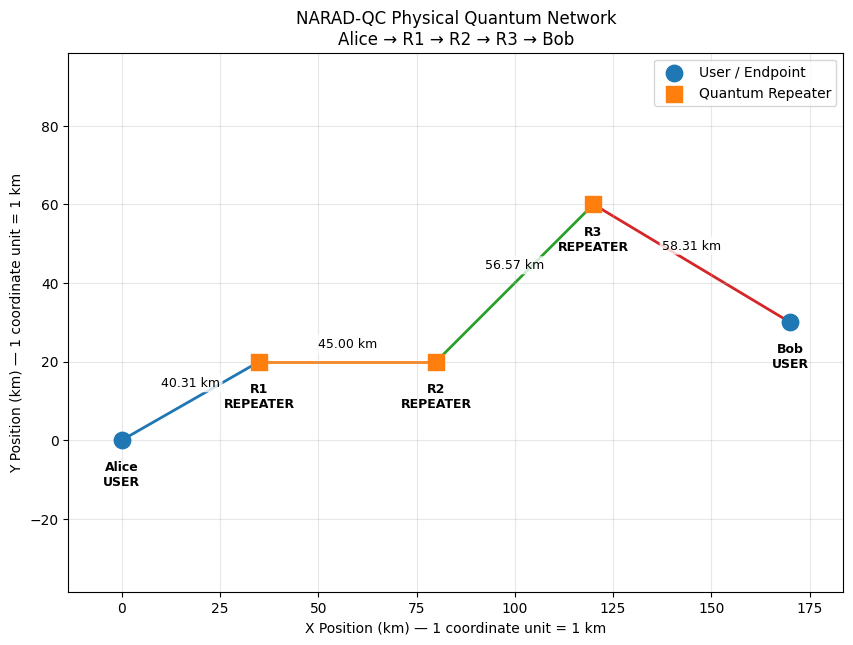

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'NARAD-QC Physical Quantum Network\nAlice → R1 → R2 → R3 → Bob'}, xlabel='X Position (km) — 1 coordinate unit = 1 km', ylabel='Y Position (km) — 1 coordinate unit = 1 km'>)

In [306]:
# @title Custom NARAD-QC Network Verification Form { display-mode: "form" }

# =============================================================
# USER 1
# =============================================================

user_1_name = "Alice" # @param {type:"string"}

user_1_x_km = 0 # @param {type:"number"}

user_1_y_km = 0 # @param {type:"number"}


# =============================================================
# REPEATERS
#
# Enter repeater names in physical chain order:
#
#     R1,R2,R3
#
# The FIRST repeater is connected to User 1.
# The LAST repeater is connected to User 2.
#
# Coordinates use the same order:
#
#     35,20;80,20;120,60
#
# means:
#
#     R1 = (35, 20) km
#     R2 = (80, 20) km
#     R3 = (120, 60) km
# =============================================================

repeater_nodes = "R1,R2,R3" # @param {type:"string"}

repeater_coordinates_km = "35,20;80,20;120,60" # @param {type:"string"}


# =============================================================
# USER 2
# =============================================================

user_2_name = "Bob" # @param {type:"string"}

user_2_x_km = 170 # @param {type:"number"}

user_2_y_km = 30 # @param {type:"number"}


# =============================================================
# Parse Form Input
# =============================================================

def _parse_repeater_names(
    repeater_text: str
) -> list[str]:

    names = [
        item.strip()
        for item in repeater_text.split(",")
        if item.strip()
    ]

    if not names:
        raise ValueError(
            "Please provide at least one repeater node."
        )

    return names


def _parse_coordinate_pairs(
    coordinate_text: str
) -> list[tuple[float, float]]:

    raw_pairs = [
        item.strip()
        for item in coordinate_text.split(";")
        if item.strip()
    ]

    coordinates = []

    for index, pair_text in enumerate(
        raw_pairs,
        start=1
    ):

        components = [
            value.strip()
            for value in pair_text.split(",")
        ]

        if len(components) != 2:
            raise ValueError(
                f"Repeater coordinate #{index} must have "
                f"exactly two values: x,y"
            )

        try:

            x_value = float(
                components[0]
            )

            y_value = float(
                components[1]
            )

        except ValueError as exc:

            raise ValueError(
                f"Repeater coordinate #{index} contains "
                f"a non-numeric value."
            ) from exc

        if (
            not math.isfinite(x_value)
            or not math.isfinite(y_value)
        ):
            raise ValueError(
                f"Repeater coordinate #{index} must contain "
                f"finite coordinates."
            )

        coordinates.append(
            (
                x_value,
                y_value
            )
        )

    return coordinates


parsed_repeater_names = (
    _parse_repeater_names(
        repeater_nodes
    )
)

parsed_repeater_coordinates = (
    _parse_coordinate_pairs(
        repeater_coordinates_km
    )
)


if (
    len(parsed_repeater_names)
    != len(parsed_repeater_coordinates)
):

    raise ValueError(
        "Repeater input mismatch: "
        f"{len(parsed_repeater_names)} repeater name(s) "
        f"were supplied but "
        f"{len(parsed_repeater_coordinates)} coordinate "
        f"pair(s) were supplied."
    )


# =============================================================
# Build User-Specified Physical Chain
# =============================================================

verification_topology, verification_path = (
    build_linear_chain_topology(

        user_1_name=(
            user_1_name.strip()
        ),

        user_1_position_km=(
            float(user_1_x_km),
            float(user_1_y_km)
        ),

        repeater_names=(
            parsed_repeater_names
        ),

        repeater_positions_km=(
            parsed_repeater_coordinates
        ),

        user_2_name=(
            user_2_name.strip()
        ),

        user_2_position_km=(
            float(user_2_x_km),
            float(user_2_y_km)
        ),

        topology_name=(
            "NARAD-QC-Phase3A10-Verification"
        )
    )
)


print("=" * 76)
print("CUSTOM NARAD-QC PHYSICAL CHAIN")
print("=" * 76)

print(
    "\nChain order:"
)

print(
    " -> ".join(
        node.name
        for node in verification_path
    )
)

print(
    "\nTotal physical path distance: "
    f"{verification_topology.path_distance_km(verification_path):.2f} km"
)

print(
    "\nEach coordinate unit in the graph represents exactly 1 km."
)


# =============================================================
# Display Physical Network
# =============================================================

plot_quantum_chain(
    verification_topology,
    verification_path
)

NARAD-QC - Quantum Network Simulator Verification
[PASS] QuantumNetworkSimulator assembled successfully.
[PASS] Every physical node has exactly one runtime, authentication client, and quantum memory.
[PASS] Every physical device is trusted-enrolled with the central control plane.
[PASS] Newly provisioned devices cannot use quantum resources before mutual authentication.
[PASS] Complete quantum chain is blocked while its devices are unauthenticated.
[PASS] Every device completed fresh mutual ML-DSA authentication.
[PASS] Fully authenticated chain is authorized for future quantum operations.
[PASS] Static physical identity and runtime device identity are correctly bound.
[PASS] Every physical device recognizes the network controller as its trust anchor.
[PASS] Every local quantum memory is registered with the authoritative EntanglementManager.
[PASS] Simulator assembly itself creates no entanglement resources.
[PASS] Invalidating one repeater immediately blocks the entire chain from auth

,Node,Role,X (km),Y (km),Endpoint Capable,Swapping Capable,Memory Capacity,Degree
0,Alice,ENDPOINT,0.0,0.0,True,False,2,1
1,R1,REPEATER,35.0,20.0,False,True,2,2
2,R2,REPEATER,80.0,20.0,False,True,2,2
3,R3,REPEATER,120.0,60.0,False,True,2,2
4,Bob,ENDPOINT,170.0,30.0,True,False,2,1



PHYSICAL LINKS


,Link ID,Node A,Node B,Distance (km),Attenuation (dB/km),Total Attenuation (dB),Survival Probability,Loss Probability
0,Alice--R1,Alice,R1,40.311289,0.2,8.062258,0.156234,0.843766
1,R1--R2,R1,R2,45.000000,0.2,9.000000,0.125893,0.874107
2,R2--R3,R2,R3,56.568542,0.2,11.313708,0.073897,0.926103
3,Bob--R3,R3,Bob,58.309519,0.2,11.661904,0.068204,0.931796



RUNTIME DEVICE STATE


...


AUTHENTICATION HISTORY


,Attempt,Session ID,Node,Status,Node Proof Verified,Controller Proof Verified,Node Key ID,Controller Key ID,Reason
0,0,f77801640f87f8bf4f527a25580ff97c,Alice,AUTHENTICATED,True,True,ML-DSA-65:499992be4481001fae4e7fea,ML-DSA-65:5d35dc4bce61a6cd82e89ebf,mutual_authentication_success
1,1,cdde73fc7225523b7482e55f1d0cc513,R1,AUTHENTICATED,True,True,ML-DSA-65:15040657431905cade6d2919,ML-DSA-65:5d35dc4bce61a6cd82e89ebf,mutual_authentication_success
2,2,713f84f3542089bf77173565fc97e3ee,R2,AUTHENTICATED,True,True,ML-DSA-65:923509b55b2dc8ff0f3058c7,ML-DSA-65:5d35dc4bce61a6cd82e89ebf,mutual_authentication_success
3,3,0b23a277024fd415083419665f03f15c,R3,AUTHENTICATED,True,True,ML-DSA-65:e3a488a9800b615ced997d6b,ML-DSA-65:5d35dc4bce61a6cd82e89ebf,mutual_authentication_success
4,4,8b8df70987c12851c6c61863f5751aaf,Bob,AUTHENTICATED,True,True,ML-DSA-65:b6356c7f2189546e3a0fde9e,ML-DSA-65:5d35dc4bce61a6cd82e89ebf,mutual_authentication_success
5,5,cdde73fc7225523b7482e55f1d0cc513,R1,INVALIDATED,False,False,ML-DSA-65:15040657431905cade6d2919,ML-DSA-65:5d35dc4bce61a6cd82e89ebf,phase3a10_authorization_gate_test
6,6,74cd2a085c6767c96cd4ce3fb568ff97,R1,AUTHENTICATED,True,True,ML-DSA-65:15040657431905cade6d2919,ML-DSA-65:5d35dc4bce61a6cd82e89ebf,mutual_authentication_success



SIMULATION EVENT LOG


,Event Index,Event Type,Simulation Slot,Component,Session ID,Node Names,Link IDs,Resource IDs,Message,Metadata,Wall Elapsed (s)
0,0,SIMULATION_INITIALIZED,0,SimulationKernel,None,[],[],[],Simulation initialized with seed 310010.,{'seed': 310010},0.000016
1,1,ENTANGLEMENT_MANAGER_INITIALIZED,0,EntanglementManager,None,[],[],[],Global entanglement manager initialized.,{},0.000060
2,2,MEMORY_INITIALIZED,0,QuantumMemory,None,[Alice],[],[],Quantum memory initialized at Alice with 2 slo...,"{'capacity': 2, 'max_storage_slots': None}",0.003024
3,3,ENTANGLEMENT_MEMORY_REGISTERED,0,EntanglementManager,None,[Alice],[],[],Quantum memory at 'Alice' registered with the ...,{},0.003045
4,4,MEMORY_INITIALIZED,0,QuantumMemory,None,[R1],[],[],Quantum memory initialized at R1 with 2 slot(s).,"{'capacity': 2, 'max_storage_slots': None}",0.003817
5,5,ENTANGLEMENT_MEMORY_REGISTERED,0,EntanglementManager,None,[R1],[],[],Quantum memory at 'R1' registered with the glo...,{},0.003834
6,6,MEMORY_INITIALIZED,0,QuantumMemory,None,[R2],[],[],Quantum memory initialized at R2 with 2 slot(s).,"{'capacity': 2, 'max_storage_slots': None}",0.005654
7,7,ENTANGLEMENT_MEMORY_REGISTERED,0,EntanglementManager,None,[R2],[],[],Quantum memory at 'R2' registered with the glo...,{},0.005670
8,8,MEMORY_INITIALIZED,0,QuantumMemory,None,[R3],[],[],Quantum memory initialized at R3 with 2 slot(s).,"{'capacity': 2, 'max_storage_slots': None}",0.006395
9,9,ENTANGLEMENT_MEMORY_REGISTERED,0,EntanglementManager,None,[R3],[],[],Quantum memory at 'R3' registered with the glo...,{},0.006407



FINAL AUTHENTICATED PHYSICAL NETWORK


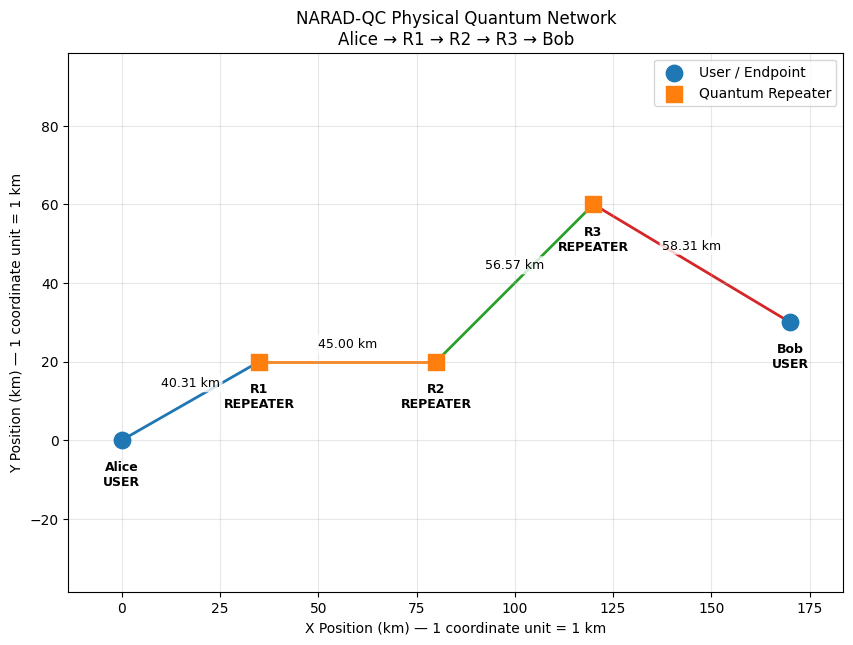


Verification completed successfully.


In [307]:
# @title Full Quantum Network Simulator Verification


print("=" * 76)
print("NARAD-QC - Quantum Network Simulator Verification")
print("=" * 76)


# =============================================================
# Assemble the complete runtime world
#
# max_storage_slots=None intentionally:
# Phase 3A assembly verification does not impose an arbitrary
# quantum-memory lifetime experiment yet.
# =============================================================

verification_simulator = (
    QuantumNetworkSimulator(

        topology=(
            verification_topology
        ),

        simulation_seed=(
            310010
        ),

        controller_id=(
            "NARAD-QC-CONTROLLER"
        ),

        parameter_set=(
            MLDSAParameterSet.ML_DSA_65
        ),

        max_storage_slots=None
    )
)


# =============================================================
# Test 1 — Simulator assembled successfully
# =============================================================

assert isinstance(
    verification_simulator,
    QuantumNetworkSimulator
)

assert (
    verification_simulator.topology
    is verification_topology
)

print(
    "[PASS] QuantumNetworkSimulator assembled successfully."
)


# =============================================================
# Test 2 — Runtime matches physical topology
# =============================================================

assert (
    verification_simulator
    .validate_runtime_consistency()
    is True
)

assert (
    len(
        verification_simulator.device_runtimes
    )
    == verification_topology.node_count
)

assert (
    len(
        verification_simulator.quantum_memories
    )
    == verification_topology.node_count
)

assert (
    len(
        verification_simulator.authentication_clients
    )
    == verification_topology.node_count
)

print(
    "[PASS] Every physical node has exactly one runtime, "
    "authentication client, and quantum memory."
)


# =============================================================
# Test 3 — Controller enrolled every physical device
# =============================================================

assert (
    verification_simulator
    .control_plane.peer_count
    == verification_topology.node_count
)

for node in verification_topology.nodes:

    assert (
        verification_simulator
        .control_plane.is_enrolled(
            node
        )
    )

print(
    "[PASS] Every physical device is trusted-enrolled "
    "with the central control plane."
)


# =============================================================
# Test 4 — Enrollment alone grants NO quantum eligibility
# =============================================================

for node in verification_topology.nodes:

    assert not (
        verification_simulator
        .is_quantum_eligible(
            node
        )
    )

assert (
    len(
        verification_simulator
        .eligible_node_names
    )
    == 0
)

print(
    "[PASS] Newly provisioned devices cannot use quantum "
    "resources before mutual authentication."
)


# =============================================================
# Test 5 — Authorization gate blocks unauthenticated chain
# =============================================================

authorization_blocked = False

try:

    verification_simulator.require_quantum_eligibility(
        *verification_path
    )

except QuantumOperationAuthorizationError:
    authorization_blocked = True

assert authorization_blocked

print(
    "[PASS] Complete quantum chain is blocked while "
    "its devices are unauthenticated."
)


# =============================================================
# Test 6 — Mutually authenticate every physical device
# =============================================================

authentication_results = (
    verification_simulator
    .authenticate_all_nodes()
)

assert (
    len(authentication_results)
    == verification_topology.node_count
)

assert all(
    record.status
    == AuthenticationStatus.AUTHENTICATED
    for record
    in authentication_results.values()
)

print(
    "[PASS] Every device completed fresh mutual "
    "ML-DSA authentication."
)


# =============================================================
# Test 7 — Entire chain becomes quantum eligible
# =============================================================

assert (
    verification_simulator
    .require_quantum_eligibility(
        *verification_path
    )
    is True
)

assert set(
    verification_simulator
    .eligible_node_names
) == {
    node.name
    for node in verification_topology.nodes
}

print(
    "[PASS] Fully authenticated chain is authorized "
    "for future quantum operations."
)


# =============================================================
# Test 8 — Every runtime uses the correct physical node
# =============================================================

for node in verification_topology.nodes:

    runtime = (
        verification_simulator
        .device_runtime(
            node
        )
    )

    memory = (
        verification_simulator
        .quantum_memory(
            node
        )
    )

    assert runtime.physical_node is node
    assert memory.owner is node

print(
    "[PASS] Static physical identity and runtime device "
    "identity are correctly bound."
)


# =============================================================
# Test 9 — Every node trusts exactly the assembled controller
# =============================================================

for node in verification_topology.nodes:

    runtime = (
        verification_simulator
        .device_runtime(
            node
        )
    )

    assert runtime.trusts_controller(
        verification_simulator
        .control_plane.controller_id
    )

print(
    "[PASS] Every physical device recognizes the network "
    "controller as its trust anchor."
)


# =============================================================
# Test 10 — Quantum memories are registered globally
# =============================================================

for node in verification_topology.nodes:

    simulator_memory = (
        verification_simulator
        .quantum_memory(
            node
        )
    )

    manager_memory = (
        verification_simulator
        .entanglement_manager
        .memory_for_node(
            node
        )
    )

    assert (
        simulator_memory
        is manager_memory
    )

print(
    "[PASS] Every local quantum memory is registered with "
    "the authoritative EntanglementManager."
)


# =============================================================
# Test 11 — No quantum resources exist merely from assembly
# =============================================================

assert (
    len(
        verification_simulator
        .entanglement_manager.resources
    )
    == 0
)

assert (
    len(
        verification_simulator
        .entanglement_manager.active_resources
    )
    == 0
)

print(
    "[PASS] Simulator assembly itself creates no "
    "entanglement resources."
)


# =============================================================
# Test 12 — Authentication invalidation immediately closes
#           the quantum authorization gate
# =============================================================

test_gate_node = (
    verification_path[1]
)

invalidated_record = (
    verification_simulator
    .authentication_service
    .invalidate_authentication(
        test_gate_node,
        reason=(
            "phase3a10_authorization_gate_test"
        )
    )
)

assert (
    invalidated_record.status
    == AuthenticationStatus.INVALIDATED
)

assert not (
    verification_simulator
    .is_quantum_eligible(
        test_gate_node
    )
)


gate_closed_after_invalidation = False

try:

    verification_simulator.require_quantum_eligibility(
        *verification_path
    )

except QuantumOperationAuthorizationError:
    gate_closed_after_invalidation = True

assert gate_closed_after_invalidation

print(
    "[PASS] Invalidating one repeater immediately blocks "
    "the entire chain from authorized quantum use."
)


# =============================================================
# Test 13 — Fresh reauthentication restores the chain
# =============================================================

restored_record = (
    verification_simulator
    .authenticate_node(
        test_gate_node
    )
)

assert (
    restored_record.status
    == AuthenticationStatus.AUTHENTICATED
)

assert (
    verification_simulator
    .require_quantum_eligibility(
        *verification_path
    )
    is True
)

print(
    "[PASS] Fresh mutual authentication restores "
    "the chain's quantum eligibility."
)


# =============================================================
# Test 14 — Final complete cross-component consistency
# =============================================================

assert (
    verification_simulator
    .validate_runtime_consistency()
    is True
)

print(
    "[PASS] Complete assembled NARAD-QC runtime is "
    "cross-layer consistent."
)


# =============================================================
# Runtime Inspection
# =============================================================

print("\nSIMULATOR")
print(
    verification_simulator
)


print("\nSIMULATOR SUMMARY")

print(
    verification_simulator.summary()
)


print("\nPHYSICAL TOPOLOGY")

display(
    verification_topology.nodes_dataframe()
)


print("\nPHYSICAL LINKS")

display(
    verification_topology.links_dataframe()
)


print("\nRUNTIME DEVICE STATE")

display(
    verification_simulator
    .nodes_runtime_dataframe()
)


print("\nTRUSTED PEER REGISTRY")

display(
    verification_simulator
    .control_plane
    .trusted_peer_registry_dataframe()
)


print("\nAUTHENTICATION HISTORY")

display(
    verification_simulator
    .authentication_service
    .authentication_dataframe()
)


print("\nSIMULATION EVENT LOG")

display(
    verification_simulator
    .kernel
    .events_dataframe()
)


# =============================================================
# Final Dynamic Network Graph
# =============================================================

print("\nFINAL AUTHENTICATED PHYSICAL NETWORK")

plot_quantum_chain(
    verification_topology,
    verification_path
)


print("\n" + "=" * 76)
print("Verification completed successfully.")
print("=" * 76)

### Phase 3B : 10-09-2026T11:20:52 -- 10-09-2026T13:14:16

In [308]:
# @title Elementary Entanglement Physical Model

from abc import ABC, abstractmethod
from dataclasses import dataclass
from typing import Optional
import math
import numbers


# =============================================================
# Elementary Entanglement Errors
# =============================================================

class ElementaryEntanglementError(Exception):
    """
    Base exception for Phase-3B elementary entanglement.
    """
    pass


class ElementaryEntanglementModelError(
    ElementaryEntanglementError
):
    pass


class ElementaryEntanglementStorageError(
    ElementaryEntanglementError
):
    pass


# =============================================================
# Physical Model Interface
# =============================================================

class ElementaryEntanglementModel(ABC):
    """
    Abstract physical model for one elementary-entanglement
    generation attempt over one PhysicalQuantumLink.

    A model is intentionally STATELESS with respect to runtime
    attempts.

    Its responsibility is only to describe physical success
    probability.

    It does NOT:
    - draw random numbers;
    - advance simulation time;
    - create EntanglementResource objects;
    - mutate quantum memory;
    - authenticate nodes;
    - own attempt counters.
    """

    @property
    @abstractmethod
    def model_name(self) -> str:
        pass

    @abstractmethod
    def success_probability(
        self,
        link: PhysicalQuantumLink
    ) -> float:
        """
        Return probability that one physical elementary-
        entanglement attempt succeeds.
        """
        pass

    def validate_probability(
        self,
        probability: float
    ) -> float:

        if (
            isinstance(probability, bool)
            or not isinstance(
                probability,
                numbers.Real
            )
            or not math.isfinite(
                float(probability)
            )
        ):
            raise ElementaryEntanglementModelError(
                "Physical success probability must be "
                "a finite real number."
            )

        probability = float(
            probability
        )

        if not 0.0 <= probability <= 1.0:
            raise ElementaryEntanglementModelError(
                "Physical success probability must lie "
                "within [0, 1]."
            )

        return probability


# =============================================================
# Phase 1–2 Compatible Fibre-Survival Proxy
# =============================================================

class FiberSurvivalProxyModel(
    ElementaryEntanglementModel
):
    """
    Initial Phase-3B physical abstraction.

    One elementary-entanglement attempt succeeds with probability

        P_success = eta(d)

    where eta(d) is the complete-link fibre-survival probability
    already used by the validated Phase 1–2 attenuation model.
    """

    @property
    def model_name(self) -> str:
        return "FiberSurvivalProxyModel"

    def success_probability(
        self,
        link: PhysicalQuantumLink
    ) -> float:

        if not isinstance(
            link,
            PhysicalQuantumLink
        ):
            raise TypeError(
                "link must be a PhysicalQuantumLink."
            )

        return self.validate_probability(
            link.survival_probability
        )

    def __repr__(
        self
    ) -> str:

        return (
            "FiberSurvivalProxyModel("
            "P_success=full_link_survival_probability"
            ")"
        )

In [309]:
# @title Elementary Entanglement Attempt Record


@dataclass(frozen=True)
class ElementaryEntanglementAttempt:
    """
    Immutable record of one physical elementary-entanglement
    generation attempt.

    The random draw is retained for reproducibility/debugging
    of seeded physical simulations.

    No cryptographic randomness is represented here.
    """

    attempt_index: int

    simulation_slot: int

    link_id: str

    node_a_name: str
    node_b_name: str

    model_name: str

    success_probability: float

    random_draw: float

    success: bool

    resource_id: Optional[str] = None

    def __post_init__(self):

        if (
            isinstance(self.attempt_index, bool)
            or not isinstance(
                self.attempt_index,
                int
            )
            or self.attempt_index < 0
        ):
            raise ValueError(
                "attempt_index must be a non-negative integer."
            )

        if (
            isinstance(self.simulation_slot, bool)
            or not isinstance(
                self.simulation_slot,
                int
            )
            or self.simulation_slot < 0
        ):
            raise ValueError(
                "simulation_slot must be a non-negative integer."
            )

        if not 0.0 <= (
            self.success_probability
        ) <= 1.0:
            raise ValueError(
                "success_probability must lie within [0, 1]."
            )

        if not 0.0 <= (
            self.random_draw
        ) < 1.0:
            raise ValueError(
                "random_draw must lie within [0, 1)."
            )

        if self.success:

            if (
                not isinstance(self.resource_id, str)
                or not self.resource_id.strip()
            ):
                raise ValueError(
                    "Successful attempt requires resource_id."
                )

        else:

            if self.resource_id is not None:
                raise ValueError(
                    "Failed attempt cannot have resource_id."
                )

In [310]:
# @title Elementary Entanglement Runtime Statistics


class ElementaryEntanglementStatistics:
    """
    Runtime statistics for elementary-entanglement attempts.
    """

    def __init__(self):

        self._attempts: list[
            ElementaryEntanglementAttempt
        ] = []

    def record(
        self,
        attempt: ElementaryEntanglementAttempt
    ) -> None:

        if not isinstance(
            attempt,
            ElementaryEntanglementAttempt
        ):
            raise TypeError(
                "attempt must be an "
                "ElementaryEntanglementAttempt."
            )

        self._attempts.append(
            attempt
        )

    @property
    def attempts(
        self
    ) -> tuple[
        ElementaryEntanglementAttempt, ...
    ]:

        return tuple(
            self._attempts
        )

    @property
    def total_attempts(
        self
    ) -> int:

        return len(
            self._attempts
        )

    @property
    def total_successes(
        self
    ) -> int:

        return sum(
            attempt.success
            for attempt
            in self._attempts
        )

    @property
    def total_failures(
        self
    ) -> int:

        return (
            self.total_attempts
            - self.total_successes
        )

    @property
    def empirical_success_rate(
        self
    ) -> float:

        if self.total_attempts == 0:
            return 0.0

        return (
            self.total_successes
            / self.total_attempts
        )

    def attempts_for_link(
        self,
        link_or_id
    ) -> tuple[
        ElementaryEntanglementAttempt, ...
    ]:

        link_id = (
            link_or_id.link_id
            if isinstance(
                link_or_id,
                PhysicalQuantumLink
            )
            else str(link_or_id)
        )

        return tuple(
            attempt
            for attempt
            in self._attempts
            if attempt.link_id
            == link_id
        )

    def link_summary_dataframe(
        self
    ) -> pd.DataFrame:

        link_ids = sorted({
            attempt.link_id
            for attempt
            in self._attempts
        })

        rows = []

        for link_id in link_ids:

            attempts = (
                self.attempts_for_link(
                    link_id
                )
            )

            successes = sum(
                attempt.success
                for attempt
                in attempts
            )

            total = len(
                attempts
            )

            rows.append({
                "Link ID":
                    link_id,

                "Attempts":
                    total,

                "Successes":
                    successes,

                "Failures":
                    total - successes,

                "Empirical Success Rate":
                    (
                        successes / total
                        if total
                        else 0.0
                    )
            })

        return pd.DataFrame(
            rows
        )

    def attempts_dataframe(
        self
    ) -> pd.DataFrame:

        rows = []

        for attempt in self._attempts:

            rows.append({
                "Attempt":
                    attempt.attempt_index,

                "Simulation Slot":
                    attempt.simulation_slot,

                "Link ID":
                    attempt.link_id,

                "Node A":
                    attempt.node_a_name,

                "Node B":
                    attempt.node_b_name,

                "Model":
                    attempt.model_name,

                "P(success)":
                    attempt.success_probability,

                "Random Draw":
                    attempt.random_draw,

                "Success":
                    attempt.success,

                "Resource ID":
                    attempt.resource_id
            })

        return pd.DataFrame(
            rows
        )

    def __repr__(
        self
    ) -> str:

        return (
            "ElementaryEntanglementStatistics("
            f"attempts={self.total_attempts}, "
            f"successes={self.total_successes}, "
            f"failures={self.total_failures}"
            ")"
        )

In [311]:
# @title Elementary Entanglement Single-Attempt Service


class ElementaryEntanglementService:
    """
    Executes authorized elementary-entanglement generation
    attempts inside one QuantumNetworkSimulator.

    Responsibilities
    ----------------
    - validate the physical link belongs to the simulator;
    - enforce mutual-authentication authorization;
    - ensure endpoint memory can accept a new resource;
    - obtain physical success probability from a model;
    - draw one stochastic result from SimulationKernel.rng;
    - create a global EntanglementResource only after success;
    - record attempt statistics and simulation events.

    The service deliberately does NOT:
    - advance simulation time;
    - retry automatically;
    - schedule multiple links;
    - perform entanglement swapping;
    - determine routes.

    Those responsibilities belong to later Phase-3 components.
    """

    def __init__(
        self,
        simulator: QuantumNetworkSimulator,
        model: ElementaryEntanglementModel
    ):

        if not isinstance(
            simulator,
            QuantumNetworkSimulator
        ):
            raise TypeError(
                "simulator must be a QuantumNetworkSimulator."
            )

        if not isinstance(
            model,
            ElementaryEntanglementModel
        ):
            raise TypeError(
                "model must be an "
                "ElementaryEntanglementModel."
            )

        self.simulator = simulator
        self.model = model

        self.statistics = (
            ElementaryEntanglementStatistics()
        )

    # =========================================================
    # Link Validation
    # =========================================================

    def _validate_link(
        self,
        link: PhysicalQuantumLink
    ) -> PhysicalQuantumLink:

        if not isinstance(
            link,
            PhysicalQuantumLink
        ):
            raise TypeError(
                "link must be a PhysicalQuantumLink."
            )

        # Exact canonical topology object required.
        canonical_link = (
            self.simulator.topology
            .get_link_by_id(
                link.link_id
            )
        )

        if canonical_link is not link:
            raise TopologyConsistencyError(
                f"Link '{link.link_id}' is not the "
                f"canonical link object owned by this "
                f"simulation topology."
            )

        return canonical_link

    # =========================================================
    # Storage Preflight
    # =========================================================

    def _require_storage_capacity(
        self,
        link: PhysicalQuantumLink
    ) -> None:

        memory_a = (
            self.simulator.quantum_memory(
                link.node_a
            )
        )

        memory_b = (
            self.simulator.quantum_memory(
                link.node_b
            )
        )

        full_nodes = []

        if memory_a.is_full:
            full_nodes.append(
                link.node_a.name
            )

        if memory_b.is_full:
            full_nodes.append(
                link.node_b.name
            )

        if full_nodes:
            raise ElementaryEntanglementStorageError(
                "Elementary entanglement attempt denied "
                "because no storage slot is available at: "
                + ", ".join(full_nodes)
            )

    # =========================================================
    # One Physical Attempt
    # =========================================================

    def attempt_once(
        self,
        link: PhysicalQuantumLink
    ) -> ElementaryEntanglementAttempt:
        """
        Execute exactly ONE physical elementary-entanglement
        generation attempt.

        IMPORTANT
        ---------
        This method does NOT advance SimulationKernel.current_slot.

        Multiple links may later call attempt_once() during the
        same global simulation slot to represent parallel
        generation attempts.
        """

        self.simulator.validate_runtime_consistency()

        link = self._validate_link(
            link
        )

        # =====================================================
        # Authorization gate
        # =====================================================

        self.simulator.require_quantum_eligibility(
            link.node_a,
            link.node_b
        )

        # =====================================================
        # Memory preflight
        #
        # If a result could not be stored, the control plane
        # should not authorize the physical attempt.
        # Therefore this is NOT counted as a physical attempt.
        # =====================================================

        self._require_storage_capacity(
            link
        )

        # =====================================================
        # Physical model
        # =====================================================

        probability = (
            self.model.success_probability(
                link
            )
        )

        # =====================================================
        # Physical stochastic outcome
        #
        # This is exactly where the reproducible simulation RNG
        # belongs.
        # =====================================================

        random_draw = float(
            self.simulator.kernel.rng.random()
        )

        success = (
            random_draw
            < probability
        )

        # =====================================================
        # Successful physical generation creates global
        # entanglement + both local halves atomically.
        # =====================================================

        resource = None

        if success:

            resource = (
                self.simulator
                .entanglement_manager
                .create_elementary_resource(
                    link
                )
            )

        # =====================================================
        # Immutable physical-attempt record
        # =====================================================

        attempt = ElementaryEntanglementAttempt(

            attempt_index=(
                self.statistics.total_attempts
            ),

            simulation_slot=(
                self.simulator.kernel.current_slot
            ),

            link_id=(
                link.link_id
            ),

            node_a_name=(
                link.node_a.name
            ),

            node_b_name=(
                link.node_b.name
            ),

            model_name=(
                self.model.model_name
            ),

            success_probability=(
                probability
            ),

            random_draw=(
                random_draw
            ),

            success=(
                success
            ),

            resource_id=(
                resource.resource_id
                if resource is not None
                else None
            )
        )

        self.statistics.record(
            attempt
        )

        # =====================================================
        # Simulation event
        # =====================================================

        event_type = (
            "ELEMENTARY_ENTANGLEMENT_SUCCEEDED"
            if success
            else "ELEMENTARY_ENTANGLEMENT_FAILED"
        )

        self.simulator.kernel.emit(

            event_type=event_type,

            component=(
                "ElementaryEntanglementService"
            ),

            node_names=(
                link.node_a.name,
                link.node_b.name
            ),

            link_ids=(
                link.link_id,
            ),

            resource_ids=(
                (resource.resource_id,)
                if resource is not None
                else ()
            ),

            message=(
                f"Elementary entanglement attempt "
                f"{attempt.attempt_index} on "
                f"'{link.link_id}' "
                f"{'succeeded' if success else 'failed'}."
            ),

            metadata={
                "model":
                    self.model.model_name,

                "success_probability":
                    probability,

                "random_draw":
                    random_draw,

                "attempt_index":
                    attempt.attempt_index
            }
        )

        return attempt

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(
        self
    ) -> str:

        return (
            "ElementaryEntanglementService("
            f"model='{self.model.model_name}', "
            f"attempts="
            f"{self.statistics.total_attempts}"
            ")"
        )

In [313]:
# @title Elementary Entanglement Verification


print("=" * 76)
print("NARAD-QC - Elementary Entanglement Verification")
print("=" * 76)


# =============================================================
# Physical test topology
#
# Q-A -------- 50 km -------- Q-B
#
# 0.2 dB/km:
#
# total attenuation = 10 dB
#
# P(success) = 10^(-10/10) = 0.1
# =============================================================

elementary_test_topology = NetworkTopology(
    name="Phase3B-Test-Network"
)


elementary_node_a = NetworkNode(
    name="Elementary-A",
    x_km=0,
    y_km=0,
    endpoint_capable=True,
    swapping_capable=False,
    memory_capacity=2
)


elementary_node_b = NetworkNode(
    name="Elementary-B",
    x_km=50,
    y_km=0,
    endpoint_capable=True,
    swapping_capable=False,
    memory_capacity=2
)


elementary_test_topology.add_node(
    elementary_node_a
)

elementary_test_topology.add_node(
    elementary_node_b
)


elementary_test_link = PhysicalQuantumLink(

    node_a=elementary_node_a,

    node_b=elementary_node_b,

    attenuation_db_per_km=0.2
)


elementary_test_topology.add_link(
    elementary_test_link
)


# =============================================================
# Assemble simulator
# =============================================================

elementary_test_simulator = (
    QuantumNetworkSimulator(

        topology=(
            elementary_test_topology
        ),

        simulation_seed=(
            314159
        ),

        controller_id=(
            "PHASE3B1-CONTROLLER"
        ),

        parameter_set=(
            MLDSAParameterSet.ML_DSA_65
        ),

        max_storage_slots=None
    )
)


# =============================================================
# Physical model
# =============================================================

elementary_test_model = (
    FiberSurvivalProxyModel()
)


elementary_service = (
    ElementaryEntanglementService(

        simulator=(
            elementary_test_simulator
        ),

        model=(
            elementary_test_model
        )
    )
)


# =============================================================
# Test 1 — Physical model preserves attenuation baseline
# =============================================================

expected_probability = 0.1

actual_probability = (
    elementary_test_model
    .success_probability(
        elementary_test_link
    )
)

assert math.isclose(
    actual_probability,
    expected_probability,
    rel_tol=1e-12
)

print(
    "[PASS] FiberSurvivalProxyModel preserves the "
    "validated Phase 1–2 attenuation probability."
)


# =============================================================
# Test 2 — Enrollment alone cannot generate entanglement
# =============================================================

assert (
    elementary_test_simulator
    .control_plane.is_enrolled(
        elementary_node_a
    )
)

assert not (
    elementary_test_simulator
    .is_quantum_eligible(
        elementary_node_a
    )
)


attempt_count_before = (
    elementary_service
    .statistics.total_attempts
)


unauthorized_blocked = False

try:

    elementary_service.attempt_once(
        elementary_test_link
    )

except QuantumOperationAuthorizationError:

    unauthorized_blocked = True


assert unauthorized_blocked

assert (
    elementary_service
    .statistics.total_attempts
    == attempt_count_before
)

print(
    "[PASS] Unauthenticated devices cannot trigger "
    "a physical entanglement attempt."
)


# =============================================================
# Test 3 — Mutually authenticate both physical devices
# =============================================================

auth_results = (
    elementary_test_simulator
    .authenticate_all_nodes()
)

assert all(
    record.status
    == AuthenticationStatus.AUTHENTICATED
    for record
    in auth_results.values()
)

assert (
    elementary_test_simulator
    .require_quantum_eligibility(
        elementary_node_a,
        elementary_node_b
    )
)

print(
    "[PASS] Both link endpoints completed mutual "
    "ML-DSA authentication."
)


# =============================================================
# Test 4 — One physical attempt does NOT advance time
# =============================================================

slot_before_attempt = (
    elementary_test_simulator
    .kernel.current_slot
)

first_attempt = (
    elementary_service.attempt_once(
        elementary_test_link
    )
)

slot_after_attempt = (
    elementary_test_simulator
    .kernel.current_slot
)

assert (
    slot_before_attempt
    == slot_after_attempt
)

assert (
    first_attempt.simulation_slot
    == slot_before_attempt
)

assert (
    elementary_service
    .statistics.total_attempts
    == 1
)

print(
    "[PASS] Individual link attempt does not advance "
    "the global simulation clock."
)


# =============================================================
# Test 5 — Stochastic decision matches recorded draw
# =============================================================

assert (
    first_attempt.success
    ==
    (
        first_attempt.random_draw
        <
        first_attempt.success_probability
    )
)

print(
    "[PASS] Attempt success is determined exactly by "
    "the seeded physical RNG and model probability."
)


# =============================================================
# Test 6 — Resource exists iff physical attempt succeeded
# =============================================================

if first_attempt.success:

    first_resource = (
        elementary_test_simulator
        .entanglement_manager
        .get_resource(
            first_attempt.resource_id
        )
    )

    assert (
        first_resource.kind
        == EntanglementKind.ELEMENTARY
    )

    assert (
        first_resource.status
        == EntanglementStatus.ACTIVE
    )

    assert (
        elementary_test_simulator
        .quantum_memory(
            elementary_node_a
        )
        .contains(
            first_attempt.resource_id
        )
    )

    assert (
        elementary_test_simulator
        .quantum_memory(
            elementary_node_b
        )
        .contains(
            first_attempt.resource_id
        )
    )

else:

    assert (
        first_attempt.resource_id
        is None
    )

    assert (
        len(
            elementary_test_simulator
            .entanglement_manager
            .resources
        )
        == 0
    )

print(
    "[PASS] Global entanglement resource is created "
    "if and only if physical generation succeeds."
)


# =============================================================
# Test 7 — Physical link owns no runtime attempt counters
# =============================================================

assert not hasattr(
    elementary_test_link,
    "attempts"
)

assert not hasattr(
    elementary_test_link,
    "bell_pair_attempts"
)

assert not hasattr(
    elementary_test_link,
    "successes"
)

assert not hasattr(
    elementary_test_link,
    "failures"
)

print(
    "[PASS] Runtime attempt statistics remain outside "
    "the immutable physical link."
)


# =============================================================
# Test 8 — Attempt statistics are internally consistent
# =============================================================

assert (
    elementary_service
    .statistics.total_successes
    +
    elementary_service
    .statistics.total_failures
    ==
    elementary_service
    .statistics.total_attempts
)

print(
    "[PASS] Elementary-entanglement statistics are "
    "internally consistent."
)


# =============================================================
# Test 9 — Physical/global runtime remains consistent
# =============================================================

assert (
    elementary_test_simulator
    .validate_runtime_consistency()
    is True
)

print(
    "[PASS] Simulator remains cross-layer consistent "
    "after the physical attempt."
)


# =============================================================
# Inspection
# =============================================================

print("\nPHYSICAL MODEL")
print(
    elementary_test_model
)


print("\nELEMENTARY SERVICE")
print(
    elementary_service
)


print("\nATTEMPT HISTORY")

display(
    elementary_service
    .statistics
    .attempts_dataframe()
)


print("\nLINK STATISTICS")

display(
    elementary_service
    .statistics
    .link_summary_dataframe()
)


print("\nGLOBAL ENTANGLEMENT RESOURCES")

display(
    elementary_test_simulator
    .entanglement_manager
    .resources_dataframe()
)


print("\nNODE A MEMORY")

display(
    elementary_test_simulator
    .quantum_memory(
        elementary_node_a
    )
    .slots_dataframe()
)


print("\nNODE B MEMORY")

display(
    elementary_test_simulator
    .quantum_memory(
        elementary_node_b
    )
    .slots_dataframe()
)


print("\n" + "=" * 76)
print("Verification completed successfully.")
print("=" * 76)

NARAD-QC - Elementary Entanglement Verification
[PASS] FiberSurvivalProxyModel preserves the validated Phase 1–2 attenuation probability.
[PASS] Unauthenticated devices cannot trigger a physical entanglement attempt.
[PASS] Both link endpoints completed mutual ML-DSA authentication.
[PASS] Individual link attempt does not advance the global simulation clock.
[PASS] Attempt success is determined exactly by the seeded physical RNG and model probability.
[PASS] Global entanglement resource is created if and only if physical generation succeeds.
[PASS] Runtime attempt statistics remain outside the immutable physical link.
[PASS] Elementary-entanglement statistics are internally consistent.
[PASS] Simulator remains cross-layer consistent after the physical attempt.

PHYSICAL MODEL
FiberSurvivalProxyModel(P_success=full_link_survival_probability)

ELEMENTARY SERVICE
ElementaryEntanglementService(model='FiberSurvivalProxyModel', attempts=1)

ATTEMPT HISTORY


,Attempt,Simulation Slot,Link ID,Node A,Node B,Model,P(success),Random Draw,Success,Resource ID
0,0,0,Elementary-A--Elementary-B,Elementary-A,Elementary-B,FiberSurvivalProxyModel,0.1,0.911553,False,None



LINK STATISTICS


,Link ID,Attempts,Successes,Failures,Empirical Success Rate
0,Elementary-A--Elementary-B,1,0,1,0.0



GLOBAL ENTANGLEMENT RESOURCES


...


NODE A MEMORY


,Owner,Slot Index,Slot ID,Occupied,Resource ID,Remote Node,Stored At Slot,Age (slots),Locally Expired
0,Elementary-A,0,Elementary-A:M0,False,None,None,None,None,False
1,Elementary-A,1,Elementary-A:M1,False,None,None,None,None,False



NODE B MEMORY


,Owner,Slot Index,Slot ID,Occupied,Resource ID,Remote Node,Stored At Slot,Age (slots),Locally Expired
0,Elementary-B,0,Elementary-B:M0,False,None,None,None,None,False
1,Elementary-B,1,Elementary-B:M1,False,None,None,None,None,False



Verification completed successfully.


In [314]:
# @title Elementary Link Generation Process State

from dataclasses import dataclass
from enum import Enum
from typing import Optional
import numbers


# =============================================================
# Process Errors
# =============================================================

class ElementaryGenerationProcessError(
    ElementaryEntanglementError
):
    """
    Base exception for elementary-link generation processes.
    """
    pass


class ElementaryGenerationLimitError(
    ElementaryGenerationProcessError
):
    """
    Raised when a requested generation run reaches its
    configured simulation-slot limit before becoming ready.
    """
    pass


class ElementaryGenerationStateError(
    ElementaryGenerationProcessError
):
    """
    Raised when a requested lifecycle operation is invalid
    for the current elementary-link process state.
    """
    pass


# =============================================================
# Elementary-Link Lifecycle State
# =============================================================

class ElementaryLinkProcessState(str, Enum):

    INACTIVE = "INACTIVE"

    # A resource is required but does not currently exist.
    SEEKING = "SEEKING"

    # One ACTIVE elementary resource exists and is waiting
    # in endpoint quantum memories.
    READY = "READY"


class ElementaryLinkStepAction(str, Enum):

    INACTIVE = "INACTIVE"

    ATTEMPT_FAILED = "ATTEMPT_FAILED"

    RESOURCE_CREATED = "RESOURCE_CREATED"

    RESOURCE_WAITING = "RESOURCE_WAITING"

    RESOURCE_EXPIRED = "RESOURCE_EXPIRED"

    RESOURCE_EXPIRED_AND_REGENERATED = (
        "RESOURCE_EXPIRED_AND_REGENERATED"
    )

    EXTERNAL_TERMINATION_DETECTED = (
        "EXTERNAL_TERMINATION_DETECTED"
    )


# =============================================================
# Immutable Per-Slot Process Result
# =============================================================

@dataclass(frozen=True)
class ElementaryLinkProcessStep:
    """
    Immutable record describing what one elementary-link
    generation process did during one global simulation slot.

    This is a scheduler-level record.

    If a physical generation attempt occurred, `attempt`
    contains the corresponding lower-layer
    ElementaryEntanglementAttempt.
    """

    simulation_slot: int

    link_id: str

    state_before: ElementaryLinkProcessState
    state_after: ElementaryLinkProcessState

    action: ElementaryLinkStepAction

    attempt: Optional[
        ElementaryEntanglementAttempt
    ] = None

    active_resource_id: Optional[str] = None

    terminated_resource_id: Optional[str] = None

    terminated_resource_status: Optional[
        EntanglementStatus
    ] = None

    def __post_init__(self):

        if (
            isinstance(self.simulation_slot, bool)
            or not isinstance(
                self.simulation_slot,
                numbers.Integral
            )
            or self.simulation_slot < 0
        ):
            raise ValueError(
                "simulation_slot must be a non-negative integer."
            )

In [315]:
# @title  Elementary Link Generation Process

class ElementaryLinkGenerationProcess:
    """
    Stateful elementary-entanglement generation process for
    ONE physical link.

    Lifecycle
    ---------
    SEEKING:
        One physical generation attempt may occur per global slot.

    READY:
        One valid elementary entanglement resource exists.
        No further generation attempts occur while it remains ACTIVE.

    EXPIRATION:
        If the stored resource exceeds its quantum-memory lifetime,
        EntanglementManager expires it globally and this process
        becomes SEEKING again.

    INACTIVE:
        Higher-level scheduling does not currently request an
        elementary resource from this link.

    Future swapping
    ---------------
    A later swapping-tree scheduler will control demand when an
    elementary resource is consumed by a BSM.

    This class deliberately does NOT perform entanglement swapping.

    Important timing rule
    ---------------------
    process_current_slot() NEVER advances SimulationKernel time.

    This allows many independent elementary links to be processed
    during the same global simulation slot.
    """

    def __init__(
        self,
        simulator: QuantumNetworkSimulator,
        service: ElementaryEntanglementService,
        link: PhysicalQuantumLink,
        demand_active: bool = True
    ):

        # =====================================================
        # Simulator / Service Validation
        # =====================================================

        if not isinstance(
            simulator,
            QuantumNetworkSimulator
        ):
            raise TypeError(
                "simulator must be a QuantumNetworkSimulator."
            )

        if not isinstance(
            service,
            ElementaryEntanglementService
        ):
            raise TypeError(
                "service must be an "
                "ElementaryEntanglementService."
            )

        if service.simulator is not simulator:
            raise ValueError(
                "ElementaryEntanglementService must belong "
                "to the same QuantumNetworkSimulator."
            )

        if not isinstance(
            link,
            PhysicalQuantumLink
        ):
            raise TypeError(
                "link must be a PhysicalQuantumLink."
            )

        canonical_link = (
            simulator.topology
            .get_link_by_id(
                link.link_id
            )
        )

        if canonical_link is not link:
            raise TopologyConsistencyError(
                f"Link '{link.link_id}' is not the canonical "
                f"physical link owned by this simulator."
            )

        if not isinstance(
            demand_active,
            bool
        ):
            raise TypeError(
                "demand_active must be bool."
            )

        self.simulator = simulator
        self.service = service
        self.link = link

        self._demand_active = (
            demand_active
        )

        self._active_resource_id: Optional[
            str
        ] = None

        self._step_history: list[
            ElementaryLinkProcessStep
        ] = []

    # =========================================================
    # Demand State
    # =========================================================

    @property
    def demand_active(
        self
    ) -> bool:

        return self._demand_active

    def activate_demand(
        self
    ) -> None:
        """
        Request one usable elementary entanglement resource.

        Future swapping-tree execution will use this mechanism
        to activate/deactivate elementary leaves as needed.
        """

        self._demand_active = True

    def deactivate_demand(
        self
    ) -> None:
        """
        Stop requesting NEW elementary-entanglement generation.

        Existing ACTIVE entanglement is not destroyed merely by
        deactivating demand.

        Resource destruction/consumption belongs to the
        EntanglementManager or future swapping engine.
        """

        self._demand_active = False

    # =========================================================
    # Resource Inspection
    # =========================================================

    @property
    def active_resource_id(
        self
    ) -> Optional[str]:

        if self._active_resource_id is None:
            return None

        resource = (
            self.simulator
            .entanglement_manager
            .get_resource(
                self._active_resource_id
            )
        )

        if resource.is_active:
            return resource.resource_id

        return None

    @property
    def active_resource(
        self
    ) -> Optional[
        EntanglementResource
    ]:

        resource_id = (
            self.active_resource_id
        )

        if resource_id is None:
            return None

        return (
            self.simulator
            .entanglement_manager
            .get_resource(
                resource_id
            )
        )

    # =========================================================
    # Dynamic Process State
    # =========================================================

    @property
    def state(
        self
    ) -> ElementaryLinkProcessState:

        if not self.demand_active:
            return (
                ElementaryLinkProcessState.INACTIVE
            )

        if self.active_resource is not None:
            return (
                ElementaryLinkProcessState.READY
            )

        return (
            ElementaryLinkProcessState.SEEKING
        )

    # =========================================================
    # One Global-Slot Processing Step
    # =========================================================

    def process_current_slot(
        self
    ) -> ElementaryLinkProcessStep:
        """
        Process this elementary link exactly once during the
        CURRENT global simulation slot.

        Order
        -----
        1. Synchronize memory expiration.
        2. Reconcile any previously tracked resource.
        3. If still ACTIVE -> wait, no physical attempt.
        4. If no resource is required -> remain inactive.
        5. If unresolved -> perform exactly one physical attempt.

        This method NEVER advances simulation time.
        """

        self.simulator.validate_runtime_consistency()

        current_slot = (
            self.simulator.kernel.current_slot
        )

        state_before = self.state

        previous_resource_id = (
            self._active_resource_id
        )

        terminated_resource_id = None
        terminated_resource_status = None

        # =====================================================
        # STEP 1 — Synchronize hard memory expiration
        #
        # Existing resources are checked at the START of the
        # global slot.
        #
        # A resource created during this same slot therefore has
        # age 0 and cannot immediately expire.
        # =====================================================

        self.simulator.entanglement_manager\
            .synchronize_expirations()

        # =====================================================
        # STEP 2 — Reconcile tracked resource lifecycle
        # =====================================================

        if previous_resource_id is not None:

            previous_resource = (
                self.simulator
                .entanglement_manager
                .get_resource(
                    previous_resource_id
                )
            )

            if not previous_resource.is_active:

                terminated_resource_id = (
                    previous_resource.resource_id
                )

                terminated_resource_status = (
                    previous_resource.status
                )

                self._active_resource_id = None

                # -------------------------------------------------
                # Future special case:
                #
                # CONSUMED will be created by swapping/other
                # higher-layer operations.
                #
                # We deliberately do NOT immediately regenerate
                # in the SAME slot after observing CONSUMED.
                #
                # The future swapping-tree scheduler must decide
                # whether this leaf should be requested again.
                # -------------------------------------------------

                if (
                    previous_resource.status
                    == EntanglementStatus.CONSUMED
                ):

                    step = ElementaryLinkProcessStep(

                        simulation_slot=current_slot,

                        link_id=self.link.link_id,

                        state_before=state_before,

                        state_after=self.state,

                        action=(
                            ElementaryLinkStepAction
                            .EXTERNAL_TERMINATION_DETECTED
                        ),

                        attempt=None,

                        active_resource_id=None,

                        terminated_resource_id=(
                            terminated_resource_id
                        ),

                        terminated_resource_status=(
                            terminated_resource_status
                        )
                    )

                    self._step_history.append(
                        step
                    )

                    return step

        # =====================================================
        # STEP 3 — A valid resource already exists
        #
        # Waiting protocol:
        #
        # DO NOT generate another elementary pair.
        # =====================================================

        if self.active_resource is not None:

            step = ElementaryLinkProcessStep(

                simulation_slot=current_slot,

                link_id=self.link.link_id,

                state_before=state_before,

                state_after=(
                    ElementaryLinkProcessState.READY
                ),

                action=(
                    ElementaryLinkStepAction
                    .RESOURCE_WAITING
                ),

                attempt=None,

                active_resource_id=(
                    self.active_resource.resource_id
                ),

                terminated_resource_id=None,

                terminated_resource_status=None
            )

            self._step_history.append(
                step
            )

            return step

        # =====================================================
        # STEP 4 — Higher layer currently requests nothing
        # =====================================================

        if not self.demand_active:

            step = ElementaryLinkProcessStep(

                simulation_slot=current_slot,

                link_id=self.link.link_id,

                state_before=state_before,

                state_after=(
                    ElementaryLinkProcessState.INACTIVE
                ),

                action=(
                    ElementaryLinkStepAction.INACTIVE
                )
            )

            self._step_history.append(
                step
            )

            return step

        # =====================================================
        # STEP 5 — SEEKING: exactly one physical attempt
        # =====================================================

        attempt = (
            self.service.attempt_once(
                self.link
            )
        )

        if attempt.success:

            self._active_resource_id = (
                attempt.resource_id
            )

            if (
                terminated_resource_status
                == EntanglementStatus.EXPIRED
            ):

                action = (
                    ElementaryLinkStepAction
                    .RESOURCE_EXPIRED_AND_REGENERATED
                )

            else:

                action = (
                    ElementaryLinkStepAction
                    .RESOURCE_CREATED
                )

        else:

            if (
                terminated_resource_status
                == EntanglementStatus.EXPIRED
            ):

                action = (
                    ElementaryLinkStepAction
                    .RESOURCE_EXPIRED
                )

            else:

                action = (
                    ElementaryLinkStepAction
                    .ATTEMPT_FAILED
                )

        step = ElementaryLinkProcessStep(

            simulation_slot=current_slot,

            link_id=self.link.link_id,

            state_before=state_before,

            state_after=self.state,

            action=action,

            attempt=attempt,

            active_resource_id=(
                self.active_resource_id
            ),

            terminated_resource_id=(
                terminated_resource_id
            ),

            terminated_resource_status=(
                terminated_resource_status
            )
        )

        self._step_history.append(
            step
        )

        return step

    # =========================================================
    # Convenience Driver — Repeated Attempts Until Ready
    # =========================================================

    def run_until_ready(
        self,
        max_slots: int
    ) -> EntanglementResource:
        """
        Repeatedly process one global slot and advance time until
        one ACTIVE elementary resource becomes available.

        This helper is valid for a SINGLE-LINK experiment.

        Phase 3B.3 will replace this sequential driver with a
        multi-link scheduler that processes many links during
        every global slot before advancing the clock once.
        """

        if (
            isinstance(max_slots, bool)
            or not isinstance(
                max_slots,
                numbers.Integral
            )
            or max_slots <= 0
        ):
            raise ValueError(
                "max_slots must be a positive integer."
            )

        if not self.demand_active:
            raise ElementaryGenerationStateError(
                "Cannot run generation while demand is inactive."
            )

        max_slots = int(
            max_slots
        )

        for _ in range(
            max_slots
        ):

            step = self.process_current_slot()

            if (
                step.state_after
                == ElementaryLinkProcessState.READY
            ):

                resource = self.active_resource

                if resource is None:
                    raise RuntimeError(
                        "Process entered READY state without "
                        "an ACTIVE resource."
                    )

                return resource

            # One complete global slot has now elapsed.
            self.simulator.kernel.advance_slot()

        raise ElementaryGenerationLimitError(
            f"Link '{self.link.link_id}' did not produce "
            f"a ready elementary resource within "
            f"{max_slots} simulation slots."
        )

    # =========================================================
    # History / Statistics
    # =========================================================

    @property
    def step_history(
        self
    ) -> tuple[
        ElementaryLinkProcessStep, ...
    ]:

        return tuple(
            self._step_history
        )

    def step_history_dataframe(
        self
    ) -> pd.DataFrame:

        rows = []

        for step_index, step in enumerate(
            self._step_history
        ):

            rows.append({

                "Step":
                    step_index,

                "Simulation Slot":
                    step.simulation_slot,

                "Link ID":
                    step.link_id,

                "State Before":
                    step.state_before.value,

                "Action":
                    step.action.value,

                "State After":
                    step.state_after.value,

                "Physical Attempt":
                    (
                        step.attempt.attempt_index
                        if step.attempt is not None
                        else None
                    ),

                "Attempt Success":
                    (
                        step.attempt.success
                        if step.attempt is not None
                        else None
                    ),

                "Active Resource":
                    step.active_resource_id,

                "Terminated Resource":
                    step.terminated_resource_id,

                "Termination Status":
                    (
                        step.terminated_resource_status.value
                        if (
                            step.terminated_resource_status
                            is not None
                        )
                        else None
                    )
            })

        return pd.DataFrame(
            rows
        )

    def __repr__(
        self
    ) -> str:

        return (
            "ElementaryLinkGenerationProcess("
            f"link='{self.link.link_id}', "
            f"state='{self.state.value}', "
            f"resource={self.active_resource_id}"
            ")"
        )

In [316]:
# @title Repeated Generation and Waiting Verification

print("=" * 76)
print("NARAD-QC — Elementary Link Lifecycle Verification")
print("=" * 76)


# =============================================================
# Controlled physical network
#
# Gen-A ---------------- 50 km ---------------- Gen-B
#
# alpha = 0.2 dB/km
#
# P(success) = 0.1 per physical attempt
#
# Memory lifetime = 3 global simulation slots
# =============================================================

generation_topology = NetworkTopology(
    name="Phase3B2-Test-Network"
)


generation_node_a = NetworkNode(
    name="Generation-A",
    x_km=0,
    y_km=0,
    endpoint_capable=True,
    swapping_capable=False,
    memory_capacity=2
)


generation_node_b = NetworkNode(
    name="Generation-B",
    x_km=50,
    y_km=0,
    endpoint_capable=True,
    swapping_capable=False,
    memory_capacity=2
)


generation_topology.add_node(
    generation_node_a
)

generation_topology.add_node(
    generation_node_b
)


generation_link = PhysicalQuantumLink(
    node_a=generation_node_a,
    node_b=generation_node_b,
    attenuation_db_per_km=0.2
)


generation_topology.add_link(
    generation_link
)


# =============================================================
# Fresh simulation
# =============================================================

generation_simulator = QuantumNetworkSimulator(

    topology=generation_topology,

    simulation_seed=20260302,

    controller_id="PHASE3B2-CONTROLLER",

    parameter_set=(
        MLDSAParameterSet.ML_DSA_65
    ),

    max_storage_slots=3
)


# =============================================================
# Authenticate both physical devices first
# =============================================================

generation_simulator.authenticate_all_nodes()

assert generation_simulator.require_quantum_eligibility(
    generation_node_a,
    generation_node_b
)

print(
    "[PASS] Both physical devices are mutually authenticated "
    "before elementary generation."
)


# =============================================================
# Physical service + lifecycle process
# =============================================================

generation_model = (
    FiberSurvivalProxyModel()
)


generation_service = (
    ElementaryEntanglementService(
        simulator=generation_simulator,
        model=generation_model
    )
)


generation_process = (
    ElementaryLinkGenerationProcess(
        simulator=generation_simulator,
        service=generation_service,
        link=generation_link,
        demand_active=True
    )
)


# =============================================================
# Test 1 — Initial state is SEEKING
# =============================================================

assert (
    generation_process.state
    == ElementaryLinkProcessState.SEEKING
)

assert (
    generation_process.active_resource
    is None
)

print(
    "[PASS] Elementary link begins unresolved in SEEKING state."
)


# =============================================================
# Test 2 — Repeated one-attempt-per-slot generation
# =============================================================

generation_start_slot = (
    generation_simulator.kernel.current_slot
)


first_ready_resource = (
    generation_process.run_until_ready(
        max_slots=1000
    )
)


assert first_ready_resource.is_active

assert (
    first_ready_resource.kind
    == EntanglementKind.ELEMENTARY
)

assert (
    generation_process.state
    == ElementaryLinkProcessState.READY
)

assert (
    generation_service.statistics.total_attempts
    >= 1
)

print(
    "[PASS] Repeated physical attempts continue until "
    "an elementary resource becomes ready."
)


# =============================================================
# Test 3 — Attempt count matches actual processed failures
#          plus final success
# =============================================================

attempts_to_first_success = (
    generation_service
    .statistics.total_attempts
)

assert (
    generation_service
    .statistics.total_successes
    == 1
)

assert (
    generation_service
    .statistics.total_failures
    == attempts_to_first_success - 1
)

print(
    "[PASS] Physical attempt statistics correctly capture "
    "repeated failures followed by success."
)


# =============================================================
# Test 4 — Resource exists in both endpoint memories
# =============================================================

first_resource_id = (
    first_ready_resource.resource_id
)


assert (
    generation_simulator
    .quantum_memory(
        generation_node_a
    )
    .contains(
        first_resource_id
    )
)

assert (
    generation_simulator
    .quantum_memory(
        generation_node_b
    )
    .contains(
        first_resource_id
    )
)

print(
    "[PASS] Successful elementary resource is stored at "
    "both physical endpoints."
)


# =============================================================
# Test 5 — READY link does NOT generate another Bell pair
# =============================================================

attempt_count_before_wait = (
    generation_service
    .statistics.total_attempts
)


wait_step_same_slot = (
    generation_process
    .process_current_slot()
)


assert (
    wait_step_same_slot.action
    == ElementaryLinkStepAction.RESOURCE_WAITING
)

assert (
    generation_service
    .statistics.total_attempts
    == attempt_count_before_wait
)

print(
    "[PASS] READY elementary link performs no redundant "
    "generation attempt while its EP waits."
)


# =============================================================
# Test 6 — Waiting resource ages through global slots
# =============================================================

creation_slot = (
    first_ready_resource.created_slot
)

assert (
    generation_simulator
    .quantum_memory(
        generation_node_a
    )
    .age_slots(
        first_resource_id
    )
    == 0
)


generation_simulator.kernel.advance_slot()

wait_step_age_1 = (
    generation_process
    .process_current_slot()
)

assert (
    wait_step_age_1.action
    == ElementaryLinkStepAction.RESOURCE_WAITING
)

assert (
    generation_simulator
    .quantum_memory(
        generation_node_a
    )
    .age_slots(
        first_resource_id
    )
    == 1
)


generation_simulator.kernel.advance_slot()

wait_step_age_2 = (
    generation_process
    .process_current_slot()
)

assert (
    wait_step_age_2.action
    == ElementaryLinkStepAction.RESOURCE_WAITING
)

assert (
    generation_simulator
    .quantum_memory(
        generation_node_a
    )
    .age_slots(
        first_resource_id
    )
    == 2
)

assert (
    generation_service
    .statistics.total_attempts
    == attempt_count_before_wait
)

print(
    "[PASS] Waiting EP ages while generation remains paused."
)


# =============================================================
# Test 7 — At age == 3 the old resource expires
# =============================================================

generation_simulator.kernel.advance_slot()

assert (
    generation_simulator.kernel.current_slot
    == creation_slot + 3
)


attempt_count_before_expiry_step = (
    generation_service
    .statistics.total_attempts
)


expiry_step = (
    generation_process
    .process_current_slot()
)


expired_resource = (
    generation_simulator
    .entanglement_manager
    .get_resource(
        first_resource_id
    )
)


assert (
    expired_resource.status
    == EntanglementStatus.EXPIRED
)

assert not (
    generation_simulator
    .quantum_memory(
        generation_node_a
    )
    .contains(
        first_resource_id
    )
)

assert not (
    generation_simulator
    .quantum_memory(
        generation_node_b
    )
    .contains(
        first_resource_id
    )
)


# Because demand remains active, exactly one fresh physical
# generation attempt is permitted in the same slot after expiry.
assert (
    generation_service
    .statistics.total_attempts
    == attempt_count_before_expiry_step + 1
)

assert (
    expiry_step.terminated_resource_id
    == first_resource_id
)

assert (
    expiry_step.terminated_resource_status
    == EntanglementStatus.EXPIRED
)

print(
    "[PASS] Expired waiting EP is removed globally and "
    "the elementary link immediately resumes generation."
)


# =============================================================
# Test 8 — After expiry, process is either:
#
# SEEKING : replacement attempt failed
#
# or
#
# READY   : replacement attempt succeeded immediately
# =============================================================

assert generation_process.state in (
    ElementaryLinkProcessState.SEEKING,
    ElementaryLinkProcessState.READY
)

print(
    "[PASS] Post-expiry lifecycle correctly returns to "
    "generation demand."
)


# =============================================================
# Test 9 — Eventually obtain a fresh replacement resource
# =============================================================

replacement_resource = (
    generation_process.run_until_ready(
        max_slots=1000
    )
)


assert replacement_resource.is_active

assert (
    replacement_resource.resource_id
    != first_resource_id
)

assert (
    replacement_resource.created_slot
    >= expired_resource.ended_slot
)

print(
    "[PASS] Expired elementary resource is eventually "
    "replaced by a fresh active resource."
)


# =============================================================
# Test 10 — Old resource remains preserved in history
# =============================================================

assert (
    generation_simulator
    .entanglement_manager
    .get_resource(
        first_resource_id
    )
    .status
    == EntanglementStatus.EXPIRED
)

assert (
    generation_simulator
    .entanglement_manager
    .get_resource(
        replacement_resource.resource_id
    )
    .status
    == EntanglementStatus.ACTIVE
)

print(
    "[PASS] Resource history distinguishes expired and "
    "currently active elementary entanglement."
)


# =============================================================
# Test 11 — Cross-layer consistency remains valid
# =============================================================

assert (
    generation_simulator
    .validate_runtime_consistency()
    is True
)

print(
    "[PASS] Complete runtime remains cross-layer consistent "
    "after expiration and regeneration."
)


# =============================================================
# Inspection
# =============================================================

print("\nELEMENTARY LINK PROCESS")
print(
    generation_process
)


print(
    "\nFirst resource:"
)
print(
    first_ready_resource
)


print(
    "\nReplacement resource:"
)
print(
    replacement_resource
)


print("\nPROCESS STEP HISTORY")

display(
    generation_process
    .step_history_dataframe()
)


print("\nPHYSICAL ATTEMPT HISTORY")

display(
    generation_service
    .statistics
    .attempts_dataframe()
)


print("\nGLOBAL RESOURCE HISTORY")

display(
    generation_simulator
    .entanglement_manager
    .resources_dataframe()
)


print("\nNODE A MEMORY")

display(
    generation_simulator
    .quantum_memory(
        generation_node_a
    )
    .slots_dataframe()
)


print("\nNODE B MEMORY")

display(
    generation_simulator
    .quantum_memory(
        generation_node_b
    )
    .slots_dataframe()
)


print("\n" + "=" * 76)
print("Verification completed successfully.")
print("=" * 76)

NARAD-QC — Elementary Link Lifecycle Verification
[PASS] Both physical devices are mutually authenticated before elementary generation.
[PASS] Elementary link begins unresolved in SEEKING state.
[PASS] Repeated physical attempts continue until an elementary resource becomes ready.
[PASS] Physical attempt statistics correctly capture repeated failures followed by success.
[PASS] Successful elementary resource is stored at both physical endpoints.
[PASS] READY elementary link performs no redundant generation attempt while its EP waits.
[PASS] Waiting EP ages while generation remains paused.
[PASS] Expired waiting EP is removed globally and the elementary link immediately resumes generation.
[PASS] Post-expiry lifecycle correctly returns to generation demand.
[PASS] Expired elementary resource is eventually replaced by a fresh active resource.
[PASS] Resource history distinguishes expired and currently active elementary entanglement.
[PASS] Complete runtime remains cross-layer consistent 

,Step,Simulation Slot,Link ID,State Before,Action,State After,Physical Attempt,Attempt Success,Active Resource,Terminated Resource,Termination Status
0,0,0,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,0.0,False,None,None,None
1,1,1,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,1.0,False,None,None,None
2,2,2,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,2.0,False,None,None,None
3,3,3,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,3.0,False,None,None,None
4,4,4,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,4.0,False,None,None,None
5,5,5,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,5.0,False,None,None,None
6,6,6,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,6.0,False,None,None,None
7,7,7,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,7.0,False,None,None,None
8,8,8,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,8.0,False,None,None,None
9,9,9,Generation-A--Generation-B,SEEKING,ATTEMPT_FAILED,SEEKING,9.0,False,None,None,None



PHYSICAL ATTEMPT HISTORY


,Attempt,Simulation Slot,Link ID,Node A,Node B,Model,P(success),Random Draw,Success,Resource ID
0,0,0,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.352221,False,None
1,1,1,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.553233,False,None
2,2,2,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.184527,False,None
3,3,3,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.520761,False,None
4,4,4,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.236215,False,None
5,5,5,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.846478,False,None
6,6,6,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.174386,False,None
7,7,7,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.771400,False,None
8,8,8,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.869288,False,None
9,9,9,Generation-A--Generation-B,Generation-A,Generation-B,FiberSurvivalProxyModel,0.1,0.774570,False,None



GLOBAL RESOURCE HISTORY


...


NODE A MEMORY


,Owner,Slot Index,Slot ID,Occupied,Resource ID,Remote Node,Stored At Slot,Age (slots),Locally Expired
0,Generation-A,0,Generation-A:M0,True,ENT-000002,Generation-B,16.0,0.0,False
1,Generation-A,1,Generation-A:M1,False,None,None,NaN,NaN,False



NODE B MEMORY


,Owner,Slot Index,Slot ID,Occupied,Resource ID,Remote Node,Stored At Slot,Age (slots),Locally Expired
0,Generation-B,0,Generation-B:M0,True,ENT-000002,Generation-A,16.0,0.0,False
1,Generation-B,1,Generation-B:M1,False,None,None,NaN,NaN,False



Verification completed successfully.


In [317]:
# @title Parallel Generation Slot Record

from dataclasses import dataclass
from typing import Optional


@dataclass(frozen=True)
class ParallelElementaryGenerationSlot:
    """
    Immutable scheduler-level record of one global simulation
    slot across an ordered physical path.

    All contained ElementaryLinkProcessStep objects must belong
    to the same simulation slot.

    The record represents logical concurrency:
    individual Python calls may execute sequentially, but all
    represented physical operations occur within the same
    simulation slot.
    """

    simulation_slot: int

    steps: tuple[
        ElementaryLinkProcessStep, ...
    ]

    all_links_ready: bool

    ready_link_ids: tuple[str, ...]

    unresolved_link_ids: tuple[str, ...]

    active_resource_ids: tuple[str, ...]

    def __post_init__(self):

        if (
            isinstance(self.simulation_slot, bool)
            or not isinstance(
                self.simulation_slot,
                int
            )
            or self.simulation_slot < 0
        ):
            raise ValueError(
                "simulation_slot must be a non-negative integer."
            )

        if not isinstance(
            self.steps,
            tuple
        ):
            raise TypeError(
                "steps must be a tuple."
            )

        step_link_ids = []

        for step in self.steps:

            if not isinstance(
                step,
                ElementaryLinkProcessStep
            ):
                raise TypeError(
                    "Every slot entry must be an "
                    "ElementaryLinkProcessStep."
                )

            if (
                step.simulation_slot
                != self.simulation_slot
            ):
                raise ValueError(
                    "All parallel link steps must belong "
                    "to the same global simulation slot."
                )

            step_link_ids.append(
                step.link_id
            )

        if (
            len(step_link_ids)
            != len(set(step_link_ids))
        ):
            raise ValueError(
                "A physical link may be processed at most "
                "once per parallel simulation slot."
            )

    # =========================================================
    # Convenience Metrics
    # =========================================================

    @property
    def physical_attempt_count(
        self
    ) -> int:

        return sum(
            step.attempt is not None
            for step in self.steps
        )

    @property
    def successful_generation_count(
        self
    ) -> int:

        return sum(
            (
                step.attempt is not None
                and step.attempt.success
            )
            for step in self.steps
        )

    @property
    def failed_generation_count(
        self
    ) -> int:

        return sum(
            (
                step.attempt is not None
                and not step.attempt.success
            )
            for step in self.steps
        )

    @property
    def waiting_link_count(
        self
    ) -> int:

        return sum(
            step.action
            == ElementaryLinkStepAction.RESOURCE_WAITING
            for step in self.steps
        )

In [319]:
# @title Parallel Elementary Generation Scheduler


class ParallelElementaryGenerationScheduler:
    """
    Coordinate elementary-entanglement generation across every
    consecutive physical link of one ordered quantum-network path.

    Core slot semantics
    -------------------
    During one global slot:

        1. Synchronize all memory expirations globally.
        2. Process every elementary-link lifecycle exactly once.
        3. Each SEEKING link may perform at most one attempt.
        4. Each READY link waits without regenerating.
        5. No link advances SimulationKernel time.
        6. The scheduler returns the complete slot result.
        7. A higher-level driver advances the global clock once
           only if another slot is required.

    This implements logical parallelism rather than Python-thread
    concurrency.

    Elementary-resource rule
    ------------------------
    Every managed process corresponds to exactly one authoritative
    PhysicalQuantumLink connecting consecutive path nodes.

    No non-adjacent elementary resource may be generated.
    """

    def __init__(
        self,
        simulator: QuantumNetworkSimulator,
        service: ElementaryEntanglementService,
        ordered_path,
        demand_active: bool = True
    ):

        # =====================================================
        # Core Object Validation
        # =====================================================

        if not isinstance(
            simulator,
            QuantumNetworkSimulator
        ):
            raise TypeError(
                "simulator must be a QuantumNetworkSimulator."
            )

        if not isinstance(
            service,
            ElementaryEntanglementService
        ):
            raise TypeError(
                "service must be an "
                "ElementaryEntanglementService."
            )

        if service.simulator is not simulator:
            raise ValueError(
                "ElementaryEntanglementService must belong "
                "to the supplied QuantumNetworkSimulator."
            )

        if not isinstance(
            demand_active,
            bool
        ):
            raise TypeError(
                "demand_active must be bool."
            )

        self.simulator = simulator
        self.service = service

        # =====================================================
        # Resolve authoritative ordered physical path
        # =====================================================

        self.ordered_path = (
            simulator.topology
            .validate_path(
                ordered_path
            )
        )

        self.path_links = (
            simulator.topology
            .path_links(
                self.ordered_path
            )
        )

        if len(self.path_links) < 1:
            raise ValueError(
                "Parallel elementary generation requires "
                "at least one physical link."
            )

        # =====================================================
        # One lifecycle process per ADJACENT physical link
        # =====================================================

        self._processes: dict[
            str,
            ElementaryLinkGenerationProcess
        ] = {}

        for link in self.path_links:

            process = (
                ElementaryLinkGenerationProcess(
                    simulator=self.simulator,
                    service=self.service,
                    link=link,
                    demand_active=demand_active
                )
            )

            self._processes[
                link.link_id
            ] = process

        self._slot_history: list[
            ParallelElementaryGenerationSlot
        ] = []

    # =========================================================
    # Process Access
    # =========================================================

    @property
    def processes(
        self
    ) -> tuple[
        ElementaryLinkGenerationProcess, ...
    ]:
        """
        Processes in physical path order.
        """

        return tuple(
            self._processes[
                link.link_id
            ]
            for link in self.path_links
        )

    def process_for_link(
        self,
        link_or_id
    ) -> ElementaryLinkGenerationProcess:

        if isinstance(
            link_or_id,
            PhysicalQuantumLink
        ):
            link_id = (
                link_or_id.link_id
            )

        elif (
            isinstance(link_or_id, str)
            and link_or_id.strip()
        ):
            link_id = (
                link_or_id.strip()
            )

        else:
            raise TypeError(
                "Expected PhysicalQuantumLink or link ID."
            )

        if link_id not in self._processes:
            raise TopologyLinkNotFoundError(
                f"Link '{link_id}' is not managed by "
                f"this parallel scheduler."
            )

        return self._processes[
            link_id
        ]

    # =========================================================
    # Readiness
    # =========================================================

    @property
    def ready_link_ids(
        self
    ) -> tuple[str, ...]:

        return tuple(
            process.link.link_id
            for process in self.processes
            if (
                process.state
                == ElementaryLinkProcessState.READY
            )
        )

    @property
    def unresolved_link_ids(
        self
    ) -> tuple[str, ...]:

        return tuple(
            process.link.link_id
            for process in self.processes
            if (
                process.state
                != ElementaryLinkProcessState.READY
            )
        )

    @property
    def all_links_ready(
        self
    ) -> bool:

        return all(
            process.state
            == ElementaryLinkProcessState.READY
            for process in self.processes
        )

    # =========================================================
    # Ready Elementary Resources
    # =========================================================

    def ready_resources(
        self
    ) -> tuple[
        EntanglementResource, ...
    ]:
        """
        Return ACTIVE elementary resources in physical path order.

        Raises if the complete elementary path is not ready.
        """

        if not self.all_links_ready:
            raise ElementaryGenerationStateError(
                "Not every physical link currently has a "
                "ready elementary entanglement resource."
            )

        resources = []

        for process in self.processes:

            resource = (
                process.active_resource
            )

            if resource is None:
                raise RuntimeError(
                    "READY process has no ACTIVE resource."
                )

            # -------------------------------------------------
            # HARD elementary-entanglement adjacency invariant
            # -------------------------------------------------

            if (
                resource.kind
                != EntanglementKind.ELEMENTARY
            ):
                raise EntanglementConsistencyError(
                    f"Resource '{resource.resource_id}' "
                    f"managed as an elementary leaf is not "
                    f"an ELEMENTARY resource."
                )

            expected_endpoints = tuple(
                sorted(
                    (
                        process.link.node_a.name,
                        process.link.node_b.name
                    )
                )
            )

            if (
                resource.endpoint_names
                != expected_endpoints
            ):
                raise EntanglementConsistencyError(
                    f"Elementary resource "
                    f"'{resource.resource_id}' does not "
                    f"connect the endpoints of its physical link."
                )

            if (
                resource.source_link_ids
                != (
                    process.link.link_id,
                )
            ):
                raise EntanglementConsistencyError(
                    f"Elementary resource "
                    f"'{resource.resource_id}' has incorrect "
                    f"physical-link provenance."
                )

            resources.append(
                resource
            )

        return tuple(
            resources
        )

    # =========================================================
    # One Parallel Global Slot
    # =========================================================

    def process_current_slot(
        self
    ) -> ParallelElementaryGenerationSlot:
        """
        Process every managed physical link during the same
        global simulation slot.

        IMPORTANT:
        This method does NOT advance SimulationKernel time.
        """

        self.simulator.validate_runtime_consistency()

        current_slot = (
            self.simulator.kernel.current_slot
        )

        # =====================================================
        # Global slot-start expiration phase
        #
        # Every expired resource is resolved before ANY fresh
        # elementary-generation operation for this slot.
        # =====================================================

        self.simulator\
            .entanglement_manager\
            .synchronize_expirations()

        # =====================================================
        # Process each elementary link exactly once
        #
        # Python execution is sequential for deterministic RNG
        # ordering, but every step receives the SAME global slot.
        # =====================================================

        steps = []

        for process in self.processes:

            step = (
                process.process_current_slot()
            )

            if (
                step.simulation_slot
                != current_slot
            ):
                raise RuntimeError(
                    "Elementary process changed the global "
                    "simulation clock during a parallel slot."
                )

            steps.append(
                step
            )

        # =====================================================
        # Global clock MUST still be unchanged
        # =====================================================

        if (
            self.simulator.kernel.current_slot
            != current_slot
        ):
            raise RuntimeError(
                "An elementary-link process advanced the "
                "global clock inside a parallel slot."
            )

        ready_link_ids = (
            self.ready_link_ids
        )

        unresolved_link_ids = (
            self.unresolved_link_ids
        )

        active_resource_ids = tuple(
            process.active_resource.resource_id
            for process in self.processes
            if process.active_resource is not None
        )

        slot_result = (
            ParallelElementaryGenerationSlot(

                simulation_slot=current_slot,

                steps=tuple(
                    steps
                ),

                all_links_ready=(
                    len(unresolved_link_ids) == 0
                ),

                ready_link_ids=(
                    ready_link_ids
                ),

                unresolved_link_ids=(
                    unresolved_link_ids
                ),

                active_resource_ids=(
                    active_resource_ids
                )
            )
        )

        self._slot_history.append(
            slot_result
        )

        # =====================================================
        # Scheduler event
        # =====================================================

        self.simulator.kernel.emit(

            event_type=(
                "PARALLEL_ELEMENTARY_SLOT_PROCESSED"
            ),

            component=(
                "ParallelElementaryGenerationScheduler"
            ),

            node_names=tuple(
                node.name
                for node in self.ordered_path
            ),

            link_ids=tuple(
                link.link_id
                for link in self.path_links
            ),

            resource_ids=(
                active_resource_ids
            ),

            message=(
                f"Processed {len(self.path_links)} "
                f"elementary links during simulation "
                f"slot {current_slot}."
            ),

            metadata={
                "physical_attempts":
                    slot_result.physical_attempt_count,

                "generation_successes":
                    slot_result.successful_generation_count,

                "generation_failures":
                    slot_result.failed_generation_count,

                "ready_links":
                    len(ready_link_ids),

                "unresolved_links":
                    len(unresolved_link_ids),

                "all_links_ready":
                    slot_result.all_links_ready
            }
        )

        return slot_result

    # =========================================================
    # Run Until Entire Elementary Path Is Ready
    # =========================================================

    def run_until_all_ready(
        self,
        max_slots: int
    ) -> tuple[
        EntanglementResource, ...
    ]:
        """
        Execute parallel elementary-link generation until every
        physical link in the ordered path simultaneously holds
        one ACTIVE elementary entanglement resource.

        Slot semantics
        --------------
        If all links become ready during slot t, this method
        returns while SimulationKernel.current_slot is still t.

        That is intentional.

        A future swapping scheduler may therefore consume those
        resources later in the SAME global slot after elementary
        generation has completed.

        If the path is not yet ready, global time advances once
        after the complete parallel slot.
        """

        if (
            isinstance(max_slots, bool)
            or not isinstance(
                max_slots,
                int
            )
            or max_slots <= 0
        ):
            raise ValueError(
                "max_slots must be a positive integer."
            )

        for _ in range(
            max_slots
        ):

            slot_result = (
                self.process_current_slot()
            )

            if slot_result.all_links_ready:

                resources = (
                    self.ready_resources()
                )

                self.simulator.kernel.emit(

                    event_type=(
                        "ELEMENTARY_PATH_READY"
                    ),

                    component=(
                        "ParallelElementaryGenerationScheduler"
                    ),

                    node_names=tuple(
                        node.name
                        for node in self.ordered_path
                    ),

                    link_ids=tuple(
                        link.link_id
                        for link in self.path_links
                    ),

                    resource_ids=tuple(
                        resource.resource_id
                        for resource in resources
                    ),

                    message=(
                        "Every physical link in the ordered "
                        "path now holds an active elementary "
                        "entanglement resource."
                    ),

                    metadata={
                        "ready_slot":
                            self.simulator.kernel.current_slot,

                        "elementary_resources":
                            len(resources)
                    }
                )

                return resources

            # -------------------------------------------------
            # The complete parallel slot has finished.
            #
            # Only NOW does global simulation time advance.
            # -------------------------------------------------

            self.simulator.kernel.advance_slot()

        raise ElementaryGenerationLimitError(
            "The complete physical path did not obtain "
            f"simultaneously ready elementary resources "
            f"within {max_slots} global simulation slots."
        )

    # =========================================================
    # History
    # =========================================================

    @property
    def slot_history(
        self
    ) -> tuple[
        ParallelElementaryGenerationSlot, ...
    ]:

        return tuple(
            self._slot_history
        )

    def slot_history_dataframe(
        self
    ) -> pd.DataFrame:

        rows = []

        for slot in self._slot_history:

            rows.append({

                "Simulation Slot":
                    slot.simulation_slot,

                "Physical Links":
                    len(slot.steps),

                "Physical Attempts":
                    slot.physical_attempt_count,

                "Generation Successes":
                    slot.successful_generation_count,

                "Generation Failures":
                    slot.failed_generation_count,

                "Waiting Links":
                    slot.waiting_link_count,

                "Ready Links":
                    len(
                        slot.ready_link_ids
                    ),

                "Unresolved Links":
                    len(
                        slot.unresolved_link_ids
                    ),

                "All Links Ready":
                    slot.all_links_ready,

                "Active Resources":
                    len(
                        slot.active_resource_ids
                    )
            })

        return pd.DataFrame(
            rows
        )

    # =========================================================
    # Current Path State
    # =========================================================

    def link_state_dataframe(
        self
    ) -> pd.DataFrame:

        rows = []

        for (
            link,
            process
        ) in zip(
            self.path_links,
            self.processes
        ):

            resource = (
                process.active_resource
            )

            rows.append({

                "Link ID":
                    link.link_id,

                "Node A":
                    link.node_a.name,

                "Node B":
                    link.node_b.name,

                "Distance (km)":
                    link.distance_km,

                "P(success)":
                    self.service.model
                    .success_probability(
                        link
                    ),

                "Process State":
                    process.state.value,

                "Active Resource":
                    (
                        resource.resource_id
                        if resource is not None
                        else None
                    ),

                "Resource Kind":
                    (
                        resource.kind.value
                        if resource is not None
                        else None
                    )
            })

        return pd.DataFrame(
            rows
        )

    # =========================================================
    # Representation
    # =========================================================

    def __repr__(
        self
    ) -> str:

        return (
            "ParallelElementaryGenerationScheduler("
            f"links={len(self.path_links)}, "
            f"ready={len(self.ready_link_ids)}/"
            f"{len(self.path_links)}, "
            f"slot={self.simulator.kernel.current_slot}"
            ")"
        )

In [325]:
# @title Parallel Elementary Generation Verification


print("=" * 76)
print("NARAD-QC — Parallel Elementary Generation Verification")
print("=" * 76)


# =============================================================
# Physical topology
#
# Parallel-A --5km-- Parallel-R1 --5km-- Parallel-R2 --5km-- Parallel-B
#
# Every segment:
#
# attenuation = 1 dB
# P(success)  = 10^(-1/10) ~= 0.794328
# =============================================================

parallel_topology = NetworkTopology(
    name="Phase3B3-Parallel-Test-Network"
)


parallel_a = NetworkNode(
    name="Parallel-A",
    x_km=0,
    y_km=0,
    endpoint_capable=True,
    swapping_capable=False,
    memory_capacity=2
)


parallel_r1 = NetworkNode(
    name="Parallel-R1",
    x_km=10,
    y_km=0,
    endpoint_capable=False,
    swapping_capable=True,
    memory_capacity=2
)


parallel_r2 = NetworkNode(
    name="Parallel-R2",
    x_km=20,
    y_km=0,
    endpoint_capable=False,
    swapping_capable=True,
    memory_capacity=2
)


parallel_b = NetworkNode(
    name="Parallel-B",
    x_km=30,
    y_km=0,
    endpoint_capable=True,
    swapping_capable=False,
    memory_capacity=2
)


for node in (
    parallel_a,
    parallel_r1,
    parallel_r2,
    parallel_b
):

    parallel_topology.add_node(
        node
    )


parallel_path = (
    parallel_a,
    parallel_r1,
    parallel_r2,
    parallel_b
)


for left, right in zip(
    parallel_path[:-1],
    parallel_path[1:]
):

    parallel_topology.add_link(

        PhysicalQuantumLink(
            node_a=left,
            node_b=right,
            attenuation_db_per_km=0.2
        )
    )


assert parallel_topology.validate_path(
    parallel_path
)

print(
    "[PASS] Ordered repeater path contains only "
    "authoritative adjacent physical links."
)


# =============================================================
# Assemble simulation
#
# 10-slot memory lifetime is deliberately finite.
# With these short segments it is comfortably sufficient for
# this controlled parallelism verification.
# =============================================================

parallel_simulator = (
    QuantumNetworkSimulator(

        topology=parallel_topology,

        simulation_seed=12345,

        controller_id=(
            "PHASE3B3-CONTROLLER"
        ),

        parameter_set=(
            MLDSAParameterSet.ML_DSA_65
        ),

        max_storage_slots=10
    )
)


# =============================================================
# Test 1 — Nothing is quantum eligible before authentication
# =============================================================

assert not any(
    parallel_simulator.is_quantum_eligible(
        node
    )
    for node in parallel_path
)

print(
    "[PASS] Parallel generation begins with the "
    "authentication gate closed."
)


# =============================================================
# Authenticate every participating physical device
# =============================================================

parallel_auth_results = (
    parallel_simulator
    .authenticate_all_nodes()
)

assert all(
    record.status
    == AuthenticationStatus.AUTHENTICATED
    for record
    in parallel_auth_results.values()
)

assert (
    parallel_simulator
    .require_quantum_eligibility(
        *parallel_path
    )
)

print(
    "[PASS] Every endpoint and repeater completed mutual "
    "ML-DSA authentication."
)


# =============================================================
# Physical generation service
# =============================================================

parallel_model = (
    FiberSurvivalProxyModel()
)


parallel_service = (
    ElementaryEntanglementService(

        simulator=parallel_simulator,

        model=parallel_model
    )
)


parallel_scheduler = (
    ParallelElementaryGenerationScheduler(

        simulator=parallel_simulator,

        service=parallel_service,

        ordered_path=parallel_path,

        demand_active=True
    )
)


# =============================================================
# Test 2 — One process exists per adjacent elementary link
# =============================================================

assert (
    len(
        parallel_scheduler.processes
    )
    == len(parallel_path) - 1
)

assert tuple(
    process.link
    for process in parallel_scheduler.processes
) == parallel_topology.path_links(
    parallel_path
)

print(
    "[PASS] Scheduler creates exactly one elementary process "
    "for every adjacent physical-link segment."
)


# =============================================================
# Test 3 — No non-adjacent elementary link exists
# =============================================================

assert not (
    parallel_topology.contains_link(
        parallel_a,
        parallel_r2
    )
)

assert not (
    parallel_topology.contains_link(
        parallel_a,
        parallel_b
    )
)

assert not (
    parallel_topology.contains_link(
        parallel_r1,
        parallel_b
    )
)

print(
    "[PASS] Elementary generation topology contains no "
    "non-adjacent physical shortcuts."
)


# # =============================================================
# # Test 4 — Physical probability is correct on every segment
# # =============================================================

# expected_segment_probability = (
#     10 ** (-1.0 / 10.0)
# )


# for link in parallel_scheduler.path_links:

#     probability = (
#         parallel_model
#         .success_probability(
#             link
#         )
#     )

#     assert math.isclose(
#         probability,
#         expected_segment_probability,
#         rel_tol=1e-12
#     )

# print(
#     "[PASS] Every 5 km elementary link uses the correct "
#     "fibre-survival probability."
# )


# =============================================================
# Test 5 — Initial states are all SEEKING
# =============================================================

assert all(
    process.state
    == ElementaryLinkProcessState.SEEKING
    for process in parallel_scheduler.processes
)

print(
    "[PASS] All elementary links initially seek "
    "their first Bell pair."
)


# =============================================================
# Test 6 — Process one COMPLETE parallel slot
#
# Every unresolved link must get exactly one opportunity,
# but the global clock must remain unchanged.
# =============================================================

slot_before = (
    parallel_simulator.kernel.current_slot
)


attempts_before = (
    parallel_service
    .statistics.total_attempts
)


first_parallel_slot = (
    parallel_scheduler
    .process_current_slot()
)


slot_after = (
    parallel_simulator.kernel.current_slot
)


assert (
    slot_before
    == slot_after
)

assert (
    first_parallel_slot.simulation_slot
    == slot_before
)

assert (
    first_parallel_slot.physical_attempt_count
    == len(
        parallel_scheduler.path_links
    )
)

assert (
    parallel_service
    .statistics.total_attempts
    - attempts_before
    == len(
        parallel_scheduler.path_links
    )
)


for step in first_parallel_slot.steps:

    assert (
        step.simulation_slot
        == slot_before
    )

    assert (
        step.attempt is not None
    )


print(
    "[PASS] Every unresolved physical link receives one "
    "generation attempt within the SAME global slot."
)


# =============================================================
# Test 7 — No physical link was processed twice
# =============================================================

slot_link_ids = tuple(
    step.link_id
    for step in first_parallel_slot.steps
)


assert (
    len(slot_link_ids)
    == len(set(slot_link_ids))
)

print(
    "[PASS] No physical elementary link is processed more "
    "than once per global simulation slot."
)


# =============================================================
# Test 8 — Continue parallel execution until EVERY physical
#          segment has a ready Bell pair.
# =============================================================

if not first_parallel_slot.all_links_ready:

    # Slot 0 has now completely finished.
    parallel_simulator.kernel.advance_slot()


parallel_resources = (
    parallel_scheduler.run_until_all_ready(
        max_slots=100
    )
)


assert (
    parallel_scheduler.all_links_ready
)

assert (
    len(parallel_resources)
    == len(
        parallel_scheduler.path_links
    )
)

print(
    "[PASS] Parallel scheduler eventually generates one "
    "simultaneously ready Bell pair on every physical link."
)


# =============================================================
# Test 9 — Every resource is an ELEMENTARY adjacent-node EP
# =============================================================

for link, resource in zip(
    parallel_scheduler.path_links,
    parallel_resources
):

    assert (
        resource.kind
        == EntanglementKind.ELEMENTARY
    )

    assert (
        resource.status
        == EntanglementStatus.ACTIVE
    )

    assert (
        resource.endpoint_names
        == tuple(
            sorted(
                (
                    link.node_a.name,
                    link.node_b.name
                )
            )
        )
    )

    assert (
        resource.source_link_ids
        == (
            link.link_id,
        )
    )

print(
    "[PASS] Every generated Bell pair connects exactly the "
    "two adjacent nodes of its physical link."
)


# =============================================================
# Test 10 — No swapped/non-local pair exists yet
# =============================================================

assert all(
    resource.kind
    == EntanglementKind.ELEMENTARY
    for resource in (
        parallel_simulator
        .entanglement_manager
        .active_resources
    )
)

assert not any(
    (
        resource.endpoint_names
        == tuple(
            sorted(
                (
                    parallel_a.name,
                    parallel_b.name
                )
            )
        )
    )
    for resource in (
        parallel_simulator
        .entanglement_manager
        .active_resources
    )
)

print(
    "[PASS] Phase 3B creates only elementary adjacent-node "
    "entanglement; no end-to-end pair is fabricated."
)


# =============================================================
# Test 11 — Exactly one ACTIVE EP exists for every path link
# =============================================================

assert (
    len(
        parallel_simulator
        .entanglement_manager
        .active_resources
    )
    == len(
        parallel_scheduler.path_links
    )
)

print(
    "[PASS] Complete path contains exactly one active "
    "elementary EP per physical-link segment."
)


# =============================================================
# Test 12 — Local memory occupancy is physically sensible
#
# Endpoint:
#     one adjacent EP half
#
# Intermediate repeater:
#     one left EP half + one right EP half
# =============================================================

assert (
    parallel_simulator
    .quantum_memory(
        parallel_a
    )
    .occupancy
    == 1
)

assert (
    parallel_simulator
    .quantum_memory(
        parallel_b
    )
    .occupancy
    == 1
)

assert (
    parallel_simulator
    .quantum_memory(
        parallel_r1
    )
    .occupancy
    == 2
)

assert (
    parallel_simulator
    .quantum_memory(
        parallel_r2
    )
    .occupancy
    == 2
)

print(
    "[PASS] Endpoints store one entangled half while each "
    "intermediate repeater stores its two adjacent halves."
)


# =============================================================
# Test 13 — READY links no longer attempt generation
# =============================================================

attempt_count_when_ready = (
    parallel_service
    .statistics.total_attempts
)


ready_slot = (
    parallel_scheduler
    .process_current_slot()
)


assert (
    ready_slot.all_links_ready
)

assert (
    ready_slot.physical_attempt_count
    == 0
)

assert (
    parallel_service
    .statistics.total_attempts
    == attempt_count_when_ready
)

assert all(
    step.action
    == ElementaryLinkStepAction.RESOURCE_WAITING
    for step in ready_slot.steps
)

print(
    "[PASS] Fully ready path waits without producing "
    "redundant Bell pairs."
)


# =============================================================
# Test 14 — Complete runtime consistency
# =============================================================

assert (
    parallel_simulator
    .validate_runtime_consistency()
    is True
)

print(
    "[PASS] Parallel elementary generation preserves "
    "complete cross-layer runtime consistency."
)


# =============================================================
# Final inspection
# =============================================================

print("\nPARALLEL SCHEDULER")
print(
    parallel_scheduler
)


print(
    "\nREADY ELEMENTARY RESOURCES"
)

for resource in parallel_resources:

    print(
        resource
    )


print(
    "\nCURRENT ELEMENTARY LINK STATE"
)

display(
    parallel_scheduler
    .link_state_dataframe()
)


print(
    "\nPARALLEL SLOT HISTORY"
)

display(
    parallel_scheduler
    .slot_history_dataframe()
)


print(
    "\nPHYSICAL ATTEMPT HISTORY"
)

display(
    parallel_service
    .statistics
    .attempts_dataframe()
)


print(
    "\nGLOBAL ENTANGLEMENT RESOURCE HISTORY"
)

display(
    parallel_simulator
    .entanglement_manager
    .resources_dataframe()
)


print(
    "\nENDPOINT A MEMORY"
)

display(
    parallel_simulator
    .quantum_memory(
        parallel_a
    )
    .slots_dataframe()
)


print(
    "\nREPEATER R1 MEMORY"
)

display(
    parallel_simulator
    .quantum_memory(
        parallel_r1
    )
    .slots_dataframe()
)


print(
    "\nREPEATER R2 MEMORY"
)

display(
    parallel_simulator
    .quantum_memory(
        parallel_r2
    )
    .slots_dataframe()
)


print(
    "\nENDPOINT B MEMORY"
)

display(
    parallel_simulator
    .quantum_memory(
        parallel_b
    )
    .slots_dataframe()
)


print("\n" + "=" * 76)
print("Verification completed successfully.")
print("=" * 76)

NARAD-QC — Parallel Elementary Generation Verification
[PASS] Ordered repeater path contains only authoritative adjacent physical links.
[PASS] Parallel generation begins with the authentication gate closed.
[PASS] Every endpoint and repeater completed mutual ML-DSA authentication.
[PASS] Scheduler creates exactly one elementary process for every adjacent physical-link segment.
[PASS] Elementary generation topology contains no non-adjacent physical shortcuts.
[PASS] All elementary links initially seek their first Bell pair.
[PASS] Every unresolved physical link receives one generation attempt within the SAME global slot.
[PASS] No physical elementary link is processed more than once per global simulation slot.
[PASS] Parallel scheduler eventually generates one simultaneously ready Bell pair on every physical link.
[PASS] Every generated Bell pair connects exactly the two adjacent nodes of its physical link.
[PASS] Phase 3B creates only elementary adjacent-node entanglement; no end-to-e

,Link ID,Node A,Node B,Distance (km),P(success),Process State,Active Resource,Resource Kind
0,Parallel-A--Parallel-R1,Parallel-A,Parallel-R1,10.0,0.630957,READY,ENT-000001,ELEMENTARY
1,Parallel-R1--Parallel-R2,Parallel-R1,Parallel-R2,10.0,0.630957,READY,ENT-000002,ELEMENTARY
2,Parallel-B--Parallel-R2,Parallel-R2,Parallel-B,10.0,0.630957,READY,ENT-000003,ELEMENTARY



PARALLEL SLOT HISTORY


,Simulation Slot,Physical Links,Physical Attempts,Generation Successes,Generation Failures,Waiting Links,Ready Links,Unresolved Links,All Links Ready,Active Resources
0,0,3,3,2,1,0,2,1,False,2
1,1,3,1,0,1,2,2,1,False,2
2,2,3,1,1,0,2,3,0,True,3
3,2,3,0,0,0,3,3,0,True,3



PHYSICAL ATTEMPT HISTORY


...


REPEATER R2 MEMORY


,Owner,Slot Index,Slot ID,Occupied,Resource ID,Remote Node,Stored At Slot,Age (slots),Locally Expired
0,Parallel-R2,0,Parallel-R2:M0,True,ENT-000002,Parallel-R1,0,2,False
1,Parallel-R2,1,Parallel-R2:M1,True,ENT-000003,Parallel-B,2,0,False



ENDPOINT B MEMORY


,Owner,Slot Index,Slot ID,Occupied,Resource ID,Remote Node,Stored At Slot,Age (slots),Locally Expired
0,Parallel-B,0,Parallel-B:M0,True,ENT-000003,Parallel-R2,2.0,0.0,False
1,Parallel-B,1,Parallel-B:M1,False,None,None,NaN,NaN,False



Verification completed successfully.
